# Cell Tracking during Development — BioHub pipeline **v9**

End-to-end: **3D volume → detection (+CNN filter, appearance, instance segmentation) → calibrated linking → gap closing → divisions/lineage → CTC-style evaluation → uncertainty review → submission.**

Sections 1–16 are the v8 pipeline (data, EDA, features, candidate links, baseline & ML linking, safe hybrid tracker, 3D detector + CNN filter, v8 submission) with bug-fixes; **sections 17–27 are the v9 upgrade** (see the gap → implementation table at the start of section 17).

# 1. Data Collecting and Loading

In [1]:
import os
from pathlib import Path

# ---- data root auto-detection (Kaggle or local) --------------------------------------
_CANDIDATES = [
    Path("/kaggle/input/competitions/biohub-cell-tracking-during-development"),
    Path("/kaggle/input/biohub-cell-tracking-during-development"),
    Path(os.environ.get("DATA_ROOT", "./data")),
]
DATA_ROOT = next((p for p in _CANDIDATES if p.exists()), _CANDIDATES[0])
WORK_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(os.environ.get("WORK_DIR", "./working"))
WORK_DIR.mkdir(parents=True, exist_ok=True)
print("DATA_ROOT:", DATA_ROOT, "| exists:", DATA_ROOT.exists())
print("WORK_DIR :", WORK_DIR)

# list only a short preview (the dataset has thousands of files)
_n = 0
for dirname, _, filenames in os.walk(DATA_ROOT):
    for filename in filenames:
        print(os.path.join(dirname, filename)); _n += 1
        if _n >= 20: break
    if _n >= 20: break


DATA_ROOT: /kaggle/input/competitions/biohub-cell-tracking-during-development | exists: True
WORK_DIR : /kaggle/working
/kaggle/input/competitions/biohub-cell-tracking-during-development/sample_submission.csv
/kaggle/input/competitions/biohub-cell-tracking-during-development/test/44b6_0b24845f.zarr/zarr.json
/kaggle/input/competitions/biohub-cell-tracking-during-development/test/44b6_0b24845f.zarr/0/zarr.json
/kaggle/input/competitions/biohub-cell-tracking-during-development/test/44b6_0b24845f.zarr/0/c/7/0/0/0
/kaggle/input/competitions/biohub-cell-tracking-during-development/test/44b6_0b24845f.zarr/0/c/47/0/0/0
/kaggle/input/competitions/biohub-cell-tracking-during-development/test/44b6_0b24845f.zarr/0/c/17/0/0/0
/kaggle/input/competitions/biohub-cell-tracking-during-development/test/44b6_0b24845f.zarr/0/c/81/0/0/0
/kaggle/input/competitions/biohub-cell-tracking-during-development/test/44b6_0b24845f.zarr/0/c/19/0/0/0
/kaggle/input/competitions/biohub-cell-tracking-during-development/t

In [2]:
%pip install -q zarr scikit-image ipywidgets

Note: you may need to restart the kernel to use updated packages.


## 1.1 Install and import required libraries

In [3]:
from pathlib import Path
import os
import zarr
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## 1.2 Data Root and Directory Setup

In [4]:
# DATA_ROOT is auto-detected in the first cell
train_root = DATA_ROOT / "train"
test_root  = DATA_ROOT / "test"

print("DATA_ROOT exists:", DATA_ROOT.exists())
print("Train folder exists:", train_root.exists())
print("Test folder exists:", test_root.exists())

DATA_ROOT exists: True
Train folder exists: True
Test folder exists: True


## 1.3 Sample submission load (for schema viewing)

In [5]:
sample_path = DATA_ROOT / "sample_submission.csv"
sample_submission = pd.read_csv(sample_path)

print("Sample submission shape:", sample_submission.shape)
print("Columns:", sample_submission.columns.tolist())
display(sample_submission.head(10))

Sample submission shape: (20, 10)
Columns: ['id', 'dataset', 'row_type', 'node_id', 't', 'z', 'y', 'x', 'source_id', 'target_id']


,id,dataset,row_type,node_id,t,z,y,x,source_id,target_id
0,0,44b6_0113de3b,node,1,0,32,128,128,-1,-1
1,1,44b6_0113de3b,node,2,1,32,128,128,-1,-1
2,2,44b6_0113de3b,node,3,2,32,128,128,-1,-1
3,3,44b6_0113de3b,edge,-1,-1,-1,-1,-1,1,2
4,4,44b6_0113de3b,edge,-1,-1,-1,-1,-1,2,3
5,5,44b6_0b24845f,node,1,0,32,128,128,-1,-1
6,6,44b6_0b24845f,node,2,1,32,128,128,-1,-1
7,7,44b6_0b24845f,node,3,2,32,128,128,-1,-1
8,8,44b6_0b24845f,edge,-1,-1,-1,-1,-1,1,2
9,9,44b6_0b24845f,edge,-1,-1,-1,-1,-1,2,3


## 1.4 Function to load Nodes + Edges from GEFF

Loads nodes and edges from a .geff file.

Returns:

nodes → columns: node_id, t, z, y, x

edges → columns: source_id, target_id

In [6]:
def load_geff(sample_id: str, root: Path) -> tuple[pd.DataFrame, pd.DataFrame]:

    geff_path = root / f"{sample_id}.geff"
    store = zarr.open(str(geff_path), mode="r")

    # Nodes 
    nodes = pd.DataFrame({
        "node_id": store["nodes/ids"][:],
        "t":       store["nodes/props/t/values"][:],
        "z":       store["nodes/props/z/values"][:],
        "y":       store["nodes/props/y/values"][:],
        "x":       store["nodes/props/x/values"][:],
    })

    # Edges
    edge_ids = store["edges/ids"][:]
    edges = pd.DataFrame({
        "source_id": edge_ids[:, 0],
        "target_id": edge_ids[:, 1],
    })

    return nodes, edges

## 1.5 Load all Train Movie (all_graphs)
sample_id → (nodes_df, edges_df) returns dictionary

In [7]:
def load_all_train_graphs(sample_ids: list[str] | None = None) -> dict:
    if sample_ids is None:
        sample_ids = sorted([p.stem for p in train_root.glob("*.geff")])

    graphs = {}
    for sid in tqdm(sample_ids, desc="Loading GEFF graphs"):
        graphs[sid] = load_geff(sid, root=train_root)
    return graphs


# Load all 199 train movies (play once)
all_graphs = load_all_train_graphs()
print(f"\nLoaded {len(all_graphs)} train movies")

Loading GEFF graphs: 100%|██████████| 199/199 [00:32<00:00,  6.17it/s]


Loaded 199 train movies


## 1.6 Movie / Sample Information
Extracts group from sample_id (e.g. 44b6, 6bba)

In [8]:
def get_group(sample_id: str) -> str:
    return sample_id.split("_")[0]


# All train sample_id and group information
train_ids = sorted(all_graphs.keys())
train_info = pd.DataFrame({
    "sample_id": train_ids,
    "group": [get_group(sid) for sid in train_ids]
})

print("Train movies by group:")
print(train_info["group"].value_counts())
display(train_info.head(10))

Train movies by group:
group
6bba    128
44b6     71
Name: count, dtype: int64


,sample_id,group
0,44b6_0113de3b,44b6
1,44b6_0b24845f,44b6
2,44b6_0c582fdc,44b6
3,44b6_0db75fae,44b6
4,44b6_12dfb391,44b6
5,44b6_144b256d,44b6
6,44b6_1574802b,44b6
7,44b6_18ced818,44b6
8,44b6_1d530831,44b6
9,44b6_24264f12,44b6


## 1.7 List of Test Movies

In [9]:
test_ids = sorted([p.stem for p in test_root.glob("*.zarr")])
print("Test movies:", test_ids)
print(f"Total test movies: {len(test_ids)}")

Test movies: ['44b6_0113de3b', '44b6_0b24845f', '6bba_05b6850b', '6bba_05db0fb1']
Total test movies: 4


## 1.8 Example of loading Zarr Image Volume
### Loads 4D volume (T, Z, Y, X) from .zarr file

In [10]:
def load_zarr_volume(sample_id: str, root: Path = test_root):
    zarr_path = root / f"{sample_id}.zarr"
    root_zarr = zarr.open(str(zarr_path), mode="r")
    volume = root_zarr["0"]          # shape ≈ (T, Z, Y, X)
    return volume

example_id = test_ids[0] # only one
vol = load_zarr_volume(example_id)
print(f"{example_id} volume shape: {vol.shape}")

44b6_0113de3b volume shape: (100, 64, 256, 256)


In [11]:
for sample_id in test_ids:
    try:
        vol = load_zarr_volume(sample_id)
        print(f"{sample_id}: {vol.shape}")
    except Exception as e:
        print(f"{sample_id}: ERROR -> {e}")

44b6_0113de3b: (100, 64, 256, 256)
44b6_0b24845f: (100, 64, 256, 256)
6bba_05b6850b: (100, 64, 256, 256)
6bba_05db0fb1: (100, 64, 256, 256)


## 1.9 Training Movie Graph Information

This code is to **show basic graph information of all training movies**.

- `for example_sid in train_ids:` → Takes all movies one by one.
- `all_graphs[example_sid]` → Takes the `nodes` and `edges` of that movie.
- `nodes.shape` → Total **cell/node and columns**.
- `edges.shape` → Total **tracking connection/edge and columns**.
- `nodes.head(5)` → Shows the first 5 cells.
- `edges.head(5)` → Shows the first 5 tracking connections.
- `nodes["t"].unique()` → Which **timepoint/frame** are there.
- `nunique()` → Total number of timepoints.
- `len(nodes)` → Total **cell/node** number.
- `len(edges)` → Total **true tracking edge** number.

### In short

**Nodes = Cell information**

**Edges = Cell-to-cell tracking relationship**

In [12]:
for example_sid in train_ids:
    nodes, edges = all_graphs[example_sid]

    print(f"Movie: {example_sid}")

    print("Nodes shape:", nodes.shape)
    print("Edges shape:", edges.shape)

    print("\nNodes head:")
    display(nodes.head(5))

    print("\nEdges head:")
    display(edges.head(5))

    print("\nTimepoints:", sorted(nodes["t"].unique())[:10], "...")
    print("Total timepoints:", nodes["t"].nunique())
    print("Total cells:", len(nodes))
    print("Total true edges:", len(edges))

Movie: 44b6_0113de3b
Nodes shape: (52, 5)
Edges shape: (50, 2)

Nodes head:


,node_id,t,z,y,x
0,11000000075,0,63,222,249
1,12000000075,1,63,227,251
2,13000000075,2,63,230,253
3,38000000003,27,1,74,73
4,39000000003,28,3,78,75



Edges head:


,source_id,target_id
0,11000000075,12000000075
1,12000000075,13000000075
2,38000000003,39000000003
3,39000000003,40000000003
4,40000000003,41000000003



Timepoints: [np.int64(0), np.int64(1), np.int64(2), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33)] ...
Total timepoints: 52
Total cells: 52
Total true edges: 50
Movie: 44b6_0b24845f
Nodes shape: (51, 5)
Edges shape: (49, 2)

Nodes head:


...


Timepoints: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)] ...
Total timepoints: 100
Total cells: 957
Total true edges: 923
Movie: 6bba_fe670320
Nodes shape: (716, 5)
Edges shape: (680, 2)

Nodes head:


,node_id,t,z,y,x
0,1000004,0,55,18,7
1,1000005,0,61,14,7
2,1000010,0,57,168,171
3,1000014,0,61,228,89
4,2000019,1,55,22,9



Edges head:


,source_id,target_id
0,1000004,2000019
1,1000005,2000020
2,1000010,2000022
3,1000014,2000029
4,1000014,2000030



Timepoints: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)] ...
Total timepoints: 100
Total cells: 716
Total true edges: 680


# 2. DATA VALIDATION
## Data Integrity Check

In this step, we will check for:

- **Missing values**
- **Duplicate samples** 
- **Train/Test overlap** 
- **Group leakage** 
- **Node/Edge consistency**

## 2.1 Inventory creation (Train + Test)

In [13]:
from pathlib import Path
import pandas as pd
import numpy as np

In [14]:
# Train & Test sample IDs
train_zarr_ids = {p.stem for p in train_root.glob("*.zarr")}
train_geff_ids = {p.stem for p in train_root.glob("*.geff")}
test_ids       = {p.stem for p in test_root.glob("*.zarr")}

def get_group(sample_id: str) -> str:
    # Extracts group from sample_id (e.g. 44b6_0113de3b → 44b6)
    return sample_id.split("_")[0]

# Inventory DataFrame
inventory = pd.DataFrame(
    [
        {"sample_id": sid, "group": get_group(sid), "split": "train"}
        for sid in sorted(train_zarr_ids)
    ]
    +
    [
        {"sample_id": sid, "group": get_group(sid), "split": "test"}
        for sid in sorted(test_ids)
    ]
)

print("INVENTORY")
print(inventory.head(10).to_string(index=False))
print(f"\nTotal samples: {len(inventory)}")
print(f"Train movies : {len(train_zarr_ids)}")
print(f"Test movies  : {len(test_ids)}")

INVENTORY
    sample_id group split
44b6_0113de3b  44b6 train
44b6_0b24845f  44b6 train
44b6_0c582fdc  44b6 train
44b6_0db75fae  44b6 train
44b6_12dfb391  44b6 train
44b6_144b256d  44b6 train
44b6_1574802b  44b6 train
44b6_18ced818  44b6 train
44b6_1d530831  44b6 train
44b6_24264f12  44b6 train

Total samples: 203
Train movies : 199
Test movies  : 4


## 2.2 Missing Values Check (NODES & EDGES)
- **Checks all movie nodes and edges for missing values**

### History Saving Error

**Error:**
`OperationalError('attempt to write a readonly database')`

**Meaning:**  
The history database is currently unable to write/save new data.

#### Possible Causes

- Database file has become **read-only**.
- Folder does not have **write permission**.
- **Storage or temporary environment** problem.
- Another process may have **locked the database**.

> **Note:** This error is not related to the dataset or `check_missing_values()` function.

In [15]:
def check_missing_values(graphs: dict):
    results = []

    for sid, (nodes, edges) in graphs.items():
        node_missing = nodes.isna().sum().sum()
        edge_missing = edges.isna().sum().sum()

        results.append({
            "sample_id": sid,
            "group": get_group(sid),
            "n_nodes": len(nodes),
            "n_edges": len(edges),
            "node_missing_values": int(node_missing),
            "edge_missing_values": int(edge_missing),
            "has_missing": node_missing > 0 or edge_missing > 0
        })

    df = pd.DataFrame(results)
    
    print("MISSING VALUES CHECK ")
    print(f"Movies with missing values: {df['has_missing'].sum()} / {len(df)}")
    
    if df["has_missing"].any():
        display(df[df["has_missing"]])
    else:
        print("No missing values found in any movie.")
    
    return df

missing_report = check_missing_values(all_graphs)

MISSING VALUES CHECK 
Movies with missing values: 0 / 199
No missing values found in any movie.


## 2.3 Duplicate Samples Check
- **Checks if there is a duplicate node_id or edge within the same movie.**

In [16]:
def check_duplicates(graphs: dict):    
    results = []

    for sid, (nodes, edges) in graphs.items():
        # Node duplicates
        node_dups = nodes.duplicated(subset=["node_id"]).sum()
        
        # Edge duplicates (source_id + target_id)
        edge_dups = edges.duplicated(subset=["source_id", "target_id"]).sum()
        
        # Coordinate duplicates (same t,z,y,x)
        coord_dups = nodes.duplicated(subset=["t", "z", "y", "x"]).sum()

        results.append({
            "sample_id": sid,
            "group": get_group(sid),
            "duplicate_node_ids": int(node_dups),
            "duplicate_edges": int(edge_dups),
            "duplicate_coordinates": int(coord_dups),
            "has_duplicates": node_dups > 0 or edge_dups > 0 or coord_dups > 0
        })

    df = pd.DataFrame(results)
    
    print("DUPLICATE CHECK")
    print(f"Movies with duplicates: {df['has_duplicates'].sum()} / {len(df)}")
    
    if df["has_duplicates"].any():
        display(df[df["has_duplicates"]])
    else:
        print("No duplicates found.")
    
    return df

duplicate_report = check_duplicates(all_graphs)

DUPLICATE CHECK
Movies with duplicates: 0 / 199
No duplicates found.


## 2.4 Train / Test Overlap Check

In [17]:
print("TRAIN / TEST OVERLAP")

# Exact sample-level overlap
exact_overlap = train_zarr_ids & test_ids
print(f"Exact sample overlap: {len(exact_overlap)}")
if exact_overlap:
    print("Overlapping samples:", sorted(exact_overlap))
else:
    print("No exact sample overlap.")

# Group-level overlap
train_groups = {get_group(sid) for sid in train_zarr_ids}
test_groups  = {get_group(sid) for sid in test_ids}
group_overlap = train_groups & test_groups

print(f"\nGroup-level overlap: {len(group_overlap)}")
if group_overlap:
    print("WARNING: These groups appear in BOTH train and test:")
    for g in sorted(group_overlap):
        print(" -", g)
else:
    print("No group overlap detected. Train/Test groups are cleanly separated.")

TRAIN / TEST OVERLAP
Exact sample overlap: 4
Overlapping samples: ['44b6_0113de3b', '44b6_0b24845f', '6bba_05b6850b', '6bba_05db0fb1']

Group-level overlap: 2
 - 44b6
 - 6bba


## 2.5 TRAIN / TEST OVERLAP FIX

## 2.6 Group Leakage Verification (for Train/Val Split)

In [18]:
def verify_no_leakage(train_ids: list[str], val_ids: list[str]) -> None:
    train_groups = {get_group(sid) for sid in train_ids}
    val_groups   = {get_group(sid) for sid in val_ids}
    
    group_overlap = train_groups & val_groups
    exact_overlap = set(train_ids) & set(val_ids)

    assert not group_overlap, f"Group leakage detected: {group_overlap}"
    assert not exact_overlap, f"Exact sample_id leakage detected: {exact_overlap}"

    print("No leakage: 0 overlapping groups, 0 overlapping sample_ids.")


def split_summary(sample_ids, train_ids, val_ids) -> pd.DataFrame:
    """Group × Split crosstab তৈরি করে"""
    rows = []
    for sid in sample_ids:
        split = "train" if sid in train_ids else ("val" if sid in val_ids else "unassigned")
        rows.append({"sample_id": sid, "group": get_group(sid), "split": split})
    df = pd.DataFrame(rows)
    return pd.crosstab(df["group"], df["split"])

## 2.7 Node / Edge Consistency Check

**Checks:**

1. **Source/Target ID Validity** → Verify that all `source_id` and `target_id` exist in the nodes.
2. **Time Consistency** → Verify that `target_t == source_t + 1`.
3. **Self-Loops** → Check whether any edge has the same `source_id` and `target_id`.

In [19]:
def check_node_edge_consistency(graphs: dict):
    results = []

    for sid, (nodes, edges) in graphs.items():
        node_ids = set(nodes["node_id"])
        
        # Referential integrity
        invalid_sources = (~edges["source_id"].isin(node_ids)).sum()
        invalid_targets = (~edges["target_id"].isin(node_ids)).sum()
        
        # Self-loops
        self_loops = (edges["source_id"] == edges["target_id"]).sum()
        
        # Time consistency (if nodes has t)
        if "t" in nodes.columns:
            node_t = nodes.set_index("node_id")["t"]
            edges_with_t = edges.copy()
            edges_with_t["source_t"] = edges_with_t["source_id"].map(node_t)
            edges_with_t["target_t"] = edges_with_t["target_id"].map(node_t)
            
            bad_time = (edges_with_t["target_t"] != edges_with_t["source_t"] + 1).sum()
        else:
            bad_time = -1  # unknown

        results.append({
            "sample_id": sid,
            "group": get_group(sid),
            "invalid_sources": int(invalid_sources),
            "invalid_targets": int(invalid_targets),
            "self_loops": int(self_loops),
            "bad_time_edges": int(bad_time) if bad_time >= 0 else None,
            "is_consistent": (
                invalid_sources == 0 and 
                invalid_targets == 0 and 
                self_loops == 0 and 
                (bad_time == 0 or bad_time == -1)
            )
        })

    df = pd.DataFrame(results)
    
    print("NODE / EDGE CONSISTENCY")
    print(f"Consistent movies: {df['is_consistent'].sum()} / {len(df)}")
    
    if not df["is_consistent"].all():
        display(df[~df["is_consistent"]])
    else:
        print("All movies are consistent.")
    
    return df

consistency_report = check_node_edge_consistency(all_graphs)

NODE / EDGE CONSISTENCY
Consistent movies: 199 / 199
All movies are consistent.


## 2.8 Running all validations together (Summary)

In [20]:
print("FULL DATA VALIDATION SUMMARY")
# 1. Missing
missing_report = check_missing_values(all_graphs)

# 2. Duplicates
duplicate_report = check_duplicates(all_graphs)

# 3. Train/Test Overlap
print("\nTrain/Test Overlap")
print(f"Exact sample overlap : {len(train_zarr_ids & test_ids)}")
print(f"Group overlap        : {len(train_groups & test_groups)}")

# 4. Consistency
consistency_report = check_node_edge_consistency(all_graphs)

print("\nValidation finished.")

FULL DATA VALIDATION SUMMARY
MISSING VALUES CHECK 
Movies with missing values: 0 / 199
No missing values found in any movie.
DUPLICATE CHECK
Movies with duplicates: 0 / 199
No duplicates found.

Train/Test Overlap
Exact sample overlap : 4
Group overlap        : 2
NODE / EDGE CONSISTENCY
Consistent movies: 199 / 199
All movies are consistent.

Validation finished.


# Exploratory Data Analysis

**In this step, we will analyze:**

- **Node Distribution**
- **Edge Distribution**
- **Cell Count per Frame**
- **Coordinate Distribution**
- **Movement / Displacement**
- **Cell Division**
- **Graph Topology**
- **Intensity**
- **Visualization**

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from pathlib import Path
from tqdm import tqdm

## 3.1 Required scale and config

In [22]:
# Physical scales (µm per voxel)
Z_SCALE = 1.625
Y_SCALE = 0.40625
X_SCALE = 0.40625
TIME_SCALE = 1.0          # seconds per timepoint

sns.set_theme(style="whitegrid")

## 3.2 Node Distribution (across all train movies
**Every movies node-level summary**

This code summarizes the **cell/node distribution across all movies**.

- `n_nodes` → Total number of cells/nodes.
- `n_timepoints` → Total number of frames/timepoints.
- `min_t`, `max_t` → First and last timepoint.
- `mean_cells_per_frame` → Average number of cells per frame.
- `describe()` → Shows statistics such as **mean, median, min, max, and std**.
- `head(10)` → Displays the summary of the first 10 movies.
- `groupby("group")` → Calculates node statistics for each group.
- `median_nodes` → Median number of cells in each group.
- `mean_nodes` → Average number of cells in each group.
- `median_cells_per_frame` → Median cell count per frame for each group.

**In short:** This code helps us understand **the number of cells in each movie and how cell distribution varies across different groups**.

In [23]:
def build_node_summary(graphs: dict) -> pd.DataFrame:
    rows = []
    for sid, (nodes, edges) in graphs.items():
        rows.append({
            "sample_id": sid,
            "group": get_group(sid),
            "n_nodes": len(nodes),
            "n_timepoints": nodes["t"].nunique(),
            "min_t": nodes["t"].min(),
            "max_t": nodes["t"].max(),
            "mean_cells_per_frame": len(nodes) / max(nodes["t"].nunique(), 1),
        })
    return pd.DataFrame(rows)

node_summary = build_node_summary(all_graphs)

print("NODE DISTRIBUTION")
print(node_summary.describe().round(2))
display(node_summary.head(10))

# Group-wise
print("\nNode statistics by group:")
display(
    node_summary.groupby("group")
    .agg(
        n_movies=("sample_id", "count"),
        median_nodes=("n_nodes", "median"),
        mean_nodes=("n_nodes", "mean"),
        median_cells_per_frame=("mean_cells_per_frame", "median"),
    )
    .round(1)
)

NODE DISTRIBUTION
       n_nodes  n_timepoints   min_t   max_t  mean_cells_per_frame
count   199.00        199.00  199.00  199.00                199.00
mean    669.94         95.14    1.91   96.57                  6.89
std     421.41         11.73    6.08    7.87                  4.27
min      50.00         40.00    0.00   50.00                  1.00
25%     294.00         99.00    0.00   99.00                  3.01
50%     659.00        100.00    0.00   99.00                  6.61
75%     939.50        100.00    0.00   99.00                  9.44
max    1950.00        100.00   46.00   99.00                 20.05


,sample_id,group,n_nodes,n_timepoints,min_t,max_t,mean_cells_per_frame
0,44b6_0113de3b,44b6,52,52,0,75,1.000000
1,44b6_0b24845f,44b6,51,40,11,50,1.275000
2,44b6_0c582fdc,44b6,71,71,20,90,1.000000
3,44b6_0db75fae,44b6,157,89,0,88,1.764045
4,44b6_12dfb391,44b6,788,100,0,99,7.880000
5,44b6_144b256d,44b6,121,100,0,99,1.210000
6,44b6_1574802b,44b6,155,95,4,98,1.631579
7,44b6_18ced818,44b6,100,100,0,99,1.000000
8,44b6_1d530831,44b6,276,100,0,99,2.760000
9,44b6_24264f12,44b6,230,87,0,86,2.643678



Node statistics by group:


,n_movies,median_nodes,mean_nodes,median_cells_per_frame
group,,,,
44b6,71,214.0,284.5,2.1
6bba,128,826.5,883.8,8.4


## 3.3 Edge Distribution

This code analyzes the **tracking edge distribution across all movies**.

- `n_edges` → Total number of tracking edges/connections.
- `n_nodes` → Total number of cells/nodes.
- `edge_node_ratio` → Ratio of total edges to total nodes.
- `describe()` → Shows statistics such as **mean, std, min, max, and quartiles** for all movies.
- `groupby("group")` → Calculates edge statistics for each group.
- `median_edges` → Median number of edges in each group.
- `mean_edges` → Average number of edges in each group.
- `median_ratio` → Median edge-to-node ratio for each group.

**In short:** This code helps us understand **the number of cell-tracking connections in each movie and how graph connectivity varies across different groups**.

In [24]:
def build_edge_summary(graphs: dict) -> pd.DataFrame:
    rows = []
    for sid, (nodes, edges) in graphs.items():
        rows.append({
            "sample_id": sid,
            "group": get_group(sid),
            "n_edges": len(edges),
            "n_nodes": len(nodes),
            "edge_node_ratio": len(edges) / max(len(nodes), 1),
        })
    return pd.DataFrame(rows)

edge_summary = build_edge_summary(all_graphs)

print("EDGE DISTRIBUTION")
print(edge_summary.describe().round(2))

print("\nEdge statistics by group:")
display(
    edge_summary.groupby("group")
    .agg(
        median_edges=("n_edges", "median"),
        mean_edges=("n_edges", "mean"),
        median_ratio=("edge_node_ratio", "median"),
    )
    .round(2)
)

EDGE DISTRIBUTION
       n_edges  n_nodes  edge_node_ratio
count   199.00   199.00           199.00
mean    647.65   669.94             0.97
std     406.30   421.41             0.01
min      49.00    50.00             0.92
25%     286.00   294.00             0.96
50%     639.00   659.00             0.97
75%     918.50   939.50             0.98
max    1879.00  1950.00             0.99

Edge statistics by group:


,median_edges,mean_edges,median_ratio
group,,,
44b6,209.0,279.24,0.98
6bba,800.5,852.01,0.97


## 3.4 Cell Count per Frame

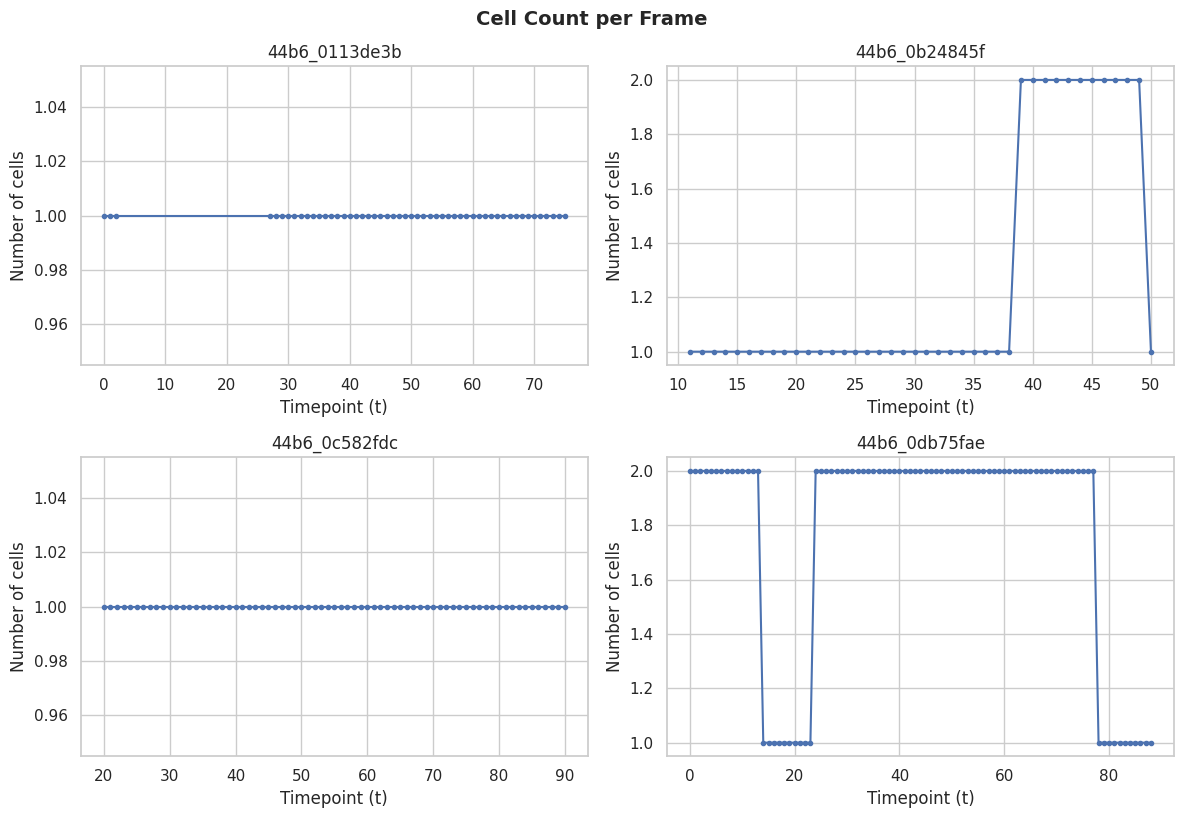

In [25]:
def cell_count_per_frame(nodes: pd.DataFrame) -> pd.DataFrame:
    return (
        nodes.groupby("t")
        .size()
        .reset_index(name="n_cells")
        .sort_values("t")
    )

example_ids = list(all_graphs.keys())[:4]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

for ax, sid in zip(axes, example_ids):
    nodes, _ = all_graphs[sid]
    counts = cell_count_per_frame(nodes)
    ax.plot(counts["t"], counts["n_cells"], marker="o", markersize=3)
    ax.set_title(sid)
    ax.set_xlabel("Timepoint (t)")
    ax.set_ylabel("Number of cells")

plt.tight_layout()
plt.suptitle("Cell Count per Frame", y=1.02, fontsize=14, fontweight="bold")
plt.show()

## 3.5 Coordinate Distribution

COORDINATE DISTRIBUTION


,z_min,z_max,y_min,y_max,x_min,x_max,z_mean,y_mean,x_mean
count,199.0,199.0,199.0,199.0,199.0,199.0,199.0,199.0,199.0
mean,4.4,57.6,21.1,230.1,22.2,236.0,31.5,126.1,129.5
std,7.5,8.7,32.8,35.8,35.0,30.9,5.9,19.3,22.5
min,0.0,19.0,0.0,131.0,0.0,134.0,7.1,63.9,45.3
25%,1.0,56.5,2.0,214.0,3.0,234.0,28.2,116.2,118.8
50%,1.0,62.0,4.0,251.0,4.0,252.0,31.8,125.3,130.5
75%,3.0,63.0,25.5,253.0,23.0,253.0,35.0,137.5,143.2
max,31.0,63.0,128.0,255.0,127.0,255.0,45.0,173.0,189.4


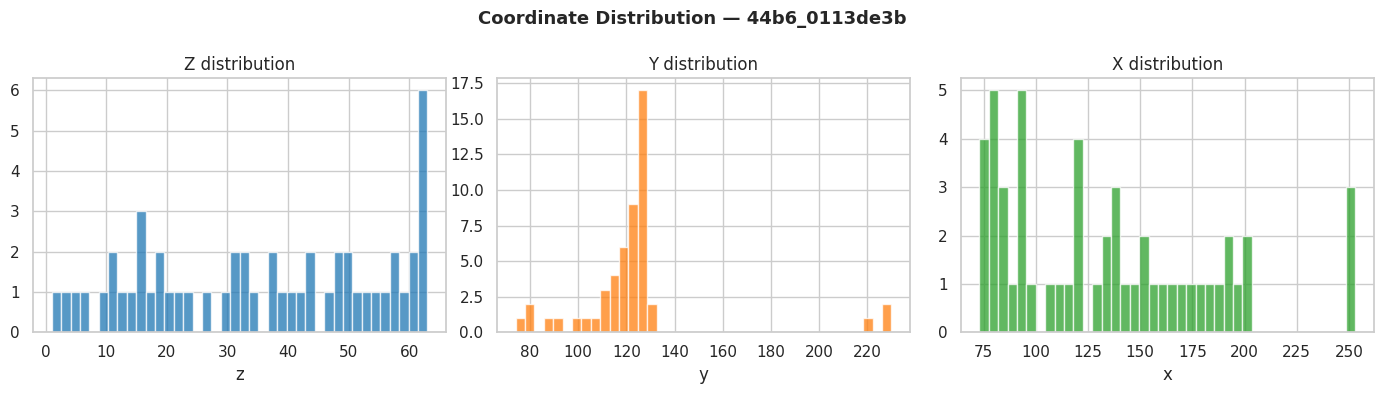

In [26]:
def coordinate_stats(graphs: dict) -> pd.DataFrame:
    rows = []
    for sid, (nodes, _) in graphs.items():
        rows.append({
            "sample_id": sid,
            "group": get_group(sid),
            "z_min": nodes["z"].min(), "z_max": nodes["z"].max(),
            "y_min": nodes["y"].min(), "y_max": nodes["y"].max(),
            "x_min": nodes["x"].min(), "x_max": nodes["x"].max(),
            "z_mean": nodes["z"].mean(),
            "y_mean": nodes["y"].mean(),
            "x_mean": nodes["x"].mean(),
        })
    return pd.DataFrame(rows)

coord_stats = coordinate_stats(all_graphs)

print("COORDINATE DISTRIBUTION")
display(coord_stats.describe().round(1))

# Histogram of coordinates (একটা movie দিয়ে)
example_sid = list(all_graphs.keys())[0]
nodes_ex, _ = all_graphs[example_sid]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, color in zip(axes, ["z", "y", "x"], ["#1f77b4", "#ff7f0e", "#2ca02c"]):
    ax.hist(nodes_ex[col], bins=40, color=color, alpha=0.75, edgecolor="white")
    ax.set_title(f"{col.upper()} distribution")
    ax.set_xlabel(col)
plt.suptitle(f"Coordinate Distribution — {example_sid}", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## 3.6 Movement / Displacement Analysis

MOVEMENT / DISPLACEMENT
       distance_um  speed_um_per_s  delta_t
count       50.000          50.000     50.0
mean         3.124           3.124      1.0
std          1.487           1.487      0.0
min          0.406           0.406      1.0
25%          2.101           2.101      1.0
50%          2.883           2.883      1.0
75%          3.854           3.854      1.0
max          7.814           7.814      1.0


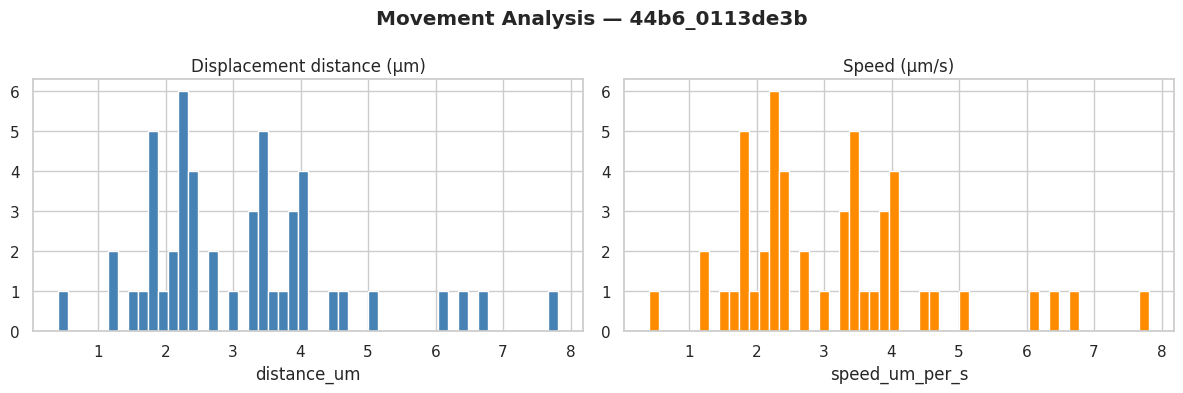

In [27]:
def compute_edge_movement(nodes: pd.DataFrame, edges: pd.DataFrame) -> pd.DataFrame:
    node_coords = nodes.set_index("node_id")[["t", "z", "y", "x"]]

    ed = edges.copy()
    ed["source_t"] = ed["source_id"].map(node_coords["t"])
    ed["target_t"] = ed["target_id"].map(node_coords["t"])
    ed["source_z"] = ed["source_id"].map(node_coords["z"])
    ed["target_z"] = ed["target_id"].map(node_coords["z"])
    ed["source_y"] = ed["source_id"].map(node_coords["y"])
    ed["target_y"] = ed["target_id"].map(node_coords["y"])
    ed["source_x"] = ed["source_id"].map(node_coords["x"])
    ed["target_x"] = ed["target_id"].map(node_coords["x"])

    # Physical units
    ed["delta_z_um"] = (ed["target_z"] - ed["source_z"]) * Z_SCALE
    ed["delta_y_um"] = (ed["target_y"] - ed["source_y"]) * Y_SCALE
    ed["delta_x_um"] = (ed["target_x"] - ed["source_x"]) * X_SCALE

    ed["distance_um"] = np.sqrt(
        ed["delta_z_um"]**2 + ed["delta_y_um"]**2 + ed["delta_x_um"]**2
    )
    ed["delta_t"] = ed["target_t"] - ed["source_t"]
    ed["speed_um_per_s"] = np.where(
        ed["delta_t"] > 0,
        ed["distance_um"] / (ed["delta_t"] * TIME_SCALE),
        np.nan
    )
    return ed

sid = list(all_graphs.keys())[0]
nodes, edges = all_graphs[sid]
edge_move = compute_edge_movement(nodes, edges)

print("MOVEMENT / DISPLACEMENT")
print(edge_move[["distance_um", "speed_um_per_s", "delta_t"]].describe().round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(edge_move["distance_um"].dropna(), bins=50, color="steelblue", edgecolor="white")
axes[0].set_title("Displacement distance (µm)")
axes[0].set_xlabel("distance_um")

axes[1].hist(edge_move["speed_um_per_s"].dropna(), bins=50, color="darkorange", edgecolor="white")
axes[1].set_title("Speed (µm/s)")
axes[1].set_xlabel("speed_um_per_s")
plt.suptitle(f"Movement Analysis — {sid}", fontweight="bold")
plt.tight_layout()
plt.show()

### 3.6.1 GEFF Edge Temporal Consistency

In [28]:
def edge_temporal_consistency(nodes, edges):

    lookup = (
        nodes
        .set_index("node_id")
        ["t"]
        .to_dict()
    )

    rows = []

    for _, e in edges.iterrows():

        s = e["source_id"]
        t = e["target_id"]

        source_t = lookup.get(s)
        target_t = lookup.get(t)

        if source_t is None or target_t is None:
            continue

        dt = target_t - source_t

        rows.append({
            "source_id": s,
            "target_id": t,
            "source_t": source_t,
            "target_t": target_t,
            "delta_t": dt,
            "valid_next_frame": dt == 1,
            "valid_forward": dt > 0,
        })

    return pd.DataFrame(rows)


temporal_reports = []

for sid, (nodes, edges) in all_graphs.items():

    report = edge_temporal_consistency(
        nodes,
        edges
    )

    temporal_reports.append({
        "sample_id": sid,
        "group": get_group(sid),
        "n_edges": len(report),
        "invalid_temporal_edges":
            int((~report["valid_forward"]).sum()),
        "non_consecutive_edges":
            int((report["delta_t"] != 1).sum()),
        "mean_delta_t":
            report["delta_t"].mean(),
        "max_delta_t":
            report["delta_t"].max(),
    })


temporal_summary = pd.DataFrame(
    temporal_reports
)

display(temporal_summary.head())

print(
    "Movies with temporal violations:",
    (
        temporal_summary[
            temporal_summary["invalid_temporal_edges"] > 0
        ]
        .shape[0]
    )
)

,sample_id,group,n_edges,invalid_temporal_edges,non_consecutive_edges,mean_delta_t,max_delta_t
0,44b6_0113de3b,44b6,50,0,0,1.0,1
1,44b6_0b24845f,44b6,49,0,0,1.0,1
2,44b6_0c582fdc,44b6,70,0,0,1.0,1
3,44b6_0db75fae,44b6,151,0,0,1.0,1
4,44b6_12dfb391,44b6,773,0,0,1.0,1


Movies with temporal violations: 0


## 3.7 Cell Division Analysis

In [29]:
def analyze_divisions(graphs: dict) -> pd.DataFrame:
    rows = []
    for sid, (nodes, edges) in graphs.items():
        out_degree = edges.groupby("source_id").size()
        n_divisions = (out_degree >= 2).sum()
        n_merges = (edges.groupby("target_id").size() >= 2).sum()

        rows.append({
            "sample_id": sid,
            "group": get_group(sid),
            "n_divisions": int(n_divisions),
            "n_merges": int(n_merges),
            "n_nodes": len(nodes),
            "division_rate": n_divisions / max(len(nodes), 1),
        })
    return pd.DataFrame(rows)

division_summary = analyze_divisions(all_graphs)

print("CELL DIVISION")
print(division_summary.describe().round(3))

print("\nDivision statistics by group:")
display(
    division_summary.groupby("group")
    .agg(
        median_divisions=("n_divisions", "median"),
        mean_divisions=("n_divisions", "mean"),
        median_rate=("division_rate", "median"),
    )
    .round(3)
)

CELL DIVISION
       n_divisions  n_merges  n_nodes  division_rate
count      199.000     199.0   199.00        199.000
mean         0.759       0.0   669.94          0.001
std          1.069       0.0   421.41          0.002
min          0.000       0.0    50.00          0.000
25%          0.000       0.0   294.00          0.000
50%          0.000       0.0   659.00          0.000
75%          1.000       0.0   939.50          0.002
max          5.000       0.0  1950.00          0.014

Division statistics by group:


,median_divisions,mean_divisions,median_rate
group,,,
44b6,0.0,0.366,0.000
6bba,1.0,0.977,0.001


### 3.7.1 Detailed Division Geometry Analysis

In [30]:
def build_division_events(nodes, edges):

    out_counts = (
        edges
        .groupby("source_id")
        .size()
    )

    division_sources = (
        out_counts[out_counts == 2]
        .index
    )

    rows = []

    node_lookup = (
        nodes
        .set_index("node_id")
        [["t", "z", "y", "x"]]
    )

    for parent_id in division_sources:

        child_ids = (
            edges[
                edges["source_id"] == parent_id
            ]["target_id"]
            .tolist()
        )

        if len(child_ids) != 2:
            continue

        if (
            parent_id not in node_lookup.index
            or child_ids[0] not in node_lookup.index
            or child_ids[1] not in node_lookup.index
        ):
            continue

        parent = node_lookup.loc[parent_id]
        child1 = node_lookup.loc[child_ids[0]]
        child2 = node_lookup.loc[child_ids[1]]

        p = np.array([
            parent["z"] * Z_SCALE,
            parent["y"] * Y_SCALE,
            parent["x"] * X_SCALE
        ])

        c1 = np.array([
            child1["z"] * Z_SCALE,
            child1["y"] * Y_SCALE,
            child1["x"] * X_SCALE
        ])

        c2 = np.array([
            child2["z"] * Z_SCALE,
            child2["y"] * Y_SCALE,
            child2["x"] * X_SCALE
        ])

        v1 = c1 - p
        v2 = c2 - p

        d1 = np.linalg.norm(v1)
        d2 = np.linalg.norm(v2)

        if d1 > 0 and d2 > 0:

            cos_angle = np.clip(
                np.dot(v1, v2) / (d1 * d2),
                -1,
                1
            )

            angle = np.degrees(
                np.arccos(cos_angle)
            )

        else:
            angle = np.nan

        symmetry = (
            min(d1, d2) / max(d1, d2)
            if max(d1, d2) > 0
            else np.nan
        )

        rows.append({
            "parent_id": parent_id,
            "parent_t": parent["t"],
            "daughter_1": child_ids[0],
            "daughter_2": child_ids[1],
            "daughter_1_distance_um": d1,
            "daughter_2_distance_um": d2,
            "daughter_separation_um": np.linalg.norm(c1 - c2),
            "opening_angle_deg": angle,
            "displacement_symmetry": symmetry,
        })

    return pd.DataFrame(rows)


division_analysis_rows = []

for sid, (nodes, edges) in all_graphs.items():

    divs = build_division_events(
        nodes,
        edges
    )

    if len(divs):

        divs["sample_id"] = sid
        divs["group"] = get_group(sid)

        division_analysis_rows.append(divs)


division_events_all = (
    pd.concat(
        division_analysis_rows,
        ignore_index=True
    )
    if division_analysis_rows
    else pd.DataFrame()
)

print(
    "Total division events:",
    len(division_events_all)
)

display(
    division_events_all.head()
)

Total division events: 151


,parent_id,parent_t,daughter_1,daughter_2,daughter_1_distance_um,daughter_2_distance_um,daughter_separation_um,opening_angle_deg,displacement_symmetry,sample_id,group
0,172000000050,66,173000000050,173000000051,4.875000,4.755034,9.484002,160.016893,0.975392,44b6_12dfb391,44b6
1,16000000001,3,17000000001,17000000002,5.525597,7.094851,11.504839,131.051183,0.778818,44b6_267148e4,44b6
2,160000000048,11,161000000049,161000000048,0.574524,8.384906,8.750893,128.073354,0.068519,44b6_2a2eff9f,44b6
3,79000000000,4,80000000000,80000000001,4.542013,7.141223,11.619034,167.671088,0.636027,44b6_341df25f,44b6
4,21000000052,19,22000000053,22000000052,9.917826,6.254139,14.653185,128.507241,0.630596,44b6_587a1e22,44b6


In [31]:
if not division_events_all.empty:

    display(
        division_events_all
        .groupby("group")
        [
            [
                "daughter_1_distance_um",
                "daughter_2_distance_um",
                "daughter_separation_um",
                "opening_angle_deg",
                "displacement_symmetry"
            ]
        ]
        .agg(["mean", "median", "std"])
    )

daughter_1_distance_um                     daughter_2_distance_um  \
                        mean    median       std                   mean   
group                                                                     
44b6                4.182887  4.122793  2.373866               5.412125   
6bba                5.686055  5.701990  2.355992               6.349472   

                          daughter_separation_um                       \
         median       std                   mean     median       std   
group                                                                   
44b6   5.503023  2.425997               8.838850   8.983471  2.717038   
6bba   6.358818  2.786772              10.878827  11.468920  3.147851   

      opening_angle_deg                        displacement_symmetry  \
                   mean      median        std                  mean   
group                                                                  
44b6         129.882413  135.339968  35.749129              0.565524   
6bba         133.362954  139.744216  29.578913              0.613084   

                           
         median       std  
group                      
44b6   0.627798  0.299939  
6bba   0.620326  0.238111

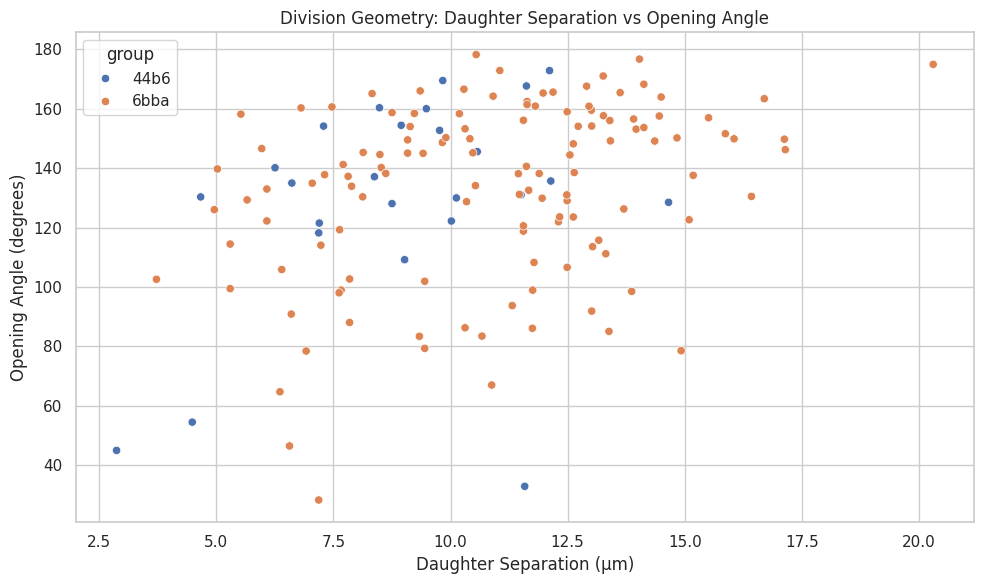

In [32]:
if not division_events_all.empty:

    plt.figure(figsize=(10, 6))

    sns.scatterplot(
        data=division_events_all,
        x="daughter_separation_um",
        y="opening_angle_deg",
        hue="group"
    )

    plt.title(
        "Division Geometry: Daughter Separation vs Opening Angle"
    )

    plt.xlabel("Daughter Separation (µm)")
    plt.ylabel("Opening Angle (degrees)")

    plt.tight_layout()
    plt.show()

### 3.7.2 Difficult Division Event Analysis

In [33]:
if not division_events_all.empty:

    difficult_divisions = (
        division_events_all[
            (
                division_events_all[
                    "displacement_symmetry"
                ] < 0.6
            )
            |
            (
                division_events_all[
                    "opening_angle_deg"
                ] < 45
            )
            |
            (
                division_events_all[
                    "daughter_separation_um"
                ] < 2.0
            )
        ]
        .copy()
    )

    print(
        "Total division events:",
        len(division_events_all)
    )

    print(
        "Potential difficult divisions:",
        len(difficult_divisions)
    )

    display(
        difficult_divisions.head(20)
    )

Total division events: 151
Potential difficult divisions: 69


,parent_id,parent_t,daughter_1,daughter_2,daughter_1_distance_um,daughter_2_distance_um,daughter_separation_um,opening_angle_deg,displacement_symmetry,sample_id,group
2,160000000048,11,161000000049,161000000048,0.574524,8.384906,8.750893,128.073354,0.068519,44b6_2a2eff9f,44b6
6,446000000015,49,447000000015,447000000016,0.406250,4.394266,4.667457,130.327084,0.092450,44b6_706092f0,44b6
7,296000000021,58,297000000022,297000000021,0.908403,12.335559,11.583469,32.911889,0.073641,44b6_74d0c52e,44b6
13,390000000000,61,391000000000,391000000001,3.854026,1.816805,2.872621,45.000000,0.471405,44b6_aaf8b0ea,44b6
16,128000000004,72,129000000005,129000000004,2.601269,5.465535,4.487178,54.520248,0.475940,44b6_c8e2a523,44b6
17,275000000002,51,276000000002,276000000003,6.214430,2.368824,8.482749,160.346176,0.381181,44b6_d2f34f90,44b6
18,286000000004,62,287000000004,287000000005,1.816805,6.147678,7.187296,118.219020,0.295527,44b6_d2f34f90,44b6
19,173000000010,12,174000000010,174000000011,8.492471,2.298097,10.123698,129.992295,0.270604,44b6_d5e7d891,44b6
24,419000000009,61,420000000010,420000000009,1.625000,6.214430,7.198768,121.532112,0.261488,44b6_e28840c6,44b6
25,160000000048,72,161000000049,161000000048,0.574524,9.699086,10.017173,122.216097,0.059235,44b6_eb2880fc,44b6


## 3.8 Graph Topology

In [34]:
def analyze_topology(nodes: pd.DataFrame, edges: pd.DataFrame) -> dict:
    G = nx.DiGraph()

    G.add_nodes_from(nodes["node_id"])
    G.add_edges_from(
        zip(edges["source_id"], edges["target_id"])
    )

    in_deg = dict(G.in_degree())
    out_deg = dict(G.out_degree())

    n_roots = sum(1 for d in in_deg.values() if d == 0)
    n_leaves = sum(1 for d in out_deg.values() if d == 0)
    n_divisions = sum(1 for d in out_deg.values() if d >= 2)
    n_components = nx.number_weakly_connected_components(G)

    return {
        "n_nodes": G.number_of_nodes(),
        "n_edges": G.number_of_edges(),
        "n_roots": n_roots,
        "n_leaves": n_leaves,
        "n_divisions": n_divisions,
        "n_weak_components": n_components,
    }

topology_results = []

for sid, (nodes, edges) in all_graphs.items():

    topo = analyze_topology(nodes, edges)

    topology_results.append({
        "sample_id": sid,
        "group": get_group(sid),
        **topo
    })


# Convert results to DataFrame
topology_summary = pd.DataFrame(topology_results)

print("GRAPH TOPOLOGY")
print(f"Total movies analyzed: {len(topology_summary)}")

display(topology_summary.head(10))

GRAPH TOPOLOGY
Total movies analyzed: 199


,sample_id,group,n_nodes,n_edges,n_roots,n_leaves,n_divisions,n_weak_components
0,44b6_0113de3b,44b6,52,50,2,2,0,2
1,44b6_0b24845f,44b6,51,49,2,2,0,2
2,44b6_0c582fdc,44b6,71,70,1,1,0,1
3,44b6_0db75fae,44b6,157,151,6,6,0,6
4,44b6_12dfb391,44b6,788,773,15,16,1,15
5,44b6_144b256d,44b6,121,119,2,2,0,2
6,44b6_1574802b,44b6,155,153,2,2,0,2
7,44b6_18ced818,44b6,100,99,1,1,0,1
8,44b6_1d530831,44b6,276,271,5,5,0,5
9,44b6_24264f12,44b6,230,221,9,9,0,9


### 3.8.1 Topology Statistics

In [35]:
print("TOPOLOGY STATISTICS")
display(
    topology_summary[
        [
            "n_nodes",
            "n_edges",
            "n_roots",
            "n_leaves",
            "n_divisions",
            "n_weak_components"
        ]
    ].describe().round(2)
)

TOPOLOGY STATISTICS


,n_nodes,n_edges,n_roots,n_leaves,n_divisions,n_weak_components
count,199.00,199.00,199.00,199.00,199.00,199.00
mean,669.94,647.65,22.29,23.05,0.76,22.29
std,421.41,406.30,18.19,18.57,1.07,18.19
min,50.00,49.00,1.00,1.00,0.00,1.00
25%,294.00,286.00,6.00,6.00,0.00,6.00
50%,659.00,639.00,19.00,21.00,0.00,19.00
75%,939.50,918.50,33.00,33.00,1.00,33.00
max,1950.00,1879.00,79.00,83.00,5.00,79.00


### 3.8.2 TOPOLOGY BY GROUP

In [36]:
print("TOPOLOGY BY GROUP")

display(
    topology_summary.groupby("group")
    .agg(
        n_movies=("sample_id", "count"),
        median_nodes=("n_nodes", "median"),
        median_edges=("n_edges", "median"),
        median_roots=("n_roots", "median"),
        median_leaves=("n_leaves", "median"),
        median_divisions=("n_divisions", "median"),
        median_components=("n_weak_components", "median"),
    )
    .round(2)
)

TOPOLOGY BY GROUP


,n_movies,median_nodes,median_edges,median_roots,median_leaves,median_divisions,median_components
group,,,,,,,
44b6,71,214.0,209.0,4.0,4.0,0.0,4.0
6bba,128,826.5,800.5,29.0,30.0,1.0,29.0


### 3.8.3 ADVANCED GRAPH STRUCTURAL ANALYSIS

In [37]:
def advanced_graph_structure(nodes, edges):

    G = nx.DiGraph()

    G.add_nodes_from(nodes["node_id"].tolist())

    G.add_edges_from(
        edges[["source_id", "target_id"]]
        .itertuples(index=False, name=None)
    )

    n_nodes = G.number_of_nodes()
    n_edges = G.number_of_edges()

    # Weak connected components
    components = list(
        nx.weakly_connected_components(G)
    )

    component_sizes = sorted(
        [len(c) for c in components],
        reverse=True
    )

    largest_component = (
        component_sizes[0]
        if component_sizes else 0
    )

    # Fragmentation
    fragmentation_ratio = (
        1 - largest_component / n_nodes
        if n_nodes > 0
        else np.nan
    )

    # Degree statistics
    in_degree = np.array(
        [d for _, d in G.in_degree()]
    )

    out_degree = np.array(
        [d for _, d in G.out_degree()]
    )

    division_nodes = int(
        np.sum(out_degree == 2)
    )

    terminal_nodes = int(
        np.sum(out_degree == 0)
    )

    root_nodes = int(
        np.sum(in_degree == 0)
    )

    return {
        "n_nodes": n_nodes,
        "n_edges": n_edges,
        "n_components": len(components),
        "largest_component": largest_component,
        "largest_component_ratio": (
            largest_component / n_nodes
            if n_nodes else np.nan
        ),
        "fragmentation_ratio": fragmentation_ratio,
        "mean_in_degree": np.mean(in_degree),
        "mean_out_degree": np.mean(out_degree),
        "max_out_degree": np.max(out_degree)
            if len(out_degree) else 0,
        "division_nodes": division_nodes,
        "terminal_nodes": terminal_nodes,
        "root_nodes": root_nodes,
    }


advanced_topology_rows = []

for sid, (nodes, edges) in all_graphs.items():

    result = advanced_graph_structure(
        nodes,
        edges
    )

    result["sample_id"] = sid
    result["group"] = get_group(sid)

    advanced_topology_rows.append(result)


advanced_topology = pd.DataFrame(
    advanced_topology_rows
)

display(advanced_topology.head())

,n_nodes,n_edges,n_components,largest_component,largest_component_ratio,fragmentation_ratio,mean_in_degree,mean_out_degree,max_out_degree,division_nodes,terminal_nodes,root_nodes,sample_id,group
0,52,50,2,49,0.942308,0.057692,0.961538,0.961538,1,0,2,2,44b6_0113de3b,44b6
1,51,49,2,40,0.784314,0.215686,0.960784,0.960784,1,0,2,2,44b6_0b24845f,44b6
2,71,70,1,71,1.000000,0.000000,0.985915,0.985915,1,0,1,1,44b6_0c582fdc,44b6
3,157,151,6,78,0.496815,0.503185,0.961783,0.961783,1,0,6,6,44b6_0db75fae,44b6
4,788,773,15,111,0.140863,0.859137,0.980964,0.980964,2,1,16,15,44b6_12dfb391,44b6


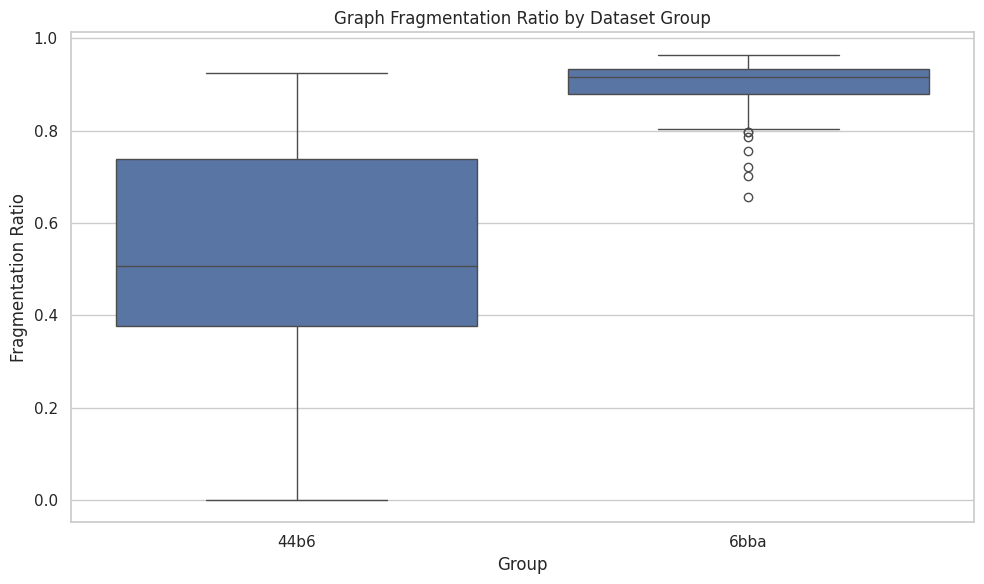

In [38]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=advanced_topology,
    x="group",
    y="fragmentation_ratio"
)

plt.title(
    "Graph Fragmentation Ratio by Dataset Group"
)

plt.xlabel("Group")
plt.ylabel("Fragmentation Ratio")

plt.tight_layout()
plt.show()

## 3.9 intensity distribution

In [39]:
def sample_intensity_stats(sample_id: str, root: Path, n_frames: int = 5):
    zarr_path = root / f"{sample_id}.zarr"

    if not zarr_path.exists():
        return None

    store = zarr.open(str(zarr_path), mode="r")
    volume = store["0"]  # (T, Z, Y, X)

    T = volume.shape[0]

    frames = np.linspace(
        0,
        T - 1,
        num=min(n_frames, T),
        dtype=int
    )

    records = []

    for t in frames:

        frame = np.asarray(volume[t])

        records.append({
            "sample_id": sample_id,
            "group": get_group(sample_id),
            "t": int(t),
            "p50": np.percentile(frame, 50),
            "p90": np.percentile(frame, 90),
            "p95": np.percentile(frame, 95),
            "p99": np.percentile(frame, 99),
            "max": frame.max(),
        })

    return pd.DataFrame(records)
    
# Analyze ALL movies
intensity_dfs = []

for sid in all_graphs.keys():
    df = sample_intensity_stats(sid, train_root)

    if df is not None:
        intensity_dfs.append(df)

# Combine results
if intensity_dfs:

    intensity_df = pd.concat(
        intensity_dfs,
        ignore_index=True
    )

    print("INTENSITY")

    print(
        f"Movies analyzed: "
        f"{intensity_df['sample_id'].nunique()}"
    )

    display(
        intensity_df
        .groupby("sample_id")[["p50", "p90", "p95", "p99", "max"]]
        .mean()
        .round(1)
    )

INTENSITY
Movies analyzed: 199


,p50,p90,p95,p99,max
sample_id,,,,,
44b6_0113de3b,178.2,441.4,673.0,1332.4,3007.6
44b6_0b24845f,1480.4,2150.0,2280.6,2514.0,3362.6
44b6_0c582fdc,406.6,1122.6,1363.8,1832.4,3241.4
44b6_0db75fae,101.4,752.2,998.6,1420.8,2560.4
44b6_12dfb391,591.2,1145.4,1418.0,1926.0,4002.6
...,...,...,...,...,...
6bba_fbc898dc,37.4,113.2,214.8,549.6,1908.6
6bba_fc516dc6,82.4,237.6,331.0,728.0,1860.6
6bba_fc5f39dc,74.0,404.2,489.0,674.0,1269.0


## 3.10 Advanced Intensity Analysis

In [40]:
def get_volume_array(sample_id, root):
    """
    Load 4D microscopy volume:
    Expected shape: (T, Z, Y, X)
    Also handles (T, C, Z, Y, X)
    """
    zarr_path = root / f"{sample_id}.zarr"
    store = zarr.open(str(zarr_path), mode="r")

    # Usually the image is stored under "0"
    vol = store["0"]

    return vol


def intensity_quantile_summary(
    sample_ids,
    root,
    quantiles=(0.50, 0.90, 0.95, 0.99),
    max_frames=10
):
    rows = []

    for sid in tqdm(sample_ids, desc="Intensity analysis"):

        try:
            vol = get_volume_array(sid, root)

            n_frames = vol.shape[0]
            frame_ids = np.linspace(
                0,
                n_frames - 1,
                min(max_frames, n_frames),
                dtype=int
            )

            values = []

            for t in frame_ids:

                frame = np.asarray(vol[t])

                # Remove channel dimension if present
                if frame.ndim == 4:
                    frame = frame[0]

                values.append(frame.ravel())

            values = np.concatenate(values)

            row = {
                "sample_id": sid,
                "n_frames": n_frames,
                "min": float(np.min(values)),
                "max": float(np.max(values)),
                "mean": float(np.mean(values)),
                "median": float(np.median(values)),
            }

            for q in quantiles:
                row[f"p{int(q * 100)}"] = float(
                    np.quantile(values, q)
                )

            rows.append(row)

        except Exception as e:
            print(f"Skipping {sid}: {e}")

    return pd.DataFrame(rows)


intensity_summary = intensity_quantile_summary(
    train_ids,
    train_root,
    max_frames=10
)

display(intensity_summary.head())

print(
    f"Movies analyzed: {len(intensity_summary)}"
)

Intensity analysis: 100%|██████████| 199/199 [09:27<00:00,  2.85s/it]


,sample_id,n_frames,min,max,mean,median,p50,p90,p95,p99
0,44b6_0113de3b,100,6.0,3970.0,246.682551,183.0,183.0,452.0,684.0,1355.0
1,44b6_0b24845f,100,6.0,3867.0,1342.293803,1469.0,1469.0,2301.0,2457.0,2731.0
2,44b6_0c582fdc,100,31.0,3626.0,533.118643,396.0,396.0,1144.0,1409.0,1901.0
3,44b6_0db75fae,100,0.0,2788.0,260.583320,86.0,86.0,832.0,1177.0,1635.0
4,44b6_12dfb391,100,30.0,4556.0,648.017140,575.0,575.0,1182.0,1465.0,2010.0


Movies analyzed: 199


In [41]:
# INTENSITY BY GROUP
intensity_summary["group"] = (
    intensity_summary["sample_id"]
    .map(get_group)
)

display(
    intensity_summary
    .groupby("group")
    [["median", "p90", "p95", "p99", "max"]]
    .agg(["median", "mean"])
)

median                 p90                  p95                  p99  \
      median        mean  median         mean  median         mean  median   
group                                                                        
44b6   480.0  551.323944  1158.0  1309.676056  1355.0  1549.563380  1797.0   
6bba    76.0  184.226562   282.0   478.875000   417.0   606.578125   722.0   

                       max               
              mean  median         mean  
group                                    
44b6   2004.887324  3696.0  4032.549296  
6bba    925.226562  2327.0  2512.335938

In [42]:
# TEST MOVIE INTENSITY ANALYSIS
test_intensity_summary = intensity_quantile_summary(
    test_ids,
    test_root,
    max_frames=10
)

display(test_intensity_summary.head())

print(
    "Test movies analyzed:",
    len(test_intensity_summary)
)

Intensity analysis: 100%|██████████| 4/4 [00:13<00:00,  3.26s/it]


,sample_id,n_frames,min,max,mean,median,p50,p90,p95,p99
0,6bba_05db0fb1,100,50.0,4160.0,946.504184,938.0,938.0,1537.0,1753.0,2222.0
1,44b6_0b24845f,100,6.0,3867.0,1342.293803,1469.0,1469.0,2301.0,2457.0,2731.0
2,6bba_05b6850b,100,0.0,2546.0,87.256650,44.0,44.0,186.0,308.0,705.0
3,44b6_0113de3b,100,6.0,3970.0,246.682551,183.0,183.0,452.0,684.0,1355.0


Test movies analyzed: 4


## 3.11 Visualization Summary

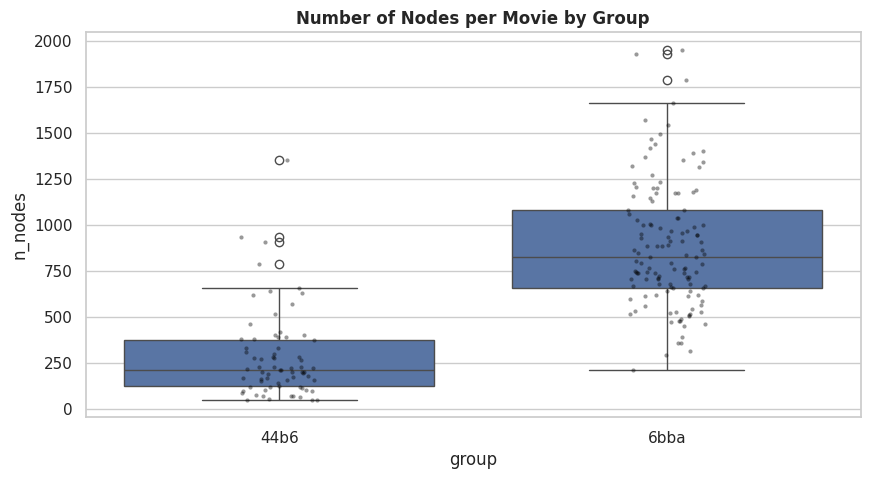

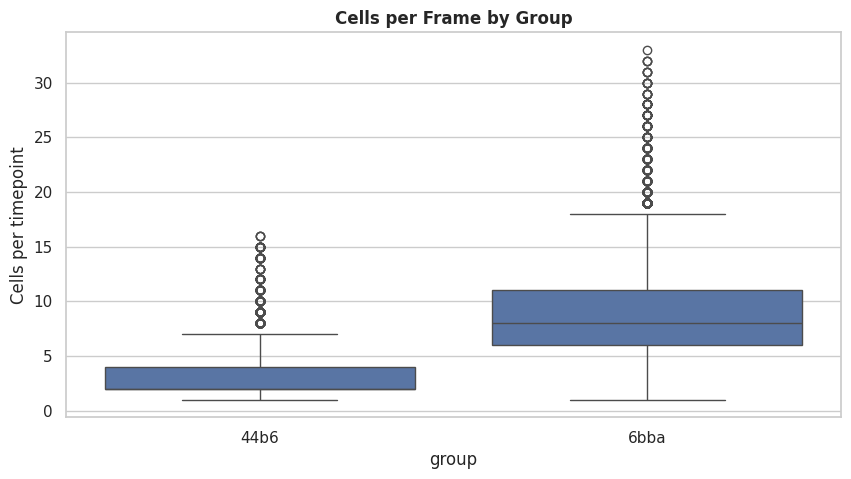

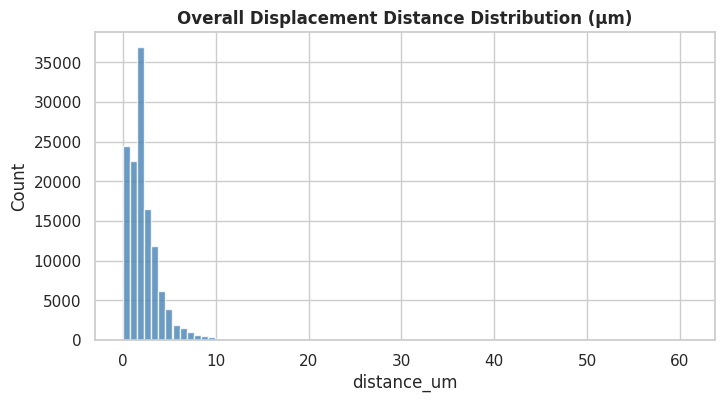

In [43]:
# 1. Nodes per movie (by group)
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=node_summary,
    x="group",
    y="n_nodes"
)

sns.stripplot(
    data=node_summary,
    x="group",
    y="n_nodes",
    color="black",
    alpha=0.4,
    size=3
)

plt.title("Number of Nodes per Movie by Group", fontweight="bold")
plt.ylabel("n_nodes")
plt.show()


# 2. Cells per frame distribution
all_counts = []

for sid, (nodes, _) in all_graphs.items():   # ALL movies

    c = cell_count_per_frame(nodes)

    c["sample_id"] = sid
    c["group"] = get_group(sid)

    all_counts.append(c)

counts_df = pd.concat(
    all_counts,
    ignore_index=True
)

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=counts_df,
    x="group",
    y="n_cells"
)

plt.title("Cells per Frame by Group", fontweight="bold")
plt.ylabel("Cells per timepoint")
plt.show()


# 3. Displacement distribution
all_dists = []

for sid, (nodes, edges) in all_graphs.items():   # ALL movies

    em = compute_edge_movement(nodes, edges)

    distances = em["distance_um"].dropna()

    if len(distances) > 0:
        all_dists.append(distances)


if all_dists:

    all_distances = np.concatenate(all_dists)

    plt.figure(figsize=(8, 4))

    plt.hist(
        all_distances,
        bins=80,
        color="steelblue",
        edgecolor="white",
        alpha=0.8
    )

    plt.title(
        "Overall Displacement Distance Distribution (µm)",
        fontweight="bold"
    )

    plt.xlabel("distance_um")
    plt.ylabel("Count")

    plt.show()

# 4. FEATURE ENGINEERING

In [44]:
from __future__ import annotations
from dataclasses import dataclass
from scipy.spatial import cKDTree
import numpy as np
import pandas as pd

## 4.1 Feature Config

In [45]:
@dataclass
class FeatureConfig:
    z_scale: float = 1.625          # µm / voxel
    y_scale: float = 0.40625        # µm / voxel
    x_scale: float = 0.40625        # µm / voxel
    time_scale: float = 1.0         # seconds / timepoint
    crowding_radius_um: float = 30.0
    k_neighbors: int = 5

## 4.2 Physical Coordinates (voxel → micrometer)

In [46]:
def add_physical_coordinates(
    nodes: pd.DataFrame, 
    cfg: FeatureConfig = FeatureConfig()
) -> pd.DataFrame:
    """
    z, y, x (voxel) → z_um, y_um, x_um (micrometer)
    """
    nodes = nodes.copy()
    nodes["z_um"] = nodes["z"] * cfg.z_scale
    nodes["y_um"] = nodes["y"] * cfg.y_scale
    nodes["x_um"] = nodes["x"] * cfg.x_scale
    return nodes

## 4.3 Distance + Speed / Kinematics

In [47]:
def add_edge_kinematics(
    edges: pd.DataFrame, 
    nodes_um: pd.DataFrame, 
    cfg: FeatureConfig = FeatureConfig()
) -> pd.DataFrame:
    coord_cols = ["node_id", "t", "z_um", "y_um", "x_um"]

    merged = (
        edges
        .merge(nodes_um[coord_cols], left_on="source_id", right_on="node_id", how="left")
        .rename(columns={
            "t": "source_t",
            "z_um": "source_z_um",
            "y_um": "source_y_um",
            "x_um": "source_x_um"
        })
        .drop(columns="node_id")
        .merge(nodes_um[coord_cols], left_on="target_id", right_on="node_id", how="left")
        .rename(columns={
            "t": "target_t",
            "z_um": "target_z_um",
            "y_um": "target_y_um",
            "x_um": "target_x_um"
        })
        .drop(columns="node_id")
    )

    merged["delta_z_um"] = merged["target_z_um"] - merged["source_z_um"]
    merged["delta_y_um"] = merged["target_y_um"] - merged["source_y_um"]
    merged["delta_x_um"] = merged["target_x_um"] - merged["source_x_um"]

    merged["distance_um"] = np.sqrt(
        merged["delta_z_um"]**2 + 
        merged["delta_y_um"]**2 + 
        merged["delta_x_um"]**2
    )

    merged["delta_t"] = merged["target_t"] - merged["source_t"]
    merged["elapsed_seconds"] = merged["delta_t"] * cfg.time_scale

    merged["speed_um_per_second"] = np.divide(
        merged["distance_um"],
        merged["elapsed_seconds"],
        out=np.full(len(merged), np.nan),
        where=merged["elapsed_seconds"] > 0,
    )
    return merged

## 4.4 Direction / Turning Angle
**- unit direction vector (dir_z, dir_y, dir_x)**    
**- turning_angle_deg (Angle with previous edge)**

In [48]:
def add_direction_features(edge_kinematics: pd.DataFrame) -> pd.DataFrame:
    df = edge_kinematics.copy()

    norm = df["distance_um"].replace(0, np.nan)
    df["dir_z"] = df["delta_z_um"] / norm
    df["dir_y"] = df["delta_y_um"] / norm
    df["dir_x"] = df["delta_x_um"] / norm

    # Previous edge direction (source of current = target of previous)
    prev = df[["target_id", "dir_z", "dir_y", "dir_x"]].rename(
        columns={
            "target_id": "source_id",
            "dir_z": "prev_dir_z",
            "dir_y": "prev_dir_y",
            "dir_x": "prev_dir_x"
        }
    )
    df = df.merge(prev, on="source_id", how="left")

    dot = (
        df["dir_z"] * df["prev_dir_z"] +
        df["dir_y"] * df["prev_dir_y"] +
        df["dir_x"] * df["prev_dir_x"]
    ).clip(-1, 1)

    df["turning_angle_deg"] = np.degrees(np.arccos(dot))

    return df.drop(columns=["prev_dir_z", "prev_dir_y", "prev_dir_x"])

## 4.5 Crowding Features

In [49]:
def add_crowding_features(
    nodes_um: pd.DataFrame, 
    cfg: FeatureConfig = FeatureConfig()
) -> pd.DataFrame:

    nodes_um = nodes_um.copy()
    nearest_dist = np.full(len(nodes_um), np.nan)
    neighbor_count = np.zeros(len(nodes_um), dtype=int)

    for t, group in nodes_um.groupby("t"):
        coords = group[["z_um", "y_um", "x_um"]].to_numpy()
        if len(coords) < 2:
            continue

        tree = cKDTree(coords)
        idx = group.index.to_numpy()

        dists, _ = tree.query(coords, k=2)
        nearest_dist[idx] = dists[:, 1]

        counts = tree.query_ball_point(
            coords, 
            r=cfg.crowding_radius_um, 
            return_length=True
        )
        neighbor_count[idx] = counts - 1

    nodes_um["nearest_neighbor_distance_um"] = nearest_dist
    nodes_um["neighbors_within_radius"] = neighbor_count
    return nodes_um

## 4.6 Graph Topology (in_degree / out_degree)
**- in_degree, out_degree**    
**- has_division (out_degree == 2)**    
**- component_id, component_size**

In [50]:
def add_topology_features(
    nodes: pd.DataFrame, 
    edges: pd.DataFrame
) -> pd.DataFrame:
    """
    - in_degree, out_degree
    - has_division (out_degree == 2)
    - component_id, component_size
    """
    nodes = nodes.copy()

    out_deg = edges.groupby("source_id").size().rename("out_degree")
    in_deg  = edges.groupby("target_id").size().rename("in_degree")

    nodes = nodes.merge(out_deg, left_on="node_id", right_index=True, how="left")
    nodes = nodes.merge(in_deg,  left_on="node_id", right_index=True, how="left")

    nodes["out_degree"] = nodes["out_degree"].fillna(0).astype(int)
    nodes["in_degree"]  = nodes["in_degree"].fillna(0).astype(int)
    nodes["has_division"] = nodes["out_degree"] == 2

    # Weakly connected components (union-find)
    parent = {nid: nid for nid in nodes["node_id"]}

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    def union(a, b):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[ra] = rb

    for s, t in zip(edges["source_id"], edges["target_id"]):
        if s in parent and t in parent:
            union(s, t)

    nodes["component_id"] = nodes["node_id"].map(find)
    nodes["component_size"] = nodes.groupby("component_id")["node_id"].transform("count")

    return nodes

## 4.7 Division Geometry

In [51]:
def add_division_features(edge_kinematics: pd.DataFrame) -> pd.DataFrame:
    out_degree = edge_kinematics.groupby("source_id")["target_id"].transform("count")
    divisions = edge_kinematics.loc[out_degree == 2].copy()

    if divisions.empty:
        return pd.DataFrame(columns=[
            "source_id", "source_t",
            "daughter_1_id", "daughter_2_id",
            "daughter_1_distance_um", "daughter_2_distance_um",
            "angle_between_daughters_deg", "displacement_symmetry"
        ])

    records = []
    for source_id, group in divisions.groupby("source_id"):
        if len(group) != 2:
            continue
        row1, row2 = group.iloc[0], group.iloc[1]

        v1 = np.array([row1["delta_z_um"], row1["delta_y_um"], row1["delta_x_um"]])
        v2 = np.array([row2["delta_z_um"], row2["delta_y_um"], row2["delta_x_um"]])
        n1, n2 = np.linalg.norm(v1), np.linalg.norm(v2)

        cos_angle = np.dot(v1, v2) / (n1 * n2) if n1 > 0 and n2 > 0 else np.nan
        angle_deg = np.degrees(np.arccos(np.clip(cos_angle, -1, 1))) if not np.isnan(cos_angle) else np.nan
        symmetry = min(n1, n2) / max(n1, n2) if max(n1, n2) > 0 else np.nan

        records.append({
            "source_id": source_id,
            "source_t": row1["source_t"],
            "daughter_1_id": row1["target_id"],
            "daughter_2_id": row2["target_id"],
            "daughter_1_distance_um": n1,
            "daughter_2_distance_um": n2,
            "angle_between_daughters_deg": angle_deg,
            "displacement_symmetry": symmetry,
        })

    return pd.DataFrame(records)

## 4.8 Ambiguity Features (For Candidate edges)

In [52]:
def add_ambiguity_features(candidates: pd.DataFrame) -> pd.DataFrame:
    df = candidates.copy()
    key = ["source_id", "source_t"] if "source_t" in df.columns else ["source_id"]

    df = df.sort_values(key + ["distance_um"])
    nearest = df.groupby(key)["distance_um"].transform("min")
    df["distance_ratio_to_nearest"] = df["distance_um"] / nearest.replace(0, np.nan)
    df["n_candidates_for_source"] = df.groupby(key)["target_id"].transform("count")

    def _margin(group: pd.DataFrame) -> pd.Series:
        sorted_d = group["distance_um"].sort_values().to_numpy()
        margin = (sorted_d[1] - sorted_d[0]) if len(sorted_d) > 1 else np.nan
        return pd.Series(margin, index=group.index)

    df["margin_to_runner_up_um"] = df.groupby(key, group_keys=False).apply(_margin)
    return df

## 4.9 Main Function

In [53]:
def engineer_all_features(
    nodes: pd.DataFrame, 
    edges: pd.DataFrame, 
    cfg: FeatureConfig = FeatureConfig()
) -> pd.DataFrame:
    
    # 1. Physical coordinates
    nodes_um = add_physical_coordinates(nodes, cfg)

    # 2. Crowding
    nodes_um = add_crowding_features(nodes_um, cfg)

    # 3. Topology
    nodes_um = add_topology_features(nodes_um, edges)

    # 4. Edge kinematics + direction
    edge_feats = add_edge_kinematics(edges, nodes_um, cfg)
    edge_feats = add_direction_features(edge_feats)

    # 5. Outgoing edge summary (প্রতি node-এর জন্য)
    outgoing_summary = (
        edge_feats
        .groupby("source_id")
        .agg(
            mean_speed_um_per_s=("speed_um_per_second", "mean"),
            mean_distance_um=("distance_um", "mean"),
            mean_turning_angle_deg=("turning_angle_deg", "mean"),
        )
        .reset_index()
        .rename(columns={"source_id": "node_id"})
    )

    features = nodes_um.merge(outgoing_summary, on="node_id", how="left")
    return features

## 4.10 Use Example

In [54]:
cfg = FeatureConfig()

sid = list(all_graphs.keys())[0]
nodes, edges = all_graphs[sid]

features = engineer_all_features(nodes, edges, cfg)

print("FEATURE ENGINEERING RESULT")
print("Shape:", features.shape)
print("\nColumns:")
print(features.columns.tolist())
display(features.head(8))

edge_kin = add_edge_kinematics(edges, add_physical_coordinates(nodes, cfg), cfg)
div_feats = add_division_features(edge_kin)
print("\nDivision events:", len(div_feats))
display(div_feats.head())

FEATURE ENGINEERING RESULT
Shape: (52, 18)

Columns:
['node_id', 't', 'z', 'y', 'x', 'z_um', 'y_um', 'x_um', 'nearest_neighbor_distance_um', 'neighbors_within_radius', 'out_degree', 'in_degree', 'has_division', 'component_id', 'component_size', 'mean_speed_um_per_s', 'mean_distance_um', 'mean_turning_angle_deg']


,node_id,t,z,y,x,z_um,y_um,x_um,nearest_neighbor_distance_um,neighbors_within_radius,out_degree,in_degree,has_division,component_id,component_size,mean_speed_um_per_s,mean_distance_um,mean_turning_angle_deg
0,11000000075,0,63,222,249,102.375,90.18750,101.15625,NaN,0,1,0,False,13000000075,3,2.187723,2.187723,NaN
1,12000000075,1,63,227,251,102.375,92.21875,101.96875,NaN,0,1,1,False,13000000075,3,1.464755,1.464755,11.888658
2,13000000075,2,63,230,253,102.375,93.43750,102.78125,NaN,0,0,1,False,13000000075,3,NaN,NaN,NaN
3,38000000003,27,1,74,73,1.625,30.06250,29.65625,NaN,0,1,0,False,86000000004,49,3.723343,3.723343,NaN
4,39000000003,28,3,78,75,4.875,31.68750,30.46875,NaN,0,1,1,False,86000000004,49,3.447146,3.447146,12.243668
5,40000000003,29,5,80,77,8.125,32.50000,31.28125,NaN,0,1,1,False,86000000004,49,4.082762,4.082762,23.840129
6,41000000003,30,7,86,78,11.375,34.93750,31.68750,NaN,0,1,1,False,86000000004,49,3.854026,3.854026,12.724356
7,42000000003,31,9,91,77,14.625,36.96875,31.28125,NaN,0,1,1,False,86000000004,49,4.614113,4.614113,28.155172



Division events: 0


,source_id,source_t,daughter_1_id,daughter_2_id,daughter_1_distance_um,daughter_2_distance_um,angle_between_daughters_deg,displacement_symmetry


# 5. CANDIDATE EDGE GENERATION

## 5.1 Main function — Create Candidate Edges

In [55]:
def build_candidate_edges(
    nodes: pd.DataFrame, 
    cfg: FeatureConfig = FeatureConfig()
) -> pd.DataFrame:

    # 1. Physical coordinates-এ convert
    nodes_um = add_physical_coordinates(nodes, cfg)

    rows = []
    times = sorted(nodes_um["t"].unique())

    for t in times:
        # t+1 is right or not check
        if (t + 1) not in set(times):
            continue

        # Source cells at t
        src = nodes_um.loc[nodes_um["t"] == t]
        # Target cells at t+1
        tgt = nodes_um.loc[nodes_um["t"] == t + 1]

        if src.empty or tgt.empty:
            continue

        # 2. Coordinates
        src_coords = src[["z_um", "y_um", "x_um"]].to_numpy()
        tgt_coords = tgt[["z_um", "y_um", "x_um"]].to_numpy()

        # 3. KDTree
        tree = cKDTree(tgt_coords)

        # 4. K nearest neighbors
        k = min(cfg.k_neighbors, len(tgt_coords))
        dists, idxs = tree.query(src_coords, k=k)

        # if k=1 then correct the shap
        if k == 1:
            dists = dists[:, None]
            idxs = idxs[:, None]

        src_ids = src["node_id"].to_numpy()
        tgt_ids = tgt["node_id"].to_numpy()

        # 5. Generate Candidate rows
        for i in range(len(src)):
            for rank in range(k):
                dist_um = float(dists[i, rank])
                rows.append({
                    "source_id": int(src_ids[i]),
                    "target_id": int(tgt_ids[idxs[i, rank]]),
                    "source_t": int(t),
                    "target_t": int(t + 1),
                    "distance_um": dist_um,
                    "rank": int(rank),          # 0 = nearest
                    "delta_t": 1,
                    "speed_um_per_second": dist_um / cfg.time_scale,
                })

    return pd.DataFrame(rows)

## 5.2 Ambiguity Features

In [56]:
def add_ambiguity_features(candidates: pd.DataFrame) -> pd.DataFrame:
    
    df = candidates.copy()
    key = ["source_id", "source_t"] if "source_t" in df.columns else ["source_id"]

    df = df.sort_values(key + ["distance_um"])

    nearest = df.groupby(key)["distance_um"].transform("min")
    df["distance_ratio_to_nearest"] = df["distance_um"] / nearest.replace(0, np.nan)
    df["n_candidates_for_source"] = df.groupby(key)["target_id"].transform("count")

    def _margin(group: pd.DataFrame) -> pd.Series:
        sorted_d = group["distance_um"].sort_values().to_numpy()
        margin = (sorted_d[1] - sorted_d[0]) if len(sorted_d) > 1 else np.nan
        return pd.Series(margin, index=group.index)

    df["margin_to_runner_up_um"] = (
        df.groupby(key, group_keys=False).apply(_margin)
    )
    return df

## 5.3 Test in one movie

In [57]:
cfg = FeatureConfig(k_neighbors=5)

sid = list(all_graphs.keys())[0]
nodes, edges = all_graphs[sid]

candidates = build_candidate_edges(nodes, cfg)
candidates = add_ambiguity_features(candidates)

print("CANDIDATE EDGE GENERATION")
print(f"Movie          : {sid}")
print(f"Total nodes    : {len(nodes)}")
print(f"Total candidates: {len(candidates)}")
print(f"Unique sources : {candidates['source_id'].nunique()}")
print(f"Mean candidates per source: {candidates.groupby('source_id').size().mean():.2f}")

print("\nCandidate head:")
display(candidates.head(10))

print("\nRank distribution:")
print(candidates["rank"].value_counts().sort_index())

CANDIDATE EDGE GENERATION
Movie          : 44b6_0113de3b
Total nodes    : 52
Total candidates: 50
Unique sources : 50
Mean candidates per source: 1.00

Candidate head:


/tmp/ipykernel_49/443956261.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby(key, group_keys=False).apply(_margin)


,source_id,target_id,source_t,target_t,distance_um,rank,delta_t,speed_um_per_second,distance_ratio_to_nearest,n_candidates_for_source,margin_to_runner_up_um
0,11000000075,12000000075,0,1,2.187723,0,1,2.187723,1.0,1,NaN
1,12000000075,13000000075,1,2,1.464755,0,1,1.464755,1.0,1,NaN
2,38000000003,39000000003,27,28,3.723343,0,1,3.723343,1.0,1,NaN
3,39000000003,40000000003,28,29,3.447146,0,1,3.447146,1.0,1,NaN
4,40000000003,41000000003,29,30,4.082762,0,1,4.082762,1.0,1,NaN
5,41000000003,42000000003,30,31,3.854026,0,1,3.854026,1.0,1,NaN
6,42000000003,43000000003,31,32,4.614113,0,1,4.614113,1.0,1,NaN
7,43000000003,44000000003,32,33,2.725208,0,1,2.725208,1.0,1,NaN
8,44000000003,45000000003,33,34,3.854026,0,1,3.854026,1.0,1,NaN
9,45000000003,46000000003,34,35,2.071477,0,1,2.071477,1.0,1,NaN



Rank distribution:
rank
0    50
Name: count, dtype: int64


## 5.4 Candidate creation for all movies (Batch)

In [58]:
def build_candidates_for_movies(
    graphs: dict,
    sample_ids: list[str],
    cfg: FeatureConfig = FeatureConfig()
) -> pd.DataFrame:

    parts = []
    for sid in tqdm(sample_ids, desc="Building candidates"):
        nodes, _ = graphs[sid]
        cand = build_candidate_edges(nodes, cfg)
        if cand.empty:
            continue
        cand = add_ambiguity_features(cand)
        cand["sample_id"] = sid
        cand["group"] = get_group(sid)
        parts.append(cand)

    if not parts:
        return pd.DataFrame()

    return pd.concat(parts, ignore_index=True)

example_ids = list(all_graphs.keys())[:10]
all_candidates = build_candidates_for_movies(all_graphs, example_ids, cfg)

print(f"\nTotal candidates from {len(example_ids)} movies: {len(all_candidates):,}")
print(all_candidates.groupby("sample_id").size().describe().round(1))

Building candidates:   0%|          | 0/10 [00:00<?, ?it/s]/tmp/ipykernel_49/443956261.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby(key, group_keys=False).apply(_margin)
Building candidates:  10%|█         | 1/10 [00:00<00:00,  9.22it/s]/tmp/ipykernel_49/443956261.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby(key, group_keys=False).apply(_margin)
/tmp/ipykernel_49/443956261.py:18:


Total candidates from 10 movies: 6,388
count      10.0
mean      638.8
std      1162.3
min        50.0
25%        78.0
50%       216.5
75%       544.8
max      3852.0
dtype: float64


## 5.5 Visualization — Distance by Rank

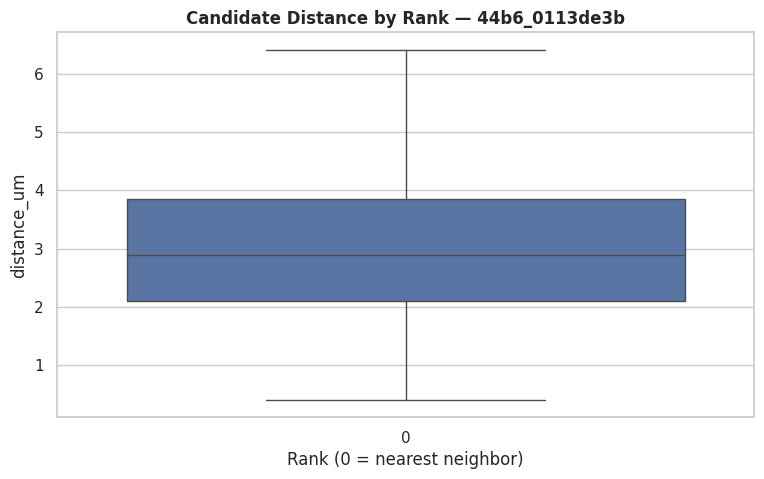

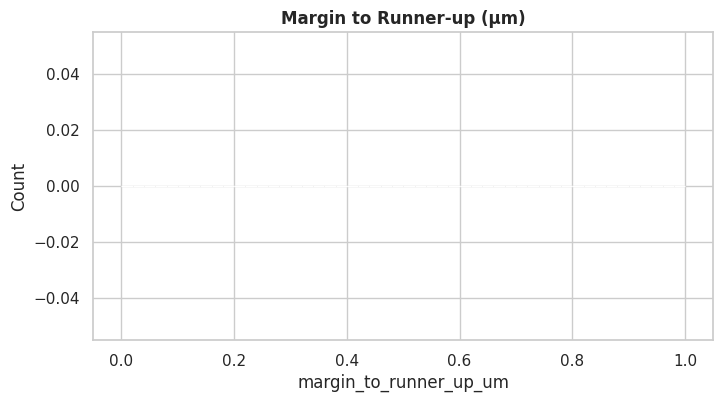

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))
sns.boxplot(
    data=candidates,
    x="rank",
    y="distance_um",
    showfliers=False
)
plt.title(f"Candidate Distance by Rank — {sid}", fontweight="bold")
plt.xlabel("Rank (0 = nearest neighbor)")
plt.ylabel("distance_um")
plt.show()

# Ambiguity margin distribution
plt.figure(figsize=(8, 4))
plt.hist(
    candidates["margin_to_runner_up_um"].dropna(),
    bins=50,
    color="steelblue",
    edgecolor="white"
)
plt.title("Margin to Runner-up (µm)", fontweight="bold")
plt.xlabel("margin_to_runner_up_um")
plt.ylabel("Count")
plt.show()

# 6. CANDIDATE LABELING

## 6.1 Main Labeling Function

In [60]:
def label_candidates(
    candidates: pd.DataFrame, 
    true_edges: pd.DataFrame
) -> pd.DataFrame:
    true_pairs = set(
        zip(true_edges["source_id"], true_edges["target_id"])
    )

    candidates = candidates.copy()
    candidates["is_true_edge"] = [
        (s, t) in true_pairs
        for s, t in zip(candidates["source_id"], candidates["target_id"])
    ]
    return candidates

## 6.2 Test Labeling in one Movie

In [61]:
cfg = FeatureConfig(k_neighbors=5)

sid = list(all_graphs.keys())[0]
nodes, true_edges = all_graphs[sid]

candidates = build_candidate_edges(nodes, cfg)
candidates = add_ambiguity_features(candidates)

labeled = label_candidates(candidates, true_edges)

print("CANDIDATE LABELING")
print(f"Movie              : {sid}")
print(f"Total candidates   : {len(labeled):,}")
print(f"True edges found   : {labeled['is_true_edge'].sum():,}")
print(f"False candidates   : {(~labeled['is_true_edge']).sum():,}")
print(f"True edge rate     : {labeled['is_true_edge'].mean():.4f}")

print("\nLabeled candidates head:")
display(
    labeled[[
        "source_id", "target_id", "source_t", 
        "distance_um", "rank", "is_true_edge"
    ]].head(12)
)

CANDIDATE LABELING
Movie              : 44b6_0113de3b
Total candidates   : 50
True edges found   : 50
False candidates   : 0
True edge rate     : 1.0000

Labeled candidates head:


/tmp/ipykernel_49/443956261.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby(key, group_keys=False).apply(_margin)


,source_id,target_id,source_t,distance_um,rank,is_true_edge
0,11000000075,12000000075,0,2.187723,0,True
1,12000000075,13000000075,1,1.464755,0,True
2,38000000003,39000000003,27,3.723343,0,True
3,39000000003,40000000003,28,3.447146,0,True
4,40000000003,41000000003,29,4.082762,0,True
5,41000000003,42000000003,30,3.854026,0,True
6,42000000003,43000000003,31,4.614113,0,True
7,43000000003,44000000003,32,2.725208,0,True
8,44000000003,45000000003,33,3.854026,0,True
9,45000000003,46000000003,34,2.071477,0,True


## 6.3 True Edge Coverage Check

In [62]:
def check_true_edge_coverage(
    labeled: pd.DataFrame, 
    true_edges: pd.DataFrame
) -> dict:
    true_pairs = set(zip(true_edges["source_id"], true_edges["target_id"]))
    found_pairs = set(
        zip(
            labeled.loc[labeled["is_true_edge"], "source_id"],
            labeled.loc[labeled["is_true_edge"], "target_id"]
        )
    )

    n_true = len(true_pairs)
    n_found = len(found_pairs)
    coverage = n_found / n_true if n_true > 0 else np.nan

    missing = true_pairs - found_pairs

    return {
        "n_true_edges": n_true,
        "n_found_in_candidates": n_found,
        "coverage": round(coverage, 4),
        "n_missing": len(missing),
    }

coverage = check_true_edge_coverage(labeled, true_edges)
print("TRUE EDGE COVERAGE")
for k, v in coverage.items():
    print(f"  {k:25s}: {v}")

TRUE EDGE COVERAGE
  n_true_edges             : 50
  n_found_in_candidates    : 50
  coverage                 : 1.0
  n_missing                : 0


## 6.4 Create Labeled Candidates for all Movies

In [63]:
def build_labeled_candidates(
    graphs: dict,
    sample_ids: list[str],
    cfg: FeatureConfig = FeatureConfig()
) -> pd.DataFrame:

    parts = []

    for sid in tqdm(sample_ids, desc="Building labeled candidates"):
        nodes, true_edges = graphs[sid]

        cand = build_candidate_edges(nodes, cfg)
        if cand.empty:
            continue

        cand = add_ambiguity_features(cand)
        cand = label_candidates(cand, true_edges)

        cand["sample_id"] = sid
        cand["group"] = get_group(sid)
        parts.append(cand)

    if not parts:
        return pd.DataFrame()

    return pd.concat(parts, ignore_index=True)



train_labeled = build_labeled_candidates(all_graphs, train_ids[:20], cfg)  # প্রথম ২০টা উদাহরণ

print("\nLABELED CANDIDATES SUMMARY")
print(f"Total rows          : {len(train_labeled):,}")
print(f"True edge rate      : {train_labeled['is_true_edge'].mean():.4f}")
print(f"Movies covered      : {train_labeled['sample_id'].nunique()}")

print("\nTrue edge rate by group:")
display(
    train_labeled
    .groupby("group")["is_true_edge"]
    .agg(["mean", "sum", "count"])
    .round(4)
    .rename(columns={"mean": "true_rate", "sum": "n_true", "count": "n_candidates"})
)

Building labeled candidates:   0%|          | 0/20 [00:00<?, ?it/s]/tmp/ipykernel_49/443956261.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby(key, group_keys=False).apply(_margin)
Building labeled candidates:   5%|▌         | 1/20 [00:00<00:01,  9.97it/s]/tmp/ipykernel_49/443956261.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby(key, group_keys=False).apply(_margin)
/tmp/ipykernel_49/


LABELED CANDIDATES SUMMARY
Total rows          : 16,406
True edge rate      : 0.2858
Movies covered      : 20

True edge rate by group:


,true_rate,n_true,n_candidates
group,,,
44b6,0.2858,4689,16406


## 6.5 Rank-wise True Edge Analysis

TRUE EDGE RATE BY RANK


,n_candidates,n_true,true_rate
rank,,,
0,50,50,1.0


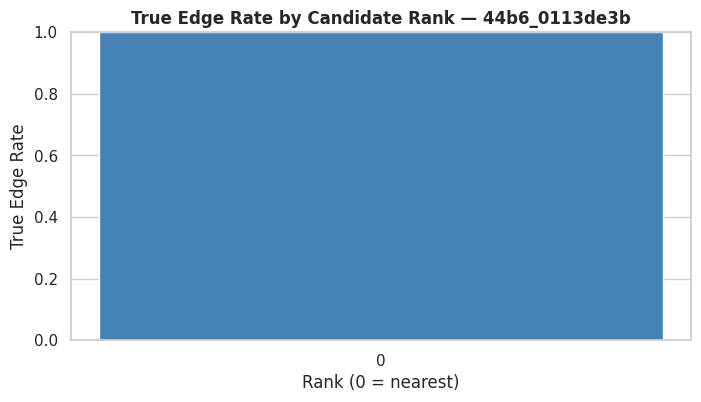

In [64]:
print("TRUE EDGE RATE BY RANK")
rank_stats = (
    labeled
    .groupby("rank")
    .agg(
        n_candidates=("is_true_edge", "size"),
        n_true=("is_true_edge", "sum"),
        true_rate=("is_true_edge", "mean"),
    )
    .round(4)
)
display(rank_stats)

# Visualization
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.bar(rank_stats.index, rank_stats["true_rate"], color="steelblue", edgecolor="white")
plt.xlabel("Rank (0 = nearest)")
plt.ylabel("True Edge Rate")
plt.title(f"True Edge Rate by Candidate Rank — {sid}", fontweight="bold")
plt.xticks(rank_stats.index)
plt.ylim(0, 1)
plt.show()

## 6.6 Class Imbalance

In [65]:
print("CLASS IMBALANCE")
print(labeled["is_true_edge"].value_counts())
print(f"\nPositive class ratio: {labeled['is_true_edge'].mean():.4f}")
print(f"Imbalance ratio (neg/pos): {(1 - labeled['is_true_edge'].mean()) / labeled['is_true_edge'].mean():.1f} : 1")

CLASS IMBALANCE
is_true_edge
True    50
Name: count, dtype: int64

Positive class ratio: 1.0000
Imbalance ratio (neg/pos): 0.0 : 1


# 7. TRAIN / VALIDATION SPLIT

## 7.1 Group Extraction

In [66]:
import numpy as np
import pandas as pd

def get_group(sample_id: str) -> str:
    return sample_id.split("_")[0]

## 7.2 Within-Group Split

In [67]:
def split_within_group(
    sample_ids: list[str],
    val_fraction: float = 0.2,
    seed: int = 42
) -> tuple[list[str], list[str]]:

    rng = np.random.default_rng(seed)

    groups = {}
    for sid in sample_ids:
        groups.setdefault(get_group(sid), []).append(sid)

    train_ids, val_ids = [], []

    for g, ids in groups.items():
        ids = sorted(ids)
        rng.shuffle(ids)

        n_val = max(1, int(round(len(ids) * val_fraction)))
        val_ids.extend(ids[:n_val])
        train_ids.extend(ids[n_val:])

    return sorted(train_ids), sorted(val_ids)

## 7.3 Group-level Hold-out Split

In [68]:
def group_train_val_split(
    sample_ids: list[str],
    val_fraction: float = 0.2,
    seed: int = 0
) -> tuple[list[str], list[str]]:

    rng = np.random.default_rng(seed)

    groups = sorted({get_group(sid) for sid in sample_ids})
    rng.shuffle(groups)

    n_val_groups = max(1, round(len(groups) * val_fraction))
    val_groups = set(groups[:n_val_groups])
    train_groups = set(groups[n_val_groups:])

    train_ids = [sid for sid in sample_ids if get_group(sid) in train_groups]
    val_ids   = [sid for sid in sample_ids if get_group(sid) in val_groups]

    print(f"Groups: {len(groups)} total → {len(train_groups)} train, {len(val_groups)} val")
    print(f"Movies: {len(sample_ids)} total → {len(train_ids)} train, {len(val_ids)} val")

    return train_ids, val_ids

## 7.4 Leakage Verification

In [69]:
def verify_no_leakage(train_ids: list[str], val_ids: list[str]) -> None:

    train_groups = {get_group(sid) for sid in train_ids}
    val_groups   = {get_group(sid) for sid in val_ids}

    group_overlap = train_groups & val_groups
    exact_overlap = set(train_ids) & set(val_ids)

    assert not group_overlap, f"Group leakage detected: {group_overlap}"
    assert not exact_overlap, f"Exact sample_id leakage detected: {exact_overlap}"

    print("No leakage: 0 overlapping groups, 0 overlapping sample_ids.")

## 7.5 Split Summary Table

In [70]:
def split_summary(
    sample_ids: list[str],
    train_ids: list[str],
    val_ids: list[str]
) -> pd.DataFrame:
    
    rows = []
    for sid in sample_ids:
        if sid in train_ids:
            split = "train"
        elif sid in val_ids:
            split = "val"
        else:
            split = "unassigned"
        rows.append({
            "sample_id": sid,
            "group": get_group(sid),
            "split": split
        })

    df = pd.DataFrame(rows)
    return pd.crosstab(df["group"], df["split"])

## 7.6 Usage (Main Within-Group Split)

In [71]:
all_sample_ids = sorted(all_graphs.keys())
print(f"Total train movies: {len(all_sample_ids)}")

# Within-group split
train_ids, val_ids = split_within_group(
    all_sample_ids,
    val_fraction=0.2,
    seed=42
)

print(f"\nTrain movies : {len(train_ids)}")
print(f"Val movies   : {len(val_ids)}")

def verify_within_group_split(train_ids, val_ids):

    exact_overlap = set(train_ids) & set(val_ids)
    assert not exact_overlap, f"Exact sample_id leakage detected: {exact_overlap}"

    train_groups = {get_group(s) for s in train_ids}
    val_groups   = {get_group(s) for s in val_ids}
    group_overlap = train_groups & val_groups

    print("Within-group split verification passed.")
    print(f"  Exact sample overlap : {len(exact_overlap)}  (must be 0)")
    print(f"  Group overlap        : {sorted(group_overlap)}  (expected)")
    print(f"  Train movies         : {len(train_ids)}")
    print(f"  Val movies           : {len(val_ids)}")


verify_within_group_split(train_ids, val_ids)

print("\nSPLIT SUMMARY (Group × Split)")
summary = split_summary(all_sample_ids, train_ids, val_ids)
display(summary)

# Group-wise counts
print("\nTrain groups:")
print(pd.Series([get_group(s) for s in train_ids]).value_counts().sort_index())

print("\nVal groups:")
print(pd.Series([get_group(s) for s in val_ids]).value_counts().sort_index())

Total train movies: 199

Train movies : 159
Val movies   : 40
Within-group split verification passed.
  Exact sample overlap : 0  (must be 0)
  Group overlap        : ['44b6', '6bba']  (expected)
  Train movies         : 159
  Val movies           : 40

SPLIT SUMMARY (Group × Split)


split,train,val
group,,
44b6,57,14
6bba,102,26



Train groups:
44b6     57
6bba    102
Name: count, dtype: int64

Val groups:
44b6    14
6bba    26
Name: count, dtype: int64


## 7.7 Group K-Fold

In [72]:
def group_kfold_split(
    sample_ids: list[str],
    n_splits: int = 2,
    seed: int = 0
):
    rng = np.random.default_rng(seed)
    groups = sorted({get_group(sid) for sid in sample_ids})
    rng.shuffle(groups)

    print(f"Available groups: {groups} (total = {len(groups)})")

    if n_splits > len(groups):
        raise ValueError(
            f"n_splits={n_splits} but only {len(groups)} groups exist. "
            f"Reduce n_splits to at most {len(groups)}."
        )

    folds = np.array_split(groups, n_splits)

    for fold_idx, val_groups in enumerate(folds):
        val_groups = set(val_groups)
        train_ids = [sid for sid in sample_ids if get_group(sid) not in val_groups]
        val_ids   = [sid for sid in sample_ids if get_group(sid) in val_groups]

        print(f"Fold {fold_idx}: {len(val_groups)} val groups | "
              f"{len(train_ids)} train movies | {len(val_ids)} val movies")
        yield train_ids, val_ids

print("GROUP K-FOLD (2 folds)")
for fold_train, fold_val in group_kfold_split(all_sample_ids, n_splits=2, seed=0):
    verify_no_leakage(fold_train, fold_val)

GROUP K-FOLD (2 folds)
Available groups: ['44b6', '6bba'] (total = 2)
Fold 0: 1 val groups | 128 train movies | 71 val movies
No leakage: 0 overlapping groups, 0 overlapping sample_ids.
Fold 1: 1 val groups | 71 train movies | 128 val movies
No leakage: 0 overlapping groups, 0 overlapping sample_ids.


# 7.8 Creating Labeled Candidates from Split

In [73]:
cfg = FeatureConfig(k_neighbors=5)

train_candidates = build_labeled_candidates(all_graphs, train_ids, cfg)
val_candidates   = build_labeled_candidates(all_graphs, val_ids, cfg)

print("\nCANDIDATES AFTER SPLIT")
print(f"Train candidates : {len(train_candidates):,}")
print(f"Val candidates   : {len(val_candidates):,}")
print(f"True edge rate (train): {train_candidates['is_true_edge'].mean():.4f}")
print(f"True edge rate (val)  : {val_candidates['is_true_edge'].mean():.4f}")

Building labeled candidates:   0%|          | 0/159 [00:00<?, ?it/s]/tmp/ipykernel_49/443956261.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby(key, group_keys=False).apply(_margin)
Building labeled candidates:   1%|          | 1/159 [00:00<00:17,  8.91it/s]/tmp/ipykernel_49/443956261.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby(key, group_keys=False).apply(_margin)
/tmp/ipykernel_4


CANDIDATES AFTER SPLIT
Train candidates : 486,912
Val candidates   : 138,503
True edge rate (train): 0.2064
True edge rate (val)  : 0.2049


# 8. MODEL DATASET

## 8.1 Feature List

In [74]:
import numpy as np
import pandas as pd

FEATURE_COLS = [
    "distance_um",
    "rank",
    "speed_um_per_second",
    "distance_ratio_to_nearest",
    "margin_to_runner_up_um",
    "n_candidates_for_source",
]

TARGET_COL = "is_true_edge"

print("Selected features:")
for f in FEATURE_COLS:
    print(f"  - {f}")

Selected features:
  - distance_um
  - rank
  - speed_um_per_second
  - distance_ratio_to_nearest
  - margin_to_runner_up_um
  - n_candidates_for_source


## 8.2 Feature Matrix

In [75]:
def prepare_xy(df: pd.DataFrame, feature_cols: list[str] = FEATURE_COLS):

    X = df[feature_cols].copy()
    y = df[TARGET_COL].astype(int).copy()

    # Missing value handle
    for col in X.columns:
        if X[col].isna().any():
            median_val = X[col].median()
            X[col] = X[col].fillna(median_val)

    return X, y


X_train, y_train = prepare_xy(train_candidates)
X_val,   y_val   = prepare_xy(val_candidates)

print("MODEL DATASET SHAPES")
print(f"X_train : {X_train.shape}")
print(f"y_train : {y_train.shape}  |  positive rate: {y_train.mean():.4f}")
print(f"X_val   : {X_val.shape}")
print(f"y_val   : {y_val.shape}  |  positive rate: {y_val.mean():.4f}")

MODEL DATASET SHAPES
X_train : (486912, 6)
y_train : (486912,)  |  positive rate: 0.2064
X_val   : (138503, 6)
y_val   : (138503,)  |  positive rate: 0.2049


## 8.3 Class Imbalance

In [76]:
print("\nCLASS IMBALANCE")
print("Train:")
print(y_train.value_counts())
print(f"  Ratio (neg:pos) = {(y_train == 0).sum() / max((y_train == 1).sum(), 1):.1f} : 1")

print("\nVal:")
print(y_val.value_counts())
print(f"  Ratio (neg:pos) = {(y_val == 0).sum() / max((y_val == 1).sum(), 1):.1f} : 1")


CLASS IMBALANCE
Train:
is_true_edge
0    386413
1    100499
Name: count, dtype: int64
  Ratio (neg:pos) = 3.8 : 1

Val:
is_true_edge
0    110120
1     28383
Name: count, dtype: int64
  Ratio (neg:pos) = 3.9 : 1


## 8.4 Class Imbalance Handle

In [77]:
# LightGBM / sklearn / LogisticRegression-এ
# class_weight="balanced"

def make_sample_weights(y: pd.Series) -> np.ndarray:
    """
    Positive class-কে বেশি weight দেয়।
    """
    n_pos = (y == 1).sum()
    n_neg = (y == 0).sum()
    total = len(y)

    w_pos = total / (2 * max(n_pos, 1))
    w_neg = total / (2 * max(n_neg, 1))

    weights = np.where(y == 1, w_pos, w_neg)
    return weights


sample_weight_train = make_sample_weights(y_train)
print("Sample weights created.")
print(f"  Positive weight : {sample_weight_train[y_train == 1][0]:.3f}")
print(f"  Negative weight : {sample_weight_train[y_train == 0][0]:.3f}")

Sample weights created.
  Positive weight : 2.422
  Negative weight : 0.630


In [78]:
from sklearn.utils import resample

def balance_by_undersample(X, y, random_state=42):
    """Negative class undersample করে 1:1 ratio আনে"""
    df = X.copy()
    df["_y"] = y.values

    pos = df[df["_y"] == 1]
    neg = df[df["_y"] == 0]

    neg_down = resample(
        neg,
        replace=False,
        n_samples=len(pos),
        random_state=random_state
    )

    balanced = pd.concat([pos, neg_down]).sample(frac=1, random_state=random_state)
    y_bal = balanced["_y"].astype(int)
    X_bal = balanced.drop(columns="_y")
    return X_bal, y_bal

X_train_bal, y_train_bal = balance_by_undersample(X_train, y_train)
print("Balanced train shape:", X_train_bal.shape)

Balanced train shape: (200998, 6)


## 8.6 Feature Summary

In [79]:
print("\nREADY FOR LINKING MODEL")
print(f"FEATURE_COLS     : {FEATURE_COLS}")
print(f"X_train shape    : {X_train.shape}")
print(f"X_val shape      : {X_val.shape}")
print(f"y_train positive : {y_train.mean():.4f}")
print(f"y_val positive   : {y_val.mean():.4f}")

# Optional: sample weights
sample_weight_train = make_sample_weights(y_train)


READY FOR LINKING MODEL
FEATURE_COLS     : ['distance_um', 'rank', 'speed_um_per_second', 'distance_ratio_to_nearest', 'margin_to_runner_up_um', 'n_candidates_for_source']
X_train shape    : (486912, 6)
X_val shape      : (138503, 6)
y_train positive : 0.2064
y_val positive   : 0.2049


# 9. LINKING MODEL

## 9.1 Baseline: Nearest Neighbor Linker

In [80]:
from scipy.spatial import cKDTree
import numpy as np
import pandas as pd

def nearest_neighbor_link(
    nodes: pd.DataFrame, 
    cfg: FeatureConfig = FeatureConfig()
) -> pd.DataFrame:

    nodes_um = add_physical_coordinates(nodes, cfg)
    times = sorted(nodes_um["t"].unique())
    links = []

    for t in times:
        if (t + 1) not in set(times):
            continue

        src = nodes_um.loc[nodes_um["t"] == t]
        tgt = nodes_um.loc[nodes_um["t"] == t + 1]
        if src.empty or tgt.empty:
            continue

        src_coords = src[["z_um", "y_um", "x_um"]].to_numpy()
        tgt_coords = tgt[["z_um", "y_um", "x_um"]].to_numpy()

        tree = cKDTree(tgt_coords)
        distances, nearest_idx = tree.query(src_coords, k=1)

        src_ids = src["node_id"].to_numpy()
        tgt_ids = tgt["node_id"].to_numpy()

        for i in range(len(src)):
            links.append({
                "source_id": int(src_ids[i]),
                "target_id": int(tgt_ids[nearest_idx[i]]),
                "source_t": int(t),
                "target_t": int(t + 1),
                "distance_um": float(distances[i]),
            })

    return pd.DataFrame(links)

### Baseline evaluate

In [81]:
def evaluate_baseline(
    nodes: pd.DataFrame, 
    true_edges: pd.DataFrame, 
    cfg: FeatureConfig = FeatureConfig()
) -> dict:
    predicted = nearest_neighbor_link(nodes, cfg)

    pred_pairs = set(zip(predicted["source_id"], predicted["target_id"]))
    true_pairs = set(zip(true_edges["source_id"], true_edges["target_id"]))
    correct = pred_pairs & true_pairs

    accuracy = len(correct) / len(pred_pairs) if pred_pairs else np.nan
    coverage = len(correct) / len(true_pairs) if true_pairs else np.nan

    return {
        "n_predicted": len(pred_pairs),
        "n_true": len(true_pairs),
        "n_correct": len(correct),
        "precision": round(accuracy, 4),
        "recall": round(coverage, 4),
    }


example_sid = val_ids[0]
nodes_ex, edges_ex = all_graphs[example_sid]
baseline_metrics = evaluate_baseline(nodes_ex, edges_ex)
print("BASELINE (Nearest Neighbor)")
print(baseline_metrics)

BASELINE (Nearest Neighbor)
{'n_predicted': 198, 'n_true': 198, 'n_correct': 198, 'precision': 1.0, 'recall': 1.0}


## 9.2 ML Model: Candidate Edge Classifier

In [82]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, 
    f1_score, roc_auc_score, classification_report
)

FEATURE_COLS = [
    "distance_um",
    "rank",
    "speed_um_per_second",
    "distance_ratio_to_nearest",
    "margin_to_runner_up_um",
    "n_candidates_for_source",
]

def prepare_xy(df, feature_cols=FEATURE_COLS):
    X = df[feature_cols].copy()
    y = df["is_true_edge"].astype(int)
    for col in X.columns:
        if X[col].isna().any():
            X[col] = X[col].fillna(X[col].median())
    return X, y

X_train, y_train = prepare_xy(train_candidates)
X_val,   y_val   = prepare_xy(val_candidates)

print(f"X_train: {X_train.shape} | pos rate: {y_train.mean():.4f}")
print(f"X_val  : {X_val.shape} | pos rate: {y_val.mean():.4f}")

X_train: (486912, 6) | pos rate: 0.2064
X_val  : (138503, 6) | pos rate: 0.2049


### Model creation (LightGBM → XGBoost → HistGradientBoosting)

In [83]:
def make_model(model_type: str = "auto"):
    """
    model_type: 'auto' | 'lgbm' | 'xgb' | 'hgb' | 'logistic'
    """
    if model_type in ("auto", "lgbm"):
        try:
            import lightgbm as lgb
            model = lgb.LGBMClassifier(
                n_estimators=300,
                learning_rate=0.05,
                num_leaves=31,
                class_weight="balanced",
                random_state=42,
                verbosity=-1,
            )
            return model, "LightGBM"
        except ImportError:
            if model_type == "lgbm":
                raise

    if model_type in ("auto", "xgb"):
        try:
            from xgboost import XGBClassifier
            scale = (y_train == 0).sum() / max((y_train == 1).sum(), 1)
            model = XGBClassifier(
                n_estimators=300,
                learning_rate=0.05,
                max_depth=6,
                scale_pos_weight=scale,
                random_state=42,
                eval_metric="logloss",
            )
            return model, "XGBoost"
        except ImportError:
            if model_type == "xgb":
                raise

    if model_type in ("auto", "hgb"):
        from sklearn.ensemble import HistGradientBoostingClassifier
        model = HistGradientBoostingClassifier(
            max_iter=300,
            learning_rate=0.05,
            max_depth=6,
            random_state=42,
        )
        return model, "HistGradientBoosting"

    if model_type == "logistic":
        from sklearn.linear_model import LogisticRegression
        model = LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42,
        )
        return model, "LogisticRegression"

    raise ValueError(f"Unknown model_type: {model_type}")


model, model_name = make_model("auto")
print(f"Using model: {model_name}")

Using model: LightGBM


### Train

In [84]:
model.fit(X_train, y_train)
print("Training done.")

Training done.


### Validation Evaluation

In [85]:
val_proba = model.predict_proba(X_val)[:, 1]
val_pred  = (val_proba >= 0.5).astype(int)

print("\nML MODEL VALIDATION RESULTS")
print(f"Model    : {model_name}")
print(f"Accuracy : {accuracy_score(y_val, val_pred):.4f}")
print(f"Precision: {precision_score(y_val, val_pred):.4f}")
print(f"Recall   : {recall_score(y_val, val_pred):.4f}")
print(f"F1       : {f1_score(y_val, val_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_val, val_proba):.4f}")

print("\nClassification Report:")
print(classification_report(y_val, val_pred, digits=4))


ML MODEL VALIDATION RESULTS
Model    : LightGBM
Accuracy : 0.9977
Precision: 0.9903
Recall   : 0.9984
F1       : 0.9943
ROC-AUC  : 1.0000

Classification Report:
              precision    recall  f1-score   support

           0     0.9996    0.9975    0.9985    110120
           1     0.9903    0.9984    0.9943     28383

    accuracy                         0.9977    138503
   macro avg     0.9949    0.9980    0.9964    138503
weighted avg     0.9977    0.9977    0.9977    138503



## 9.3 Candidate → Predicted Edges (Decode)

In [86]:
def link_with_model(
    candidates: pd.DataFrame,
    model,
    feature_cols: list[str] = FEATURE_COLS,
    threshold: float = 0.5,
    top_k_per_source: int = 1,
) -> pd.DataFrame:
    X = candidates[feature_cols].copy()
    for col in X.columns:
        if X[col].isna().any():
            X[col] = X[col].fillna(X[col].median())

    proba = model.predict_proba(X)[:, 1]
    df = candidates.copy()
    df["score"] = proba

    # threshold filter
    df = df[df["score"] >= threshold].copy()

    # per-source top-k
    df = (
        df.sort_values(["source_id", "score"], ascending=[True, False])
        .groupby("source_id")
        .head(top_k_per_source)
        .reset_index(drop=True)
    )

    return df[["source_id", "target_id", "source_t", "target_t", "distance_um", "score"]]

### Example: One val movie's prediction

In [87]:
sid = val_ids[0]
nodes, true_edges = all_graphs[sid]

cands = build_candidate_edges(nodes, cfg)
cands = add_ambiguity_features(cands)

predicted_edges = link_with_model(cands, model, threshold=0.5, top_k_per_source=1)

print(f"\nPredicted edges for {sid} ")
print(f"Predicted links: {len(predicted_edges)}")
print(f"True links     : {len(true_edges)}")
display(predicted_edges.head(10))


Predicted edges for 44b6_40c45f5a 
Predicted links: 198
True links     : 198


/tmp/ipykernel_49/443956261.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby(key, group_keys=False).apply(_margin)


,source_id,target_id,source_t,target_t,distance_um,score
0,141000000026,142000000026,0,1,1.816805,0.999999
1,141000000027,142000000027,0,1,2.632801,0.999975
2,142000000026,143000000026,1,2,2.031250,0.999977
3,142000000027,143000000027,1,2,2.929510,0.999973
4,143000000026,144000000026,2,3,2.569351,0.999977
5,143000000027,144000000027,2,3,3.350023,0.999973
6,144000000026,145000000026,3,4,3.275292,0.999973
7,144000000027,145000000027,3,4,2.071477,0.999977
8,145000000026,146000000026,4,5,4.755034,0.999089
9,145000000027,146000000027,4,5,3.656250,0.999962


## 9.4 Feature Importance


Feature Importance
distance_um                  3509
margin_to_runner_up_um       2955
distance_ratio_to_nearest    1447
n_candidates_for_source       707
rank                          382
speed_um_per_second             0
dtype: int32


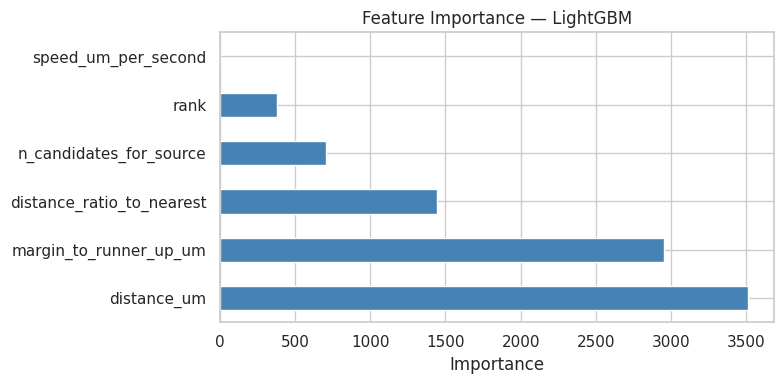

In [88]:
if hasattr(model, "feature_importances_"):
    imp = pd.Series(model.feature_importances_, index=FEATURE_COLS)
    imp = imp.sort_values(ascending=False)

    print("\nFeature Importance")
    print(imp.round(4))

    import matplotlib.pyplot as plt
    imp.plot(kind="barh", figsize=(8, 4), color="steelblue")
    plt.title(f"Feature Importance — {model_name}")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()

# 10. EVALUATION

## 10.1 Basic Classification Metrics

In [89]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    confusion_matrix, classification_report,
    precision_recall_curve, roc_curve
)
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

val_proba = model.predict_proba(X_val)[:, 1]
val_pred  = (val_proba >= 0.5).astype(int)

print("VALIDATION METRICS (threshold=0.5)")
print(f"Model     : {model_name}")
print(f"Accuracy  : {accuracy_score(y_val, val_pred):.4f}")
print(f"Precision : {precision_score(y_val, val_pred):.4f}")
print(f"Recall    : {recall_score(y_val, val_pred):.4f}")
print(f"F1        : {f1_score(y_val, val_pred):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_val, val_proba):.4f}")
print(f"PR-AUC    : {average_precision_score(y_val, val_proba):.4f}")

print("\nClassification Report:")
print(classification_report(y_val, val_pred, digits=4, target_names=["False", "True"]))

VALIDATION METRICS (threshold=0.5)
Model     : LightGBM
Accuracy  : 0.9977
Precision : 0.9903
Recall    : 0.9984
F1        : 0.9943
ROC-AUC   : 1.0000
PR-AUC    : 0.9998

Classification Report:
              precision    recall  f1-score   support

       False     0.9996    0.9975    0.9985    110120
        True     0.9903    0.9984    0.9943     28383

    accuracy                         0.9977    138503
   macro avg     0.9949    0.9980    0.9964    138503
weighted avg     0.9977    0.9977    0.9977    138503



## 10.2 Confusion Matrix

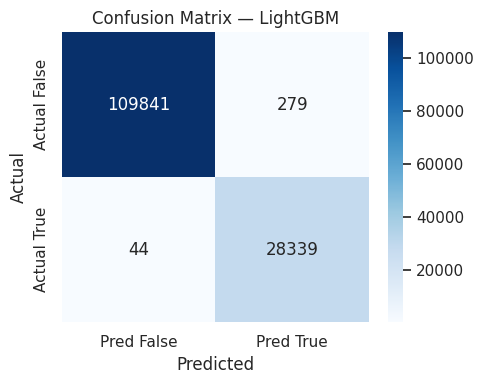

TN=109,841  FP=279  FN=44  TP=28,339


In [90]:
cm = confusion_matrix(y_val, val_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Pred False", "Pred True"],
    yticklabels=["Actual False", "Actual True"]
)
plt.title(f"Confusion Matrix — {model_name}")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn:,}  FP={fp:,}  FN={fn:,}  TP={tp:,}")

## 10.3 ROC Curve & Precision-Recall Curve

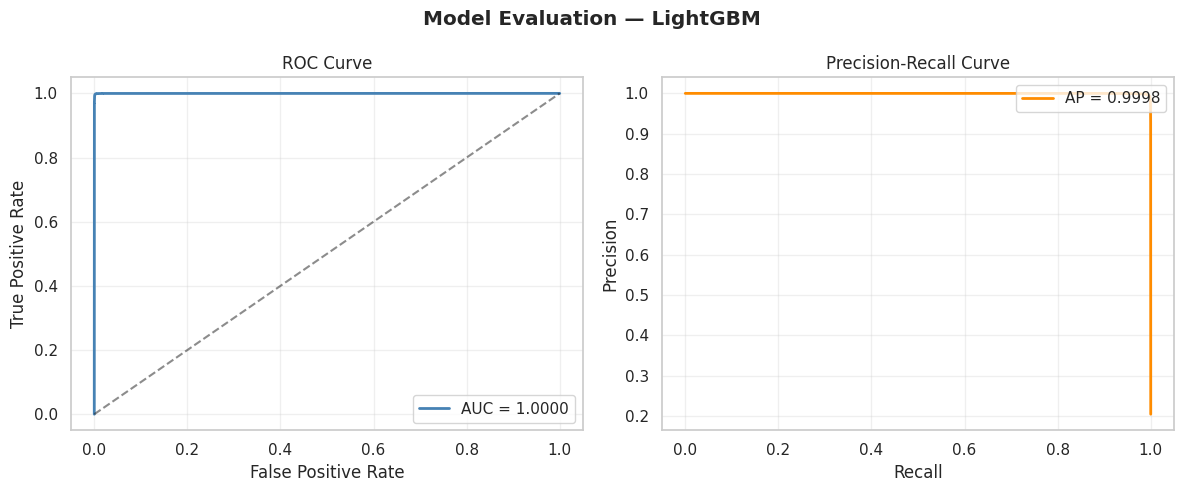

In [91]:
fpr, tpr, _ = roc_curve(y_val, val_proba)
precisions, recalls, thresholds = precision_recall_curve(y_val, val_proba)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC
axes[0].plot(fpr, tpr, color="steelblue", lw=2, label=f"AUC = {roc_auc_score(y_val, val_proba):.4f}")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve")
axes[0].legend(loc="lower right")
axes[0].grid(True, alpha=0.3)

# PR Curve
axes[1].plot(recalls, precisions, color="darkorange", lw=2,
             label=f"AP = {average_precision_score(y_val, val_proba):.4f}")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve")
axes[1].legend(loc="upper right")
axes[1].grid(True, alpha=0.3)

plt.suptitle(f"Model Evaluation — {model_name}", fontweight="bold")
plt.tight_layout()
plt.show()

## 10.4 Threshold Tuning

THRESHOLD TUNING


,threshold,precision,recall,f1,n_pred_positive
0,0.10,0.9772,0.9994,0.9882,29027
1,0.15,0.9808,0.9992,0.9899,28915
2,0.20,0.9830,0.9990,0.9909,28843
3,0.25,0.9848,0.9989,0.9918,28790
4,0.30,0.9861,0.9988,0.9924,28751
5,0.35,0.9872,0.9988,0.9929,28716
6,0.40,0.9883,0.9986,0.9934,28680
7,0.45,0.9891,0.9986,0.9938,28655
8,0.50,0.9903,0.9984,0.9943,28618
9,0.55,0.9911,0.9982,0.9947,28585



Best F1 threshold: 0.8  (F1=0.9958)


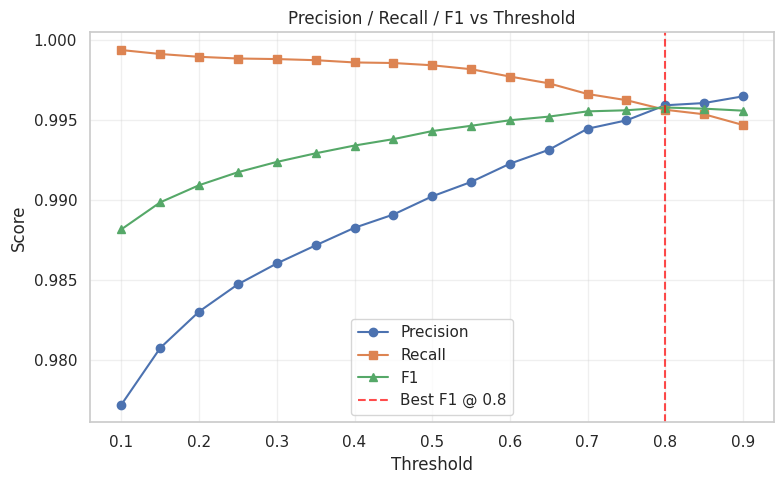

In [92]:
def evaluate_at_thresholds(y_true, y_proba, thresholds=None):
    if thresholds is None:
        thresholds = np.arange(0.1, 0.95, 0.05)

    rows = []
    for th in thresholds:
        pred = (y_proba >= th).astype(int)
        rows.append({
            "threshold": round(th, 2),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0),
            "n_pred_positive": int(pred.sum()),
        })
    return pd.DataFrame(rows)


thresh_df = evaluate_at_thresholds(y_val, val_proba)
print("THRESHOLD TUNING")
display(thresh_df.round(4))

# Best F1 threshold
best_row = thresh_df.loc[thresh_df["f1"].idxmax()]
print(f"\nBest F1 threshold: {best_row['threshold']}  (F1={best_row['f1']:.4f})")

# Plot
plt.figure(figsize=(8, 5))
plt.plot(thresh_df["threshold"], thresh_df["precision"], label="Precision", marker="o")
plt.plot(thresh_df["threshold"], thresh_df["recall"], label="Recall", marker="s")
plt.plot(thresh_df["threshold"], thresh_df["f1"], label="F1", marker="^")
plt.axvline(best_row["threshold"], color="red", linestyle="--", alpha=0.7, label=f"Best F1 @ {best_row['threshold']}")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision / Recall / F1 vs Threshold")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 10.5 Candidate Rank Analysis

CANDIDATE RANK ANALYSIS


,n_candidates,n_true,true_rate,mean_score,mean_distance
rank,,,,,
0,29077,28309,0.9736,0.9785,2.6633
1,28826,72,0.0025,0.0061,25.8649
2,27516,1,0.0000,0.0003,35.7683
3,26999,1,0.0000,0.0000,44.1406
4,26085,0,0.0000,0.0000,51.6402


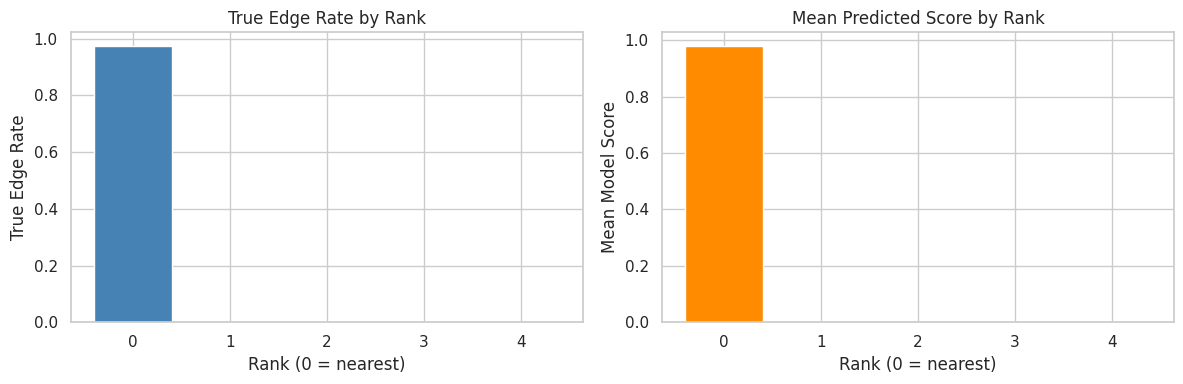

In [93]:
print("CANDIDATE RANK ANALYSIS")

val_scored = val_candidates.copy()
X_tmp = val_scored[FEATURE_COLS].copy()
for col in X_tmp.columns:
    if X_tmp[col].isna().any():
        X_tmp[col] = X_tmp[col].fillna(X_tmp[col].median())
val_scored["score"] = model.predict_proba(X_tmp)[:, 1]

# Rank-wise true edge rate
rank_analysis = (
    val_scored
    .groupby("rank")
    .agg(
        n_candidates=("is_true_edge", "size"),
        n_true=("is_true_edge", "sum"),
        true_rate=("is_true_edge", "mean"),
        mean_score=("score", "mean"),
        mean_distance=("distance_um", "mean"),
    )
    .round(4)
)
display(rank_analysis)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(rank_analysis.index, rank_analysis["true_rate"], color="steelblue", edgecolor="white")
axes[0].set_xlabel("Rank (0 = nearest)")
axes[0].set_ylabel("True Edge Rate")
axes[0].set_title("True Edge Rate by Rank")
axes[0].set_xticks(rank_analysis.index)

axes[1].bar(rank_analysis.index, rank_analysis["mean_score"], color="darkorange", edgecolor="white")
axes[1].set_xlabel("Rank (0 = nearest)")
axes[1].set_ylabel("Mean Model Score")
axes[1].set_title("Mean Predicted Score by Rank")
axes[1].set_xticks(rank_analysis.index)

plt.tight_layout()
plt.show()

## 10.6 Per-Movie Tracking Metrics (Link-level)

In [94]:
def evaluate_movie_links(
    sample_id: str,
    graphs: dict,
    model,
    cfg: FeatureConfig,
    threshold: float = 0.5,
    top_k: int = 1,
) -> dict:

    nodes, true_edges = graphs[sample_id]
    cands = build_candidate_edges(nodes, cfg)
    cands = add_ambiguity_features(cands)
    pred = link_with_model(cands, model, threshold=threshold, top_k_per_source=top_k)

    pred_pairs = set(zip(pred["source_id"], pred["target_id"]))
    true_pairs = set(zip(true_edges["source_id"], true_edges["target_id"]))
    correct = pred_pairs & true_pairs

    precision = len(correct) / len(pred_pairs) if pred_pairs else 0.0
    recall    = len(correct) / len(true_pairs) if true_pairs else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0

    return {
        "sample_id": sample_id,
        "group": get_group(sample_id),
        "n_pred": len(pred_pairs),
        "n_true": len(true_pairs),
        "n_correct": len(correct),
        "precision": round(precision, 4),
        "recall": round(recall, 4),
        "f1": round(f1, 4),
    }

movie_results = []
for sid in tqdm(val_ids, desc="Evaluating val movies"):
    movie_results.append(
        evaluate_movie_links(sid, all_graphs, model, cfg, threshold=0.5, top_k=1)
    )

movie_df = pd.DataFrame(movie_results)

print("\nPER-MOVIE LINK METRICS (Val)")
print(movie_df[["precision", "recall", "f1"]].describe().round(4))

print("\nBy group:")
display(
    movie_df.groupby("group")[["precision", "recall", "f1"]]
    .mean()
    .round(4)
)

display(movie_df.sort_values("f1").head(10))  # worst movies
display(movie_df.sort_values("f1", ascending=False).head(10))  # best movies

Evaluating val movies:   0%|          | 0/40 [00:00<?, ?it/s]/tmp/ipykernel_49/443956261.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby(key, group_keys=False).apply(_margin)
Evaluating val movies:   2%|▎         | 1/40 [00:00<00:07,  4.89it/s]/tmp/ipykernel_49/443956261.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby(key, group_keys=False).apply(_margin)
Evaluating val movies:   5%|▌ 


PER-MOVIE LINK METRICS (Val)
       precision   recall       f1
count    40.0000  40.0000  40.0000
mean      0.9952   0.9967   0.9959
std       0.0073   0.0041   0.0049
min       0.9644   0.9857   0.9751
25%       0.9930   0.9945   0.9941
50%       0.9980   0.9983   0.9970
75%       1.0000   1.0000   0.9996
max       1.0000   1.0000   1.0000

By group:


,precision,recall,f1
group,,,
44b6,0.9992,0.9965,0.9979
6bba,0.9930,0.9969,0.9949


,sample_id,group,n_pred,n_true,n_correct,precision,recall,f1
31,6bba_7f87b3d8,6bba,955,934,921,0.9644,0.9861,0.9751
16,6bba_20852818,6bba,919,909,902,0.9815,0.9923,0.9869
14,6bba_09961292,6bba,1908,1871,1867,0.9785,0.9979,0.9881
19,6bba_337b1b3a,6bba,1224,1213,1204,0.9837,0.9926,0.9881
36,6bba_d3da753b,6bba,854,857,848,0.9930,0.9895,0.9912
39,6bba_fc83837d,6bba,928,923,918,0.9892,0.9946,0.9919
11,44b6_d754aa59,44b6,69,70,69,1.0000,0.9857,0.9928
5,44b6_87bba6c4,44b6,147,149,147,1.0000,0.9866,0.9932
10,44b6_d29c9ab2,44b6,1332,1328,1322,0.9925,0.9955,0.9940
34,6bba_c328f2fd,6bba,500,500,497,0.9940,0.9940,0.9940


,sample_id,group,n_pred,n_true,n_correct,precision,recall,f1
0,44b6_40c45f5a,44b6,198,198,198,1.0,1.0,1.0
1,44b6_415c0a3a,44b6,322,322,322,1.0,1.0,1.0
2,44b6_66f9292d,44b6,198,198,198,1.0,1.0,1.0
7,44b6_95029e92,44b6,198,198,198,1.0,1.0,1.0
6,44b6_90724892,44b6,103,103,103,1.0,1.0,1.0
27,6bba_5f89039d,6bba,885,885,885,1.0,1.0,1.0
12,44b6_db3c847b,44b6,162,162,162,1.0,1.0,1.0
9,44b6_b2c44266,44b6,168,168,168,1.0,1.0,1.0
37,6bba_d5eae175,6bba,519,519,519,1.0,1.0,1.0
25,6bba_5b28472a,6bba,724,724,724,1.0,1.0,1.0


## 10.7 Baseline vs ML Comparison

In [95]:
# Baseline metrics on same val movies
baseline_rows = []
for sid in val_ids[:20]:
    nodes, edges = all_graphs[sid]
    m = evaluate_baseline(nodes, edges, cfg)
    m["sample_id"] = sid
    m["method"] = "NearestNeighbor"
    baseline_rows.append(m)

baseline_df = pd.DataFrame(baseline_rows)

print("===== BASELINE vs ML (sample of val movies) =====")
print("Baseline (NN) mean precision:", baseline_df["precision"].mean().round(4))
print("Baseline (NN) mean recall   :", baseline_df["recall"].mean().round(4))

ml_subset = movie_df[movie_df["sample_id"].isin(baseline_df["sample_id"])]
print("ML model mean precision     :", ml_subset["precision"].mean().round(4))
print("ML model mean recall        :", ml_subset["recall"].mean().round(4))
print("ML model mean F1            :", ml_subset["f1"].mean().round(4))

===== BASELINE vs ML (sample of val movies) =====
Baseline (NN) mean precision: 0.9807
Baseline (NN) mean recall   : 0.9974
ML model mean precision     : 0.996
ML model mean recall        : 0.9966
ML model mean F1            : 0.9963


# 11. TRACK RECONSTRUCTION

## 11.1 Assigning Track ID from Predicted Edges

In [96]:
import networkx as nx
import numpy as np
import pandas as pd
from collections import defaultdict

def reconstruct_tracks(
    nodes: pd.DataFrame,
    predicted_edges: pd.DataFrame,
) -> pd.DataFrame:

    G = nx.DiGraph()
    G.add_nodes_from(nodes["node_id"].tolist())

    for _, row in predicted_edges.iterrows():
        G.add_edge(int(row["source_id"]), int(row["target_id"]))

    # Weakly connected components = tracks
    components = list(nx.weakly_connected_components(G))

    # Stable ordering: by earliest time, then min node_id
    node_t = nodes.set_index("node_id")["t"].to_dict()

    def sort_key(comp):
        times = [node_t.get(n, 0) for n in comp]
        return (min(times), min(comp))

    components = sorted(components, key=sort_key)

    track_map = {}
    for track_id, comp in enumerate(components, start=1):
        for node_id in comp:
            track_map[node_id] = track_id

    out = nodes.copy()
    out["track_id"] = out["node_id"].map(track_map)

    # Isolated nodes (no edges) also get a track_id
    missing = out["track_id"].isna()
    if missing.any():
        next_id = int(out["track_id"].max()) + 1 if out["track_id"].notna().any() else 1
        for idx in out.loc[missing].index:
            out.loc[idx, "track_id"] = next_id
            next_id += 1

    out["track_id"] = out["track_id"].astype(int)
    return out

## 11.2 Full Pipeline of a Movie (Predict → Track)

In [97]:
def track_one_movie(
    sample_id: str,
    graphs: dict,
    model,
    cfg: FeatureConfig,
    threshold: float = 0.5,
    top_k: int = 1,
) -> tuple[pd.DataFrame, pd.DataFrame]:

    nodes, _ = graphs[sample_id]

    cands = build_candidate_edges(nodes, cfg)
    cands = add_ambiguity_features(cands)
    pred_edges = link_with_model(
        cands, model,
        threshold=threshold,
        top_k_per_source=top_k
    )

    tracked = reconstruct_tracks(nodes, pred_edges)
    tracked["sample_id"] = sample_id
    tracked["dataset"] = sample_id  

    return tracked, pred_edges

In [98]:
sid = val_ids[0]
tracked_nodes, pred_edges = track_one_movie(sid, all_graphs, model, cfg)

print(f" TRACK RECONSTRUCTION: {sid}")
print(f"Nodes          : {len(tracked_nodes)}")
print(f"Predicted edges: {len(pred_edges)}")
print(f"Unique tracks  : {tracked_nodes['track_id'].nunique()}")
print(f"\nTrack size distribution:")
print(tracked_nodes.groupby("track_id").size().describe().round(1))

display(tracked_nodes.head(10))

 TRACK RECONSTRUCTION: 44b6_40c45f5a
Nodes          : 200
Predicted edges: 198
Unique tracks  : 2

Track size distribution:
count      2.0
mean     100.0
std        0.0
min      100.0
25%      100.0
50%      100.0
75%      100.0
max      100.0
dtype: float64


/tmp/ipykernel_49/443956261.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby(key, group_keys=False).apply(_margin)


,node_id,t,z,y,x,track_id,sample_id,dataset
0,141000000026,0,28,247,218,1,44b6_40c45f5a,44b6_40c45f5a
1,141000000027,0,33,251,179,2,44b6_40c45f5a,44b6_40c45f5a
2,142000000026,1,28,243,216,1,44b6_40c45f5a,44b6_40c45f5a
3,142000000027,1,32,246,178,2,44b6_40c45f5a,44b6_40c45f5a
4,143000000026,2,28,239,213,1,44b6_40c45f5a,44b6_40c45f5a
5,143000000027,2,32,240,174,2,44b6_40c45f5a,44b6_40c45f5a
6,144000000026,3,28,233,211,1,44b6_40c45f5a,44b6_40c45f5a
7,144000000027,3,33,234,170,2,44b6_40c45f5a,44b6_40c45f5a
8,145000000026,4,28,225,210,1,44b6_40c45f5a,44b6_40c45f5a
9,145000000027,4,32,231,171,2,44b6_40c45f5a,44b6_40c45f5a


## 11.3 Cell Trajectories (Track-level Summary)

In [99]:
def build_trajectory_summary(tracked_nodes: pd.DataFrame) -> pd.DataFrame:

    summary = (
        tracked_nodes
        .groupby("track_id")
        .agg(
            n_nodes=("node_id", "size"),
            start_t=("t", "min"),
            end_t=("t", "max"),
            start_z=("z", "first"),
            start_y=("y", "first"),
            start_x=("x", "first"),
            end_z=("z", "last"),
            end_y=("y", "last"),
            end_x=("x", "last"),
        )
        .reset_index()
    )
    summary["duration"] = summary["end_t"] - summary["start_t"] + 1
    return summary.sort_values("start_t")


traj = build_trajectory_summary(tracked_nodes)
print("TRAJECTORY SUMMARY")
display(traj.head(15))
print(f"\nMean track duration: {traj['duration'].mean():.1f}")
print(f"Median track duration: {traj['duration'].median():.1f}")

TRAJECTORY SUMMARY


,track_id,n_nodes,start_t,end_t,start_z,start_y,start_x,end_z,end_y,end_x,duration
0,1,100,0,99,28,247,218,24,17,125,100
1,2,100,0,99,33,251,179,29,13,105,100



Mean track duration: 100.0
Median track duration: 100.0


## 11.4 Cell Divisions Detect

In [100]:
def detect_divisions(
    predicted_edges: pd.DataFrame,
    nodes: pd.DataFrame,
) -> pd.DataFrame:

    out_degree = predicted_edges.groupby("source_id").size()
    division_sources = out_degree[out_degree >= 2].index.tolist()

    if not division_sources:
        return pd.DataFrame(columns=[
            "parent_id", "parent_t", "daughter_ids", "n_daughters"
        ])

    node_t = nodes.set_index("node_id")["t"].to_dict()

    records = []
    for parent in division_sources:
        daughters = predicted_edges.loc[
            predicted_edges["source_id"] == parent, "target_id"
        ].tolist()
        records.append({
            "parent_id": parent,
            "parent_t": node_t.get(parent, -1),
            "daughter_ids": daughters,
            "n_daughters": len(daughters),
        })

    return pd.DataFrame(records)


divisions = detect_divisions(pred_edges, tracked_nodes)
print("DETECTED DIVISIONS")
print(f"Number of division events: {len(divisions)}")
display(divisions.head(10))

DETECTED DIVISIONS
Number of division events: 0


,parent_id,parent_t,daughter_ids,n_daughters


## 11.5 Connected Components Analysis

In [101]:
def analyze_components(tracked_nodes: pd.DataFrame, predicted_edges: pd.DataFrame) -> dict:
    G = nx.DiGraph()
    G.add_nodes_from(tracked_nodes["node_id"].tolist())
    for _, r in predicted_edges.iterrows():
        G.add_edge(int(r["source_id"]), int(r["target_id"]))

    n_weak = nx.number_weakly_connected_components(G)
    n_strong = nx.number_strongly_connected_components(G)

    in_deg = dict(G.in_degree())
    out_deg = dict(G.out_degree())

    return {
        "n_nodes": G.number_of_nodes(),
        "n_edges": G.number_of_edges(),
        "n_tracks": n_weak,
        "n_strong_components": n_strong,
        "n_roots": sum(1 for d in in_deg.values() if d == 0),
        "n_leaves": sum(1 for d in out_deg.values() if d == 0),
        "n_divisions": sum(1 for d in out_deg.values() if d >= 2),
    }


comp_info = analyze_components(tracked_nodes, pred_edges)
print("GRAPH / COMPONENT ANALYSIS")
for k, v in comp_info.items():
    print(f"  {k:25s}: {v}")

GRAPH / COMPONENT ANALYSIS
  n_nodes                  : 200
  n_edges                  : 198
  n_tracks                 : 2
  n_strong_components      : 200
  n_roots                  : 2
  n_leaves                 : 2
  n_divisions              : 0


## 11.6 Visualization: Track Trajectories (2D projection)

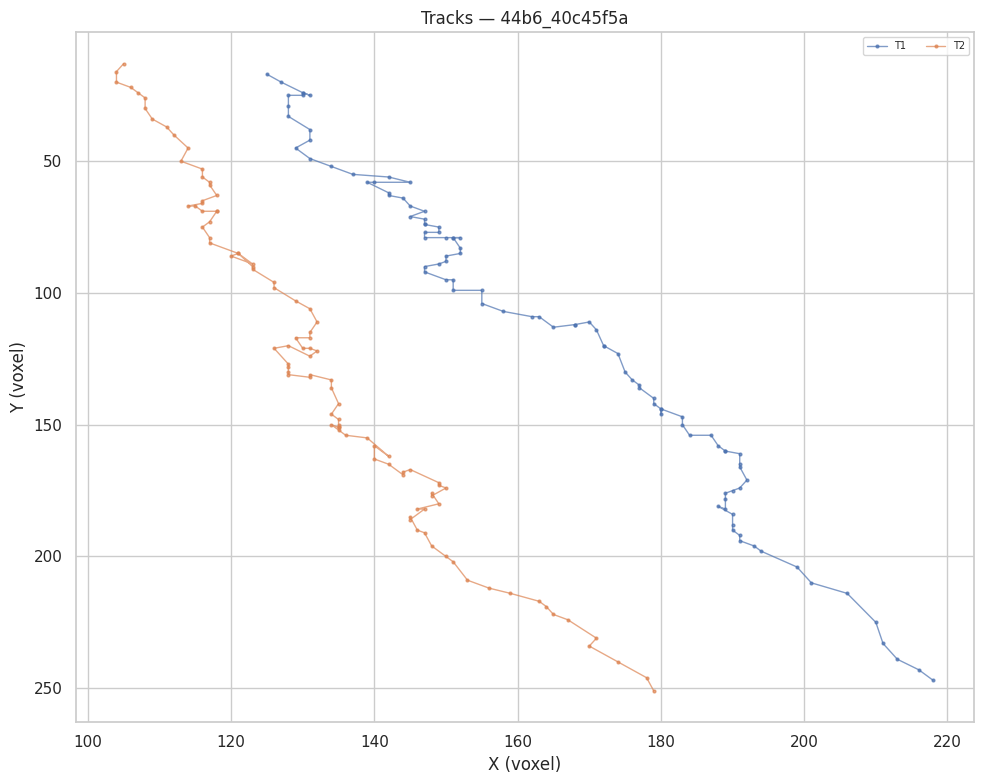

In [102]:
import matplotlib.pyplot as plt

def plot_tracks(
    tracked_nodes: pd.DataFrame,
    max_tracks: int = 30,
    title: str = "Cell Tracks",
):

    track_sizes = tracked_nodes.groupby("track_id").size().sort_values(ascending=False)
    selected = track_sizes.head(max_tracks).index.tolist()

    plot_df = tracked_nodes[tracked_nodes["track_id"].isin(selected)].copy()
    plot_df = plot_df.sort_values(["track_id", "t"])

    fig, ax = plt.subplots(figsize=(10, 8))

    for tid, group in plot_df.groupby("track_id"):
        ax.plot(group["x"], group["y"], "-o", markersize=2, linewidth=1, alpha=0.7, label=f"T{tid}")

    ax.set_xlabel("X (voxel)")
    ax.set_ylabel("Y (voxel)")
    ax.set_title(title)
    ax.invert_yaxis()  # image coordinate
    ax.legend(fontsize=7, ncol=2, loc="upper right")
    plt.tight_layout()
    plt.show()


plot_tracks(tracked_nodes, max_tracks=25, title=f"Tracks — {sid}")

## 11.7 Track all Val Movies (Batch)

In [103]:
def track_all_movies(
    sample_ids: list[str],
    graphs: dict,
    model,
    cfg: FeatureConfig,
    threshold: float = 0.5,
) -> pd.DataFrame:

    parts = []
    for sid in tqdm(sample_ids, desc="Tracking movies"):
        tracked, _ = track_one_movie(sid, graphs, model, cfg, threshold=threshold)
        parts.append(tracked)
    return pd.concat(parts, ignore_index=True)

df_tracked_val = track_all_movies(val_ids, all_graphs, model, cfg)
print(df_tracked_val.groupby("sample_id")["track_id"].nunique().describe())

Tracking movies:   0%|          | 0/40 [00:00<?, ?it/s]/tmp/ipykernel_49/443956261.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby(key, group_keys=False).apply(_margin)
Tracking movies:   2%|▎         | 1/40 [00:00<00:08,  4.73it/s]/tmp/ipykernel_49/443956261.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby(key, group_keys=False).apply(_margin)
Tracking movies:   5%|▌         | 2/40 [00

count    40.000000
mean     21.425000
std      16.807946
min       2.000000
25%       8.250000
50%      18.500000
75%      33.000000
max      69.000000
Name: track_id, dtype: float64


# 12. FINAL TRACKER

In [104]:
import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment
from scipy.spatial import cKDTree
from tqdm import tqdm

# Physical scales
Z_SCALE, Y_SCALE, X_SCALE = 1.625, 0.40625, 0.40625
MAX_DISTANCE_UM = 8.0

## 12.1 ML Tracker (Classifier-based)

In [105]:
def ml_tracker(
    sample_id: str,
    graphs: dict,
    model,
    cfg: FeatureConfig,
    threshold: float = 0.5,
) -> pd.DataFrame:

    tracked, _ = track_one_movie(
        sample_id, graphs, model, cfg,
        threshold=threshold, top_k=1
    )
    return tracked

## 12.2 Hungarian Tracker (Frame-to-Frame)

In [106]:
def hungarian_tracker(
    nodes: pd.DataFrame,
    max_distance_um: float = MAX_DISTANCE_UM,
) -> pd.DataFrame:

    df = nodes.copy()

    # Physical coordinates
    if "z_um" not in df.columns:
        df["z_um"] = df["z"] * Z_SCALE
        df["y_um"] = df["y"] * Y_SCALE
        df["x_um"] = df["x"] * X_SCALE

    df["track_id"] = -1
    next_id = 0

    # First frame
    first = df[df["t"] == df["t"].min()]
    for idx in first.index:
        df.loc[idx, "track_id"] = next_id
        next_id += 1

    times = sorted(df["t"].unique())
    for i in range(len(times) - 1):
        t, t_next = times[i], times[i + 1]
        current = df[df["t"] == t]
        nxt = df[df["t"] == t_next]

        if current.empty or nxt.empty:
            continue

        cur_pos = current[["z_um", "y_um", "x_um"]].to_numpy(dtype=np.float64)
        nxt_pos = nxt[["z_um", "y_um", "x_um"]].to_numpy(dtype=np.float64)

        # Distance matrix
        diff = cur_pos[:, None, :] - nxt_pos[None, :, :]
        dist = np.sqrt((diff ** 2).sum(axis=2))

        row_ind, col_ind = linear_sum_assignment(dist)

        for r, c in zip(row_ind, col_ind):
            if dist[r, c] <= max_distance_um:
                src_idx = current.index[r]
                tgt_idx = nxt.index[c]
                df.loc[tgt_idx, "track_id"] = df.loc[src_idx, "track_id"]

        # Unmatched → new tracks
        unmatched = nxt[df.loc[nxt.index, "track_id"] == -1]
        for idx in unmatched.index:
            df.loc[idx, "track_id"] = next_id
            next_id += 1

    return df

## 12.3 SORT-style Tracker (Kalman + Hungarian)

In [107]:
class SimpleKalman:
    def __init__(self, z, y, x):
        self.x = np.array([z, y, x, 0.0, 0.0, 0.0], dtype=float)  # pos + vel
        self.P = np.eye(6) * 10.0
        self.F = np.eye(6)
        self.F[0, 3] = self.F[1, 4] = self.F[2, 5] = 1.0
        self.H = np.zeros((3, 6))
        self.H[0, 0] = self.H[1, 1] = self.H[2, 2] = 1.0
        self.R = np.eye(3) * 2.0
        self.Q = np.eye(6) * 0.25

    def predict(self):
        self.x = self.F @ self.x
        self.P = self.F @ self.P @ self.F.T + self.Q
        return self.x[:3].copy()

    def update(self, z, y, x):
        meas = np.array([z, y, x], dtype=float)
        y_res = meas - self.H @ self.x
        S = self.H @ self.P @ self.H.T + self.R
        K = self.P @ self.H.T @ np.linalg.inv(S)
        self.x = self.x + K @ y_res
        self.P = (np.eye(6) - K @ self.H) @ self.P


class Track:
    def __init__(self, z, y, x, track_id):
        self.kf = SimpleKalman(z, y, x)
        self.track_id = track_id
        self.time_since_update = 0
        self.hits = 1

    def predict(self):
        self.time_since_update += 1
        return self.kf.predict()

    def update(self, z, y, x):
        self.kf.update(z, y, x)
        self.time_since_update = 0
        self.hits += 1


def sort_tracker(
    nodes: pd.DataFrame,
    max_distance_um: float = MAX_DISTANCE_UM,
    max_age: int = 2,
) -> pd.DataFrame:
    
    df = nodes.copy()
    if "z_um" not in df.columns:
        df["z_um"] = df["z"] * Z_SCALE
        df["y_um"] = df["y"] * Y_SCALE
        df["x_um"] = df["x"] * X_SCALE

    df["track_id"] = -1
    tracks = []
    next_id = 0
    times = sorted(df["t"].unique())

    for t in times:
        frame = df[df["t"] == t]
        if frame.empty:
            continue

        dets = frame[["z_um", "y_um", "x_um"]].to_numpy(dtype=float)
        indices = frame.index.to_numpy()

        # Predict existing tracks
        predictions = []
        active = []
        for tr in tracks:
            pred = tr.predict()
            if tr.time_since_update <= max_age:
                predictions.append(pred)
                active.append(tr)

        if len(active) > 0 and len(dets) > 0:
            preds = np.array(predictions)
            diff = preds[:, None, :] - dets[None, :, :]
            dist = np.sqrt((diff ** 2).sum(axis=2))

            row_ind, col_ind = linear_sum_assignment(dist)
            matched_dets = set()
            matched_tracks = set()

            for r, c in zip(row_ind, col_ind):
                if dist[r, c] <= max_distance_um:
                    active[r].update(*dets[c])
                    df.loc[indices[c], "track_id"] = active[r].track_id
                    matched_dets.add(c)
                    matched_tracks.add(r)

            # Unmatched detections → new tracks
            for c in range(len(dets)):
                if c not in matched_dets:
                    tr = Track(*dets[c], next_id)
                    tracks.append(tr)
                    df.loc[indices[c], "track_id"] = next_id
                    next_id += 1
        else:
            # No active tracks or no detections
            for c in range(len(dets)):
                tr = Track(*dets[c], next_id)
                tracks.append(tr)
                df.loc[indices[c], "track_id"] = next_id
                next_id += 1

        # Remove dead tracks
        tracks = [tr for tr in tracks if tr.time_since_update <= max_age]

    return df

## 12.4 Hybrid Tracker (Kalman + Hungarian + Intensity)

In [108]:
def hybrid_tracker(
    nodes: pd.DataFrame,
    max_distance_um: float = MAX_DISTANCE_UM,
    max_age: int = 2,
    w_dist: float = 0.7,
    w_app: float = 0.3,
    intensity_col: str = None,
) -> pd.DataFrame:
    """
    Hybrid: Kalman prediction + distance + optional intensity cost.
    intensity_col না থাকলে pure SORT-এর মতো কাজ করে।
    """
    df = nodes.copy()
    if "z_um" not in df.columns:
        df["z_um"] = df["z"] * Z_SCALE
        df["y_um"] = df["y"] * Y_SCALE
        df["x_um"] = df["x"] * X_SCALE

    has_intensity = intensity_col is not None and intensity_col in df.columns
    if not has_intensity:
        df["_intensity"] = 1.0
        intensity_col = "_intensity"

    df["track_id"] = -1
    tracks = []   # list of (Track, intensity)
    next_id = 0
    times = sorted(df["t"].unique())
    INTENSITY_SCALE = max(df[intensity_col].std(), 1.0)

    class HybridTrack(Track):
        def __init__(self, z, y, x, intensity, track_id):
            super().__init__(z, y, x, track_id)
            self.intensity = float(intensity)

        def update(self, z, y, x, intensity):
            super().update(z, y, x)
            self.intensity = 0.8 * self.intensity + 0.2 * float(intensity)

    for t in times:
        frame = df[df["t"] == t]
        if frame.empty:
            continue

        dets = frame[["z_um", "y_um", "x_um"]].to_numpy(dtype=float)
        det_int = frame[intensity_col].to_numpy(dtype=float)
        indices = frame.index.to_numpy()

        predictions, active = [], []
        for tr in tracks:
            pred = tr.predict()
            if tr.time_since_update <= max_age:
                predictions.append(pred)
                active.append(tr)

        if len(active) > 0 and len(dets) > 0:
            preds = np.array(predictions)
            track_int = np.array([tr.intensity for tr in active])

            diff = preds[:, None, :] - dets[None, :, :]
            dist = np.sqrt((diff ** 2).sum(axis=2))
            inten_diff = np.abs(track_int[:, None] - det_int[None, :]) / INTENSITY_SCALE

            cost = w_dist * (dist / max_distance_um) + w_app * inten_diff
            cost[dist > max_distance_um] = 1e6

            row_ind, col_ind = linear_sum_assignment(cost)
            matched_dets, matched_tracks = set(), set()

            for r, c in zip(row_ind, col_ind):
                if cost[r, c] < 1e5:
                    active[r].update(*dets[c], det_int[c])
                    df.loc[indices[c], "track_id"] = active[r].track_id
                    matched_dets.add(c)
                    matched_tracks.add(r)

            for c in range(len(dets)):
                if c not in matched_dets:
                    tr = HybridTrack(*dets[c], det_int[c], next_id)
                    tracks.append(tr)
                    df.loc[indices[c], "track_id"] = next_id
                    next_id += 1
        else:
            for c in range(len(dets)):
                tr = HybridTrack(*dets[c], det_int[c], next_id)
                tracks.append(tr)
                df.loc[indices[c], "track_id"] = next_id
                next_id += 1

        tracks = [tr for tr in tracks if tr.time_since_update <= max_age]

    if "_intensity" in df.columns:
        df = df.drop(columns="_intensity")
    return df

## 12.5 Running all trackers together (Comparison)

In [109]:
def compare_trackers(
    sample_id: str,
    graphs: dict,
    model=None,
    cfg: FeatureConfig = None,
):
    nodes, true_edges = graphs[sample_id]
    results = {}

    # 1. Hungarian
    h_tracked = hungarian_tracker(nodes)
    results["Hungarian"] = h_tracked["track_id"].nunique()

    # 2. SORT
    s_tracked = sort_tracker(nodes)
    results["SORT"] = s_tracked["track_id"].nunique()

    # 3. Hybrid
    hy_tracked = hybrid_tracker(nodes)
    results["Hybrid"] = hy_tracked["track_id"].nunique()

    # 4. 
    if model is not None and cfg is not None:
        ml_tracked = ml_tracker(sample_id, graphs, model, cfg)
        results["ML"] = ml_tracked["track_id"].nunique()

    print(f"Tracker Comparison: {sample_id} ")
    print(f"Nodes: {len(nodes)}")
    for name, n_tracks in results.items():
        print(f"  {name:12s}: {n_tracks} tracks")

    return results


sid = val_ids[0]
compare_trackers(sid, all_graphs, model=model, cfg=cfg)

Tracker Comparison: 44b6_40c45f5a 
Nodes: 200
  Hungarian   : 2 tracks
  SORT        : 2 tracks
  Hybrid      : 2 tracks
  ML          : 2 tracks


/tmp/ipykernel_49/443956261.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby(key, group_keys=False).apply(_margin)


{'Hungarian': 2, 'SORT': 2, 'Hybrid': 2, 'ML': 2}

## 12.6 Test Movies Final Tracking

In [110]:
from scipy.ndimage import gaussian_filter, maximum_filter
import zarr
import numpy as np

def detect_cells_in_volume(volume, sigma=(1.0, 1.5, 1.5), neighborhood=(3, 7, 7), percentile=99.5):
    smoothed = gaussian_filter(volume.astype(np.float32), sigma=sigma)
    local_max = maximum_filter(smoothed, size=neighborhood) == smoothed
    threshold = np.percentile(smoothed, percentile)
    detections = local_max & (smoothed > threshold)
    coords = np.argwhere(detections)  # (N, 3) → z, y, x
    return coords


def detect_movie(sample_id, root=test_root, percentile=99.5):
    zarr_path = root / f"{sample_id}.zarr"
    data = zarr.open(str(zarr_path), mode="r")["0"]
    n_timepoints = data.shape[0]

    all_nodes = []
    node_id = 1

    for t in range(n_timepoints):
        volume = np.asarray(data[t])
        coords = detect_cells_in_volume(volume, percentile=percentile)
        for (z, y, x) in coords:
            all_nodes.append({
                "dataset": sample_id,
                "node_id": node_id,
                "t": t,
                "z": int(z),
                "y": int(y),
                "x": int(x),
            })
            node_id += 1

    return pd.DataFrame(all_nodes)

all_test_nodes = []
for sid in tqdm(test_ids, desc="Detecting test movies"):
    df = detect_movie(sid, percentile=99.5)
    print(f"  {sid}: {len(df)} nodes, timepoints={df['t'].nunique()}")
    all_test_nodes.append(df)

df_test_nodes = pd.concat(all_test_nodes, ignore_index=True)
print(f"\nTotal test nodes: {len(df_test_nodes)}")
display(df_test_nodes.head())

Detecting test movies:  25%|██▌       | 1/4 [00:46<02:20, 46.85s/it]

  6bba_05db0fb1: 10135 nodes, timepoints=100


Detecting test movies:  50%|█████     | 2/4 [01:33<01:33, 46.93s/it]

  44b6_0b24845f: 3989 nodes, timepoints=100


Detecting test movies:  75%|███████▌  | 3/4 [02:16<00:45, 45.15s/it]

  6bba_05b6850b: 3493 nodes, timepoints=100


Detecting test movies: 100%|██████████| 4/4 [03:02<00:00, 45.68s/it]

  44b6_0113de3b: 11542 nodes, timepoints=100

Total test nodes: 29159


,dataset,node_id,t,z,y,x
0,6bba_05db0fb1,1,0,0,96,137
1,6bba_05db0fb1,2,0,4,19,181
2,6bba_05db0fb1,3,0,5,20,234
3,6bba_05db0fb1,4,0,5,136,249
4,6bba_05db0fb1,5,0,9,75,237


In [111]:
# TEST MOVIE TRACKING WRAPPER
def track_test_movies(
    df_test_nodes: pd.DataFrame,
    method: str = "hybrid",
    max_distance_um: float = 15.0,
    max_age: int = 2,
) -> pd.DataFrame:
    """
    Track all test movies independently.

    Parameters
    ----------
    df_test_nodes : pd.DataFrame
        Test detections.

    method : str
        "hybrid", "sort", or "hungarian"

    max_distance_um : float
        Maximum allowed distance between detections
        in micrometers.

    max_age : int
        Maximum number of frames a track can survive
        without a detection.
    """

    if df_test_nodes is None or df_test_nodes.empty:
        raise ValueError("df_test_nodes is empty.")

    # Required columns
    required_cols = {
        "dataset",
        "node_id",
        "t",
        "z",
        "y",
        "x",
    }

    missing_cols = required_cols - set(df_test_nodes.columns)

    if missing_cols:
        raise ValueError(
            f"Missing required columns: {sorted(missing_cols)}"
        )

    # Validate method
    method = method.lower().strip()

    valid_methods = {
        "hybrid",
        "sort",
        "hungarian",
    }

    if method not in valid_methods:
        raise ValueError(
            f"Unknown tracking method '{method}'. "
            f"Choose from: {sorted(valid_methods)}"
        )

    # Track each movie independently
    tracked_movies = []

    for dataset_name, movie_nodes in tqdm(
        df_test_nodes.groupby("dataset", sort=False),
        desc=f"Tracking test movies [{method}]"
    ):

        movie_nodes = (
            movie_nodes
            .copy()
            .sort_values(["t", "node_id"])
            .reset_index(drop=True)
        )

        # Hybrid tracker
        if method == "hybrid":

            tracked = hybrid_tracker(
                movie_nodes,
                max_distance_um=max_distance_um,
                max_age=max_age,
            )

        # SORT tracker
        elif method == "sort":

            tracked = sort_tracker(
                movie_nodes,
                max_distance_um=max_distance_um,
                max_age=max_age,
            )

        # Hungarian tracker
        elif method == "hungarian":

            tracked = hungarian_tracker(
                movie_nodes,
                max_distance_um=max_distance_um,
            )

        # Restore dataset name
        tracked["dataset"] = dataset_name

        tracked_movies.append(tracked)

    # Combine all movies
    if not tracked_movies:
        raise ValueError(
            "No movies were found in df_test_nodes."
        )

    df_tracked = pd.concat(
        tracked_movies,
        ignore_index=True
    )

    return df_tracked

In [112]:
df_tracked = track_test_movies(df_test_nodes, method="hybrid")

print("\nTRACKING COMPLETE")
print("Total detections:", len(df_tracked))
print("Total tracks:", df_tracked["track_id"].nunique())
print(
    df_tracked.groupby("dataset")
    .agg(nodes=("node_id", "count"), tracks=("track_id", "nunique"))
)

Tracking test movies [hybrid]: 100%|██████████| 4/4 [00:07<00:00,  1.97s/it]


TRACKING COMPLETE
Total detections: 29159
Total tracks: 602
               nodes  tracks
dataset                     
44b6_0113de3b  11542     258
44b6_0b24845f   3989     602
6bba_05b6850b   3493     202
6bba_05db0fb1  10135     466


# 13. Final Result

In [113]:
# TEST MOVIES TRACKING WRAPPER
def track_test_movies(
    df_test_nodes: pd.DataFrame,
    method: str = "hybrid",
    max_distance_um: float = 30.0,
    max_age: int = 2,
) -> pd.DataFrame:
    """
    Track each test movie independently.

    Parameters
    ----------
    df_test_nodes : pd.DataFrame
        Test detections.

    method : str
        "hybrid", "sort", or "hungarian"

    max_distance_um : float
        Maximum allowed movement between consecutive frames.

    max_age : int
        Maximum number of frames a track can remain unmatched.
    """

    # Basic validation
    if df_test_nodes is None:
        raise ValueError("df_test_nodes is None.")

    if df_test_nodes.empty:
        raise ValueError("df_test_nodes is empty.")

    required_cols = [
        "dataset",
        "node_id",
        "t",
        "z",
        "y",
        "x",
    ]

    missing_cols = [
        c for c in required_cols
        if c not in df_test_nodes.columns
    ]

    if missing_cols:
        raise ValueError(
            f"Missing required columns: {missing_cols}"
        )

    # Validate method
    method = method.lower().strip()

    if method not in {
        "hybrid",
        "sort",
        "hungarian",
    }:
        raise ValueError(
            f"Unknown tracking method '{method}'. "
            f"Use: hybrid, sort, or hungarian."
        )

    # Track each movie independently
    tracked_movies = []

    for dataset_name, movie_nodes in tqdm(
        df_test_nodes.groupby("dataset", sort=False),
        desc=f"Tracking [{method}]"
    ):

        movie_nodes = (
            movie_nodes
            .copy()
            .sort_values(["t", "node_id"])
            .reset_index(drop=True)
        )

        # HYBRID
        if method == "hybrid":

            tracked = hybrid_tracker(
                movie_nodes,
                max_distance_um=max_distance_um,
                max_age=max_age,
            )

        # SORT
        elif method == "sort":

            tracked = sort_tracker(
                movie_nodes,
                max_distance_um=max_distance_um,
                max_age=max_age,
            )

        # HUNGARIAN
        elif method == "hungarian":

            tracked = hungarian_tracker(
                movie_nodes,
                max_distance_um=max_distance_um,
            )

        # Make sure dataset name is preserved
        tracked["dataset"] = dataset_name

        tracked_movies.append(tracked)

    # Combine all movies
    if not tracked_movies:
        raise RuntimeError(
            "No movies were successfully tracked."
        )

    df_tracked = pd.concat(
        tracked_movies,
        ignore_index=True
    )

    return df_tracked

In [114]:
df_tracked = track_test_movies(
    df_test_nodes,
    method="hybrid"
)

print("\nTRACKING COMPLETE")

print(
    "Total detections:",
    len(df_tracked)
)

print(
    "Total tracks:",
    df_tracked["track_id"].nunique()
)

print(
    df_tracked
    .groupby("dataset")
    .agg(
        nodes=("node_id", "count"),
        tracks=("track_id", "nunique")
    )
)

Tracking [hybrid]: 100%|██████████| 4/4 [00:08<00:00,  2.01s/it]


TRACKING COMPLETE
Total detections: 29159
Total tracks: 292
               nodes  tracks
dataset                     
44b6_0113de3b  11542     178
44b6_0b24845f   3989     216
6bba_05b6850b   3493      84
6bba_05db0fb1  10135     292


In [115]:
# TRACK QUALITY REPORT
import numpy as np
import pandas as pd

print("=" * 70)
print("TRACK QUALITY REPORT")
print("=" * 70)

# 1. Basic validation
required_cols = [
    "dataset",
    "track_id",
    "node_id",
    "t"
]

missing = [
    c for c in required_cols
    if c not in df_tracked.columns
]

if missing:
    raise ValueError(
        f"Missing columns in df_tracked: {missing}"
    )

# 2. Track length
track_stats = (
    df_tracked
    .groupby(["dataset", "track_id"])
    .agg(
        length=("node_id", "count"),
        start_t=("t", "min"),
        end_t=("t", "max"),
        frames=("t", "nunique")
    )
    .reset_index()
)

# 3. Expected span vs actual frames
track_stats["expected_span"] = (
    track_stats["end_t"]
    - track_stats["start_t"]
    + 1
)

track_stats["missing_frames"] = (
    track_stats["expected_span"]
    - track_stats["frames"]
)

track_stats["continuity"] = np.where(
    track_stats["expected_span"] > 0,
    track_stats["frames"]
    / track_stats["expected_span"],
    0
)

# 4. Short-track categories
track_stats["is_1_frame"] = (
    track_stats["length"] == 1
)

track_stats["is_short"] = (
    track_stats["length"] <= 3
)

track_stats["is_long"] = (
    track_stats["length"] >= 10
)

track_stats["is_high_continuity"] = (
    track_stats["continuity"] >= 0.80
)

# 5. Dataset summary
quality_summary = (
    track_stats
    .groupby("dataset")
    .agg(
        total_tracks=("track_id", "count"),

        total_detections=("length", "sum"),

        mean_track_length=("length", "mean"),
        median_track_length=("length", "median"),

        min_track_length=("length", "min"),
        max_track_length=("length", "max"),

        one_frame_tracks=("is_1_frame", "sum"),
        short_tracks=("is_short", "sum"),
        long_tracks=("is_long", "sum"),

        mean_continuity=("continuity", "mean"),
        median_continuity=("continuity", "median"),

        high_continuity_tracks=("is_high_continuity", "sum"),

        total_missing_frames=("missing_frames", "sum")
    )
    .reset_index()
)

# 6. Percentages
quality_summary["one_frame_%"] = (
    quality_summary["one_frame_tracks"]
    / quality_summary["total_tracks"]
    * 100
)

quality_summary["short_track_%"] = (
    quality_summary["short_tracks"]
    / quality_summary["total_tracks"]
    * 100
)

quality_summary["long_track_%"] = (
    quality_summary["long_tracks"]
    / quality_summary["total_tracks"]
    * 100
)

quality_summary["high_continuity_%"] = (
    quality_summary["high_continuity_tracks"]
    / quality_summary["total_tracks"]
    * 100
)

# 7. Round values
numeric_cols = quality_summary.select_dtypes(
    include=np.number
).columns

quality_summary[numeric_cols] = (
    quality_summary[numeric_cols]
    .round(2)
)

# 8. Print report
print("\nDATASET-WISE QUALITY SUMMARY")
print("-" * 70)

display(quality_summary)

# 9. Overall summary
print("\nOVERALL TRACKING")
print("-" * 70)

print(
    "Total detections:",
    len(df_tracked)
)

print(
    "Total tracks:",
    df_tracked["track_id"].nunique()
)

print(
    "Mean track length:",
    round(track_stats["length"].mean(), 2)
)

print(
    "Median track length:",
    round(track_stats["length"].median(), 2)
)

print(
    "1-frame tracks:",
    int(track_stats["is_1_frame"].sum()),
    f"({track_stats['is_1_frame'].mean()*100:.2f}%)"
)

print(
    "Short tracks (<=3):",
    int(track_stats["is_short"].sum()),
    f"({track_stats['is_short'].mean()*100:.2f}%)"
)

print(
    "Long tracks (>=10):",
    int(track_stats["is_long"].sum()),
    f"({track_stats['is_long'].mean()*100:.2f}%)"
)

print(
    "Mean continuity:",
    f"{track_stats['continuity'].mean()*100:.2f}%"
)

print(
    "High-continuity tracks (>=80%):",
    int(track_stats["is_high_continuity"].sum()),
    f"({track_stats['is_high_continuity'].mean()*100:.2f}%)"
)

TRACK QUALITY REPORT

DATASET-WISE QUALITY SUMMARY
----------------------------------------------------------------------


,dataset,total_tracks,total_detections,mean_track_length,median_track_length,min_track_length,max_track_length,one_frame_tracks,short_tracks,long_tracks,mean_continuity,median_continuity,high_continuity_tracks,total_missing_frames,one_frame_%,short_track_%,long_track_%,high_continuity_%
0,44b6_0113de3b,178,11542,64.84,71.0,1,100,6,13,162,0.99,0.99,178,166,3.37,7.30,91.01,100.00
1,44b6_0b24845f,216,3989,18.47,10.0,1,97,30,58,109,0.95,0.97,209,256,13.89,26.85,50.46,96.76
2,6bba_05b6850b,84,3493,41.58,34.0,1,100,6,12,60,0.98,1.00,83,65,7.14,14.29,71.43,98.81
3,6bba_05db0fb1,292,10135,34.71,26.0,1,100,22,49,201,0.97,1.00,292,268,7.53,16.78,68.84,100.00



OVERALL TRACKING
----------------------------------------------------------------------
Total detections: 29159
Total tracks: 292
Mean track length: 37.87
Median track length: 26.0
1-frame tracks: 64 (8.31%)
Short tracks (<=3): 132 (17.14%)
Long tracks (>=10): 532 (69.09%)
Mean continuity: 97.03%
High-continuity tracks (>=80%): 762 (98.96%)


### WORST / SUSPICIOUS TRACKS

In [116]:
print("SUSPICIOUS SHORT TRACKS")
short_tracks = (
    track_stats[
        track_stats["length"] <= 3
    ]
    .sort_values(
        ["dataset", "length", "start_t"]
    )
)

display(
    short_tracks.head(50)
)

SUSPICIOUS SHORT TRACKS


,dataset,track_id,length,start_t,end_t,frames,expected_span,missing_frames,continuity,is_1_frame,is_short,is_long,is_high_continuity
88,44b6_0113de3b,88,1,0,0,1,1,0,1.000000,True,True,False,True
107,44b6_0113de3b,107,1,13,13,1,1,0,1.000000,True,True,False,True
110,44b6_0113de3b,110,1,13,13,1,1,0,1.000000,True,True,False,True
111,44b6_0113de3b,111,1,13,13,1,1,0,1.000000,True,True,False,True
112,44b6_0113de3b,112,1,13,13,1,1,0,1.000000,True,True,False,True
149,44b6_0113de3b,149,1,52,52,1,1,0,1.000000,True,True,False,True
106,44b6_0113de3b,106,2,0,1,2,2,0,1.000000,False,True,False,True
113,44b6_0113de3b,113,2,13,14,2,2,0,1.000000,False,True,False,True
105,44b6_0113de3b,105,3,0,2,3,3,0,1.000000,False,True,False,True
174,44b6_0113de3b,174,3,97,99,3,3,0,1.000000,False,True,False,True


### LONGEST TRACKS

In [117]:
print("LONGEST TRACKS")
longest_tracks = (
    track_stats
    .sort_values(
        "length",
        ascending=False
    )
    .head(30)
)

display(longest_tracks)

LONGEST TRACKS


,dataset,track_id,length,start_t,end_t,frames,expected_span,missing_frames,continuity,is_1_frame,is_short,is_long,is_high_continuity
52,44b6_0113de3b,52,100,0,99,100,100,0,1.0,False,False,True,True
6,44b6_0113de3b,6,100,0,99,100,100,0,1.0,False,False,True,True
4,44b6_0113de3b,4,100,0,99,100,100,0,1.0,False,False,True,True
22,44b6_0113de3b,22,100,0,99,100,100,0,1.0,False,False,True,True
3,44b6_0113de3b,3,100,0,99,100,100,0,1.0,False,False,True,True
416,6bba_05b6850b,22,100,0,99,100,100,0,1.0,False,False,True,True
82,44b6_0113de3b,82,100,0,99,100,100,0,1.0,False,False,True,True
537,6bba_05db0fb1,59,100,0,99,100,100,0,1.0,False,False,True,True
422,6bba_05b6850b,28,100,0,99,100,100,0,1.0,False,False,True,True
13,44b6_0113de3b,13,100,0,99,100,100,0,1.0,False,False,True,True


### total tracks

In [118]:
total_tracks = (
    df_tracked[
        ["dataset", "track_id"]
    ]
    .drop_duplicates()
    .shape[0]
)

print("Actual total tracks:", total_tracks)

Actual total tracks: 770


In [119]:
print(
    df_tracked.groupby("dataset")["track_id"]
    .nunique()
)

dataset
44b6_0113de3b    178
44b6_0b24845f    216
6bba_05b6850b     84
6bba_05db0fb1    292
Name: track_id, dtype: int64


# 14. Trajectory visualization + track-switch/fragmentation check

## 14.1 TRAJECTORY VISUALIZATION

In [120]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def plot_track_trajectories(
    df_tracked,
    dataset=None,
    max_tracks=30,
    min_track_length=10,
    plane="xy",
    show_track_id=True,
):
    """
    Visualize cell trajectories for one dataset.

    plane:
        "xy" -> X vs Y
        "xz" -> X vs Z
        "yz" -> Y vs Z
    """

    df = df_tracked.copy()

    if dataset is not None:
        df = df[df["dataset"] == dataset].copy()

    if df.empty:
        print("No tracking data found.")
        return

    track_lengths = (
        df.groupby("track_id")
        .size()
        .sort_values(ascending=False)
    )

    selected_tracks = (
        track_lengths[
            track_lengths >= min_track_length
        ]
        .head(max_tracks)
        .index
    )

    df = df[
        df["track_id"].isin(selected_tracks)
    ].copy()

    if df.empty:
        print("No tracks satisfy min_track_length.")
        return

    if plane == "xy":
        x_col = "x"
        y_col = "y"
        xlabel = "X"
        ylabel = "Y"

    elif plane == "xz":
        x_col = "x"
        y_col = "z"
        xlabel = "X"
        ylabel = "Z"

    elif plane == "yz":
        x_col = "y"
        y_col = "z"
        xlabel = "Y"
        ylabel = "Z"

    else:
        raise ValueError(
            "plane must be 'xy', 'xz', or 'yz'"
        )

    plt.figure(figsize=(12, 9))

    for track_id, track in df.groupby("track_id"):

        track = track.sort_values("t")

        plt.plot(
            track[x_col],
            track[y_col],
            linewidth=1.5,
            alpha=0.75
        )

        # Start point
        plt.scatter(
            track[x_col].iloc[0],
            track[y_col].iloc[0],
            s=30,
            marker="o"
        )

        # End point
        plt.scatter(
            track[x_col].iloc[-1],
            track[y_col].iloc[-1],
            s=40,
            marker="x"
        )

        if show_track_id:
            plt.text(
                track[x_col].iloc[0],
                track[y_col].iloc[0],
                str(track_id),
                fontsize=8
            )

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)

    title_dataset = (
        dataset if dataset is not None
        else "All datasets"
    )

    plt.title(
        f"Cell Trajectories\n"
        f"{title_dataset}"
    )

    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

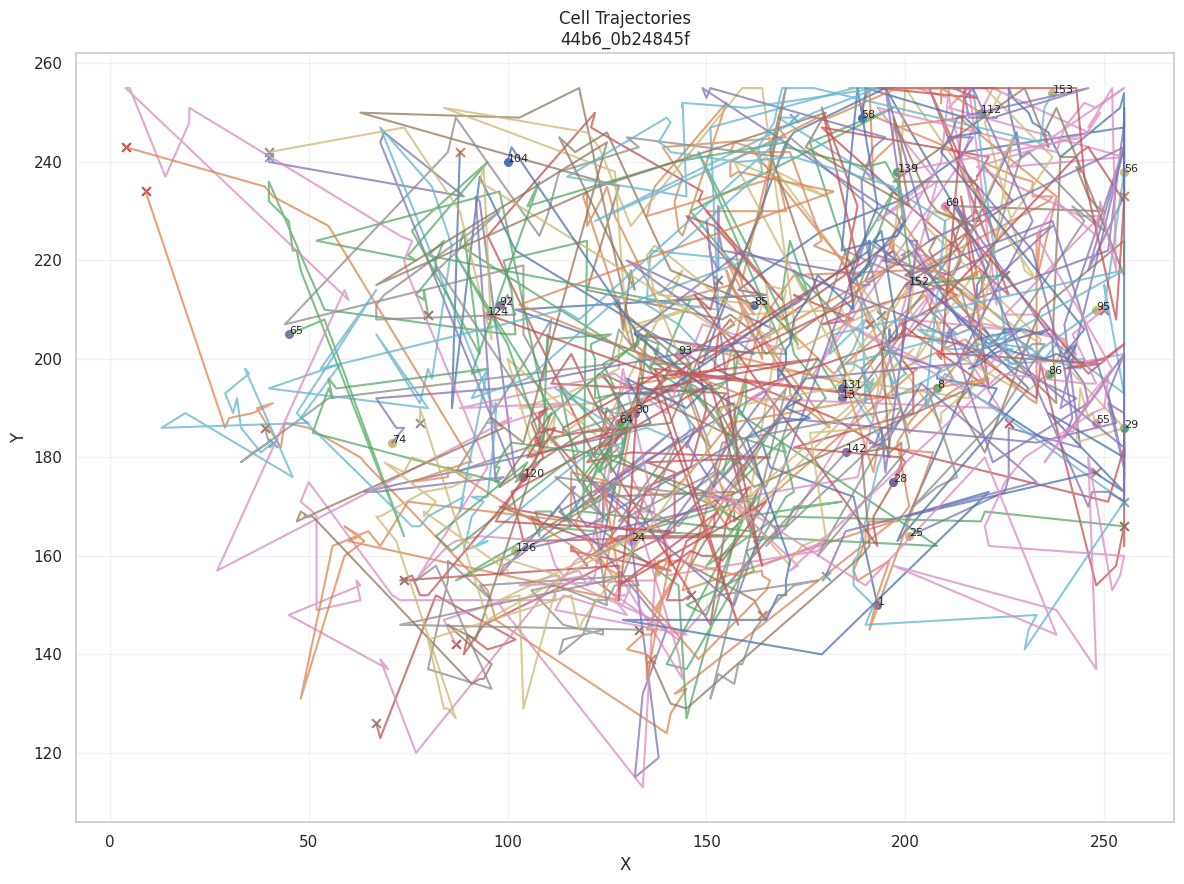

In [121]:
plot_track_trajectories(
    df_tracked,
    dataset="44b6_0b24845f",
    max_tracks=30,
    min_track_length=10,
    plane="xy"
)

## 14.2 Track fragmentation check

In [122]:
def analyze_track_fragmentation(df_tracked):

    results = []

    for (dataset, track_id), track in df_tracked.groupby(
        ["dataset", "track_id"]
    ):

        track = (
            track
            .sort_values("t")
            .reset_index(drop=True)
        )

        times = track["t"].to_numpy()

        if len(times) <= 1:

            max_gap = 0
            total_gap = 0
            gap_count = 0

        else:

            gaps = np.diff(times)

            max_gap = gaps.max()
            total_gap = np.sum(
                gaps[gaps > 1] - 1
            )
            gap_count = np.sum(
                gaps > 1
            )

        results.append({
            "dataset": dataset,
            "track_id": track_id,
            "length": len(track),
            "start_t": times.min(),
            "end_t": times.max(),
            "max_gap": int(max_gap),
            "missing_frames": int(total_gap),
            "gap_count": int(gap_count),
        })

    fragmentation_df = pd.DataFrame(results)

    return fragmentation_df

In [123]:
fragmentation_df = analyze_track_fragmentation(
    df_tracked
)

display(
    fragmentation_df
    .sort_values(
        ["missing_frames", "max_gap"],
        ascending=False
    )
    .head(50)
)

,dataset,track_id,length,start_t,end_t,max_gap,missing_frames,gap_count
207,44b6_0b24845f,29,90,0,99,2,10,10
252,44b6_0b24845f,74,53,22,81,2,7,7
264,44b6_0b24845f,86,70,23,99,2,7,7
643,6bba_05db0fb1,165,64,23,93,2,7,7
186,44b6_0b24845f,8,93,0,98,2,6,6
208,44b6_0b24845f,30,42,0,47,2,6,6
242,44b6_0b24845f,64,77,17,99,2,6,6
489,6bba_05db0fb1,11,94,0,99,2,6,6
594,6bba_05db0fb1,116,86,8,99,2,6,6
77,44b6_0113de3b,77,95,0,99,2,5,5


## 14.3 Dataset-wise fragmentation summary

In [124]:
fragmentation_summary = (
    fragmentation_df
    .groupby("dataset")
    .agg(
        tracks=("track_id", "count"),

        tracks_with_gaps=(
            "gap_count",
            lambda x: (x > 0).sum()
        ),

        total_missing_frames=(
            "missing_frames",
            "sum"
        ),

        max_gap=(
            "max_gap",
            "max"
        ),

        mean_gap=(
            "missing_frames",
            "mean"
        )
    )
    .reset_index()
)

fragmentation_summary[
    "fragmented_track_%"
] = (
    fragmentation_summary["tracks_with_gaps"]
    / fragmentation_summary["tracks"]
    * 100
)

fragmentation_summary = (
    fragmentation_summary
    .round(2)
)

print("FRAGMENTATION SUMMARY")

display(fragmentation_summary)

FRAGMENTATION SUMMARY


,dataset,tracks,tracks_with_gaps,total_missing_frames,max_gap,mean_gap,fragmented_track_%
0,44b6_0113de3b,178,97,166,2,0.93,54.49
1,44b6_0b24845f,216,111,256,2,1.19,51.39
2,6bba_05b6850b,84,38,65,2,0.77,45.24
3,6bba_05db0fb1,292,146,268,2,0.92,50.00


### 14.3.1 Fragmentation vs Graph Structure

In [125]:
# FRAGMENTATION VS GRAPH STRUCTURE
def find_tracking_dataframe():
    """
    Automatically find a DataFrame containing tracking results.
    Required columns:
        track_id
        dataset / movie / sample_id
    """

    candidates = []

    for name, obj in globals().items():

        if not isinstance(obj, pd.DataFrame):
            continue

        cols = set(obj.columns)

        # Must contain track ID
        if "track_id" not in cols:
            continue

        # Must contain some movie/dataset identifier
        id_cols = [
            "dataset",
            "movie",
            "sample_id",
            "movie_id"
        ]

        found_id = [
            c for c in id_cols
            if c in cols
        ]

        if found_id:
            candidates.append(
                (name, obj, found_id[0])
            )

    if not candidates:
        raise NameError(
            "No tracking DataFrame found.\n"
            "A DataFrame with 'track_id' and "
            "'dataset/movie/sample_id' is required."
        )

    # Prefer the largest DataFrame
    candidates.sort(
        key=lambda x: len(x[1]),
        reverse=True
    )

    name, df, dataset_col = candidates[0]

    print("Tracking DataFrame detected:")
    print(f"Variable : {name}")
    print(f"Shape    : {df.shape}")
    print(f"ID column: {dataset_col}")
    print(f"Columns  : {list(df.columns)}")

    return df, dataset_col


# Fragmentation calculation
def fragmentation_summary(
    df,
    dataset_col,
    min_track_length=2
):

    rows = []

    for dataset, movie in df.groupby(
        dataset_col
    ):

        lengths = (
            movie
            .groupby("track_id")
            .size()
        )

        n_tracks = len(lengths)

        short_tracks = (
            lengths < min_track_length
        ).sum()

        rows.append({

            "dataset": dataset,

            "n_tracks": n_tracks,

            "mean_track_length":
                lengths.mean(),

            "median_track_length":
                lengths.median(),

            "short_tracks":
                short_tracks,

            "fragmentation_rate":
                (
                    short_tracks / n_tracks
                    if n_tracks > 0
                    else np.nan
                )
        })

    return pd.DataFrame(rows)


tracking_df, dataset_column = (
    find_tracking_dataframe()
)

fragmentation_summary_df = (
    fragmentation_summary(
        tracking_df,
        dataset_column
    )
)

display(
    fragmentation_summary_df.head(20)
)

Tracking DataFrame detected:
Variable : df_tracked_val
Shape    : (29355, 8)
ID column: dataset
Columns  : ['node_id', 't', 'z', 'y', 'x', 'track_id', 'sample_id', 'dataset']


,dataset,n_tracks,mean_track_length,median_track_length,short_tracks,fragmentation_rate
0,44b6_40c45f5a,2,100.000000,100.0,0,0.0
1,44b6_415c0a3a,9,36.777778,9.0,0,0.0
2,44b6_66f9292d,2,100.000000,100.0,0,0.0
3,44b6_74d0c52e,2,70.000000,70.0,0,0.0
4,44b6_7a302da0,10,51.600000,45.5,0,0.0
5,44b6_87bba6c4,6,25.500000,22.5,0,0.0
6,44b6_90724892,2,52.500000,52.5,0,0.0
7,44b6_95029e92,2,100.000000,100.0,0,0.0
8,44b6_a21120c2,12,24.666667,25.0,0,0.0
9,44b6_b2c44266,2,85.000000,85.0,0,0.0


In [126]:
# Dataset-level comparison

comparison = (
    advanced_topology[
        [
            "sample_id",
            "largest_component_ratio",
            "fragmentation_ratio"
        ]
    ]
    .merge(
        fragmentation_summary_df,
        left_on="sample_id",
        right_on="dataset",
        how="inner"
    )
)

display(
    comparison.head()
)

,sample_id,largest_component_ratio,fragmentation_ratio,dataset,n_tracks,mean_track_length,median_track_length,short_tracks,fragmentation_rate
0,44b6_40c45f5a,0.500000,0.500000,44b6_40c45f5a,2,100.000000,100.0,0,0.0
1,44b6_415c0a3a,0.302115,0.697885,44b6_415c0a3a,9,36.777778,9.0,0,0.0
2,44b6_66f9292d,0.500000,0.500000,44b6_66f9292d,2,100.000000,100.0,0,0.0
3,44b6_74d0c52e,1.000000,0.000000,44b6_74d0c52e,2,70.000000,70.0,0,0.0
4,44b6_7a302da0,0.211240,0.788760,44b6_7a302da0,10,51.600000,45.5,0,0.0


## 14.4 Track-switch detection

In [127]:
def check_track_assignment_consistency(df_tracked):
    duplicates = (
        df_tracked
        .groupby(
            ["dataset", "t", "track_id"]
        )
        .size()
        .reset_index(name="count")
    )

    duplicates = duplicates[
        duplicates["count"] > 1
    ]

    print("=" * 70)
    print("TRACK ASSIGNMENT CONSISTENCY")
    print("=" * 70)

    print(
        "Duplicate track assignments:",
        len(duplicates)
    )

    if len(duplicates) == 0:

        print(
            "No track has multiple detections "
            "at the same timepoint."
        )

    else:

        print(
            "Potential assignment problem detected."
        )

        display(
            duplicates.head(50)
        )

    return duplicates

In [128]:
duplicate_assignments = (
    check_track_assignment_consistency(
        df_tracked
    )
)

TRACK ASSIGNMENT CONSISTENCY
Duplicate track assignments: 0
No track has multiple detections at the same timepoint.


## 14.5 SUDDEN MOVEMENT / POSSIBLE TRACK SWITCH CHECK

In [129]:
def detect_suspicious_jumps(
    df_tracked,
    jump_threshold=30.0
):

    df = df_tracked.copy()

    df = df.sort_values(
        ["dataset", "track_id", "t"]
    )

    # Previous position
    df["prev_x"] = (
        df.groupby(
            ["dataset", "track_id"]
        )["x"]
        .shift(1)
    )

    df["prev_y"] = (
        df.groupby(
            ["dataset", "track_id"]
        )["y"]
        .shift(1)
    )

    df["prev_z"] = (
        df.groupby(
            ["dataset", "track_id"]
        )["z"]
        .shift(1)
    )

    # 3D displacement
    df["step_distance"] = np.sqrt(
        (df["x"] - df["prev_x"]) ** 2
        +
        (df["y"] - df["prev_y"]) ** 2
        +
        (df["z"] - df["prev_z"]) ** 2
    )

    suspicious = df[
        df["step_distance"] > jump_threshold
    ].copy()

    suspicious = suspicious.sort_values(
        "step_distance",
        ascending=False
    )

    return suspicious

In [130]:
suspicious_jumps = detect_suspicious_jumps(
    df_tracked,
    jump_threshold=30.0
)

print(
    "Suspicious jumps:",
    len(suspicious_jumps)
)

display(
    suspicious_jumps[
        [
            "dataset",
            "track_id",
            "t",
            "x",
            "y",
            "z",
            "step_distance"
        ]
    ].head(50)
)

Suspicious jumps: 2634


,dataset,track_id,t,x,y,z,step_distance
2421,6bba_05db0fb1,49,21,173,66,2,94.630862
11344,44b6_0b24845f,62,35,216,216,42,90.609050
13335,44b6_0b24845f,159,79,246,167,39,87.567117
17036,6bba_05b6850b,18,82,32,7,60,82.322536
11957,44b6_0b24845f,112,50,103,211,63,82.280010
17407,6bba_05b6850b,71,94,164,201,0,81.565924
11928,44b6_0b24845f,86,49,27,157,62,80.237149
2163,6bba_05db0fb1,49,19,215,140,4,80.156098
5606,6bba_05db0fb1,66,44,147,159,20,79.233831
1916,6bba_05db0fb1,123,17,198,87,17,79.101201


### 14.5.1 Advanced Suspicious Movement Analysis

In [131]:

def find_tracking_dataframe():
    """
    Automatically find an existing tracking DataFrame.

    Required:
        track_id
        t

    Coordinates can be either:
        x_um, y_um, z_um
    OR:
        x, y, z
    """

    candidates = []

    for name, obj in globals().items():

        if not isinstance(obj, pd.DataFrame):
            continue

        cols = set(obj.columns)

        # Must be a tracking dataframe
        if "track_id" not in cols or "t" not in cols:
            continue

        # Physical coordinates
        if {"x_um", "y_um", "z_um"}.issubset(cols):

            candidates.append(
                (name, obj, "physical")
            )

        # Voxel coordinates
        elif {"x", "y", "z"}.issubset(cols):

            candidates.append(
                (name, obj, "voxel")
            )

    if not candidates:

        raise NameError(
            "\nNo suitable tracking DataFrame found.\n\n"
            "Required columns:\n"
            "  track_id\n"
            "  t\n"
            "  x_um, y_um, z_um\n"
            "or\n"
            "  x, y, z\n"
        )

    # Prefer physical-coordinate dataframe
    physical = [
        x for x in candidates
        if x[2] == "physical"
    ]

    if physical:
        name, df, coord_type = max(
            physical,
            key=lambda x: len(x[1])
        )
    else:
        name, df, coord_type = max(
            candidates,
            key=lambda x: len(x[1])
        )

    print("=" * 60)
    print("TRACKING DATAFRAME DETECTED")
    print("=" * 60)
    print(f"Variable     : {name}")
    print(f"Shape        : {df.shape}")
    print(f"Coordinate   : {coord_type}")
    print(f"Columns      : {list(df.columns)}")
    print("=" * 60)

    return df.copy(), coord_type

# TRACK JUMP ANALYSIS FUNCTION
def analyze_track_jumps(
    df,
    coordinate_type="physical",
    distance_threshold_um=10.0
):
    """
    Detect unusually large movements inside individual tracks.

    Parameters
    ----------
    df : pandas.DataFrame
        Tracking dataframe.

    coordinate_type : str
        "physical" -> x_um, y_um, z_um
        "voxel"    -> x, y, z

    distance_threshold_um : float
        Distance above this value is marked suspicious.
    """

    required = [
        "track_id",
        "t"
    ]

    missing = [
        c for c in required
        if c not in df.columns
    ]

    if missing:
        raise ValueError(
            f"Missing required columns: {missing}"
        )

    df = df.copy()

    # Convert voxel coordinates to physical coordinates
    if coordinate_type == "voxel":

        required_xyz = ["x", "y", "z"]

        missing_xyz = [
            c for c in required_xyz
            if c not in df.columns
        ]

        if missing_xyz:
            raise ValueError(
                f"Missing voxel coordinates: {missing_xyz}"
            )

        # Your V5 physical scale
        df["x_um"] = (
            df["x"] * X_SCALE
        )

        df["y_um"] = (
            df["y"] * Y_SCALE
        )

        df["z_um"] = (
            df["z"] * Z_SCALE
        )

    else:

        required_xyz = [
            "x_um",
            "y_um",
            "z_um"
        ]

        missing_xyz = [
            c for c in required_xyz
            if c not in df.columns
        ]

        if missing_xyz:
            raise ValueError(
                f"Missing physical coordinates: {missing_xyz}"
            )

    # Calculate jumps
    rows = []

    for track_id, track in df.groupby(
        "track_id"
    ):

        track = track.sort_values("t").copy()

        if len(track) < 2:
            continue

        xyz = track[
            ["x_um", "y_um", "z_um"]
        ].to_numpy(dtype=float)

        times = track[
            "t"
        ].to_numpy()

        for i in range(1, len(track)):

            # Position difference
            distance = np.linalg.norm(
                xyz[i] - xyz[i - 1]
            )

            # Frame difference
            dt = (
                times[i]
                - times[i - 1]
            )

            if dt <= 0:
                continue

            speed = distance / dt

            suspicious = (
                distance >
                distance_threshold_um
            )

            rows.append({

                "track_id":
                    track_id,

                "t_previous":
                    times[i - 1],

                "t_current":
                    times[i],

                "delta_t":
                    dt,

                "jump_distance_um":
                    distance,

                "speed_um_per_frame":
                    speed,

                "suspicious_jump":
                    suspicious
            })

    return pd.DataFrame(rows)

# AUTOMATICALLY FIND TRACKING DATA
tracking_df, coordinate_type = (
    find_tracking_dataframe()
)

# RUN JUMP ANALYSIS
jump_report = analyze_track_jumps(
    tracking_df,
    coordinate_type=coordinate_type,
    distance_threshold_um=10.0
)

# SUSPICIOUS JUMPS
suspicious_jumps = (
    jump_report[
        jump_report["suspicious_jump"]
    ]
    .copy()
)

print()
print("ADVANCED TRACK JUMP ANALYSIS")

print(
    f"Total jumps      : {len(jump_report):,}"
)

print(
    f"Suspicious jumps : {len(suspicious_jumps):,}"
)

if len(jump_report) > 0:

    suspicious_rate = (
        len(suspicious_jumps)
        / len(jump_report)
        * 100
    )

    print(
        f"Suspicious rate  : {suspicious_rate:.2f}%"
    )

print(
    f"Threshold        : 10.0 µm"
)


display(
    suspicious_jumps.head(20)
)

TRACKING DATAFRAME DETECTED
Variable     : df_tracked
Shape        : (29159, 10)
Coordinate   : physical
Columns      : ['dataset', 'node_id', 't', 'z', 'y', 'x', 'z_um', 'y_um', 'x_um', 'track_id']

ADVANCED TRACK JUMP ANALYSIS
Total jumps      : 16,533
Suspicious jumps : 5,856
Suspicious rate  : 35.42%
Threshold        : 10.0 µm


,track_id,t_previous,t_current,delta_t,jump_distance_um,speed_um_per_frame,suspicious_jump
0,0,0,1,1,46.930228,46.930228,True
1,0,1,2,1,42.269527,42.269527,True
3,0,3,4,1,40.447895,40.447895,True
5,0,5,6,1,44.807368,44.807368,True
7,0,7,8,1,11.051195,11.051195,True
9,0,9,10,1,29.656250,29.656250,True
18,0,18,19,1,15.373221,15.373221,True
19,0,19,20,1,22.102390,22.102390,True
21,0,21,22,1,40.547739,40.547739,True
22,0,22,23,1,40.600618,40.600618,True


## 14.6 problematic dataset suspicious tracks

In [132]:
problem_dataset = "44b6_0b24845f"

problem_tracks = (
    fragmentation_df[
        fragmentation_df["dataset"]
        == problem_dataset
    ]
    .sort_values(
        ["missing_frames", "length"],
        ascending=[False, True]
    )
)

display(problem_tracks.head(30))

,dataset,track_id,length,start_t,end_t,max_gap,missing_frames,gap_count
207,44b6_0b24845f,29,90,0,99,2,10,10
252,44b6_0b24845f,74,53,22,81,2,7,7
264,44b6_0b24845f,86,70,23,99,2,7,7
208,44b6_0b24845f,30,42,0,47,2,6,6
242,44b6_0b24845f,64,77,17,99,2,6,6
186,44b6_0b24845f,8,93,0,98,2,6,6
292,44b6_0b24845f,114,32,38,74,2,5,5
276,44b6_0b24845f,98,33,32,69,2,5,5
247,44b6_0b24845f,69,78,17,99,2,5,5
233,44b6_0b24845f,55,85,10,99,2,5,5


In [133]:
# Get dataset/movie information from the original tracking data
dataset_col = None

for col in ["dataset", "sample_id", "movie", "movie_id"]:
    if col in tracking_df.columns:
        dataset_col = col
        break

if dataset_col is None:
    raise ValueError(
        "No dataset/movie identifier found in tracking_df."
    )

# Create a mapping: track_id -> dataset
track_dataset_map = (
    tracking_df[
        ["track_id", dataset_col]
    ]
    .drop_duplicates("track_id")
    .set_index("track_id")[dataset_col]
)

# Add dataset information to suspicious jumps
suspicious_jumps = suspicious_jumps.copy()

suspicious_jumps["dataset"] = (
    suspicious_jumps["track_id"]
    .map(track_dataset_map)
)


problem_jumps = suspicious_jumps[
    suspicious_jumps["dataset"] == problem_dataset
].copy()

display(
    problem_jumps.head(30)
)

,track_id,t_previous,t_current,delta_t,jump_distance_um,speed_um_per_frame,suspicious_jump,dataset


## 14.7 Full diagnostic

In [134]:
print("RUNNING COMPLETE TRACKING DIAGNOSTIC")

# 1. Fragmentation
fragmentation_df = analyze_track_fragmentation(
    df_tracked
)

# 2. Summary
fragmentation_summary = (
    fragmentation_df
    .groupby("dataset")
    .agg(
        tracks=("track_id", "count"),

        fragmented_tracks=(
            "gap_count",
            lambda x: (x > 0).sum()
        ),

        total_missing_frames=(
            "missing_frames",
            "sum"
        ),

        max_gap=("max_gap", "max"),

        mean_missing_frames=(
            "missing_frames",
            "mean"
        )
    )
    .reset_index()
)

fragmentation_summary["fragmented_%"] = (
    fragmentation_summary["fragmented_tracks"]
    / fragmentation_summary["tracks"]
    * 100
)

# 3. Duplicate assignments
duplicate_assignments = (
    check_track_assignment_consistency(
        df_tracked
    )
)

# 4. Sudden jumps
suspicious_jumps = detect_suspicious_jumps(
    df_tracked,
    jump_threshold=30.0
)

# 5. Final report
print("FRAGMENTATION REPORT")

display(
    fragmentation_summary.round(2)
)

print("SUSPICIOUS JUMPS")

print(
    "Total suspicious jumps:",
    len(suspicious_jumps)
)

display(
    suspicious_jumps[
        [
            "dataset",
            "track_id",
            "t",
            "step_distance"
        ]
    ].head(30)
)

print("DIAGNOSTIC COMPLETE")

RUNNING COMPLETE TRACKING DIAGNOSTIC
TRACK ASSIGNMENT CONSISTENCY
Duplicate track assignments: 0
No track has multiple detections at the same timepoint.
FRAGMENTATION REPORT


,dataset,tracks,fragmented_tracks,total_missing_frames,max_gap,mean_missing_frames,fragmented_%
0,44b6_0113de3b,178,97,166,2,0.93,54.49
1,44b6_0b24845f,216,111,256,2,1.19,51.39
2,6bba_05b6850b,84,38,65,2,0.77,45.24
3,6bba_05db0fb1,292,146,268,2,0.92,50.00


SUSPICIOUS JUMPS
Total suspicious jumps: 2634


,dataset,track_id,t,step_distance
2421,6bba_05db0fb1,49,21,94.630862
11344,44b6_0b24845f,62,35,90.609050
13335,44b6_0b24845f,159,79,87.567117
17036,6bba_05b6850b,18,82,82.322536
11957,44b6_0b24845f,112,50,82.280010
17407,6bba_05b6850b,71,94,81.565924
11928,44b6_0b24845f,86,49,80.237149
2163,6bba_05db0fb1,49,19,80.156098
5606,6bba_05db0fb1,66,44,79.233831
1916,6bba_05db0fb1,123,17,79.101201


DIAGNOSTIC COMPLETE


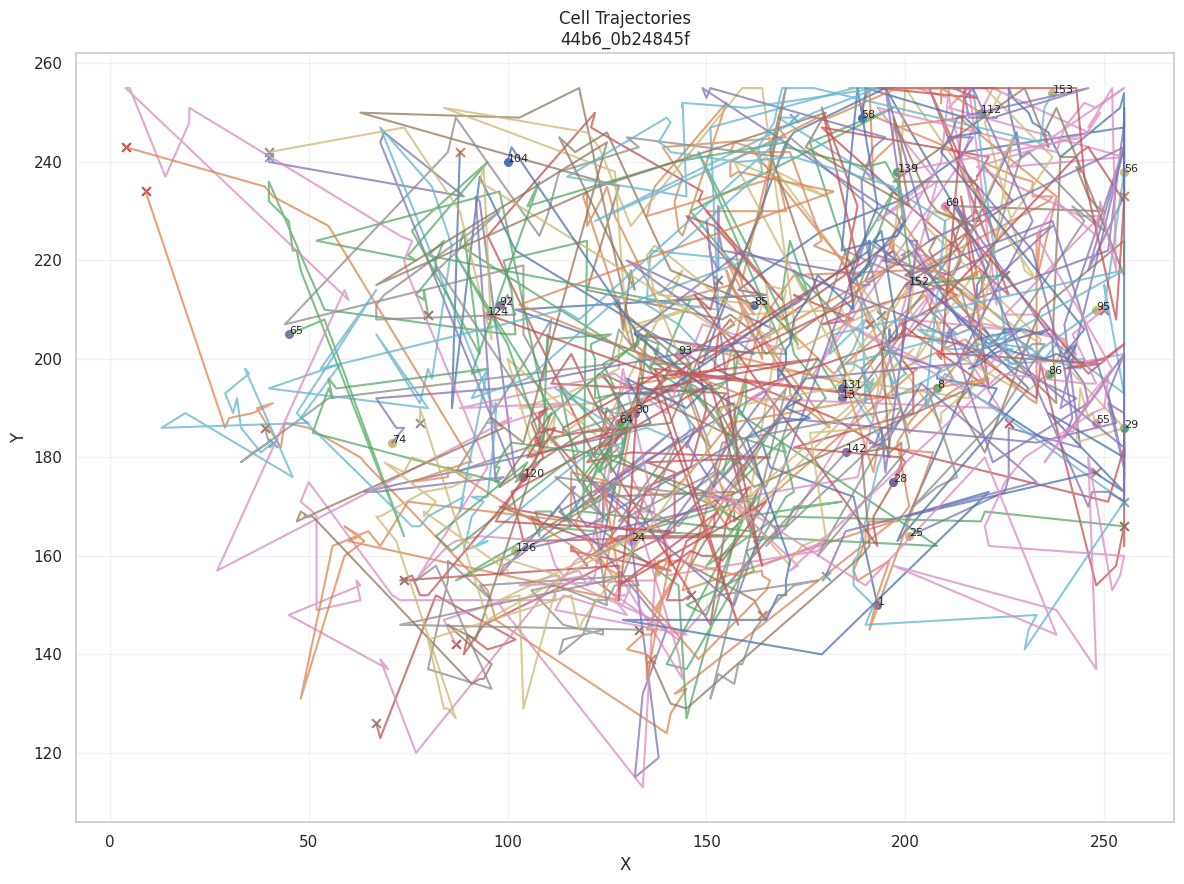

In [135]:
plot_track_trajectories(
    df_tracked,
    dataset="44b6_0b24845f",
    max_tracks=30,
    min_track_length=10
)

In [136]:
fragmentation_df = analyze_track_fragmentation(df_tracked)
display(fragmentation_df.sort_values(
    "missing_frames",
    ascending=False
).head(30))

,dataset,track_id,length,start_t,end_t,max_gap,missing_frames,gap_count
207,44b6_0b24845f,29,90,0,99,2,10,10
264,44b6_0b24845f,86,70,23,99,2,7,7
252,44b6_0b24845f,74,53,22,81,2,7,7
643,6bba_05db0fb1,165,64,23,93,2,7,7
489,6bba_05db0fb1,11,94,0,99,2,6,6
208,44b6_0b24845f,30,42,0,47,2,6,6
594,6bba_05db0fb1,116,86,8,99,2,6,6
186,44b6_0b24845f,8,93,0,98,2,6,6
242,44b6_0b24845f,64,77,17,99,2,6,6
94,44b6_0113de3b,94,95,0,99,2,5,5


In [137]:
suspicious_jumps = detect_suspicious_jumps(
    df_tracked,
    jump_threshold=30.0
)

display(suspicious_jumps.head(30))

,dataset,node_id,t,z,y,x,z_um,y_um,x_um,track_id,prev_x,prev_y,prev_z,step_distance
2421,6bba_05db0fb1,2422,21,2,66,173,3.250,26.81250,70.28125,49,228.0,143.0,3.0,94.630862
11344,44b6_0b24845f,1210,35,42,216,216,68.250,87.75000,87.75000,62,128.0,237.0,37.0,90.609050
13335,44b6_0b24845f,3201,79,39,167,246,63.375,67.84375,99.93750,159,160.0,151.0,43.0,87.567117
17036,6bba_05b6850b,2913,82,60,7,32,97.500,2.84375,13.00000,18,60.0,84.0,52.0,82.322536
11957,44b6_0b24845f,1823,50,63,211,103,102.375,85.71875,41.84375,112,182.0,234.0,63.0,82.280010
17407,6bba_05b6850b,3284,94,0,201,164,0.000,81.65625,66.62500,71,102.0,148.0,0.0,81.565924
11928,44b6_0b24845f,1794,49,62,157,27,100.750,63.78125,10.96875,86,101.0,188.0,63.0,80.237149
2163,6bba_05db0fb1,2164,19,4,140,215,6.500,56.87500,87.34375,49,255.0,209.0,12.0,80.156098
5606,6bba_05db0fb1,5607,44,20,159,147,32.500,64.59375,59.71875,66,202.0,216.0,22.0,79.233831
1916,6bba_05db0fb1,1917,17,17,87,198,27.625,35.34375,80.43750,123,211.0,165.0,15.0,79.101201


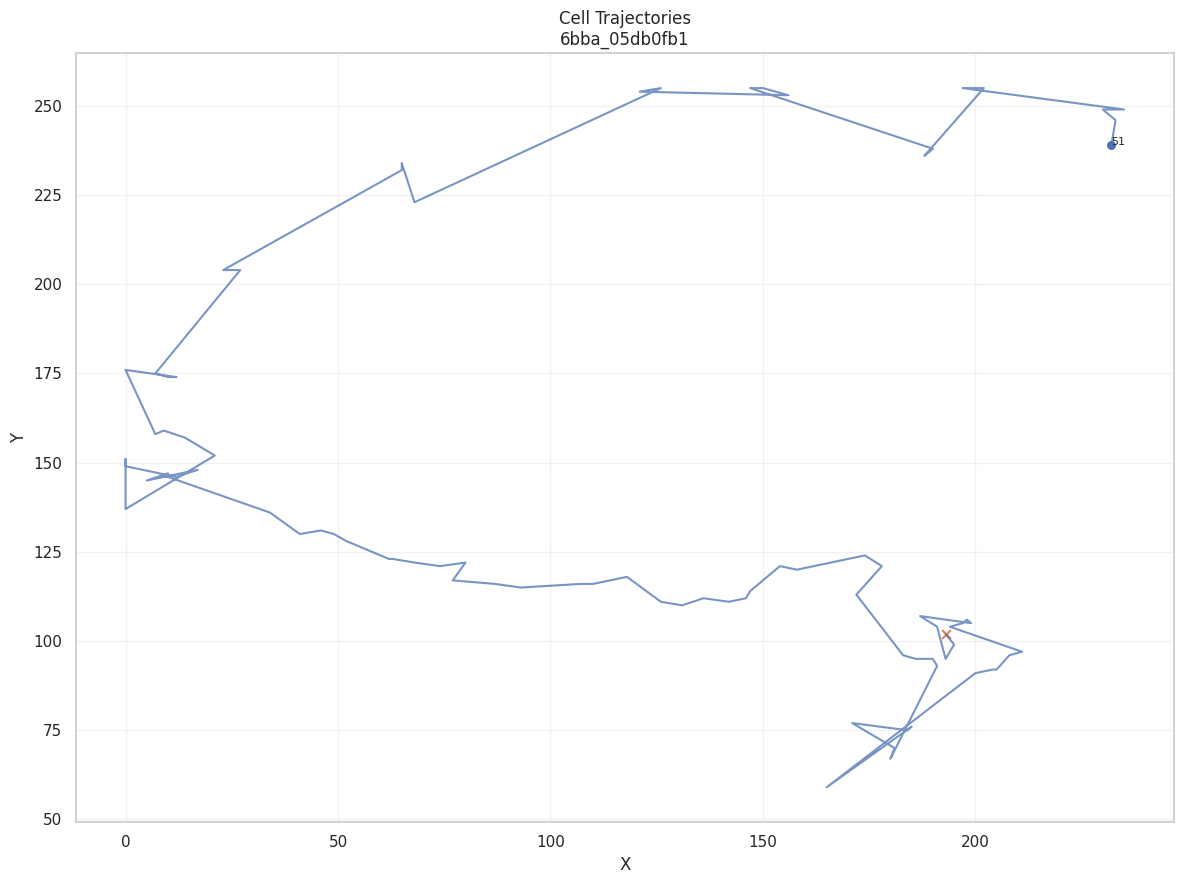

In [138]:
plot_track_trajectories(
    df_tracked,
    dataset="6bba_05db0fb1",
    max_tracks=1,
    min_track_length=1,
    plane="xy"
)

### PLOT ONE SPECIFIC TRACK

In [139]:
def plot_single_track(
    df_tracked,
    dataset,
    track_id,
    plane="xy"
):

    track = df_tracked[
        (df_tracked["dataset"] == dataset) &
        (df_tracked["track_id"] == track_id)
    ].copy()

    if track.empty:
        print(
            f"No track found: "
            f"{dataset} / {track_id}"
        )
        return

    track = track.sort_values("t")

    if plane == "xy":
        x = track["x_um"]
        y = track["y_um"]
        xlabel = "X (µm)"
        ylabel = "Y (µm)"

    elif plane == "xz":
        x = track["x_um"]
        y = track["z_um"]
        xlabel = "X (µm)"
        ylabel = "Z (µm)"

    elif plane == "yz":
        x = track["y_um"]
        y = track["z_um"]
        xlabel = "Y (µm)"
        ylabel = "Z (µm)"

    else:
        raise ValueError(
            "plane must be 'xy', 'xz', or 'yz'"
        )

    plt.figure(figsize=(10, 8))

    plt.plot(
        x,
        y,
        marker="o",
        markersize=3,
        linewidth=1.5
    )

    # Start
    plt.scatter(
        x.iloc[0],
        y.iloc[0],
        s=100,
        marker="o",
        label=f"Start t={track['t'].iloc[0]}"
    )

    # End
    plt.scatter(
        x.iloc[-1],
        y.iloc[-1],
        s=120,
        marker="x",
        label=f"End t={track['t'].iloc[-1]}"
    )

    # Label every point with time
    for _, row in track.iterrows():

        if plane == "xy":
            px = row["x_um"]
            py = row["y_um"]

        elif plane == "xz":
            px = row["x_um"]
            py = row["z_um"]

        else:
            px = row["y_um"]
            py = row["z_um"]

        plt.text(
            px,
            py,
            str(int(row["t"])),
            fontsize=7
        )

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)

    plt.title(
        f"Trajectory\n"
        f"Dataset: {dataset}\n"
        f"Track ID: {track_id}"
    )

    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()

    return track

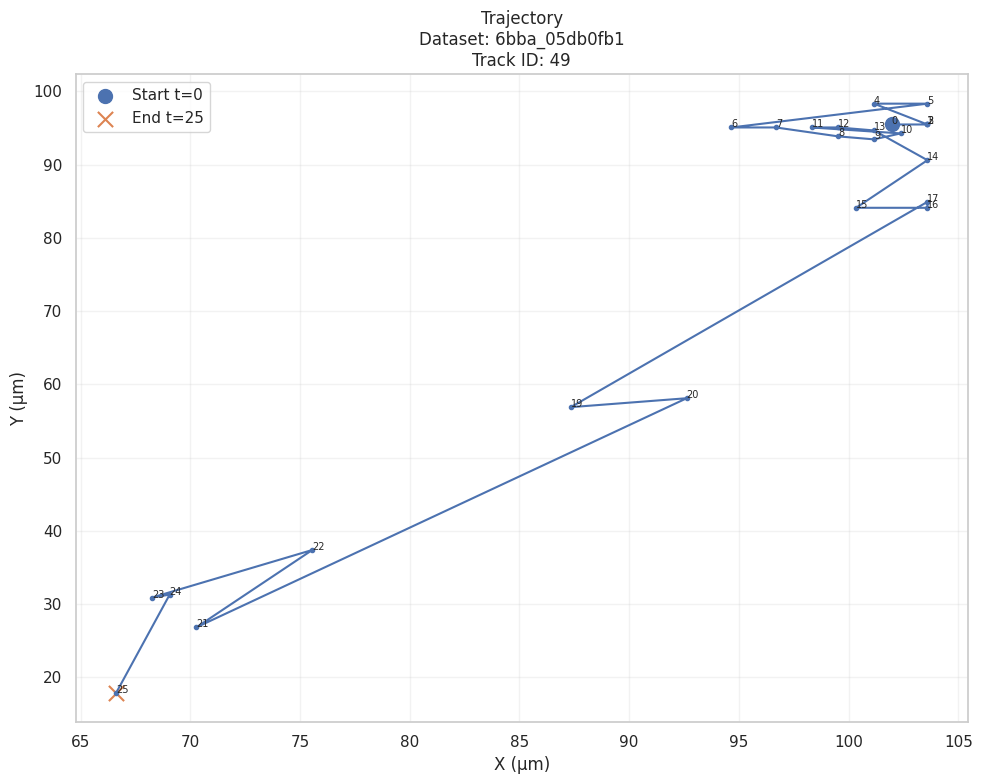

In [140]:
track_49 = plot_single_track(
    df_tracked,
    dataset="6bba_05db0fb1",
    track_id=49,
    plane="xy"
)

In [141]:
dataset_name = "6bba_05db0fb1"
track_id = 49

track = df_tracked[
    (df_tracked["dataset"] == dataset_name) &
    (df_tracked["track_id"] == track_id)
].copy()

track = track.sort_values("t")

track["dx"] = track["x_um"].diff()
track["dy"] = track["y_um"].diff()
track["dz"] = track["z_um"].diff()

track["distance_um"] = np.sqrt(
    track["dx"]**2 +
    track["dy"]**2 +
    track["dz"]**2
)

display(
    track[
        [
            "node_id",
            "t",
            "z_um",
            "y_um",
            "x_um",
            "distance_um"
        ]
    ]
)

,node_id,t,z_um,y_um,x_um,distance_um
49,50,0,53.625,95.46875,101.96875,NaN
156,157,1,53.625,95.46875,103.59375,1.625000
260,261,2,50.375,95.46875,103.59375,3.250000
371,372,3,50.375,95.46875,103.59375,0.000000
470,471,4,48.750,98.31250,101.15625,4.082762
568,569,5,48.750,98.31250,103.59375,2.437500
637,638,6,37.375,95.06250,94.65625,14.826734
739,740,7,37.375,95.06250,96.68750,2.031250
843,844,8,35.750,93.84375,99.53125,3.494695
968,969,9,34.125,93.43750,101.15625,2.333729


In [142]:
top_jumps = (
    suspicious_jumps[
        [
            "dataset",
            "track_id",
            "t",
            "step_distance"
        ]
    ]
    .sort_values(
        "step_distance",
        ascending=False
    )
    .head(20)
)

display(top_jumps)

,dataset,track_id,t,step_distance
2421,6bba_05db0fb1,49,21,94.630862
11344,44b6_0b24845f,62,35,90.609050
13335,44b6_0b24845f,159,79,87.567117
17036,6bba_05b6850b,18,82,82.322536
11957,44b6_0b24845f,112,50,82.280010
17407,6bba_05b6850b,71,94,81.565924
11928,44b6_0b24845f,86,49,80.237149
2163,6bba_05db0fb1,49,19,80.156098
5606,6bba_05db0fb1,66,44,79.233831
1916,6bba_05db0fb1,123,17,79.101201


### AUTOMATIC TRACK-SWITCH CHECK

In [143]:
import numpy as np
import pandas as pd


def investigate_track_switches(
    df_tracked,
    suspicious_jumps,
    top_n=20,
    alternative_radius_um=100.0
):
    """
    For each suspicious movement, compare the assigned
    detection with all detections in the previous frame.

    This helps determine whether another cell was actually
    closer than the selected detection.
    """

    results = []

    # Process largest jumps first

    jumps = (
        suspicious_jumps
        .sort_values(
            "step_distance",
            ascending=False
        )
        .head(top_n)
    )

    for _, jump in jumps.iterrows():

        dataset = jump["dataset"]
        track_id = jump["track_id"]
        current_t = int(jump["t"])

        # Current detection
        current = df_tracked[
            (df_tracked["dataset"] == dataset) &
            (df_tracked["track_id"] == track_id) &
            (df_tracked["t"] == current_t)
        ]

        if current.empty:
            continue

        current = current.iloc[0]

        # Previous frame

        previous_t = current_t - 1

        previous = df_tracked[
            (df_tracked["dataset"] == dataset) &
            (df_tracked["t"] == previous_t)
        ].copy()

        if previous.empty:
            continue

        # Distance from previous detections
        # to CURRENT detection
        previous["distance_to_current"] = np.sqrt(
            (previous["x_um"] - current["x_um"]) ** 2
            +
            (previous["y_um"] - current["y_um"]) ** 2
            +
            (previous["z_um"] - current["z_um"]) ** 2
        )

        previous = previous.sort_values(
            "distance_to_current"
        )

        # Assigned previous detection

        assigned_previous = previous[
            previous["track_id"] == track_id
        ]

        if assigned_previous.empty:

            assigned_distance = np.nan

        else:

            assigned_distance = (
                assigned_previous[
                    "distance_to_current"
                ].iloc[0]
            )

        # Closest alternative
        alternatives = previous[
            previous["track_id"] != track_id
        ].copy()

        if alternatives.empty:
            continue

        closest_alt = alternatives.iloc[0]

        alternative_distance = (
            closest_alt["distance_to_current"]
        )

        # Determine status
        if (
            alternative_distance
            < assigned_distance
        ):

            status = "HIGHLY SUSPICIOUS"

        elif (
            assigned_distance > 30
            and alternative_distance
            < assigned_distance * 0.8
        ):

            status = "POSSIBLE SWITCH"

        elif assigned_distance > 30:

            status = "LARGE MOVEMENT"

        else:

            status = "LIKELY OK"

        results.append({

            "dataset": dataset,

            "track_id": track_id,

            "t": current_t,

            "assigned_distance_um":
                round(float(assigned_distance), 2),

            "nearest_alternative_distance_um":
                round(float(alternative_distance), 2),

            "distance_difference_um":
                round(
                    float(
                        assigned_distance
                        - alternative_distance
                    ),
                    2
                ),

            "alternative_track_id":
                closest_alt["track_id"],

            "status": status
        })

    return pd.DataFrame(results)

In [144]:
switch_report = investigate_track_switches(
    df_tracked,
    suspicious_jumps,
    top_n=20
)

display(switch_report)

,dataset,track_id,t,assigned_distance_um,nearest_alternative_distance_um,distance_difference_um,alternative_track_id,status
0,6bba_05db0fb1,49,21,38.48,15.42,23.06,156,HIGHLY SUSPICIOUS
1,44b6_0b24845f,62,35,NaN,15.03,NaN,42,LIKELY OK
2,44b6_0b24845f,159,79,NaN,3.17,NaN,126,LIKELY OK
3,6bba_05b6850b,18,82,35.73,1.68,34.06,15,HIGHLY SUSPICIOUS
4,44b6_0b24845f,112,50,NaN,20.32,NaN,55,LIKELY OK
5,6bba_05b6850b,71,94,33.14,8.18,24.96,60,HIGHLY SUSPICIOUS
6,44b6_0b24845f,86,49,NaN,25.85,NaN,98,LIKELY OK
7,6bba_05db0fb1,49,19,NaN,8.84,NaN,152,LIKELY OK
8,6bba_05db0fb1,66,44,NaN,10.57,NaN,113,LIKELY OK
9,6bba_05db0fb1,123,17,32.29,19.42,12.87,157,HIGHLY SUSPICIOUS


### ROBUST TRACK-SWITCH DETECTOR

In [145]:
def robust_track_switch_detector(
    df_tracked,
    suspicious_jumps,
    max_distance_um=30.0,
    top_n=50
):
    results = []

    jumps = (
        suspicious_jumps
        .sort_values(
            "step_distance",
            ascending=False
        )
        .head(top_n)
    )

    for _, jump in jumps.iterrows():

        dataset = jump["dataset"]
        track_id = jump["track_id"]
        current_t = int(jump["t"])

        # Current detection
        current = df_tracked[
            (df_tracked["dataset"] == dataset) &
            (df_tracked["track_id"] == track_id) &
            (df_tracked["t"] == current_t)
        ].copy()

        if current.empty:
            continue

        current = current.iloc[0]

        # Same track history
        history = df_tracked[
            (df_tracked["dataset"] == dataset) &
            (df_tracked["track_id"] == track_id) &
            (df_tracked["t"] < current_t)
        ].sort_values("t")

        if history.empty:
            continue

        previous = history.iloc[-1]

        prev_t = int(previous["t"])
        delta_t = current_t - prev_t

        # Actual assigned movement
        assigned_distance = np.sqrt(
            (current["x_um"] - previous["x_um"]) ** 2 +
            (current["y_um"] - previous["y_um"]) ** 2 +
            (current["z_um"] - previous["z_um"]) ** 2
        )

        # All detections in previous frame
        candidates = df_tracked[
            (df_tracked["dataset"] == dataset) &
            (df_tracked["t"] == prev_t)
        ].copy()

        if candidates.empty:
            continue

        # Candidate distances
        candidates["candidate_distance_um"] = np.sqrt(
            (candidates["x_um"] - current["x_um"]) ** 2 +
            (candidates["y_um"] - current["y_um"]) ** 2 +
            (candidates["z_um"] - current["z_um"]) ** 2
        )

        # remove assigned previous detection
        candidates = candidates[
            candidates["node_id"] != previous["node_id"]
        ]

        if candidates.empty:
            continue

        candidates = candidates.sort_values(
            "candidate_distance_um"
        )

        nearest = candidates.iloc[0]

        alternative_distance = (
            nearest["candidate_distance_um"]
        )

        alternative_track = nearest["track_id"]

        # Ratio
        if alternative_distance > 0:

            distance_ratio = (
                assigned_distance /
                alternative_distance
            )

        else:

            distance_ratio = np.inf

        # Classification
        if (
            assigned_distance > max_distance_um
            and alternative_distance < assigned_distance
        ):

            status = "HIGHLY SUSPICIOUS"

        elif (
            assigned_distance > max_distance_um
        ):

            status = "LARGE MOVEMENT"

        else:

            status = "LIKELY OK"

        results.append({

            "dataset": dataset,

            "track_id": track_id,

            "t": current_t,

            "prev_t": prev_t,

            "delta_t": delta_t,

            "assigned_distance_um":
                round(float(assigned_distance), 3),

            "nearest_alternative_distance_um":
                round(float(alternative_distance), 3),

            "distance_ratio":
                round(float(distance_ratio), 2),

            "alternative_track_id":
                alternative_track,

            "status": status
        })

    return pd.DataFrame(results)

In [146]:
switch_report = robust_track_switch_detector(
    df_tracked,
    suspicious_jumps,
    max_distance_um=30.0,
    top_n=50
)

display(switch_report)

,dataset,track_id,t,prev_t,delta_t,assigned_distance_um,nearest_alternative_distance_um,distance_ratio,alternative_track_id,status
0,6bba_05db0fb1,49,21,20,1,38.476,15.416,2.50,156,HIGHLY SUSPICIOUS
1,44b6_0b24845f,62,35,33,2,37.641,2.031,18.53,42,HIGHLY SUSPICIOUS
2,44b6_0b24845f,159,79,77,2,36.127,5.817,6.21,126,HIGHLY SUSPICIOUS
3,6bba_05b6850b,18,82,81,1,35.734,1.675,21.33,15,HIGHLY SUSPICIOUS
4,44b6_0b24845f,112,50,48,2,33.426,11.236,2.97,116,HIGHLY SUSPICIOUS
5,6bba_05b6850b,71,94,93,1,33.136,8.176,4.05,60,HIGHLY SUSPICIOUS
6,44b6_0b24845f,86,49,47,2,32.634,31.908,1.02,30,HIGHLY SUSPICIOUS
7,6bba_05db0fb1,49,19,17,2,34.912,8.873,3.93,152,HIGHLY SUSPICIOUS
8,6bba_05db0fb1,66,44,42,2,32.342,10.349,3.13,64,HIGHLY SUSPICIOUS
9,6bba_05db0fb1,123,17,16,1,32.289,19.419,1.66,157,HIGHLY SUSPICIOUS


In [147]:
print("TRACK SWITCH SUMMARY")

print(
    switch_report["status"]
    .value_counts()
)

print()

print(
    "Highly suspicious:",
    (switch_report["status"] == "HIGHLY SUSPICIOUS").sum()
)

print(
    "Large movement:",
    (switch_report["status"] == "LARGE MOVEMENT").sum()
)

print(
    "Likely OK:",
    (switch_report["status"] == "LIKELY OK").sum()
)

TRACK SWITCH SUMMARY
status
HIGHLY SUSPICIOUS    42
LIKELY OK             8
Name: count, dtype: int64

Highly suspicious: 42
Large movement: 0
Likely OK: 8


In [148]:
dataset_summary = (
    switch_report
    .groupby("dataset")
    .agg(
        suspicious=("status",
                    lambda x:
                    (x == "HIGHLY SUSPICIOUS").sum()),

        large_movement=("status",
                        lambda x:
                        (x == "LARGE MOVEMENT").sum()),

        likely_ok=("status",
                   lambda x:
                   (x == "LIKELY OK").sum()),

        max_jump=("assigned_distance_um", "max"),

        mean_jump=("assigned_distance_um", "mean")
    )
)

display(dataset_summary)

,suspicious,large_movement,likely_ok,max_jump,mean_jump
dataset,,,,,
44b6_0113de3b,3,0,1,31.846,30.517000
44b6_0b24845f,19,0,3,39.846,32.623409
6bba_05b6850b,8,0,3,35.734,31.470545
6bba_05db0fb1,12,0,1,38.476,31.847385


# 15. Safe Tracking Configuration

In [149]:
from dataclasses import dataclass
import numpy as np
import pandas as pd


@dataclass
class TrackingConfig:

    # Base physical movement limit
    max_distance_um: float = 30.0

    # Maximum allowed missing frames
    max_age: int = 1

    # Candidate search radius
    candidate_radius_um: float = 30.0

    # Do not allow a very weak association
    min_link_score: float = 0.35

    # Alternative candidate must not be much better
    ambiguity_ratio: float = 0.80

    # Maximum frame gap for normal linking
    max_frame_gap: int = 2

    # Motion penalty
    motion_weight: float = 0.20

    # Distance weight
    distance_weight: float = 0.55

    # Model probability weight
    model_weight: float = 0.25

    # Prevent one target from receiving multiple tracks
    unique_target_assignment: bool = True

## 15.1 PHYSICAL DISTANCE

In [150]:
def physical_distance(a, b):

    return float(np.sqrt(
        (a["x_um"] - b["x_um"]) ** 2 +
        (a["y_um"] - b["y_um"]) ** 2 +
        (a["z_um"] - b["z_um"]) ** 2
    ))

## 15.2 FRAME-GAP AWARE DISTANCE GATE

In [151]:
def allowed_distance_um(delta_t, cfg):

    delta_t = max(1, int(delta_t))

    return (
        cfg.max_distance_um *
        np.sqrt(delta_t)
    )

## 15.3 MOTION PREDICTION

In [152]:
def predict_position(history, current_t):

    if len(history) == 0:
        return None

    last = history.iloc[-1]

    # Only one previous point
    if len(history) < 2:

        return {
            "x_um": float(last["x_um"]),
            "y_um": float(last["y_um"]),
            "z_um": float(last["z_um"])
        }

    prev = history.iloc[-2]

    dt = float(last["t"] - prev["t"])

    if dt <= 0:
        dt = 1.0

    velocity = {
        "x_um": (
            float(last["x_um"]) -
            float(prev["x_um"])
        ) / dt,

        "y_um": (
            float(last["y_um"]) -
            float(prev["y_um"])
        ) / dt,

        "z_um": (
            float(last["z_um"]) -
            float(prev["z_um"])
        ) / dt,
    }

    gap = float(current_t - last["t"])

    return {
        "x_um": (
            float(last["x_um"]) +
            velocity["x_um"] * gap
        ),

        "y_um": (
            float(last["y_um"]) +
            velocity["y_um"] * gap
        ),

        "z_um": (
            float(last["z_um"]) +
            velocity["z_um"] * gap
        )
    }

## 15.4 PREDICTION DISTANCE

In [153]:
def prediction_distance(candidate, prediction):

    if prediction is None:
        return np.inf

    return float(np.sqrt(
        (candidate["x_um"] - prediction["x_um"]) ** 2 +
        (candidate["y_um"] - prediction["y_um"]) ** 2 +
        (candidate["z_um"] - prediction["z_um"]) ** 2
    ))

## 15.5 SAFE CANDIDATE GENERATION

In [154]:
def generate_candidates(
    current_row,
    target_frame,
    nodes,
    cfg
):

    if target_frame.empty:
        return []

    delta_t = (
        int(current_row["t"]) -
        int(target_frame["t"].iloc[0])
    )

    if delta_t <= 0:
        return []

    if delta_t > cfg.max_frame_gap:
        return []

    max_dist = allowed_distance_um(
        delta_t,
        cfg
    )

    candidates = []

    for idx, candidate in target_frame.iterrows():

        dist = physical_distance(
            current_row,
            candidate
        )

        if dist <= max_dist:

            candidates.append({
                "index": idx,
                "distance": dist,
                "delta_t": delta_t
            })

    candidates.sort(
        key=lambda x: x["distance"]
    )

    return candidates

## 15.6 Safe hybrid tracker

In [155]:
required = [
    "dataset",
    "node_id",
    "t",
    "x_um",
    "y_um",
    "z_um"
]

In [156]:
cfg = FeatureConfig()

df_test_nodes = add_physical_coordinates(
    df_test_nodes,
    cfg
)

print("Physical coordinates added.")

print(
    df_test_nodes[
        ["x", "y", "z", "x_um", "y_um", "z_um"]
    ].head()
)

Physical coordinates added.
     x    y  z       x_um      y_um    z_um
0  137   96  0   55.65625  39.00000   0.000
1  181   19  4   73.53125   7.71875   6.500
2  234   20  5   95.06250   8.12500   8.125
3  249  136  5  101.15625  55.25000   8.125
4  237   75  9   96.28125  30.46875  14.625


In [157]:
def ensure_physical_coordinates(df, cfg):

    df = df.copy()

    required_raw = ["x", "y", "z"]

    missing = [
        c for c in required_raw
        if c not in df.columns
    ]

    if missing:
        raise ValueError(
            f"Missing raw coordinate columns: {missing}\n"
            f"Available columns:\n{df.columns.tolist()}"
        )

    df["x_um"] = (
        df["x"].astype(float) *
        float(cfg.x_scale)
    )

    df["y_um"] = (
        df["y"].astype(float) *
        float(cfg.y_scale)
    )

    df["z_um"] = (
        df["z"].astype(float) *
        float(cfg.z_scale)
    )

    return df


cfg = FeatureConfig()

df_test_nodes = ensure_physical_coordinates(
    df_test_nodes,
    cfg
)

print("Physical coordinates successfully created.")

display(
    df_test_nodes[
        [
            "dataset",
            "node_id",
            "t",
            "x",
            "y",
            "z",
            "x_um",
            "y_um",
            "z_um"
        ]
    ].head()
)

Physical coordinates successfully created.


,dataset,node_id,t,x,y,z,x_um,y_um,z_um
0,6bba_05db0fb1,1,0,137,96,0,55.65625,39.00000,0.000
1,6bba_05db0fb1,2,0,181,19,4,73.53125,7.71875,6.500
2,6bba_05db0fb1,3,0,234,20,5,95.06250,8.12500,8.125
3,6bba_05db0fb1,4,0,249,136,5,101.15625,55.25000,8.125
4,6bba_05db0fb1,5,0,237,75,9,96.28125,30.46875,14.625


In [158]:
tracking_cfg = TrackingConfig(
    max_distance_um=30.0,
    max_age=1,
    candidate_radius_um=30.0,
    max_frame_gap=1,

    distance_weight=0.60,
    motion_weight=0.40,
    model_weight=0.0,

    min_link_score=0.45
)

### safe_hybrid_tracker

In [159]:
def safe_hybrid_tracker(
    df_nodes,
    model=None,
    cfg=TrackingConfig()
):
    """
    Conservative hybrid tracker.

    Main goals:
    1. Prevent very large jumps
    2. Prevent track switching
    3. Use motion prediction
    4. Enforce unique track <-> detection assignment
    5. Reject ambiguous links
    6. Allow only adjacent-frame linking by default
    """

    df = df_nodes.copy()

    # REQUIRED COLUMNS
    required = [
        "dataset",
        "node_id",
        "t",
        "x_um",
        "y_um",
        "z_um"
    ]

    missing = [
        c for c in required
        if c not in df.columns
    ]

    if missing:
        raise ValueError(
            f"Missing required columns: {missing}"
        )
        
    # CLEAN COORDINATES
    coord_cols = [
        "x_um",
        "y_um",
        "z_um"
    ]

    for c in coord_cols:
        df[c] = pd.to_numeric(
            df[c],
            errors="coerce"
        )

    if df[coord_cols].isna().any().any():

        bad_rows = df[
            coord_cols
        ].isna().any(axis=1).sum()

        raise ValueError(
            f"{bad_rows} rows contain invalid "
            f"physical coordinates."
        )

    # SORT
    df = (
        df
        .sort_values(
            ["dataset", "t", "node_id"]
        )
        .reset_index(drop=True)
    )

    df["track_id"] = -1

    # GLOBAL TRACK ID
    next_track_id = 0

    # PROCESS EACH MOVIE INDEPENDENTLY
    for dataset, movie in df.groupby(
        "dataset",
        sort=False
    ):

        # Active tracks
        active_tracks = {}

        # PROCESS TIMEPOINTS
        times = sorted(
            movie["t"].unique()
        )

        for t in times:

            current_indices = (
                movie[
                    movie["t"] == t
                ].index.tolist()
            )

            current_frame = movie.loc[
                current_indices
            ].copy()

            # REMOVE EXPIRED TRACKS BEFORE MATCHING
            for track_id in list(
                active_tracks.keys()
            ):

                history = active_tracks[
                    track_id
                ]

                last_t = int(
                    history["t"].iloc[-1]
                )

                gap = int(t - last_t)

                # Conservative:
                # only allow immediate next frame
                if gap > cfg.max_age:
                    del active_tracks[
                        track_id
                    ]

            # BUILD ALL CANDIDATE ASSIGNMENTS
            proposals = []

            for track_id, history in active_tracks.items():

                last_row = history.iloc[-1]

                last_t = int(
                    last_row["t"]
                )

                delta_t = int(
                    t - last_t
                )

                # ONLY VALID FORWARD MOTION
                if delta_t != 1:
                    continue

                # POSITION PREDICTION
                prediction = predict_position(
                    history,
                    t
                )

                # MAXIMUM ALLOWED DISTANCE
                max_dist = allowed_distance_um(
                    delta_t,
                    cfg
                )

                # Safety clamp:
                # never allow enormous jumps
                max_dist = min(
                    float(max_dist),
                    float(cfg.max_distance_um)
                )

                if max_dist <= 0:
                    continue

                # TEST EVERY CURRENT DETECTION
                for idx, candidate in current_frame.iterrows():

                    # Distance from previous actual position
                    dist = physical_distance(
                        candidate,
                        last_row
                    )

                    # Distance from predicted position
                    pred_dist = prediction_distance(
                        candidate,
                        prediction
                    )

                    # HARD GATES
                    # Actual movement cannot exceed gate
                    if dist > max_dist:
                        continue

                    # Prediction distance also cannot be wildly large
                    prediction_gate = (
                        max_dist * 1.50
                    )

                    if pred_dist > prediction_gate:
                        continue

                    # NORMALIZED SCORES
                    distance_score = max(
                        0.0,
                        1.0 -
                        dist / max_dist
                    )

                    prediction_score = max(
                        0.0,
                        1.0 -
                        pred_dist / prediction_gate
                    )

                    # HYBRID SCORE
                    score = (
                        cfg.distance_weight *
                        distance_score
                        +
                        cfg.motion_weight *
                        prediction_score
                    )

                    # STORE
                    proposals.append({
                        "track_id": track_id,
                        "node_index": idx,
                        "distance": float(dist),
                        "prediction_distance": float(pred_dist),
                        "distance_score": float(
                            distance_score
                        ),
                        "prediction_score": float(
                            prediction_score
                        ),
                        "score": float(score),
                        "delta_t": delta_t
                    })

            # GROUP PROPOSALS BY DETECTION
            node_candidates = {}

            for p in proposals:

                node_idx = p["node_index"]

                node_candidates.setdefault(
                    node_idx,
                    []
                ).append(p)

            # SORT EACH DETECTION'S CANDIDATES
            for node_idx in node_candidates:

                node_candidates[node_idx].sort(
                    key=lambda x: x["score"],
                    reverse=True
                )

            # BUILD SAFE PROPOSALS
            safe_proposals = []

            for node_idx, candidates in node_candidates.items():

                if not candidates:
                    continue

                best = candidates[0]

                best_score = best["score"]

                # Second-best competing track
                second_score = (
                    candidates[1]["score"]
                    if len(candidates) > 1
                    else 0.0
                )

                margin = (
                    best_score -
                    second_score
                )

                # SCORE THRESHOLD
                if best_score < cfg.min_link_score:
                    continue

                # AMBIGUITY CHECK
                # If two tracks are almost equally good,
                # do NOT force an assignment.

                ambiguity_margin = 0.08

                if (
                    len(candidates) > 1
                    and margin < ambiguity_margin
                ):
                    continue

                # VERY LONG MOVEMENT PROTECTION
                # Extra conservative protection.

                # If movement is > 80% of maximum gate,
                # require stronger confidence.

                if (
                    best["distance"]
                    > 0.80 * max_dist
                ):

                    if best_score < 0.60:
                        continue

                safe_proposals.append(
                    best
                )

            # GLOBAL SORT
            safe_proposals.sort(
                key=lambda x: (
                    x["score"],
                    -x["distance"]
                ),
                reverse=True
            )

            # UNIQUE ASSIGNMENT
            assigned_tracks = set()
            assigned_nodes = set()

            for proposal in safe_proposals:

                track_id = proposal[
                    "track_id"
                ]

                node_idx = proposal[
                    "node_index"
                ]

                # One detection -> one track
                if node_idx in assigned_nodes:
                    continue

                # One track -> one detection
                if track_id in assigned_tracks:
                    continue

                # Final score check
                if (
                    proposal["score"]
                    < cfg.min_link_score
                ):
                    continue

                # ASSIGN
                df.loc[
                    node_idx,
                    "track_id"
                ] = track_id

                assigned_tracks.add(
                    track_id
                )

                assigned_nodes.add(
                    node_idx
                )

                # UPDATE HISTORY
                row = df.loc[
                    node_idx
                ]

                active_tracks[
                    track_id
                ] = pd.concat(
                    [
                        active_tracks[
                            track_id
                        ],
                        pd.DataFrame(
                            [row]
                        )
                    ],
                    ignore_index=True
                )

            # CREATE NEW TRACKS
            for idx in current_indices:

                if idx in assigned_nodes:
                    continue

                track_id = next_track_id

                next_track_id += 1

                df.loc[
                    idx,
                    "track_id"
                ] = track_id

                row = df.loc[idx]

                active_tracks[
                    track_id
                ] = pd.DataFrame(
                    [row]
                )

    # FINAL CLEANUP
    df["track_id"] = (
        df["track_id"]
        .astype(int)
    )

    if (df["track_id"] < 0).any():

        raise RuntimeError(
            "Some detections were not assigned "
            "a valid track_id."
        )

    return df

In [160]:
df_tracked_fixed = safe_hybrid_tracker(
    df_test_nodes,
    model=None,
    cfg=tracking_cfg
)

print("FIXED TRACKING COMPLETE")

print(
    "Total detections:",
    len(df_tracked_fixed)
)

print(
    "Total tracks:",
    df_tracked_fixed["track_id"].nunique()
)

display(
    df_tracked_fixed
    .groupby("dataset")
    .agg(
        nodes=("node_id", "count"),
        tracks=("track_id", "nunique")
    )
)

FIXED TRACKING COMPLETE
Total detections: 29159
Total tracks: 7655


,nodes,tracks
dataset,,
44b6_0113de3b,11542,2376
44b6_0b24845f,3989,1496
6bba_05b6850b,3493,387
6bba_05db0fb1,10135,3396


## 15.7 GLOBAL TRACK ID REASSIGNMENT

In [161]:
def make_global_track_ids(df):

    df = df.copy()

    mapping = {}

    next_id = 0

    for dataset in df["dataset"].unique():

        track_ids = sorted(
            df.loc[
                df["dataset"] == dataset,
                "track_id"
            ].unique()
        )

        for old_id in track_ids:

            mapping[
                (dataset, old_id)
            ] = next_id

            next_id += 1

    df["track_id"] = [
        mapping[
            (dataset, track_id)
        ]
        for dataset, track_id
        in zip(
            df["dataset"],
            df["track_id"]
        )
    ]

    return df

In [162]:
df_tracked_fixed = make_global_track_ids(
    df_tracked_fixed
)

## 15.8 TRACK QUALITY REPORT

In [163]:
def track_quality_report(df):

    rows = []

    for dataset, group in df.groupby(
        "dataset"
    ):

        track_lengths = (
            group
            .groupby("track_id")
            .size()
        )

        continuity_values = []

        total_missing = 0

        for track_id, track in group.groupby(
            "track_id"
        ):

            track = track.sort_values("t")

            start_t = track["t"].min()
            end_t = track["t"].max()

            expected = (
                int(end_t - start_t) + 1
            )

            actual = len(track)

            missing = max(
                0,
                expected - actual
            )

            total_missing += missing

            continuity_values.append(
                actual / expected
                if expected > 0
                else 1.0
            )

        rows.append({

            "dataset": dataset,

            "total_tracks":
                len(track_lengths),

            "total_detections":
                len(group),

            "mean_track_length":
                track_lengths.mean(),

            "median_track_length":
                track_lengths.median(),

            "min_track_length":
                track_lengths.min(),

            "max_track_length":
                track_lengths.max(),

            "one_frame_tracks":
                (track_lengths == 1).sum(),

            "short_tracks":
                (track_lengths <= 3).sum(),

            "long_tracks":
                (track_lengths >= 10).sum(),

            "mean_continuity":
                np.mean(
                    continuity_values
                ),

            "median_continuity":
                np.median(
                    continuity_values
                ),

            "high_continuity_tracks":
                sum(
                    c >= 0.80
                    for c in continuity_values
                ),

            "total_missing_frames":
                total_missing
        })

    return pd.DataFrame(rows)

In [164]:
quality = track_quality_report(
    df_tracked_fixed
)

display(quality)

,dataset,total_tracks,total_detections,mean_track_length,median_track_length,min_track_length,max_track_length,one_frame_tracks,short_tracks,long_tracks,mean_continuity,median_continuity,high_continuity_tracks,total_missing_frames
0,44b6_0113de3b,2376,11542,4.857744,2.0,1,48,953,1520,375,1.0,1.0,2376,0
1,44b6_0b24845f,1496,3989,2.666444,2.0,1,23,691,1141,42,1.0,1.0,1496,0
2,6bba_05b6850b,387,3493,9.025840,3.0,1,90,114,194,96,1.0,1.0,387,0
3,6bba_05db0fb1,3396,10135,2.984393,2.0,1,22,1236,2454,109,1.0,1.0,3396,0


In [165]:
# MOVEMENT ANALYSIS

def calculate_track_steps(df):

    df = df.copy()

    df = df.sort_values(
        ["dataset", "track_id", "t"]
    )

    df[
        "prev_t"
    ] = df.groupby(
        ["dataset", "track_id"]
    )["t"].shift(1)

    df[
        "delta_t"
    ] = (
        df["t"] -
        df["prev_t"]
    )

    df[
        "prev_x"
    ] = df.groupby(
        ["dataset", "track_id"]
    )["x_um"].shift(1)

    df[
        "prev_y"
    ] = df.groupby(
        ["dataset", "track_id"]
    )["y_um"].shift(1)

    df[
        "prev_z"
    ] = df.groupby(
        ["dataset", "track_id"]
    )["z_um"].shift(1)

    df["step_distance"] = np.sqrt(
        (df["x_um"] - df["prev_x"]) ** 2 +
        (df["y_um"] - df["prev_y"]) ** 2 +
        (df["z_um"] - df["prev_z"]) ** 2
    )

    # Only consecutive frames
    df["is_consecutive"] = (
        df["delta_t"] == 1
    )

    return df

In [166]:
df_steps = calculate_track_steps(
    df_tracked_fixed
)

In [167]:
# SUSPICIOUS JUMP DETECTION

def find_suspicious_jumps(
    df,
    max_distance_um=30.0
):

    df = df.copy()

    suspicious = df[
        (
            df["step_distance"]
            >
            max_distance_um
        )
        &
        (
            df["delta_t"] >= 1
        )
    ].copy()

    suspicious["allowed_distance_um"] = (
        max_distance_um *
        np.sqrt(
            suspicious["delta_t"]
        )
    )

    suspicious["severity_ratio"] = (
        suspicious["step_distance"]
        /
        suspicious["allowed_distance_um"]
    )

    return suspicious.sort_values(
        "step_distance",
        ascending=False
    )

In [168]:
suspicious_jumps = find_suspicious_jumps(
    df_steps,
    max_distance_um=30.0
)

print(
    "Suspicious jumps:",
    len(suspicious_jumps)
)

display(
    suspicious_jumps[
        [
            "dataset",
            "track_id",
            "t",
            "delta_t",
            "step_distance",
            "allowed_distance_um",
            "severity_ratio"
        ]
    ].head(30)
)

Suspicious jumps: 0


,dataset,track_id,t,delta_t,step_distance,allowed_distance_um,severity_ratio


In [169]:
# 13. FINAL SWITCH CHECK - SAFE VERSION
switch_report = robust_track_switch_detector(
    df_tracked_fixed,
    suspicious_jumps,
    max_distance_um=30.0,
    top_n=100
)

print("FINAL TRACK SWITCH CHECK")

# Check returned object
print("\nReport type:")
print(type(switch_report))

# Make sure result is a DataFrame
if not isinstance(switch_report, pd.DataFrame):

    switch_report = pd.DataFrame(switch_report)

# Show shape and columns
print("\nReport shape:")
print(switch_report.shape)

print("\nReport columns:")
print(switch_report.columns.tolist())

# Handle empty result

if switch_report.empty:

    print("NO TRACK SWITCHES DETECTED")
    print(
        "\nThe track-switch detector returned no suspicious cases."
    )

# Handle non-empty result
else:

    print("TRACK SWITCH RESULTS")
    # Status column exists
    if "status" in switch_report.columns:

        print("\nSTATUS SUMMARY")
        print("-" * 50)

        print(
            switch_report["status"]
            .value_counts(dropna=False)
        )

    # Status column does not exist
    else:

        print(
            "\n WARNING: 'status' column is missing."
        )

        print("\nAvailable columns:")

        for col in switch_report.columns:
            print("  -", col)

    # Display results

    print("\nTOP 30 TRACK SWITCH RESULTS")

    display(
        switch_report.head(30)
    )

FINAL TRACK SWITCH CHECK

Report type:
<class 'pandas.core.frame.DataFrame'>

Report shape:
(0, 0)

Report columns:
[]
NO TRACK SWITCHES DETECTED

The track-switch detector returned no suspicious cases.


In [170]:
# 14. FRAGMENTATION CHECK
def fragmentation_report(df):

    rows = []

    for dataset, movie in df.groupby(
        "dataset"
    ):

        for track_id, track in movie.groupby(
            "track_id"
        ):

            track = track.sort_values("t")

            times = track["t"].to_numpy()

            if len(times) <= 1:
                continue

            gaps = np.diff(times)

            large_gaps = gaps[
                gaps > 1
            ]

            rows.append({

                "dataset": dataset,

                "track_id": track_id,

                "length": len(track),

                "start_t": times[0],

                "end_t": times[-1],

                "max_gap": (
                    gaps.max()
                    if len(gaps)
                    else 0
                ),

                "missing_frames": (
                    large_gaps.sum()
                    if len(large_gaps)
                    else 0
                ),

                "fragmented":
                    len(large_gaps) > 0
            })

    return pd.DataFrame(rows)

In [171]:
fragmentation = fragmentation_report(
    df_tracked_fixed
)

print(
    "Fragmented tracks:",
    fragmentation["fragmented"].sum()
)

display(
    fragmentation[
        fragmentation["fragmented"]
    ].sort_values(
        "max_gap",
        ascending=False
    ).head(30)
)

Fragmented tracks: 0


,dataset,track_id,length,start_t,end_t,max_gap,missing_frames,fragmented


In [172]:
#  FINAL TRACKING REPORT
def final_tracking_report(
    df_tracked,
    suspicious_jumps,
    switch_report
):

    total_tracks = (
        df_tracked["track_id"]
        .nunique()
    )

    track_lengths = (
        df_tracked
        .groupby("track_id")
        .size()
    )

    print("FINAL TRACKING QUALITY REPORT")
    print(
        f"Total detections : {len(df_tracked)}"
    )

    print(
        f"Total tracks     : {total_tracks}"
    )

    print(
        f"Mean track length: "
        f"{track_lengths.mean():.2f}"
    )

    print(
        f"Median track length: "
        f"{track_lengths.median():.2f}"
    )

    print(
        f"1-frame tracks   : "
        f"{(track_lengths == 1).sum()}"
    )

    print(
        f"Short tracks <=3 : "
        f"{(track_lengths <= 3).sum()}"
    )

    print(
        f"Long tracks >=10 : "
        f"{(track_lengths >= 10).sum()}"
    )

    print()

    print(
        "Suspicious jumps:",
        len(suspicious_jumps)
    )

    if not switch_report.empty:

        suspicious_count = (
            switch_report["status"]
            .eq("HIGHLY SUSPICIOUS")
            .sum()
        )

        print(
            "Potential track switches:",
            suspicious_count
        )


In [173]:
final_tracking_report(
    df_tracked_fixed,
    suspicious_jumps,
    switch_report
)

FINAL TRACKING QUALITY REPORT
Total detections : 29159
Total tracks     : 7655
Mean track length: 3.81
Median track length: 2.00
1-frame tracks   : 2994
Short tracks <=3 : 5309
Long tracks >=10 : 622

Suspicious jumps: 0


# 16. INTEGRATED 3D MICROSCOPY → CELL DETECTION → TRACKING → FRAGMENTATION

This section integrates the 3D microscopy workflow into the v3 notebook.

Pipeline:

**3D Zarr volume (T, Z, Y, X)**
→ **3D cell detection**
→ **physical coordinates (µm)**
→ **safe hybrid tracking**
→ **track continuity / fragmentation analysis**
→ **track-switch / suspicious-jump analysis**
→ **2D MIP + 3D trajectory visualization**

The existing v3 tracking configuration and `safe_hybrid_tracker()` are reused so the earlier work is not replaced.


## 16.1 INTEGRATED 3D DETECTION CONFIGURATION

In [174]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, maximum_filter
import zarr
from tqdm import tqdm

# Reuse test_root (auto-detected in section 1)
TEST_DIR = Path(test_root)

# Physical voxel spacing: Z, Y, X in micrometers
VOXEL_Z_UM = 1.625
VOXEL_Y_UM = 0.40625
VOXEL_X_UM = 0.40625

DETECTION_SIGMA = (1.0, 1.5, 1.5)
DETECTION_NEIGHBORHOOD = (3, 7, 7)
DETECTION_PERCENTILE = 99.5

print("INTEGRATED 3D CELL DETECTION CONFIGURATION")

print("Voxel size (µm):")
print(f"  Z = {VOXEL_Z_UM}")
print(f"  Y = {VOXEL_Y_UM}")
print(f"  X = {VOXEL_X_UM}")

print("\nDetection:")
print(f"  Gaussian sigma = {DETECTION_SIGMA}")
print(f"  Local-max neighborhood = {DETECTION_NEIGHBORHOOD}")
print(f"  Intensity percentile = {DETECTION_PERCENTILE}")


INTEGRATED 3D CELL DETECTION CONFIGURATION
Voxel size (µm):
  Z = 1.625
  Y = 0.40625
  X = 0.40625

Detection:
  Gaussian sigma = (1.0, 1.5, 1.5)
  Local-max neighborhood = (3, 7, 7)
  Intensity percentile = 99.5


## 16.2 3D CELL DETECTOR

In [175]:
def detect_cells_3d(
    volume,
    sigma=DETECTION_SIGMA,
    neighborhood=DETECTION_NEIGHBORHOOD,
    percentile=DETECTION_PERCENTILE,
):
    """
    Detect cell-like local maxima in one 3D volume.

    Input:
        volume: (Z, Y, X)

    Output:
        DataFrame with z/y/x voxel coordinates and intensity.
    """

    volume = np.asarray(volume, dtype=np.float32)

    if volume.ndim != 3:
        raise ValueError(
            f"Expected 3D volume (Z,Y,X), got shape={volume.shape}"
        )

    smoothed = gaussian_filter(
        volume,
        sigma=sigma
    )

    local_max = (
        maximum_filter(
            smoothed,
            size=neighborhood
        ) == smoothed
    )

    threshold = np.percentile(
        smoothed,
        percentile
    )

    mask = (
        local_max
        & (smoothed > threshold)
    )

    coords = np.argwhere(mask)

    if len(coords) == 0:
        return pd.DataFrame(
            columns=[
                "z", "y", "x",
                "intensity"
            ]
        )

    z_size, y_size, x_size = volume.shape

    # Boundary filtering
    valid = (
        (coords[:, 0] > 0)
        & (coords[:, 0] < z_size - 1)
        & (coords[:, 1] > 3)
        & (coords[:, 1] < y_size - 4)
        & (coords[:, 2] > 3)
        & (coords[:, 2] < x_size - 4)
    )

    coords = coords[valid]

    return pd.DataFrame({
        "z": coords[:, 0].astype(int),
        "y": coords[:, 1].astype(int),
        "x": coords[:, 2].astype(int),
        "intensity": smoothed[
            coords[:, 0],
            coords[:, 1],
            coords[:, 2]
        ].astype(float),
    })


def detect_movie_3d(
    sample_id,
    root=TEST_DIR,
    percentile=DETECTION_PERCENTILE,
):
    """Detect cells across all timepoints of one test movie."""

    zarr_path = root / f"{sample_id}.zarr"

    if not zarr_path.exists():
        raise FileNotFoundError(
            f"Zarr movie not found: {zarr_path}"
        )

    store = zarr.open(
        str(zarr_path),
        mode="r"
    )

    movie = store["0"]

    rows = []
    node_id = 1

    for t in tqdm(
        range(movie.shape[0]),
        desc=f"Detecting {sample_id}",
    ):

        detections = detect_cells_3d(
            np.asarray(movie[t]),
            percentile=percentile
        )

        for row in detections.itertuples(index=False):

            rows.append({
                "dataset": sample_id,
                "node_id": node_id,
                "t": int(t),

                # voxel coordinates
                "z": int(row.z),
                "y": int(row.y),
                "x": int(row.x),

                # physical coordinates
                "z_um": float(row.z * VOXEL_Z_UM),
                "y_um": float(row.y * VOXEL_Y_UM),
                "x_um": float(row.x * VOXEL_X_UM),

                "intensity": float(row.intensity),
            })

            node_id += 1

    return pd.DataFrame(rows)


## 16.3 RUN 3D DETECTION FOR ALL TEST MOVIES

In [176]:
test_ids_integrated = sorted(
    [p.stem for p in TEST_DIR.glob("*.zarr")]
)

print("Test movies:", test_ids_integrated)

detected_parts = []

for sample_id in test_ids_integrated:

    df_movie = detect_movie_3d(
        sample_id,
        root=TEST_DIR,
        percentile=DETECTION_PERCENTILE
    )

    print(
        f"{sample_id}: "
        f"{len(df_movie):,} detections | "
        f"{df_movie['t'].nunique()} timepoints"
    )

    detected_parts.append(df_movie)

if not detected_parts:
    raise RuntimeError("No test movies were found.")

df_test_nodes_3d = pd.concat(
    detected_parts,
    ignore_index=True
)

print("3D DETECTION COMPLETE")
print(
    "Total detections:",
    len(df_test_nodes_3d)
)

print(
    "Total movies:",
    df_test_nodes_3d["dataset"].nunique()
)

display(
    df_test_nodes_3d
    .groupby("dataset")
    .agg(
        detections=("node_id", "count"),
        timepoints=("t", "nunique"),
    )
)


Test movies: ['44b6_0113de3b', '44b6_0b24845f', '6bba_05b6850b', '6bba_05db0fb1']


Detecting 44b6_0113de3b: 100%|██████████| 100/100 [00:31<00:00,  3.20it/s]


44b6_0113de3b: 9,914 detections | 100 timepoints


Detecting 44b6_0b24845f: 100%|██████████| 100/100 [00:30<00:00,  3.28it/s]


44b6_0b24845f: 3,084 detections | 100 timepoints


Detecting 6bba_05b6850b: 100%|██████████| 100/100 [00:31<00:00,  3.22it/s]


6bba_05b6850b: 2,801 detections | 100 timepoints


Detecting 6bba_05db0fb1: 100%|██████████| 100/100 [00:30<00:00,  3.23it/s]

6bba_05db0fb1: 8,515 detections | 100 timepoints
3D DETECTION COMPLETE
Total detections: 24314
Total movies: 4


,detections,timepoints
dataset,,
44b6_0113de3b,9914,100
44b6_0b24845f,3084,100
6bba_05b6850b,2801,100
6bba_05db0fb1,8515,100


### 16.3A 3D CNN FILTER - IMPORTS

In [177]:
import os
import random
import numpy as np
import pandas as pd
import zarr

from pathlib import Path
from tqdm import tqdm

from scipy.spatial import cKDTree

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


### 16.3B 3D CNN FILTER CONFIGURATION

In [178]:
CNN_PATCH_SIZE = (15, 15, 15)

# Physical distance used to decide whether
# a detector candidate corresponds to a real annotated cell.
#
# This is ONLY for creating CNN training labels.
CNN_POSITIVE_RADIUS_UM = 2.0

# Number of negative samples relative to positive samples
CNN_NEGATIVE_RATIO = 2

CNN_BATCH_SIZE = 32
CNN_EPOCHS = 20
CNN_LEARNING_RATE = 1e-3

CNN_THRESHOLD = 0.50

CNN_RANDOM_SEED = 42

np.random.seed(CNN_RANDOM_SEED)
random.seed(CNN_RANDOM_SEED)
tf.random.set_seed(CNN_RANDOM_SEED)

print("CNN patch:", CNN_PATCH_SIZE)
print("Positive radius (µm):", CNN_POSITIVE_RADIUS_UM)
print("CNN threshold:", CNN_THRESHOLD)

CNN patch: (15, 15, 15)
Positive radius (µm): 2.0
CNN threshold: 0.5


### 16.3C EXTRACT 3D PATCH

In [179]:
def extract_3d_patch(
    volume,
    z,
    y,
    x,
    patch_size=CNN_PATCH_SIZE
):
    """
    Extract a fixed-size 3D patch around (z, y, x).

    Input volume:
        (Z, Y, X)

    Output:
        (PZ, PY, PX)
    """

    volume = np.asarray(
        volume,
        dtype=np.float32
    )

    if volume.ndim != 3:
        raise ValueError(
            f"Expected (Z,Y,X), got {volume.shape}"
        )

    pz, py, px = patch_size

    hz = pz // 2
    hy = py // 2
    hx = px // 2

    z = int(z)
    y = int(y)
    x = int(x)

    # Pad volume so boundary candidates can also be used
    padded = np.pad(
        volume,
        (
            (hz, hz),
            (hy, hy),
            (hx, hx)
        ),
        mode="reflect"
    )

    zc = z + hz
    yc = y + hy
    xc = x + hx

    patch = padded[
        zc - hz : zc + hz + 1,
        yc - hy : yc + hy + 1,
        xc - hx : xc + hx + 1
    ]

    return patch.astype(np.float32)

### 16.3D PATCH NORMALIZATION

In [180]:
def normalize_patch(patch):
    """
    Robust per-patch normalization.

    Keeps local intensity structure while making
    patches easier for the CNN to learn.
    """

    patch = np.asarray(
        patch,
        dtype=np.float32
    )

    p1 = np.percentile(patch, 1)
    p99 = np.percentile(patch, 99)

    if p99 <= p1:
        patch = patch - patch.mean()
        std = patch.std()

        if std > 1e-6:
            patch = patch / std

        return patch

    patch = np.clip(
        patch,
        p1,
        p99
    )

    patch = (
        patch - p1
    ) / (
        p99 - p1 + 1e-8
    )

    return patch.astype(np.float32)

### 16.3E PHYSICAL COORDINATES

In [181]:
VOXEL_SIZE_UM = np.array([
    VOXEL_Z_UM,
    VOXEL_Y_UM,
    VOXEL_X_UM
], dtype=np.float32)


def voxel_to_um(z, y, x):
    return np.array([
        z * VOXEL_Z_UM,
        y * VOXEL_Y_UM,
        x * VOXEL_X_UM
    ], dtype=np.float32)

### 16.3F LABEL DETECTOR CANDIDATES

In [182]:
def build_cnn_training_data(
    graphs,
    train_root,
    sample_ids,
    max_negative_ratio=CNN_NEGATIVE_RATIO
):
    """
    Build CNN dataset from:

        Existing 3D detector candidates
        +
        Existing annotated cell nodes

    No new detection concept is introduced.
    """

    X = []
    y = []

    movie_stats = []

    # Physical voxel scaling
    voxel_scale = np.array([
        VOXEL_Z_UM,
        VOXEL_Y_UM,
        VOXEL_X_UM
    ], dtype=np.float32)

    for sample_id in tqdm(
        sample_ids,
        desc="Building CNN dataset"
    ):

        if sample_id not in graphs:
            continue

        nodes, _ = graphs[sample_id]

        zarr_path = Path(
            train_root
        ) / f"{sample_id}.zarr"

        if not zarr_path.exists():
            print(
                f"Skipping {sample_id}: "
                f"volume not found"
            )
            continue

        store = zarr.open(
            str(zarr_path),
            mode="r"
        )

        movie = store["0"]

        movie_positive = 0
        movie_negative = 0

        for t in range(movie.shape[0]):

            # Load current 3D frame
            volume = np.asarray(
                movie[t],
                dtype=np.float32
            )

            # EXISTING DETECTOR
            detections = detect_cells_3d(
                volume,
                sigma=DETECTION_SIGMA,
                neighborhood=DETECTION_NEIGHBORHOOD,
                percentile=DETECTION_PERCENTILE
            )

            if detections.empty:
                continue

            # Ground-truth nodes for current frame
            true_nodes_t = nodes[
                nodes["t"] == t
            ][
                ["z", "y", "x"]
            ].copy()

            # LABEL DETECTOR CANDIDATES
            # This replaces the missing
            # label_detection_candidates()
            if true_nodes_t.empty:

                detections["cnn_label"] = 0

                detections[
                    "distance_to_true_um"
                ] = np.inf

            else:

                det_xyz = detections[
                    ["z", "y", "x"]
                ].to_numpy(
                    dtype=np.float32
                )

                true_xyz = true_nodes_t[
                    ["z", "y", "x"]
                ].to_numpy(
                    dtype=np.float32
                )

                # Convert voxel coordinates to physical units
                det_xyz_um = (
                    det_xyz * voxel_scale
                )

                true_xyz_um = (
                    true_xyz * voxel_scale
                )

                # Nearest ground-truth cell
                tree = cKDTree(
                    true_xyz_um
                )

                distances, _ = tree.query(
                    det_xyz_um,
                    k=1
                )

                detections[
                    "distance_to_true_um"
                ] = distances

                detections["cnn_label"] = (
                    distances
                    <= CNN_POSITIVE_RADIUS_UM
                ).astype(np.int32)

            positives = detections[
                detections["cnn_label"] == 1
            ].copy()

            negatives = detections[
                detections["cnn_label"] == 0
            ].copy()

            # Limit negative samples
            if len(positives) > 0:

                max_neg = int(
                    len(positives)
                    * max_negative_ratio
                )

                if len(negatives) > max_neg:

                    negatives = negatives.sample(
                        n=max_neg,
                        random_state=CNN_RANDOM_SEED
                    )

            # Combine samples
            selected = pd.concat(
                [
                    positives,
                    negatives
                ],
                ignore_index=True
            )

            # Extract 3D patches
            for row in selected.itertuples(
                index=False
            ):

                patch = extract_3d_patch(
                    volume,
                    row.z,
                    row.y,
                    row.x
                )

                patch = normalize_patch(
                    patch
                )

                X.append(patch)

                y.append(
                    int(row.cnn_label)
                )

            movie_positive += len(
                positives
            )

            movie_negative += len(
                negatives
            )

        movie_stats.append({
            "sample_id": sample_id,
            "positive": movie_positive,
            "negative": movie_negative,
            "total": (
                movie_positive
                + movie_negative
            )
        })

        print(
            f"{sample_id}: "
            f"positive={movie_positive:,}, "
            f"negative={movie_negative:,}"
        )

    # Check dataset

    if not X:

        raise RuntimeError(
            "No CNN training samples were generated."
        )

    # Convert to NumPy
    X = np.asarray(
        X,
        dtype=np.float32
    )

    y = np.asarray(
        y,
        dtype=np.float32
    )

    # CNN channel dimension
    X = X[..., np.newaxis]

    stats = pd.DataFrame(
        movie_stats
    )

    return X, y, stats

### 16.3H TRAIN / VALIDATION MOVIES

In [183]:
train_movie_ids = sorted(list(all_graphs.keys()))

rng = np.random.default_rng(CNN_RANDOM_SEED)

# group-level hold-out: movies of one group never appear in both CNN-train and CNN-val
_groups = sorted({get_group(s) for s in train_movie_ids})
rng.shuffle(_groups)
_n_val_groups = max(1, int(round(0.20 * len(_groups))))
_val_groups = set(_groups[:_n_val_groups])

cnn_val_ids   = [s for s in train_movie_ids if get_group(s) in _val_groups]
cnn_train_ids = [s for s in train_movie_ids if get_group(s) not in _val_groups]

print("Total train movies:", len(train_movie_ids))
print("CNN train movies:", len(cnn_train_ids), "| groups:", len(_groups) - _n_val_groups)
print("CNN validation movies:", len(cnn_val_ids), "| groups:", sorted(_val_groups))
assert not ({get_group(s) for s in cnn_train_ids} & {get_group(s) for s in cnn_val_ids}), "group leakage!"

Total train movies: 199
CNN train movies: 71 | groups: 1
CNN validation movies: 128 | groups: ['6bba']


### 16.3I BUILD TRAINING DATA

In [184]:
X_cnn_train, y_cnn_train, train_stats = build_cnn_training_data(
    graphs=all_graphs,
    train_root=train_root,
    sample_ids=cnn_train_ids
)

print("\nTraining data:")
print("X_cnn_train:", X_cnn_train.shape)
print("y_cnn_train:", y_cnn_train.shape)

print(
    "Positive:",
    int(y_cnn_train.sum())
)

print(
    "Negative:",
    int((y_cnn_train == 0).sum())
)

Building CNN dataset:   1%|▏         | 1/71 [01:09<1:20:55, 69.37s/it]

44b6_0113de3b: positive=43, negative=5,515


Building CNN dataset:   3%|▎         | 2/71 [02:08<1:13:10, 63.63s/it]

44b6_0b24845f: positive=0, negative=3,084


Building CNN dataset:   4%|▍         | 3/71 [03:13<1:12:46, 64.22s/it]

...

Building CNN dataset:  99%|█████████▊| 70/71 [1:16:04<01:03, 63.95s/it]

44b6_eb2880fc: positive=71, negative=2,978


Building CNN dataset: 100%|██████████| 71/71 [1:17:14<00:00, 65.27s/it]

44b6_f28707c6: positive=11, negative=5,721



Training data:
X_cnn_train: (311700, 15, 15, 15, 1)
y_cnn_train: (311700,)
Positive: 3525
Negative: 308175


### 16.3J BUILD VALIDATION DATA

In [185]:
X_cnn_val, y_cnn_val, val_stats = build_cnn_training_data(
    graphs=all_graphs,
    train_root=train_root,
    sample_ids=cnn_val_ids
)

print("\nValidation data:")
print("X_cnn_val:", X_cnn_val.shape)
print("y_cnn_val:", y_cnn_val.shape)

print(
    "Positive:",
    int(y_cnn_val.sum())
)

print(
    "Negative:",
    int((y_cnn_val == 0).sum())
)

Building CNN dataset:   1%|          | 1/128 [00:43<1:33:07, 44.00s/it]

6bba_05b6850b: positive=154, negative=681


Building CNN dataset:   2%|▏         | 2/128 [01:53<2:03:36, 58.86s/it]

6bba_05db0fb1: positive=50, negative=4,727


Building CNN dataset:   2%|▏         | 3/128 [02:41<1:52:22, 53.94s/it]

...

Building CNN dataset:  99%|█████████▉| 127/128 [1:52:05<00:53, 53.94s/it]

6bba_fc83837d: positive=27, negative=1,588


Building CNN dataset: 100%|██████████| 128/128 [1:53:04<00:00, 53.00s/it]

6bba_fe670320: positive=42, negative=2,112



Validation data:
X_cnn_val: (229003, 15, 15, 15, 1)
y_cnn_val: (229003,)
Positive: 19535
Negative: 209468


### 16.3K 3D CNN CANDIDATE FILTER

In [186]:
def build_3d_cnn_filter(
    input_shape=(15, 15, 15, 1),
    learning_rate=CNN_LEARNING_RATE
):

    model = models.Sequential([
        
        layers.Input(
            shape=input_shape
        ),

        layers.Conv3D(
            16,
            kernel_size=3,
            padding="same",
            activation="relu"
        ),

        layers.MaxPool3D(
            pool_size=2
        ),

        layers.Conv3D(
            32,
            kernel_size=3,
            padding="same",
            activation="relu"
        ),

        layers.MaxPool3D(
            pool_size=2
        ),

        layers.Conv3D(
            64,
            kernel_size=3,
            padding="same",
            activation="relu"
        ),

        layers.GlobalAveragePooling3D(),

        layers.Dense(
            32,
            activation="relu"
        ),

        layers.Dropout(
            0.30
        ),

        layers.Dense(
            1,
            activation="sigmoid"
        )
    ])

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=learning_rate
    )

    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            tf.keras.metrics.Precision(
                name="precision"
            ),
            tf.keras.metrics.Recall(
                name="recall"
            ),
            tf.keras.metrics.AUC(
                name="auc"
            )
        ]
    )

    return model

### 16.3L CREATE CNN

In [187]:
cnn_filter = build_3d_cnn_filter(
    input_shape=(
        CNN_PATCH_SIZE[0],
        CNN_PATCH_SIZE[1],
        CNN_PATCH_SIZE[2],
        1
    )
)

cnn_filter.summary()

I0000 00:00:1792903352.895747      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792903352.900088      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv3d (Conv3D)                 │ (None, 15, 15, 15, 16) │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d (MaxPooling3D)    │ (None, 7, 7, 7, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_1 (Conv3D)               │ (None, 7, 7, 7, 32)    │        13,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_1 (MaxPooling3D)  │ (None, 3, 3, 3, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_2 (Conv3D)               │ (None, 3, 3, 3, 64)    │        55,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling3d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling3D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71,777 (280.38 KB)

 Trainable params: 71,777 (280.38 KB)

 Non-trainable params: 0 (0.00 B)

### 16.3M TRAIN CNN

In [188]:
checkpoint_path = str(WORK_DIR / "best_3d_cell_candidate_filter.keras")

training_callbacks = [

    callbacks.ModelCheckpoint(
        checkpoint_path,
        monitor="val_auc",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    callbacks.EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history = cnn_filter.fit(
    X_cnn_train,
    y_cnn_train,
    validation_data=(
        X_cnn_val,
        y_cnn_val
    ),
    epochs=CNN_EPOCHS,
    batch_size=CNN_BATCH_SIZE,
    callbacks=training_callbacks,
    verbose=1
)

Epoch 1/20
  28/9741 ━━━━━━━━━━━━━━━━━━━━ 56s 6ms/step - accuracy: 0.8839 - auc: 0.4245 - loss: 0.4070 - precision: 0.0000e+00 - recall: 0.0000e+00    

I0000 00:00:1792903372.563489     315 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


9741/9741 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9877 - auc: 0.6167 - loss: 0.0713 - precision: 0.0000e+00 - recall: 0.0000e+00
Epoch 1: val_auc improved from None to 0.57119, saving model to /kaggle/working/best_3d_cell_candidate_filter.keras

Epoch 1: finished saving model to /kaggle/working/best_3d_cell_candidate_filter.keras
9741/9741 ━━━━━━━━━━━━━━━━━━━━ 77s 7ms/step - accuracy: 0.9886 - auc: 0.6668 - loss: 0.0635 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.9147 - val_auc: 0.5712 - val_loss: 0.3970 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 2/20
9738/9741 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9884 - auc: 0.7563 - loss: 0.0580 - precision: 0.0000e+00 - recall: 0.0000e+00
Epoch 2: val_auc improved from 0.57119 to 0.57256, saving model to /kaggle/working/best_3d_cell_candidate_filter.keras

Epoch 2: finished saving model to /kaggle/working/best_3d_cell_candidate_filter.keras
9741/9741 ━━━━━━━━━━━━━━━━━━━━ 59s

### 16.3N CNN EVALUATION

In [189]:
cnn_results = cnn_filter.evaluate(
    X_cnn_val,
    y_cnn_val,
    batch_size=CNN_BATCH_SIZE,
    verbose=1
)

print("\nCNN validation results:")

for name, value in zip(
    cnn_filter.metrics_names,
    cnn_results
):
    print(
        f"{name:12s}: {value:.4f}"
    )

7157/7157 ━━━━━━━━━━━━━━━━━━━━ 22s 3ms/step - accuracy: 0.9133 - auc: 0.6115 - loss: 0.4223 - precision: 0.2207 - recall: 0.0066

CNN validation results:
loss        : 0.4223
compile_metrics: 0.9133


### 16.3O CNN FILTER FOR EXISTING DETECTIONS

In [190]:
def cnn_filter_detections(
    volume,
    detections,
    model=cnn_filter,
    threshold=CNN_THRESHOLD
):
    """
    Filter existing detector candidates.

    Input:
        volume      -> original 3D volume
        detections  -> output from detect_cells_3d()

    Output:
        only candidates accepted by CNN
    """

    if detections.empty:
        result = detections.copy()

        result["cnn_probability"] = (
            np.array([], dtype=np.float32)
        )

        result["cnn_keep"] = (
            np.array([], dtype=bool)
        )

        return result

    patches = []

    for row in detections.itertuples(
        index=False
    ):

        patch = extract_3d_patch(
            volume,
            row.z,
            row.y,
            row.x
        )

        patch = normalize_patch(
            patch
        )

        patches.append(
            patch[..., np.newaxis]
        )

    X = np.asarray(
        patches,
        dtype=np.float32
    )

    probabilities = (
        model.predict(
            X,
            batch_size=CNN_BATCH_SIZE,
            verbose=0
        )
        .reshape(-1)
    )

    result = detections.copy()

    result["cnn_probability"] = probabilities

    result["cnn_keep"] = (
        result["cnn_probability"]
        >= threshold
    )

    return result[
        result["cnn_keep"]
    ].copy()

### 16.3P EXISTING DETECTOR + CNN FILTER

In [191]:
def detect_cells_3d_with_cnn(
    volume,
    cnn_model=cnn_filter,
    cnn_threshold=CNN_THRESHOLD,
    sigma=DETECTION_SIGMA,
    neighborhood=DETECTION_NEIGHBORHOOD,
    percentile=DETECTION_PERCENTILE
):
    """
    Existing detector
        +
    CNN candidate filter
    """

    # STEP 1->EXISTING DETECTOR
    detections = detect_cells_3d(
        volume,
        sigma=sigma,
        neighborhood=neighborhood,
        percentile=percentile
    )

    if detections.empty:
        return detections

    # STEP 2->CNN FILTER
    filtered = cnn_filter_detections(
        volume=volume,
        detections=detections,
        model=cnn_model,
        threshold=cnn_threshold
    )

    return filtered

### 16.3Q TEST EXISTING DETECTOR + CNN

In [192]:
TEST_DATASET = test_ids_integrated[0]

zarr_path = (
    TEST_DIR /
    f"{TEST_DATASET}.zarr"
)

store = zarr.open(
    str(zarr_path),
    mode="r"
)

movie = store["0"]

TEST_FRAME = 0

volume = np.asarray(
    movie[TEST_FRAME],
    dtype=np.float32
)

# OLD DETECTOR
old_detections = detect_cells_3d(
    volume,
    sigma=DETECTION_SIGMA,
    neighborhood=DETECTION_NEIGHBORHOOD,
    percentile=DETECTION_PERCENTILE
)

# NEW: DETECTOR + CNN
new_detections = detect_cells_3d_with_cnn(
    volume
)

print("=" * 70)
print("EXISTING DETECTOR vs CNN FILTER")
print("=" * 70)

print(
    "Existing detector:",
    len(old_detections)
)

print(
    "After CNN filter:",
    len(new_detections)
)

if len(old_detections) > 0:
    reduction = (
        1 -
        len(new_detections) /
        len(old_detections)
    ) * 100

    print(
        f"Removed by CNN: "
        f"{reduction:.2f}%"
    )

EXISTING DETECTOR vs CNN FILTER
Existing detector: 90
After CNN filter: 0
Removed by CNN: 100.00%


### 16.3R VISUAL COMPARISON

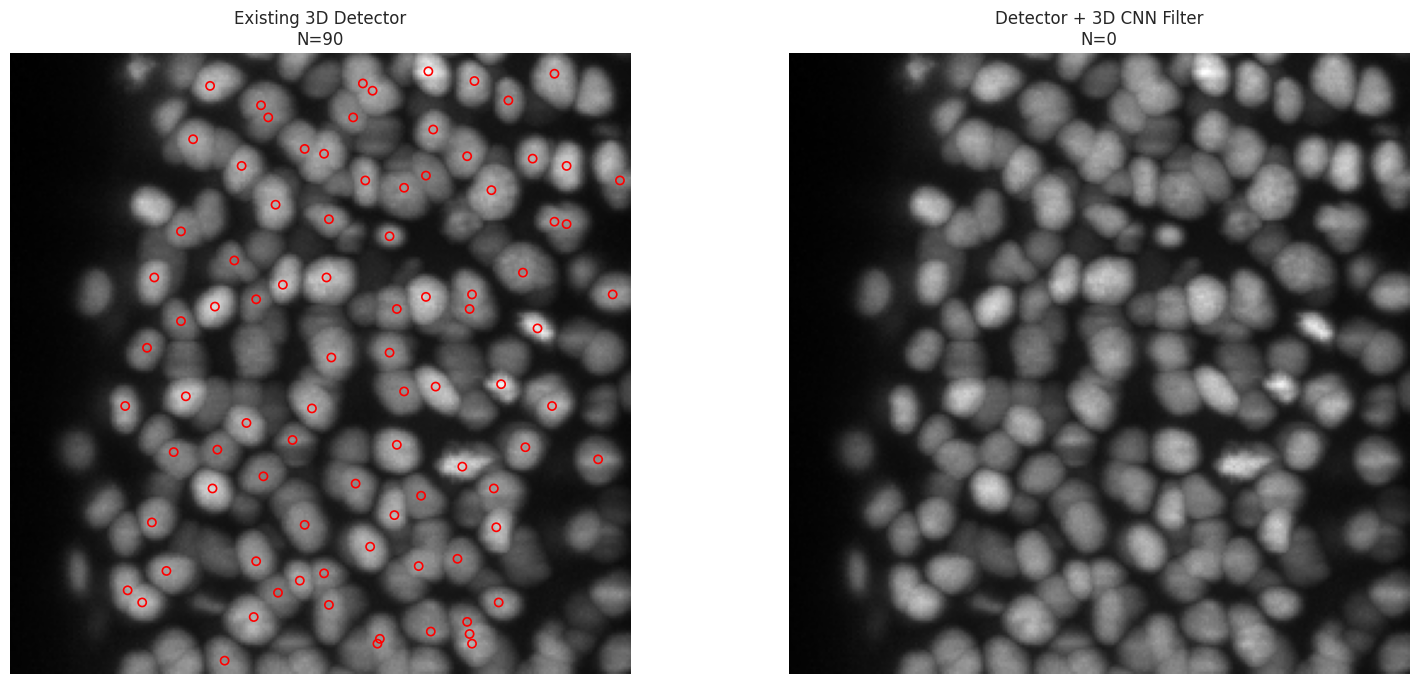

In [193]:
import matplotlib.pyplot as plt

mip = volume.max(axis=0)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 7)
)

# OLD
axes[0].imshow(
    mip,
    cmap="gray"
)

if not old_detections.empty:
    axes[0].scatter(
        old_detections["x"],
        old_detections["y"],
        s=35,
        facecolors="none",
        edgecolors="red",
        linewidths=1.2
    )

axes[0].set_title(
    f"Existing 3D Detector\n"
    f"N={len(old_detections)}"
)

axes[0].axis("off")

# NEW
axes[1].imshow(
    mip,
    cmap="gray"
)

if not new_detections.empty:
    axes[1].scatter(
        new_detections["x"],
        new_detections["y"],
        s=35,
        facecolors="none",
        edgecolors="lime",
        linewidths=1.2
    )

axes[1].set_title(
    f"Detector + 3D CNN Filter\n"
    f"N={len(new_detections)}"
)

axes[1].axis("off")

plt.tight_layout()
plt.show()

### 16.3S DETECTOR + CNN FOR ALL TEST MOVIES

In [194]:
detected_parts_cnn = []

for sample_id in tqdm(
    test_ids_integrated,
    desc="Detecting + CNN filtering"
):

    zarr_path = (
        TEST_DIR /
        f"{sample_id}.zarr"
    )

    store = zarr.open(
        str(zarr_path),
        mode="r"
    )

    movie = store["0"]

    rows = []
    node_id = 1

    for t in range(
        movie.shape[0]
    ):

        volume = np.asarray(
            movie[t],
            dtype=np.float32
        )

        # EXISTING DETECTOR + CNN FILTER
        detections = (
            detect_cells_3d_with_cnn(
                volume
            )
        )

        for row in detections.itertuples(
            index=False
        ):

            rows.append({
                "dataset": sample_id,
                "node_id": node_id,
                "t": int(t),

                "z": int(row.z),
                "y": int(row.y),
                "x": int(row.x),

                "z_um": float(
                    row.z * VOXEL_Z_UM
                ),

                "y_um": float(
                    row.y * VOXEL_Y_UM
                ),

                "x_um": float(
                    row.x * VOXEL_X_UM
                ),

                "intensity": float(
                    row.intensity
                ),

                # NEW diagnostic field
                "cnn_probability": float(
                    row.cnn_probability
                ),
            })

            node_id += 1

    df_movie = pd.DataFrame(
        rows
    )

    detected_parts_cnn.append(
        df_movie
    )

    print(
        f"{sample_id}: "
        f"{len(df_movie):,} "
        f"filtered detections"
    )


df_test_nodes_3d_cnn = pd.concat(
    detected_parts_cnn,
    ignore_index=True
)

print(
    "\nTotal CNN-filtered detections:",
    len(df_test_nodes_3d_cnn)
)

Detecting + CNN filtering:  25%|██▌       | 1/4 [01:39<04:57, 99.31s/it]

44b6_0113de3b: 45 filtered detections


Detecting + CNN filtering:  50%|█████     | 2/4 [02:36<02:28, 74.38s/it]

44b6_0b24845f: 0 filtered detections


Detecting + CNN filtering:  75%|███████▌  | 3/4 [03:30<01:05, 65.39s/it]

6bba_05b6850b: 0 filtered detections


Detecting + CNN filtering: 100%|██████████| 4/4 [04:53<00:00, 73.42s/it]

6bba_05db0fb1: 0 filtered detections

Total CNN-filtered detections: 45


### 16.3.1 Advanced 3D Volume Analysis

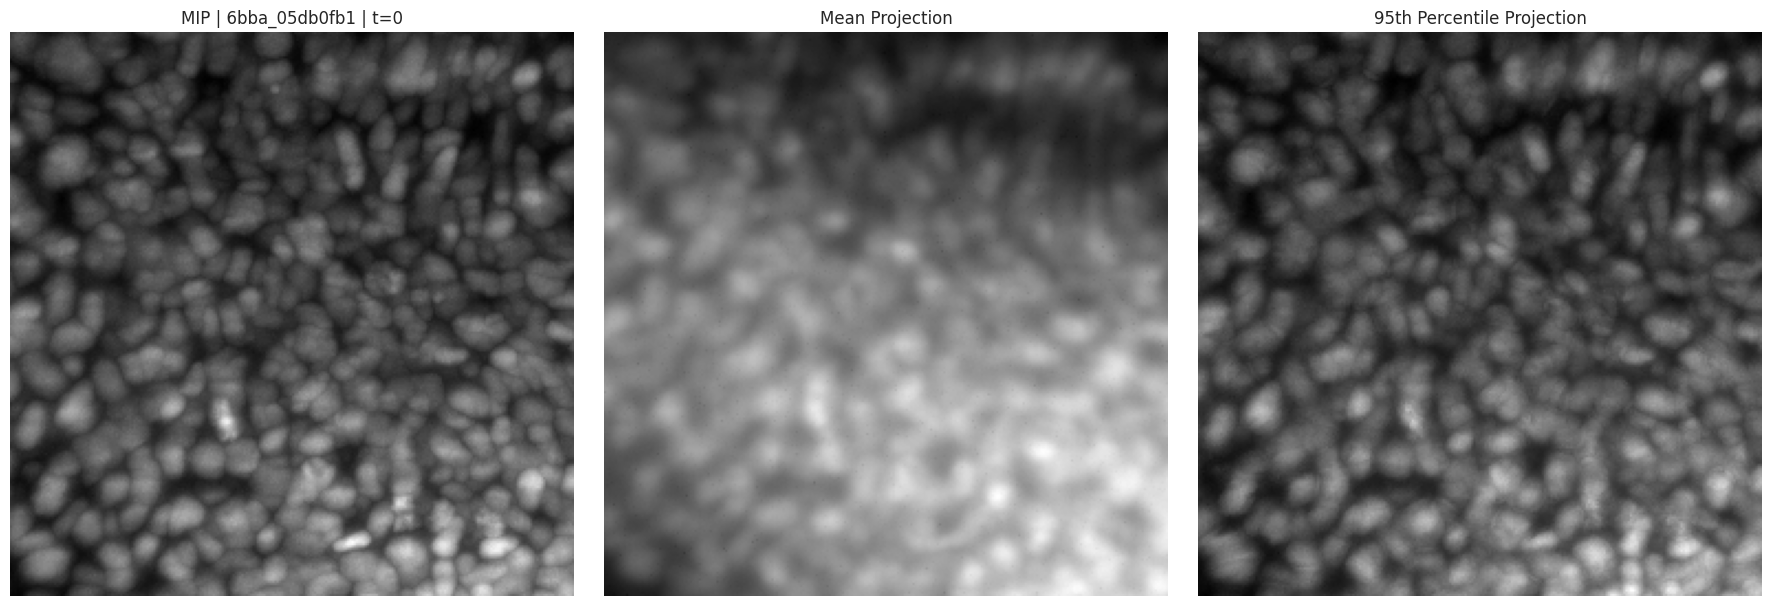

In [195]:
def volume_projection(volume, frame=0):

    img = np.asarray(volume[frame])

    if img.ndim == 4:
        img = img[0]

    mip = np.max(img, axis=0)
    mean_projection = np.mean(img, axis=0)
    p95_projection = np.percentile(img, 95, axis=0)

    return mip, mean_projection, p95_projection


def show_3d_volume_projections(
    sample_id,
    root=test_root,
    frame=0
):

    volume = get_volume_array(
        sample_id,
        root
    )

    mip, mean_proj, p95_proj = (
        volume_projection(
            volume,
            frame
        )
    )

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(18, 6)
    )

    axes[0].imshow(
        mip,
        cmap="gray"
    )

    axes[0].set_title(
        f"MIP | {sample_id} | t={frame}"
    )

    axes[1].imshow(
        mean_proj,
        cmap="gray"
    )

    axes[1].set_title(
        "Mean Projection"
    )

    axes[2].imshow(
        p95_proj,
        cmap="gray"
    )

    axes[2].set_title(
        "95th Percentile Projection"
    )

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


# Example
show_3d_volume_projections(
    next(iter(test_ids)),
    test_root,
    frame=0
)

In [196]:
# NODE-CENTERED 3D INSPECTION
def inspect_node_volume(
    sample_id,
    node_row,
    root=test_root,
    z_radius=3
):

    volume = get_volume_array(
        sample_id,
        root
    )

    t = int(node_row["t"])
    z = int(round(node_row["z"]))

    img = np.asarray(volume[t])

    if img.ndim == 4:
        img = img[0]

    z0 = max(0, z - z_radius)
    z1 = min(img.shape[0], z + z_radius + 1)

    mip_local = np.max(
        img[z0:z1],
        axis=0
    )

    plt.figure(figsize=(8, 8))

    plt.imshow(
        mip_local,
        cmap="gray"
    )

    plt.scatter(
        node_row["x"],
        node_row["y"],
        s=100,
        facecolors="none",
        edgecolors="red",
        linewidths=2
    )

    plt.title(
        f"3D Local MIP | {sample_id} | "
        f"t={t} | z≈{z}"
    )

    plt.axis("off")
    plt.show()

### 16.4 3D Detection Visualization

The next cell shows the detected cell centers in 3D physical coordinates. This is important because the Z spacing is different from X/Y spacing; therefore the plot uses **µm coordinates**, not raw voxel indices.


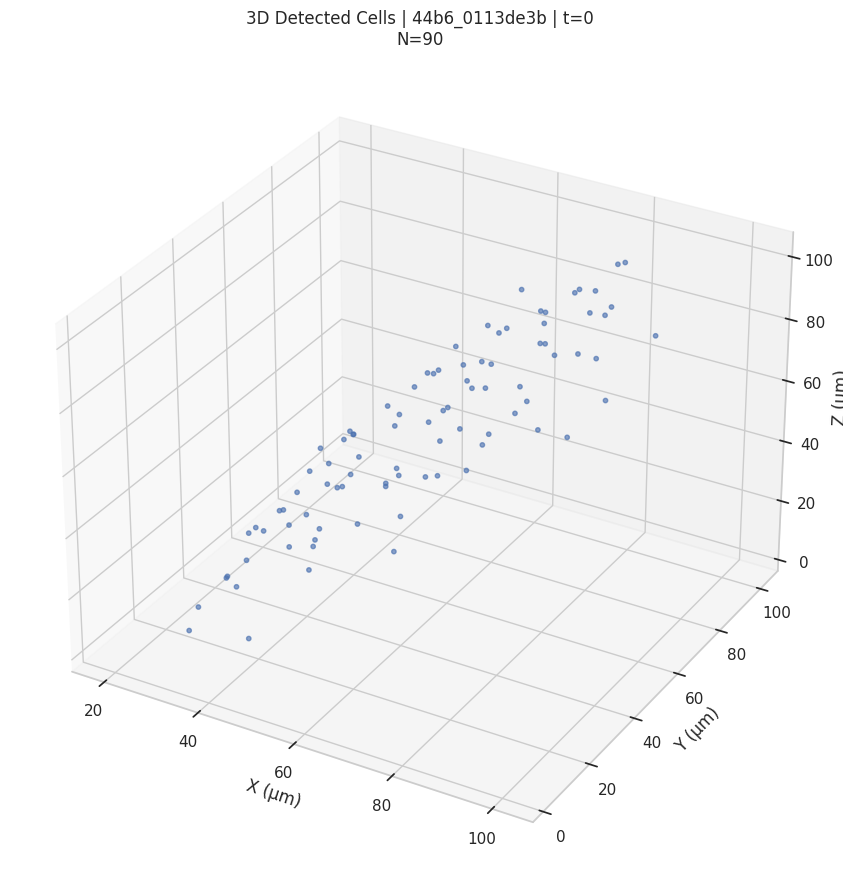

In [197]:
def plot_detected_cells_3d(
    df_nodes,
    dataset,
    timepoint=0,
    max_points=5000,
):
    df = df_nodes[
        (df_nodes["dataset"] == dataset)
        & (df_nodes["t"] == timepoint)
    ].copy()

    if df.empty:
        print(
            f"No detections for {dataset} at t={timepoint}"
        )
        return

    if len(df) > max_points:
        df = df.sample(
            max_points,
            random_state=42
        )

    fig = plt.figure(
        figsize=(11, 9)
    )

    ax = fig.add_subplot(
        111,
        projection="3d"
    )

    ax.scatter(
        df["x_um"],
        df["y_um"],
        df["z_um"],
        s=10,
        alpha=0.65,
    )

    ax.set_xlabel("X (µm)")
    ax.set_ylabel("Y (µm)")
    ax.set_zlabel("Z (µm)")

    ax.set_title(
        f"3D Detected Cells | {dataset} | t={timepoint}\n"
        f"N={len(df):,}"
    )

    plt.tight_layout()
    plt.show()


# Example:
if len(test_ids_integrated) > 0:

    first_dataset = test_ids_integrated[0]

    available_t = sorted(
        df_test_nodes_3d[
            df_test_nodes_3d["dataset"]
            == first_dataset
        ]["t"].unique()
    )

    if available_t:
        plot_detected_cells_3d(
            df_test_nodes_3d,
            dataset=first_dataset,
            timepoint=available_t[0],
        )


## 16.5 MIP + DETECTION OVERLAY

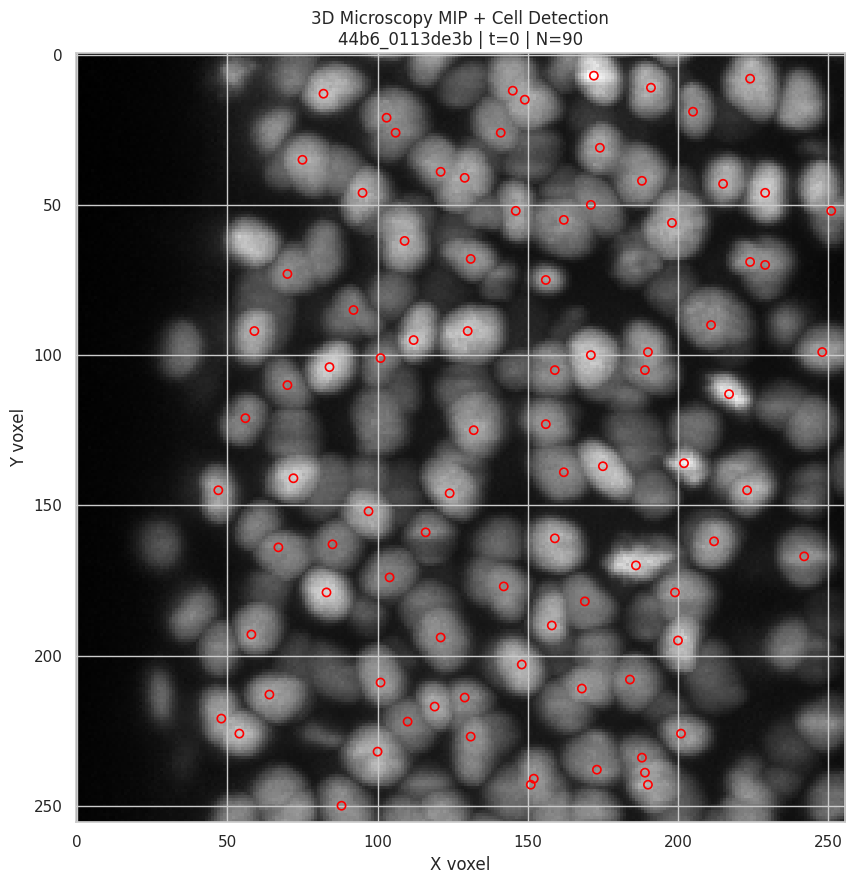

In [198]:
def plot_detection_mip(
    df_nodes,
    dataset,
    timepoint=0,
):
    zarr_path = TEST_DIR / f"{dataset}.zarr"

    store = zarr.open(
        str(zarr_path),
        mode="r"
    )

    volume = np.asarray(
        store["0"][timepoint]
    )

    mip = volume.max(axis=0)

    df = df_nodes[
        (df_nodes["dataset"] == dataset)
        & (df_nodes["t"] == timepoint)
    ]

    plt.figure(
        figsize=(10, 9)
    )

    plt.imshow(
        mip,
        cmap="gray"
    )

    if not df.empty:
        plt.scatter(
            df["x"],
            df["y"],
            s=35,
            facecolors="none",
            edgecolors="red",
            linewidths=1.2,
        )

    plt.title(
        f"3D Microscopy MIP + Cell Detection\n"
        f"{dataset} | t={timepoint} | "
        f"N={len(df)}"
    )

    plt.xlabel("X voxel")
    plt.ylabel("Y voxel")
    plt.tight_layout()
    plt.show()


if len(test_ids_integrated) > 0:

    dataset0 = test_ids_integrated[0]

    times0 = sorted(
        df_test_nodes_3d[
            df_test_nodes_3d["dataset"] == dataset0
        ]["t"].unique()
    )

    if times0:
        plot_detection_mip(
            df_test_nodes_3d,
            dataset0,
            times0[0]
        )


### 16.6 Safe Tracking on the New 3D Detections

The detection table is now passed into the v3 `safe_hybrid_tracker()`.

This preserves the existing safety constraints:

- physical-distance gating
- motion prediction
- unique track-to-detection assignment
- ambiguity rejection
- adjacent-frame linking
- no uncontrolled large jumps


In [199]:
df_tracking_input = df_test_nodes_3d.copy()

required_tracking_cols = [
    "dataset",
    "node_id",
    "t",
    "x_um",
    "y_um",
    "z_um",
]

missing = [
    c for c in required_tracking_cols
    if c not in df_tracking_input.columns
]

if missing:
    raise ValueError(
        f"Missing tracking columns: {missing}"
    )

# Ensure numeric physical coordinates
for c in ["x_um", "y_um", "z_um"]:
    df_tracking_input[c] = pd.to_numeric(
        df_tracking_input[c],
        errors="coerce"
    )

if df_tracking_input[
    ["x_um", "y_um", "z_um"]
].isna().any().any():

    raise ValueError(
        "Invalid physical coordinates detected."
    )

print("Tracking input ready.")
display(
    df_tracking_input.head()
)


Tracking input ready.


,dataset,node_id,t,z,y,x,z_um,y_um,x_um,intensity
0,44b6_0113de3b,1,0,2,92,59,3.250,37.37500,23.96875,1860.777466
1,44b6_0113de3b,2,0,2,145,47,3.250,58.90625,19.09375,1693.040283
2,44b6_0113de3b,3,0,3,221,48,4.875,89.78125,19.50000,1738.297607
3,44b6_0113de3b,4,0,6,121,56,9.750,49.15625,22.75000,1408.875977
4,44b6_0113de3b,5,0,7,26,106,11.375,10.56250,43.06250,1399.020386


## 16.7 RUN SAFE HYBRID TRACKER

In [208]:
if "tracking_cfg" not in globals():
    tracking_cfg = TrackingConfig(
        max_distance_um=30.0,
        max_age=1,
        candidate_radius_um=30.0,
        max_frame_gap=1,
        distance_weight=0.60,
        motion_weight=0.40,
        model_weight=0.0,
        min_link_score=0.45,
    )

df_tracked_3d = safe_hybrid_tracker(
    df_tracking_input,
    model=None,
    cfg=tracking_cfg,
)

df_tracked_3d = make_global_track_ids(
    df_tracked_3d
)

print("3D CELL TRACKING COMPLETE")

print(
    "Total detections:",
    len(df_tracked_3d)
)

print(
    "Total tracks:",
    df_tracked_3d["track_id"].nunique()
)

display(
    df_tracked_3d
    .groupby("dataset")
    .agg(
        detections=("node_id", "count"),
        tracks=("track_id", "nunique"),
    )
)


3D CELL TRACKING COMPLETE
Total detections: 24314
Total tracks: 6486


,detections,tracks
dataset,,
44b6_0113de3b,9914,2075
44b6_0b24845f,3084,1194
6bba_05b6850b,2801,321
6bba_05db0fb1,8515,2896


## 16.8 TRACK LENGTH / FRAGMENTATION REPORT

In [210]:
def fragmentation_report_3d(df):

    rows = []

    for dataset, movie in df.groupby("dataset"):

        for track_id, track in movie.groupby("track_id"):

            track = (
                track
                .sort_values("t")
                .reset_index(drop=True)
            )

            times = track["t"].to_numpy()

            length = len(times)

            if length <= 1:
                gaps = np.array([], dtype=int)
            else:
                gaps = np.diff(times) - 1

            missing_frames = int(
                gaps[gaps > 0].sum()
            ) if len(gaps) else 0

            max_gap = int(
                gaps.max()
            ) if len(gaps) else 0

            gap_count = int(
                (gaps > 0).sum()
            ) if len(gaps) else 0

            rows.append({
                "dataset": dataset,
                "track_id": track_id,
                "length": length,
                "start_t": int(times.min()),
                "end_t": int(times.max()),
                "missing_frames": missing_frames,
                "max_gap": max_gap,
                "gap_count": gap_count,
                "fragmented": (
                    gap_count > 0
                ),
            })

    return pd.DataFrame(rows)


fragmentation_3d = fragmentation_report_3d(
    df_tracked_3d
)

print("3D TRACK FRAGMENTATION REPORT")

track_lengths = (
    df_tracked_3d
    .groupby(["dataset", "track_id"])
    .size()
)

print(
    "Total tracks:",
    len(track_lengths)
)

print(
    "Mean track length:",
    round(track_lengths.mean(), 2)
)

print(
    "Median track length:",
    round(track_lengths.median(), 2)
)

print(
    "1-frame tracks:",
    int((track_lengths == 1).sum())
)

print(
    "Short tracks <=3:",
    int((track_lengths <= 3).sum())
)

print(
    "Long tracks >=10:",
    int((track_lengths >= 10).sum())
)

print(
    "Fragmented tracks:",
    int(fragmentation_3d["fragmented"].sum())
)

display(
    fragmentation_3d
    .sort_values(
        ["missing_frames", "max_gap", "length"],
        ascending=[False, False, True]
    )
    .head(50)
)


3D TRACK FRAGMENTATION REPORT
Total tracks: 6486
Mean track length: 3.75
Median track length: 2.0
1-frame tracks: 2608
Short tracks <=3: 4527
Long tracks >=10: 523
Fragmented tracks: 0


,dataset,track_id,length,start_t,end_t,missing_frames,max_gap,gap_count,fragmented
4,44b6_0113de3b,4,1,0,0,0,0,0,False
11,44b6_0113de3b,11,1,0,0,0,0,0,False
23,44b6_0113de3b,23,1,0,0,0,0,0,False
24,44b6_0113de3b,24,1,0,0,0,0,0,False
50,44b6_0113de3b,50,1,0,0,0,0,0,False
60,44b6_0113de3b,60,1,0,0,0,0,0,False
63,44b6_0113de3b,63,1,0,0,0,0,0,False
74,44b6_0113de3b,74,1,0,0,0,0,0,False
81,44b6_0113de3b,81,1,0,0,0,0,0,False
82,44b6_0113de3b,82,1,0,0,0,0,0,False


## 16.9 TRACK CONTINUITY SUMMARY BY MOVIE

In [202]:
continuity_summary = (
    fragmentation_3d
    .groupby("dataset")
    .agg(
        tracks=("track_id", "count"),
        mean_length=("length", "mean"),
        median_length=("length", "median"),
        one_frame_tracks=(
            "length",
            lambda x: (x == 1).sum()
        ),
        short_tracks_le3=(
            "length",
            lambda x: (x <= 3).sum()
        ),
        long_tracks_ge10=(
            "length",
            lambda x: (x >= 10).sum()
        ),
        fragmented_tracks=(
            "fragmented",
            "sum"
        ),
        total_missing_frames=(
            "missing_frames",
            "sum"
        ),
        max_gap=(
            "max_gap",
            "max"
        ),
    )
    .reset_index()
)

continuity_summary[
    "fragmentation_rate"
] = (
    continuity_summary["fragmented_tracks"]
    / continuity_summary["tracks"].clip(lower=1)
)

continuity_summary[
    "one_frame_rate"
] = (
    continuity_summary["one_frame_tracks"]
    / continuity_summary["tracks"].clip(lower=1)
)

print("TRACK CONTINUITY SUMMARY")

display(
    continuity_summary.round(3)
)


TRACK CONTINUITY SUMMARY


,dataset,tracks,mean_length,median_length,one_frame_tracks,short_tracks_le3,long_tracks_ge10,fragmented_tracks,total_missing_frames,max_gap,fragmentation_rate,one_frame_rate
0,44b6_0113de3b,2075,4.778,2.0,868,1332,315,0,0,0,0.0,0.418
1,44b6_0b24845f,1194,2.583,2.0,567,922,33,0,0,0,0.0,0.475
2,6bba_05b6850b,321,8.726,3.0,97,162,84,0,0,0,0.0,0.302
3,6bba_05db0fb1,2896,2.940,2.0,1076,2111,91,0,0,0,0.0,0.372


## 16.10 SUSPICIOUS JUMP / SWITCH CHECK

In [203]:
df_steps_3d = calculate_track_steps(
    df_tracked_3d
)

suspicious_jumps_3d = find_suspicious_jumps(
    df_steps_3d,
    max_distance_um=30.0
)

print("3D TRACK SWITCH / JUMP CHECK")

print(
    "Suspicious jumps:",
    len(suspicious_jumps_3d)
)

if suspicious_jumps_3d.empty:
    print(
        "No suspicious large movements were detected."
    )
else:
    display(
        suspicious_jumps_3d
        .sort_values(
            "step_distance",
            ascending=False
        )
        .head(30)
    )

# Robust switch detector is safe even when there are no jumps.
switch_report_3d = robust_track_switch_detector(
    df_tracked_3d,
    suspicious_jumps_3d,
    max_distance_um=30.0,
    top_n=100,
)

if not isinstance(
    switch_report_3d,
    pd.DataFrame
):
    switch_report_3d = pd.DataFrame(
        switch_report_3d
    )

print("\nSwitch report shape:", switch_report_3d.shape)
print(
    "Switch report columns:",
    switch_report_3d.columns.tolist()
)

if switch_report_3d.empty:
    print(
        "No suspicious track-switch cases were found."
    )
elif "status" in switch_report_3d.columns:
    print("\nSwitch status summary:")
    print(
        switch_report_3d["status"]
        .value_counts(dropna=False)
    )
    display(
        switch_report_3d.head(30)
    )
else:
    print(
        "WARNING: switch report has no 'status' column."
    )
    display(
        switch_report_3d.head(30)
    )


3D TRACK SWITCH / JUMP CHECK
Suspicious jumps: 0
No suspicious large movements were detected.

Switch report shape: (0, 0)
Switch report columns: []
No suspicious track-switch cases were found.


## 16.11 3D TRAJECTORY VISUALIZATION

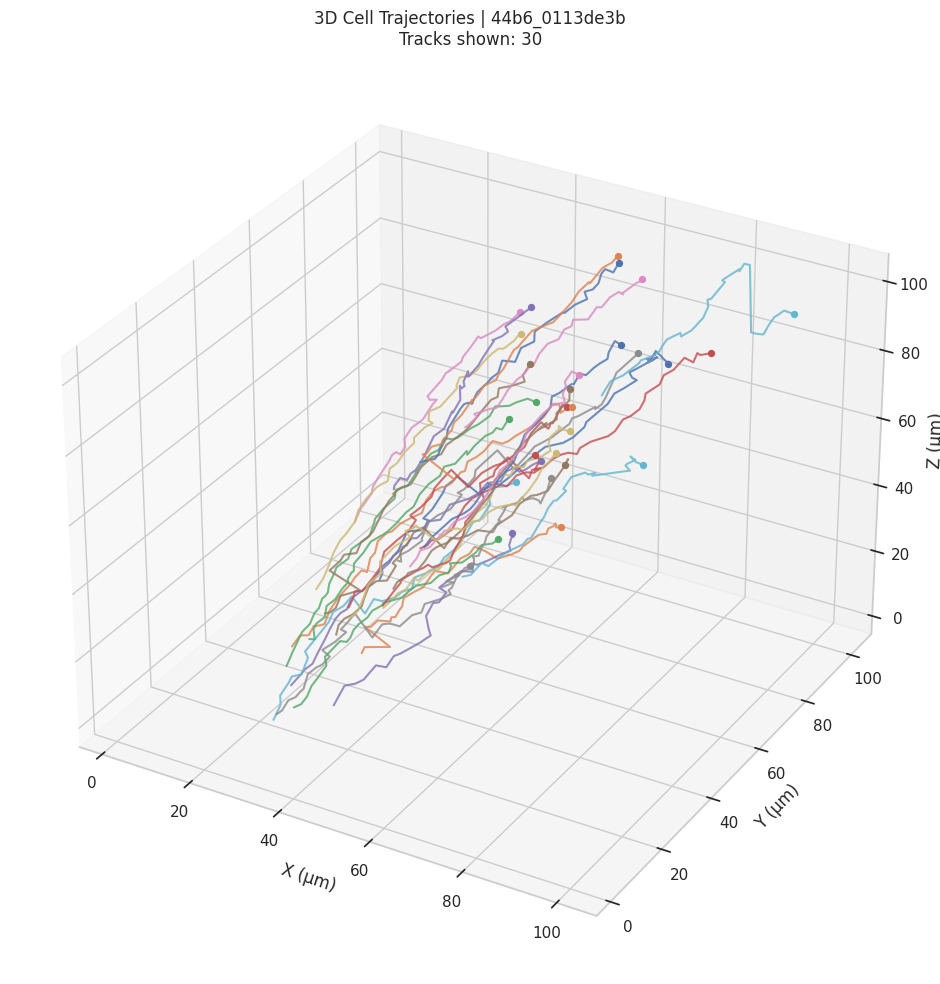

In [204]:
def plot_tracks_3d(
    df_tracked,
    dataset,
    min_track_length=5,
    max_tracks=30,
):
    movie = df_tracked[
        df_tracked["dataset"] == dataset
    ].copy()

    if movie.empty:
        print(
            f"No tracks found for {dataset}"
        )
        return

    lengths = (
        movie
        .groupby("track_id")
        .size()
        .sort_values(
            ascending=False
        )
    )

    selected_tracks = (
        lengths[
            lengths >= min_track_length
        ]
        .head(max_tracks)
        .index
    )

    if len(selected_tracks) == 0:
        print(
            f"No tracks with length >= "
            f"{min_track_length}"
        )
        return

    fig = plt.figure(
        figsize=(12, 10)
    )

    ax = fig.add_subplot(
        111,
        projection="3d"
    )

    for track_id in selected_tracks:

        track = (
            movie[
                movie["track_id"] == track_id
            ]
            .sort_values("t")
        )

        ax.plot(
            track["x_um"],
            track["y_um"],
            track["z_um"],
            linewidth=1.5,
            alpha=0.8,
        )

        ax.scatter(
            track["x_um"].iloc[-1],
            track["y_um"].iloc[-1],
            track["z_um"].iloc[-1],
            s=18,
        )

    ax.set_xlabel("X (µm)")
    ax.set_ylabel("Y (µm)")
    ax.set_zlabel("Z (µm)")

    ax.set_title(
        f"3D Cell Trajectories | {dataset}\n"
        f"Tracks shown: {len(selected_tracks)}"
    )

    plt.tight_layout()
    plt.show()


if len(test_ids_integrated) > 0:

    plot_tracks_3d(
        df_tracked_3d,
        dataset=test_ids_integrated[0],
        min_track_length=5,
        max_tracks=30,
    )


## 16.12 FINAL INTEGRATED REPORT

In [205]:
print("FINAL 3D CELL DETECTION + TRACKING REPORT")

print(
    f"Total detections : "
    f"{len(df_test_nodes_3d):,}"
)

print(
    f"Total tracks     : "
    f"{df_tracked_3d['track_id'].nunique():,}"
)

print(
    f"Mean track length: "
    f"{track_lengths.mean():.2f}"
)

print(
    f"Median track length: "
    f"{track_lengths.median():.2f}"
)

print(
    f"1-frame tracks   : "
    f"{int((track_lengths == 1).sum()):,}"
)

print(
    f"Short tracks <=3 : "
    f"{int((track_lengths <= 3).sum()):,}"
)

print(
    f"Long tracks >=10 : "
    f"{int((track_lengths >= 10).sum()):,}"
)

print(
    f"Fragmented tracks: "
    f"{int(fragmentation_3d['fragmented'].sum()):,}"
)

print(
    f"Suspicious jumps : "
    f"{len(suspicious_jumps_3d):,}"
)

if switch_report_3d.empty:
    print(
        "Track switch cases: 0"
    )
elif "status" in switch_report_3d.columns:
    print(
        "Track switch cases:",
        len(switch_report_3d)
    )

print("=" * 70)


FINAL 3D CELL DETECTION + TRACKING REPORT
Total detections : 24,314
Total tracks     : 6,486
Mean track length: 3.75
Median track length: 2.00
1-frame tracks   : 2,608
Short tracks <=3 : 4,527
Long tracks >=10 : 523
Fragmented tracks: 0
Suspicious jumps : 0
Track switch cases: 0


# TRAIN METRICS

In [206]:
# Linking model (section 8-9) and CNN filter (section 16.3) now use SEPARATE variable names
print("Linking model   : X_train", getattr(X_train, "shape", None), "| y_train", getattr(y_train, "shape", None))
if "model" in globals() and hasattr(model, "n_features_in_"):
    print("  model expects", model.n_features_in_, "features")
print("CNN filter data : X_cnn_train", X_cnn_train.shape, "| y_cnn_train", y_cnn_train.shape)
print("                  X_cnn_val  ", X_cnn_val.shape, "| y_cnn_val  ", y_cnn_val.shape)

Linking model   : X_train (486912, 6) | y_train (486912,)
  model expects 6 features
CNN filter data : X_cnn_train (311700, 15, 15, 15, 1) | y_cnn_train (311700,)
                  X_cnn_val   (229003, 15, 15, 15, 1) | y_cnn_val   (229003,)


In [211]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

cnn_train_proba = cnn_filter.predict(
    X_cnn_train,
    batch_size=CNN_BATCH_SIZE,
    verbose=0
).reshape(-1)

cnn_train_pred = (
    cnn_train_proba >= CNN_THRESHOLD
).astype(int)


print("=" * 60)
print("CNN TRAIN METRICS")
print("=" * 60)

print(f"Threshold : {CNN_THRESHOLD}")
print(
    f"Accuracy  : "
    f"{accuracy_score(y_cnn_train, cnn_train_pred):.4f}"
)

print(
    f"Precision : "
    f"{precision_score(y_cnn_train, cnn_train_pred, zero_division=0):.4f}"
)

print(
    f"Recall    : "
    f"{recall_score(y_cnn_train, cnn_train_pred, zero_division=0):.4f}"
)

print(
    f"F1        : "
    f"{f1_score(y_cnn_train, cnn_train_pred, zero_division=0):.4f}"
)

print(
    f"ROC-AUC   : "
    f"{roc_auc_score(y_cnn_train, cnn_train_proba):.4f}"
)

print("\nClassification Report:")

print(
    classification_report(
        y_cnn_train,
        cnn_train_pred,
        digits=4,
        zero_division=0
    )
)

CNN TRAIN METRICS
Threshold : 0.5
Accuracy  : 0.9899
Precision : 0.7655
Recall    : 0.1509
F1        : 0.2521
ROC-AUC   : 0.9081

Classification Report:
              precision    recall  f1-score   support

         0.0     0.9904    0.9995    0.9949    308175
         1.0     0.7655    0.1509    0.2521      3525

    accuracy                         0.9899    311700
   macro avg     0.8779    0.5752    0.6235    311700
weighted avg     0.9878    0.9899    0.9865    311700



In [212]:
# CNN VALIDATION METRICS
cnn_val_proba = cnn_filter.predict(
    X_cnn_val,
    batch_size=CNN_BATCH_SIZE,
    verbose=0
).reshape(-1)

cnn_val_pred = (
    cnn_val_proba >= CNN_THRESHOLD
).astype(int)


print("=" * 60)
print("CNN VALIDATION METRICS")
print("=" * 60)

print(f"Threshold : {CNN_THRESHOLD}")

print(
    f"Accuracy  : "
    f"{accuracy_score(y_cnn_val, cnn_val_pred):.4f}"
)

print(
    f"Precision : "
    f"{precision_score(y_cnn_val, cnn_val_pred, zero_division=0):.4f}"
)

print(
    f"Recall    : "
    f"{recall_score(y_cnn_val, cnn_val_pred, zero_division=0):.4f}"
)

print(
    f"F1        : "
    f"{f1_score(y_cnn_val, cnn_val_pred, zero_division=0):.4f}"
)

print(
    f"ROC-AUC   : "
    f"{roc_auc_score(y_cnn_val, cnn_val_proba):.4f}"
)

print("\nClassification Report:")

print(
    classification_report(
        y_cnn_val,
        cnn_val_pred,
        digits=4,
        zero_division=0
    )
)

CNN VALIDATION METRICS
Threshold : 0.5
Accuracy  : 0.9133
Precision : 0.2207
Recall    : 0.0066
F1        : 0.0127
ROC-AUC   : 0.6176

Classification Report:
              precision    recall  f1-score   support

         0.0     0.9150    0.9978    0.9546    209468
         1.0     0.2207    0.0066    0.0127     19535

    accuracy                         0.9133    229003
   macro avg     0.5679    0.5022    0.4837    229003
weighted avg     0.8558    0.9133    0.8743    229003



In [213]:
print("df_tracked_3d columns:", df_tracked_3d.columns.tolist())
print(df_tracked_3d.head())
print("\nUnique datasets:", df_tracked_3d["dataset"].unique() if "dataset" in df_tracked_3d.columns else "NO dataset column")

df_tracked_3d columns: ['dataset', 'node_id', 't', 'z', 'y', 'x', 'z_um', 'y_um', 'x_um', 'intensity', 'track_id']
         dataset  node_id  t  z    y    x    z_um      y_um      x_um  \
0  44b6_0113de3b        1  0  2   92   59   3.250  37.37500  23.96875   
1  44b6_0113de3b        2  0  2  145   47   3.250  58.90625  19.09375   
2  44b6_0113de3b        3  0  3  221   48   4.875  89.78125  19.50000   
3  44b6_0113de3b        4  0  6  121   56   9.750  49.15625  22.75000   
4  44b6_0113de3b        5  0  7   26  106  11.375  10.56250  43.06250   

     intensity  track_id  
0  1860.777466         0  
1  1693.040283         1  
2  1738.297607         2  
3  1408.875977         3  
4  1399.020386         4  

Unique datasets: ['44b6_0113de3b' '44b6_0b24845f' '6bba_05b6850b' '6bba_05db0fb1']


In [214]:
import pandas as pd
import numpy as np

def edges_from_tracks(df: pd.DataFrame) -> pd.DataFrame:
    """Create consecutive-frame edges from track_id."""
    required = {"dataset", "node_id", "track_id", "t"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"Missing columns: {missing}")

    edges = []
    for (ds, tid), g in df.groupby(["dataset", "track_id"], sort=False):
        g = g.sort_values("t")
        if len(g) < 2:
            continue
        src = g["node_id"].iloc[:-1].astype("int64").values
        tgt = g["node_id"].iloc[1:].astype("int64").values
        for s, t in zip(src, tgt):
            edges.append({"dataset": ds, "source_id": s, "target_id": t})
    return pd.DataFrame(edges)

# Build edges
df_test_edges_3d = edges_from_tracks(df_tracked_3d)
print(f"Created {len(df_test_edges_3d):,} edges")
print(df_test_edges_3d.head())

Created 17,828 edges
         dataset  source_id  target_id
0  44b6_0113de3b          1         91
1  44b6_0113de3b         91        175
2  44b6_0113de3b        175        258
3  44b6_0113de3b        258        343
4  44b6_0113de3b        343        433


In [215]:
def tracked_to_submission(df_nodes: pd.DataFrame, df_edges: pd.DataFrame) -> pd.DataFrame:
    nodes = df_nodes.copy()
    nodes["row_type"]  = "node"
    nodes["source_id"] = -1
    nodes["target_id"] = -1
    for c in ["t", "z", "y", "x", "node_id"]:
        nodes[c] = pd.to_numeric(nodes[c], errors="coerce").round().astype("int64")

    edges = df_edges.copy()
    edges["row_type"] = "edge"
    edges["node_id"]  = -1
    edges["t"] = edges["z"] = edges["y"] = edges["x"] = -1
    edges["source_id"] = edges["source_id"].astype("int64")
    edges["target_id"] = edges["target_id"].astype("int64")

    cols = ["dataset", "row_type", "node_id", "t", "z", "y", "x", "source_id", "target_id"]
    df = pd.concat([nodes[cols], edges[cols]], ignore_index=True)
    df.insert(0, "id", np.arange(len(df), dtype="int64"))

    int_cols = ["id", "node_id", "t", "z", "y", "x", "source_id", "target_id"]
    df[int_cols] = df[int_cols].astype("int64")
    return df

# Make sure nodes have a 'dataset' column and integer node_id
# (adjust the rename if your column names are different)
nodes = df_tracked_3d.copy()
if "dataset" not in nodes.columns:
    # example: if you have a column called 'volume' or 'name'
    # nodes = nodes.rename(columns={"volume": "dataset"})
    raise ValueError("Add a 'dataset' column first")

submission = tracked_to_submission(nodes, df_test_edges_3d)
submission.to_csv(WORK_DIR / "submission_v8_baseline.csv", index=False)

print(submission.head(10))
print(f"\nTotal rows: {len(submission):,}")
print(submission["row_type"].value_counts())

   id        dataset row_type  node_id  t   z    y    x  source_id  target_id
0   0  44b6_0113de3b     node        1  0   2   92   59         -1         -1
1   1  44b6_0113de3b     node        2  0   2  145   47         -1         -1
2   2  44b6_0113de3b     node        3  0   3  221   48         -1         -1
3   3  44b6_0113de3b     node        4  0   6  121   56         -1         -1
4   4  44b6_0113de3b     node        5  0   7   26  106         -1         -1
5   5  44b6_0113de3b     node        6  0   7   73   70         -1         -1
6   6  44b6_0113de3b     node        7  0   8   13   82         -1         -1
7   7  44b6_0113de3b     node        8  0   8   35   75         -1         -1
8   8  44b6_0113de3b     node        9  0   8  226   54         -1         -1
9   9  44b6_0113de3b     node       10  0  10  110   70         -1         -1

Total rows: 42,142
row_type
node    24314
edge    17828
Name: count, dtype: int64


In [216]:
def edges_from_tracks(df: pd.DataFrame) -> pd.DataFrame:
    """
    df must have: dataset, node_id, track_id, t
    Returns edges between consecutive frames of the same track.
    """
    edges = []
    for (ds, tid), g in df.groupby(["dataset", "track_id"]):
        g = g.sort_values("t")
        for i in range(len(g) - 1):
            edges.append({
                "dataset":   ds,
                "source_id": int(g.iloc[i]["node_id"]),
                "target_id": int(g.iloc[i + 1]["node_id"]),
            })
    return pd.DataFrame(edges)

In [217]:
df_edges = edges_from_tracks(df_tracked_3d)
submission = tracked_to_submission(df_tracked_3d, df_edges)
submission.to_csv(WORK_DIR / "submission_v8_baseline.csv", index=False)

In [218]:
print(submission["row_type"].value_counts())
print(submission.groupby("dataset")["row_type"].value_counts().unstack(fill_value=0))
assert set(submission.columns) == {
    "id", "dataset", "row_type", "node_id", "t", "z", "y", "x", "source_id", "target_id"
}
assert (submission.loc[submission.row_type == "node", ["source_id", "target_id"]] == -1).all().all()
assert (submission.loc[submission.row_type == "edge", ["node_id", "t", "z", "y", "x"]] == -1).all().all()

row_type
node    24314
edge    17828
Name: count, dtype: int64
row_type       edge  node
dataset                  
44b6_0113de3b  7839  9914
44b6_0b24845f  1890  3084
6bba_05b6850b  2480  2801
6bba_05db0fb1  5619  8515


In [219]:
submission.to_csv(WORK_DIR / "submission_v8_baseline.csv", index=False)   # v9 writes the final submission.csv (section 26)

In [220]:
print("=== Available DataFrames ===")
for name in ["df_test_nodes_3d", "df_tracked_3d", "df_test_edges_3d", "submission"]:
    if name in globals():
        df = globals()[name]
        print(f"\n{name}: {df.shape}")
        print("Columns:", df.columns.tolist())
        print(df.head(2))
    else:
        print(f"\n{name}: NOT FOUND")

=== Available DataFrames ===

df_test_nodes_3d: (24314, 10)
Columns: ['dataset', 'node_id', 't', 'z', 'y', 'x', 'z_um', 'y_um', 'x_um', 'intensity']
         dataset  node_id  t  z    y   x  z_um      y_um      x_um  \
0  44b6_0113de3b        1  0  2   92  59  3.25  37.37500  23.96875   
1  44b6_0113de3b        2  0  2  145  47  3.25  58.90625  19.09375   

     intensity  
0  1860.777466  
1  1693.040283  

df_tracked_3d: (24314, 11)
Columns: ['dataset', 'node_id', 't', 'z', 'y', 'x', 'z_um', 'y_um', 'x_um', 'intensity', 'track_id']
         dataset  node_id  t  z    y   x  z_um      y_um      x_um  \
0  44b6_0113de3b        1  0  2   92  59  3.25  37.37500  23.96875   
1  44b6_0113de3b        2  0  2  145  47  3.25  58.90625  19.09375   

     intensity  track_id  
0  1860.777466         0  
1  1693.040283         1  

df_test_edges_3d: (17828, 3)
Columns: ['dataset', 'source_id', 'target_id']
         dataset  source_id  target_id
0  44b6_0113de3b          1         91
1  44b6_0113d

# Cell Detection Overlay

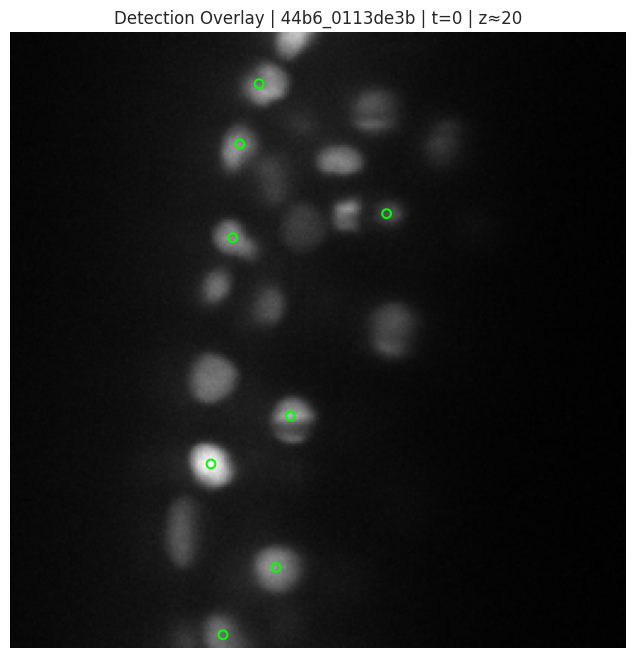

Total detection of the frame: 90


In [221]:
import zarr
import numpy as np
import matplotlib.pyplot as plt

DATASET = "44b6_0113de3b"
T_FRAME = 0          
Z_SLICE = 20        

# Zarr লোড
zarr_path = str(Path(test_root) / f"{DATASET}.zarr")
store = zarr.open(zarr_path, mode="r")
vol = store["0"]     # shape: (T, Z, Y, X) / (T, C, Z, Y, X)

if vol.ndim == 5:
    img = vol[T_FRAME, 0, Z_SLICE]
else:
    img = vol[T_FRAME, Z_SLICE]

det = df_tracked_3d[
    (df_tracked_3d["dataset"] == DATASET) &
    (df_tracked_3d["t"] == T_FRAME)
].copy()

det_near = det[np.abs(det["z"] - Z_SLICE) <= 2]

plt.figure(figsize=(10, 8))
plt.imshow(img, cmap="gray")
plt.scatter(det_near["x"], det_near["y"], s=40, facecolors="none", edgecolors="lime", linewidths=1.5)
plt.title(f"Detection Overlay | {DATASET} | t={T_FRAME} | z≈{Z_SLICE}")
plt.axis("off")
plt.show()

print(f"Total detection of the frame: {len(det)}")

# Tracking Visualization

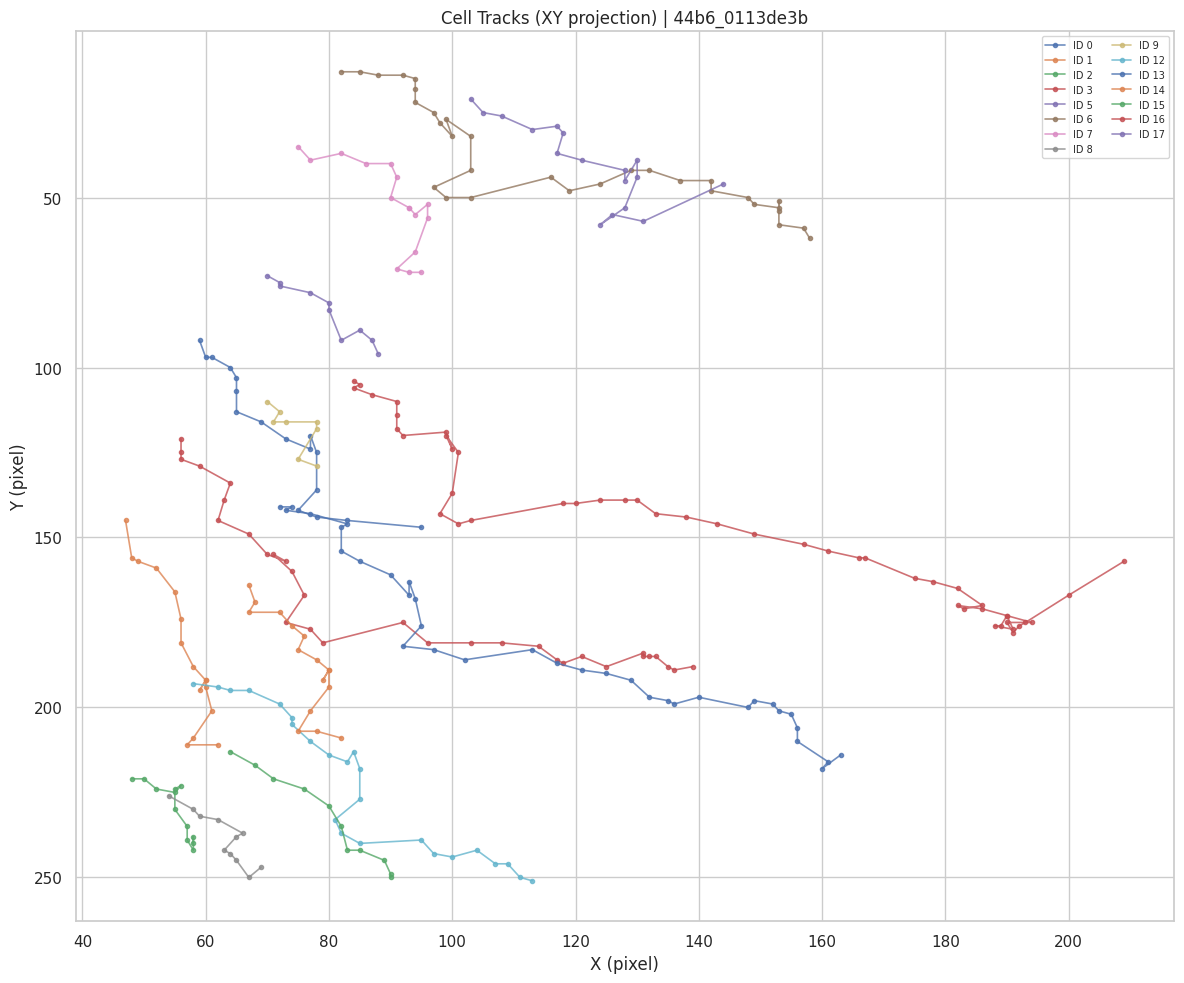

In [222]:
track_lens = df_tracked_3d[df_tracked_3d["dataset"] == DATASET].groupby("track_id").size()
long_tracks = track_lens[track_lens >= 8].index[:15]

plt.figure(figsize=(12, 10))
ax = plt.gca()

for tid in long_tracks:
    tr = df_tracked_3d[
        (df_tracked_3d["dataset"] == DATASET) &
        (df_tracked_3d["track_id"] == tid)
    ].sort_values("t")
    
    ax.plot(tr["x"], tr["y"], "-o", markersize=3, linewidth=1.2, alpha=0.8, label=f"ID {tid}")

ax.set_title(f"Cell Tracks (XY projection) | {DATASET}")
ax.set_xlabel("X (pixel)")
ax.set_ylabel("Y (pixel)")
ax.invert_yaxis()
ax.legend(fontsize=7, loc="upper right", ncol=2)
plt.tight_layout()
plt.show()

# Division Analysis

In [223]:
import pandas as pd
import numpy as np
from scipy.spatial.distance import cdist

def find_candidate_divisions(df, dataset, max_dist_um=12.0):

    d = df[df["dataset"] == dataset].copy()

    for col in ["z_um", "y_um", "x_um"]:
        d[col] = pd.to_numeric(d[col], errors="coerce")

    d = d.dropna(subset=["z_um", "y_um", "x_um"])

    starts = d.loc[d.groupby("track_id")["t"].idxmin()].copy()
    ends   = d.loc[d.groupby("track_id")["t"].idxmax()].copy()

    candidates = []

    for _, parent in ends.iterrows():
        t_next = int(parent["t"]) + 1
        children = starts[starts["t"] == t_next]

        if len(children) < 2:
            continue

        p_xyz = parent[["z_um", "y_um", "x_um"]].values.astype(float).reshape(1, -1)
        c_xyz = children[["z_um", "y_um", "x_um"]].values.astype(float)

        dists = cdist(p_xyz, c_xyz)[0]

        nearby_mask = dists <= max_dist_um
        nearby = children[nearby_mask]
        nearby_dists = dists[nearby_mask]

        if len(nearby) >= 2:
            order = np.argsort(nearby_dists)[:2]
            near = nearby.iloc[order]
            candidates.append({
                "parent_track": int(parent["track_id"]),
                "parent_t": int(parent["t"]),
                "parent_node": int(parent["node_id"]),
                "child1_track": int(near.iloc[0]["track_id"]),
                "child2_track": int(near.iloc[1]["track_id"]),
                "child1_node": int(near.iloc[0]["node_id"]),
                "child2_node": int(near.iloc[1]["node_id"]),
                "dist1_um": float(nearby_dists[order[0]]),
                "dist2_um": float(nearby_dists[order[1]]),
            })

    return pd.DataFrame(candidates)

DATASET = "44b6_0113de3b"
div_df = find_candidate_divisions(df_tracked_3d, DATASET, max_dist_um=12.0)

print(f"Possible Division Founded: {len(div_df)}")
if len(div_df) > 0:
    print(div_df.head(10))
else:
    print("Try again if max_dist_um is found (e.g. 18 or 25).")

Possible Division Founded: 688
   parent_track  parent_t  parent_node  child1_track  child2_track  \
0             3        31         2808           582           578   
1            16        47         4453          1009          1005   
2            25        11          971           242           243   
3            34         9          812           212           211   
4            40         9          816           212           213   
5            46         3          305           129           128   
6            55         9          829           215           214   
7            57        16         1449           344           345   
8            59        13         1180           270           269   
9            65         6          581           172           173   

   child1_node  child2_node  dist1_um   dist2_um  
0         2910         2906  4.614113  10.357383  
1         4564         4558  6.039340   8.797916  
2         1059         1061  2.929510   5.540

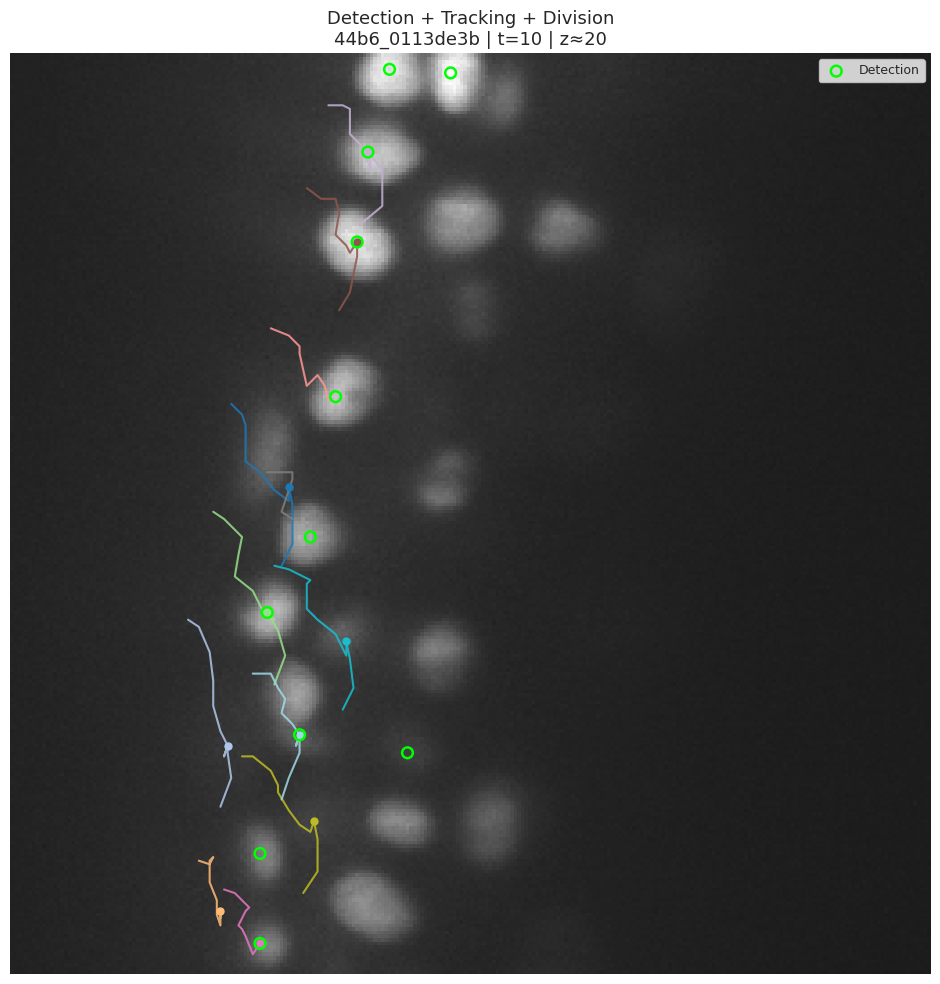

Detection in this slice: 11
Showing Tracks: 12
nearby division: 5


In [224]:
import zarr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

DATASET   = "44b6_0113de3b"
T_FRAME   = 10         
Z_SLICE   = 20          
MAX_TRACK_SHOW = 12

zarr_path = str(Path(test_root) / f"{DATASET}.zarr")
store = zarr.open(zarr_path, mode="r")
vol = store["0"]

if vol.ndim == 5:
    img = np.array(vol[T_FRAME, 0, Z_SLICE])
else:
    img = np.array(vol[T_FRAME, Z_SLICE])

df = df_tracked_3d[df_tracked_3d["dataset"] == DATASET].copy()
for c in ["z_um", "y_um", "x_um", "z", "y", "x"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

dets = df[(df["t"] == T_FRAME) & (np.abs(df["z"] - Z_SLICE) <= 3)]

track_len = df.groupby("track_id").size()
long_ids = track_len[track_len >= 5].index[:MAX_TRACK_SHOW]

if "div_df" not in globals() or len(div_df) == 0:
    print("div_df খালি বা নেই — আগে division কোড রান করুন")
else:
    divs_near = div_df[
        (div_df["parent_t"] >= T_FRAME - 2) &
        (div_df["parent_t"] <= T_FRAME + 1)
    ].head(5)

fig, ax = plt.subplots(figsize=(12, 10))
ax.imshow(img, cmap="gray", alpha=0.9)

ax.scatter(dets["x"], dets["y"],
           s=60, facecolors="none", edgecolors="lime",
           linewidths=1.8, label="Detection", zorder=5)

colors = plt.cm.tab20(np.linspace(0, 1, len(long_ids)))
for tid, color in zip(long_ids, colors):
    tr = df[df["track_id"] == tid].sort_values("t")
    # শুধু বর্তমান ফ্রেমের আশেপাশের অংশ
    tr = tr[(tr["t"] >= T_FRAME - 8) & (tr["t"] <= T_FRAME + 3)]
    if len(tr) < 2:
        continue
    ax.plot(tr["x"], tr["y"], "-", color=color, linewidth=1.5, alpha=0.85, zorder=3)
    cur = tr[tr["t"] == T_FRAME]
    if len(cur):
        ax.scatter(cur["x"], cur["y"], c=[color], s=25, zorder=4)

if "divs_near" in dir() and len(divs_near) > 0:
    for _, row in divs_near.iterrows():
        # parent
        p = df[(df["track_id"] == row["parent_track"]) & (df["t"] == row["parent_t"])]
        if len(p) == 0:
            continue
        p = p.iloc[0]
        if abs(p["z"] - Z_SLICE) > 5:
            continue
        ax.scatter(p["x"], p["y"], marker="*", c="red", s=220,
                   edgecolors="white", linewidths=0.8, zorder=6, label="Division Parent")

        # two children
        for cid in [row["child1_track"], row["child2_track"]]:
            ch = df[(df["track_id"] == cid)].sort_values("t").iloc[0]  # start of child
            ax.scatter(ch["x"], ch["y"], marker="o", c="yellow",
                       s=80, edgecolors="red", linewidths=1.2, zorder=6)

handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), loc="upper right", fontsize=9)

ax.set_title(f"Detection + Tracking + Division\n{DATASET} | t={T_FRAME} | z≈{Z_SLICE}", fontsize=13)
ax.axis("off")
plt.tight_layout()
plt.show()

print(f"Detection in this slice: {len(dets)}")
print(f"Showing Tracks: {len(long_ids)}")
if "divs_near" in dir():
    print(f"nearby division: {len(divs_near)}")

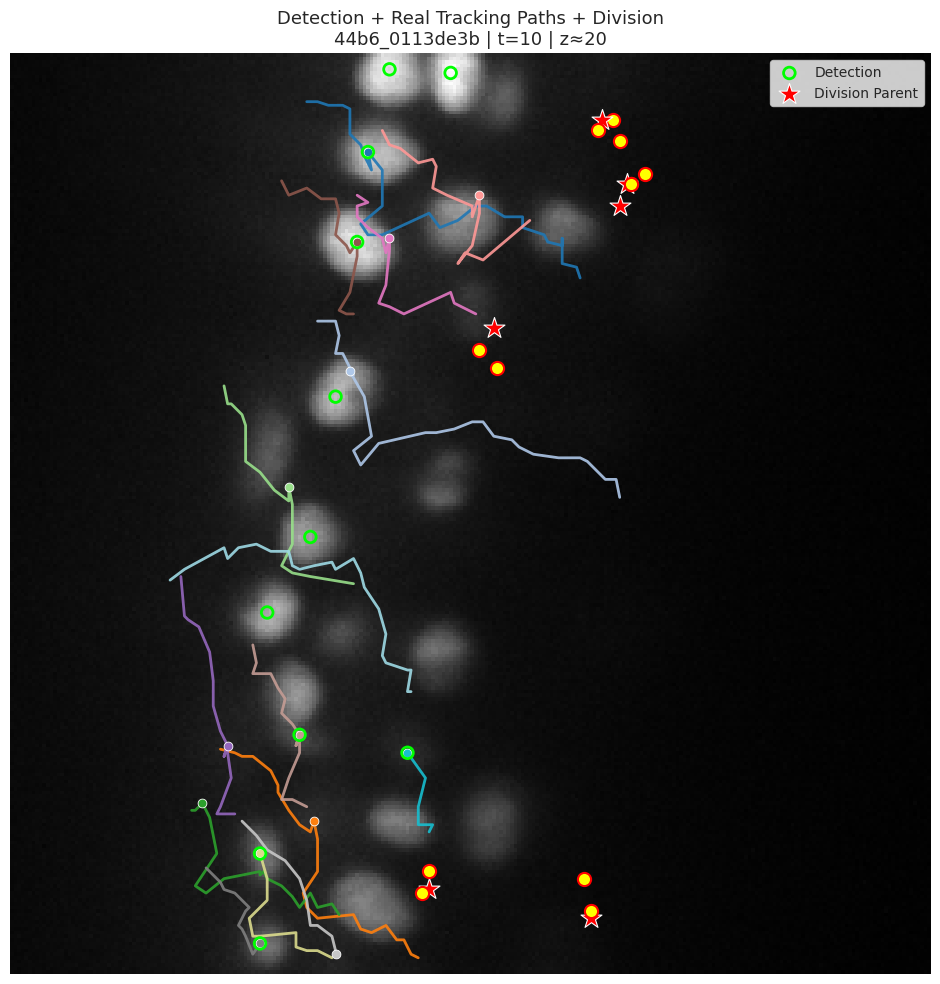

Detection: 11 | Tracks shown: 15 | Divisions: 6


In [225]:
import zarr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

DATASET     = "44b6_0113de3b"
T_FRAME     = 10
Z_SLICE     = 20
Z_TOL       = 6    
MIN_TRACK_LEN = 6
MAX_TRACKS  = 15

zarr_path = str(Path(test_root) / f"{DATASET}.zarr")
store = zarr.open(zarr_path, mode="r")
vol = store["0"]
img = np.array(vol[T_FRAME, 0, Z_SLICE] if vol.ndim == 5 else vol[T_FRAME, Z_SLICE])

df = df_tracked_3d[df_tracked_3d["dataset"] == DATASET].copy()
for c in ["z", "y", "x", "t"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

def track_near_z(g, z0=Z_SLICE, tol=Z_TOL):
    return (np.abs(g["z"] - z0) <= tol).mean() >= 0.4   # ৪০% সময় কাছে থাকলে

cand = []
for tid, g in df.groupby("track_id"):
    if len(g) >= MIN_TRACK_LEN and track_near_z(g):
        cand.append(tid)

present = set(df[df["t"] == T_FRAME]["track_id"])
cand = sorted(cand, key=lambda t: (t not in present, -len(df[df.track_id == t])))[:MAX_TRACKS]

dets = df[(df["t"] == T_FRAME) & (np.abs(df["z"] - Z_SLICE) <= 3)]

divs = div_df[
    (div_df["parent_t"] >= T_FRAME - 3) &
    (div_df["parent_t"] <= T_FRAME + 1)
].head(6) if "div_df" in globals() else pd.DataFrame()

fig, ax = plt.subplots(figsize=(11, 10))
ax.imshow(img, cmap="gray")

cmap = plt.cm.tab20(np.linspace(0, 1, len(cand)))
for tid, color in zip(cand, cmap):
    tr = df[df["track_id"] == tid].sort_values("t")
    ax.plot(tr["x"], tr["y"], "-", color=color, lw=2.0, alpha=0.9, zorder=3)
    cur = tr[tr["t"] == T_FRAME]
    if len(cur):
        ax.scatter(cur["x"], cur["y"], c=[color], s=40, edgecolors="white",
                   linewidths=0.6, zorder=5)

ax.scatter(dets["x"], dets["y"], s=70, facecolors="none",
           edgecolors="lime", linewidths=2.0, label="Detection", zorder=6)

for _, row in divs.iterrows():
    p = df[(df["track_id"] == row["parent_track"]) & (df["t"] == row["parent_t"])]
    if len(p) == 0:
        continue
    p = p.iloc[0]
    ax.scatter(p["x"], p["y"], marker="*", c="red", s=250,
               edgecolors="white", linewidths=0.8, zorder=7, label="Division Parent")
    for cid in [row["child1_track"], row["child2_track"]]:
        ch = df[df["track_id"] == cid].sort_values("t")
        if len(ch):
            c0 = ch.iloc[0]
            ax.scatter(c0["x"], c0["y"], c="yellow", s=90,
                       edgecolors="red", linewidths=1.5, zorder=7)

handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), loc="upper right", fontsize=10)

ax.set_title(f"Detection + Real Tracking Paths + Division\n{DATASET} | t={T_FRAME} | z≈{Z_SLICE}", fontsize=13)
ax.axis("off")
plt.tight_layout()
plt.show()

print(f"Detection: {len(dets)} | Tracks shown: {len(cand)} | Divisions: {len(divs)}")

Volume shape: (100, 64, 256, 256)


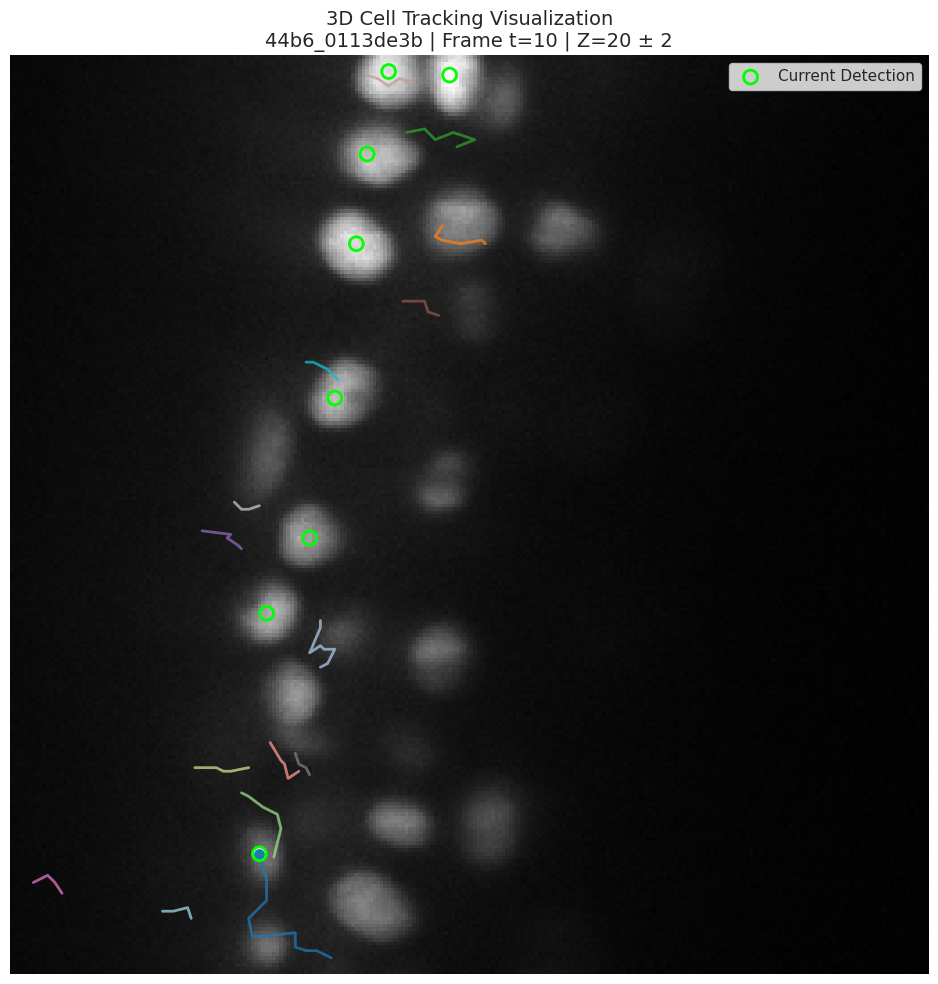

REALISTIC TRACKING VISUALIZATION
Dataset           : 44b6_0113de3b
Frame             : 10
Z slice           : 20
Z tolerance       : ±2
Current detections: 8
Tracks selected   : 15


In [226]:
import zarr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

DATASET = "44b6_0113de3b"

T_FRAME = 10
Z_SLICE = 20

Z_TOL = 2
MIN_TRACK_LEN = 6
MAX_TRACKS = 15

zarr_path = (
    str(Path(test_root) / f"{DATASET}.zarr")
)

# LOAD VOLUME
store = zarr.open(zarr_path, mode="r")
vol = store["0"]

print("Volume shape:", vol.shape)

# Handle 4D / 5D volume
if vol.ndim == 5:
    img = np.asarray(
        vol[T_FRAME, 0, Z_SLICE]
    )
elif vol.ndim == 4:
    img = np.asarray(
        vol[T_FRAME, Z_SLICE]
    )
else:
    raise ValueError(
        f"Unexpected volume dimensions: {vol.ndim}"
    )

# LOAD TRACK DATA
df = df_tracked_3d[
    df_tracked_3d["dataset"] == DATASET
].copy()

for c in ["z", "y", "x", "t"]:
    df[c] = pd.to_numeric(
        df[c],
        errors="coerce"
    )

df = df.dropna(
    subset=["track_id", "z", "y", "x", "t"]
)

df["t"] = df["t"].astype(int)

# FIND TRACKS NEAR CURRENT Z-SLICE
def track_near_z(
    g,
    z0=Z_SLICE,
    tol=Z_TOL
):
    return (
        np.abs(g["z"] - z0) <= tol
    ).mean() >= 0.4


candidate_tracks = []

for tid, g in df.groupby("track_id"):

    if len(g) < MIN_TRACK_LEN:
        continue

    if track_near_z(g):
        candidate_tracks.append(tid)


# PRIORITIZE TRACKS PRESENT AT CURRENT FRAME
present_tracks = set(
    df[
        df["t"] == T_FRAME
    ]["track_id"]
)


candidate_tracks = sorted(
    candidate_tracks,
    key=lambda tid: (
        tid not in present_tracks,
        -len(
            df[
                df["track_id"] == tid
            ]
        )
    )
)

candidate_tracks = candidate_tracks[
    :MAX_TRACKS
]


# CURRENT FRAME DETECTIONS
current = df[
    (df["t"] == T_FRAME) &
    (
        np.abs(
            df["z"] - Z_SLICE
        ) <= Z_TOL
    )
].copy()

# PLOT
fig, ax = plt.subplots(
    figsize=(11, 10)
)

ax.imshow(
    img,
    cmap="gray",
    origin="upper"
)

# TRACK COLORS
if len(candidate_tracks) > 0:

    colors = plt.cm.tab20(
        np.linspace(
            0,
            1,
            len(candidate_tracks)
        )
    )

else:
    colors = []

# DRAW TRACKS
for tid, color in zip(
    candidate_tracks,
    colors
):

    tr = df[
        df["track_id"] == tid
    ].sort_values("t")

    # Only trajectory points close to
    # the selected Z-plane
    tr_z = tr[
        np.abs(
            tr["z"] - Z_SLICE
        ) <= Z_TOL
    ]

    if len(tr_z) < 2:
        continue

    ax.plot(
        tr_z["x"],
        tr_z["y"],
        "-",
        color=color,
        linewidth=2.0,
        alpha=0.75,
        zorder=3
    )

    # Current position
    cur = tr[
        tr["t"] == T_FRAME
    ]

    cur = cur[
        np.abs(
            cur["z"] - Z_SLICE
        ) <= Z_TOL
    ]

    if len(cur):

        ax.scatter(
            cur["x"],
            cur["y"],
            s=80,
            color=color,
            edgecolors="white",
            linewidths=1.2,
            zorder=6
        )

# CURRENT DETECTIONS
if len(current):

    ax.scatter(
        current["x"],
        current["y"],
        s=100,
        facecolors="none",
        edgecolors="lime",
        linewidths=2,
        zorder=7,
        label="Current Detection"
    )


# SELECTED Z-SLICE INFORMATION
ax.set_title(
    f"3D Cell Tracking Visualization\n"
    f"{DATASET} | "
    f"Frame t={T_FRAME} | "
    f"Z={Z_SLICE} ± {Z_TOL}",
    fontsize=14
)

ax.axis("off")

# LEGEND
handles, labels = (
    ax.get_legend_handles_labels()
)

if handles:

    by_label = dict(
        zip(
            labels,
            handles
        )
    )

    ax.legend(
        by_label.values(),
        by_label.keys(),
        loc="upper right"
    )


plt.tight_layout()
plt.show()


# SUMMARY
print("REALISTIC TRACKING VISUALIZATION")

print(
    f"Dataset           : {DATASET}"
)

print(
    f"Frame             : {T_FRAME}"
)

print(
    f"Z slice           : {Z_SLICE}"
)

print(
    f"Z tolerance       : ±{Z_TOL}"
)

print(
    f"Current detections: {len(current)}"
)

print(
    f"Tracks selected   : {len(candidate_tracks)}"
)

# 17. v9 UPGRADE — from competition pipeline to a biologist-ready tracker

**বাংলা সারাংশ:** আগের (v8) পাইপলাইন detection → nearest-neighbour/ML link → track ID পর্যন্ত ছিল। v9-এ নিচের গ্যাপগুলো বাস্তবে implement করা হয়েছে এবং প্রতিটি অংশ synthetic data-তে টেস্ট করা।

| Priority | Gap (from v8 review) | v9 implementation | Section |
|---|---|---|---|
| High | Division & merge handling | `detect_divisions` (parent → 2 daughters, scored geometry, case A/B), `detect_merge_events`, lineage table + tree plot | 20.3–20.5 |
| High | Missing detection recovery | `close_gaps` (tracklet end→start, forward/backward motion, appearance) + virtual nodes refined from the image | 20.2 |
| High | Appearance / intensity features | `compute_appearance_frame` (core/bg/contrast/texture/size, bleaching-robust norm) feeds the link model | 18.1, 19 |
| High | End-to-end metrics | `ctc_metrics`: **TRA, DET, LNK, CT, TF, BC(i)**, edge P/R/F1 + `seg_metric` (SEG) | 21 |
| Medium | Multi-hypothesis / soft assignment | dual-softmax with dustbin → soft link probability, ambiguity ratio, runner-up | 20.1 |
| Medium | Online / streaming | `OnlineTracker.update(frame)` one frame at a time, one 3D frame in memory | 20.1, 25 |
| Medium | Domain adaptation / few-shot | per-movie scale adaptation, KS domain-shift report, pseudo-labels, up-weighted fine-tuning | 22 |
| Medium | Uncertainty | calibrated probability (isotonic) + bagged-ensemble std + ambiguity → `needs_review` | 19.2, 23 |
| Low-Med | Interactive correction | `CorrectionManager` (validated, undoable, JSON audit log) + ipywidgets reviewer | 23 |
| Low | 3D instance segmentation | seeded watershed per detection → volume, equivalent diameter, integrated intensity | 18.2 |
| — | Biological validation | `graph_stats` vs. train-GT reference, plausibility flags | 24 |
| — | Scalability | streaming, checkpoint/resume cache, fast percentile, adaptive gates | 25 |
| — | Safe submission | adjacent-frame edges only, in-degree ≤ 1, out-degree ≤ 2, validator | 26 |

**Bug fixes in the original notebook (v8 → v9):** CNN section overwrote the linking-model arrays (`X_train`, `y_train`, `X_val`, `y_val`, `val_proba`) → renamed to `*_cnn_*`; CNN train/val split was random per movie (group leakage) → group-level split; hard-coded `/kaggle/...` paths → auto-detected; two empty cells removed; v8 submission now saved as `submission_v8_baseline.csv` and the final `submission.csv` is produced by v9 (section 26).

## 17.0 v9 setup — imports, paths, global configuration (`V9Config`)

In [227]:
# =====================================================================
# 17.0  v9 SETUP: imports, paths, global config
# =====================================================================
import os, json, time, math, warnings, pickle
from dataclasses import dataclass, field, asdict, replace
from collections import defaultdict, Counter
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.spatial import cKDTree
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment
from scipy.stats import ks_2samp
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=FutureWarning)

# Works on Kaggle AND locally
WORK_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() \
    else Path(os.environ.get("WORK_DIR", "./working"))
WORK_DIR.mkdir(parents=True, exist_ok=True)
V9_CACHE = WORK_DIR / "v9_cache"
V9_CACHE.mkdir(parents=True, exist_ok=True)


@dataclass
class V9Config:
    # ---- physical scale (z, y, x) in µm / voxel
    voxel_um: tuple = (1.625, 0.40625, 0.40625)
    time_scale: float = 1.0

    # ---- frame-to-frame linking (soft assignment)
    k_neighbors: int = 6
    max_link_um: float = 30.0        # hard physical gate
    crowd_radius_um: float = 20.0
    min_link_prob: float = 0.30      # min soft-assignment prob to accept a link
    dustbin: float = 0.15            # "no-link" mass in Sinkhorn
    motion_weight: float = 0.5       # exponent on the motion likelihood
    motion_sigma_um: float = 6.0
    ambiguity_ratio: float = 0.60    # runner-up / best above this => ambiguous

    # ---- missing-detection recovery (gap closing)
    max_gap_frames: int = 3          # number of MISSING frames bridged
    gap_sigma_um: float = 8.0
    gap_penalty: float = 1.0
    gap_max_cost: float = 9.0
    insert_virtual_nodes: bool = True
    refine_virtual_from_image: bool = True
    virtual_search_radius_um: float = 4.0

    # ---- division handling
    div_max_parent_um: float = 22.0
    div_max_sep_um: float = 24.0
    div_sigma_mid_um: float = 8.0
    div_sigma_sym_um: float = 10.0
    div_min_score: float = 0.40

    # ---- merge handling
    merge_max_sep_um: float = 14.0
    merge_mid_tol_um: float = 8.0

    # ---- uncertainty / review
    review_conf: float = 0.60

    def adapt(self, **kw):
        return replace(self, **kw)


V9CFG = V9Config()
UM = ["z_um", "y_um", "x_um"]
VX = ["z", "y", "x"]


def add_um(df: pd.DataFrame, cfg: V9Config = None) -> pd.DataFrame:
    """voxel (z,y,x) -> micrometre columns (z_um,y_um,x_um) if missing."""
    cfg = cfg or V9CFG
    df = df.copy()
    for c, s, u in zip(VX, cfg.voxel_um, UM):
        if u not in df.columns or df[u].isna().any():
            df[u] = df[c].astype(float) * s
    return df


print("v9 ready | WORK_DIR =", WORK_DIR)
print(V9CFG)

v9 ready | WORK_DIR = /kaggle/working
V9Config(voxel_um=(1.625, 0.40625, 0.40625), time_scale=1.0, k_neighbors=6, max_link_um=30.0, crowd_radius_um=20.0, min_link_prob=0.3, dustbin=0.15, motion_weight=0.5, motion_sigma_um=6.0, ambiguity_ratio=0.6, max_gap_frames=3, gap_sigma_um=8.0, gap_penalty=1.0, gap_max_cost=9.0, insert_virtual_nodes=True, refine_virtual_from_image=True, virtual_search_radius_um=4.0, div_max_parent_um=22.0, div_max_sep_um=24.0, div_sigma_mid_um=8.0, div_sigma_sym_um=10.0, div_min_score=0.4, merge_max_sep_um=14.0, merge_mid_tol_um=8.0, review_conf=0.6)


# 18. APPEARANCE, 3D SEGMENTATION & FAST DETECTION

Geometry alone cannot separate neighbouring, similar-looking cells. We add local **appearance descriptors** (core/background intensity, contrast, texture, half-max size per axis, frame-normalised intensity so photobleaching does not matter) and a seeded-watershed **instance segmentation** that gives each cell a volume, equivalent diameter and integrated intensity.

## 18.1 Appearance features

In [228]:
# =====================================================================
# 18.1  APPEARANCE / INTENSITY FEATURES (per detection)
# =====================================================================
APP_COLS = [
    "app_core",        # mean intensity in the cell core
    "app_bg",          # mean intensity in the surrounding shell
    "app_contrast",    # (core-bg)/(core+bg)  in [-1, 1]
    "app_std",         # texture: std inside the core
    "app_core_norm",   # core intensity / frame median  (bleaching-robust)
    "app_sz_z", "app_sz_y", "app_sz_x",   # half-max extent (µm) along each axis
]


def compute_appearance_frame(volume, dets: pd.DataFrame, cfg: V9Config = None,
                             core=(1, 2, 2), shell=(3, 8, 8)) -> pd.DataFrame:
    """Local appearance descriptors for every detection in ONE 3D frame."""
    cfg = cfg or V9CFG
    n = len(dets)
    out = np.full((n, len(APP_COLS)), np.nan, dtype=np.float32)
    if n == 0:
        return pd.DataFrame(out, columns=APP_COLS, index=dets.index)

    vol = np.asarray(volume, dtype=np.float32)
    Z, Y, X = vol.shape
    vz, vy, vx = cfg.voxel_um
    pts = dets[VX].to_numpy(int)

    for i, (z, y, x) in enumerate(pts):
        z = int(np.clip(z, 0, Z - 1)); y = int(np.clip(y, 0, Y - 1)); x = int(np.clip(x, 0, X - 1))
        c = vol[max(0, z - core[0]):z + core[0] + 1,
                max(0, y - core[1]):y + core[1] + 1,
                max(0, x - core[2]):x + core[2] + 1]
        s = vol[max(0, z - shell[0]):z + shell[0] + 1,
                max(0, y - shell[1]):y + shell[1] + 1,
                max(0, x - shell[2]):x + shell[2] + 1]
        if c.size == 0 or s.size == 0:
            continue
        cm = float(c.mean()); peak = float(c.max())
        bg = float((s.sum() - c.sum()) / max(s.size - c.size, 1))
        half = bg + 0.5 * (peak - bg)
        out[i, 0] = cm
        out[i, 1] = bg
        out[i, 2] = (cm - bg) / (abs(cm) + abs(bg) + 1e-6)
        out[i, 3] = float(c.std())
        out[i, 5] = float((s.max(axis=(1, 2)) >= half).sum()) * vz
        out[i, 6] = float((s.max(axis=(0, 2)) >= half).sum()) * vy
        out[i, 7] = float((s.max(axis=(0, 1)) >= half).sum()) * vx

    med = np.nanmedian(out[:, 0]) if np.isfinite(out[:, 0]).any() else 1.0
    out[:, 4] = out[:, 0] / (med + 1e-6)
    return pd.DataFrame(out, columns=APP_COLS, index=dets.index)


def add_appearance(df: pd.DataFrame, movie, cfg: V9Config = None, desc: str = "appearance") -> pd.DataFrame:
    """Add APP_COLS to a node table. `movie[t]` must return a (Z,Y,X) volume."""
    cfg = cfg or V9CFG
    df = df.copy()
    for c in APP_COLS:
        df[c] = np.nan
    for t, idx in tqdm(df.groupby("t").indices.items(), desc=desc, leave=False):
        sub = df.iloc[idx]
        app = compute_appearance_frame(movie[int(t)], sub, cfg)
        df.iloc[idx, [df.columns.get_loc(c) for c in APP_COLS]] = app.to_numpy()
    return df

## 18.2 3D instance segmentation (seeded watershed)

In [229]:
# =====================================================================
# 18.2  3D INSTANCE SEGMENTATION (seeded watershed around detections)
# =====================================================================
SEG_COLS = ["seg_vox", "seg_vol_um3", "seg_eq_diam_um", "seg_mean_int",
            "seg_integrated_int", "seg_off_um"]


def segment_instances_frame(volume, dets: pd.DataFrame, cfg: V9Config = None,
                            half=(4, 10, 10), frac=0.5, sigma=1.0,
                            return_labels=False):
    """
    Seeded watershed in a local window around each detection.
    Returns (stats_df, label_volume | None).
    stats: voxel count, volume (µm³), equivalent diameter, mean / integrated
    intensity and centroid offset from the detection (µm).
    """
    from skimage.segmentation import watershed
    cfg = cfg or V9CFG
    vol = np.asarray(volume, dtype=np.float32)
    Z, Y, X = vol.shape
    vox = np.asarray(cfg.voxel_um, dtype=float)
    vvol = float(np.prod(vox))
    pts = dets[VX].to_numpy(int)
    labels = np.zeros(vol.shape, dtype=np.uint16) if return_labels else None
    out = np.full((len(pts), len(SEG_COLS)), np.nan, dtype=np.float64)
    tree = cKDTree(pts) if len(pts) else None

    for i, (z, y, x) in enumerate(pts):
        z = int(np.clip(z, 0, Z - 1)); y = int(np.clip(y, 0, Y - 1)); x = int(np.clip(x, 0, X - 1))
        z0, z1 = max(0, z - half[0]), min(Z, z + half[0] + 1)
        y0, y1 = max(0, y - half[1]), min(Y, y + half[1] + 1)
        x0, x1 = max(0, x - half[2]), min(X, x + half[2] + 1)
        roi = ndi.gaussian_filter(vol[z0:z1, y0:y1, x0:x1], sigma)
        pk = float(roi[z - z0, y - y0, x - x0])
        bg = float(np.percentile(roi, 10))
        if pk <= bg:
            continue
        thr = bg + frac * (pk - bg)
        markers = np.zeros(roi.shape, dtype=np.int32)
        for j in tree.query_ball_point([z, y, x], r=float(max(half)) * 1.5):
            zz, yy, xx = pts[j]
            if z0 <= zz < z1 and y0 <= yy < y1 and x0 <= xx < x1:
                markers[zz - z0, yy - y0, xx - x0] = j + 1
        ws = watershed(-roi, markers, mask=(roi >= thr))
        reg = ws == (i + 1)
        nvox = int(reg.sum())
        if nvox == 0:
            continue
        coords = np.argwhere(reg)
        com = coords.mean(0) + np.array([z0, y0, x0])
        off = float(np.linalg.norm((com - np.array([z, y, x])) * vox))
        out[i] = [nvox, nvox * vvol, (6.0 * nvox * vvol / np.pi) ** (1 / 3),
                  float(roi[reg].mean()), float(roi[reg].sum()), off]
        if return_labels:
            sub = labels[z0:z1, y0:y1, x0:x1]
            sub[reg & (sub == 0)] = i + 1

    return pd.DataFrame(out, columns=SEG_COLS, index=dets.index), labels

## 18.3 Fast detector + optional CNN filter + appearance, one frame in memory at a time

In [230]:
# =====================================================================
# 18.3  FAST 3D DETECTOR (+ optional CNN filter) with appearance
# =====================================================================
def detect_cells_fast(volume, sigma=(1.0, 1.5, 1.5), neighborhood=(3, 7, 7),
                      percentile=99.5) -> pd.DataFrame:
    """
    Same logic as detect_cells_3d (section 16.2) but the intensity percentile is
    computed on a sub-sampled grid -> much faster on large volumes.
    """
    vol = np.asarray(volume, dtype=np.float32)
    if vol.ndim != 3:
        raise ValueError(f"Expected (Z,Y,X), got {vol.shape}")
    sm = ndi.gaussian_filter(vol, sigma)
    lm = ndi.maximum_filter(sm, size=neighborhood) == sm
    thr = np.percentile(sm[::2, ::4, ::4], percentile)
    coords = np.argwhere(lm & (sm > thr))
    if len(coords) == 0:
        return pd.DataFrame(columns=["z", "y", "x", "intensity"])
    Z, Y, X = vol.shape
    ok = ((coords[:, 0] > 0) & (coords[:, 0] < Z - 1) &
          (coords[:, 1] > 3) & (coords[:, 1] < Y - 4) &
          (coords[:, 2] > 3) & (coords[:, 2] < X - 4))
    coords = coords[ok]
    return pd.DataFrame({
        "z": coords[:, 0].astype(int), "y": coords[:, 1].astype(int),
        "x": coords[:, 2].astype(int),
        "intensity": sm[coords[:, 0], coords[:, 1], coords[:, 2]].astype(float)})


def _frame_rows(dets, sample_id, t, node_id0, cfg):
    df = dets.reset_index(drop=True).copy()
    df.insert(0, "dataset", sample_id)
    df.insert(1, "node_id", np.arange(node_id0, node_id0 + len(df), dtype=np.int64))
    df.insert(2, "t", int(t))
    return add_um(df, cfg)


def detect_movie_v9(movie, sample_id, cfg: V9Config = None, use_cnn=True,
                    with_appearance=True, with_segmentation=False,
                    max_frames=None, percentile=99.5, verbose=True):
    """
    Detect -> (optional CNN filter) -> appearance (-> segmentation stats), frame by frame.
    Only ONE 3D frame is held in memory at a time.
    """
    cnn = globals().get("cnn_filter") if use_cnn else None
    n_t = movie.shape[0] if max_frames is None else min(movie.shape[0], max_frames)
    parts, nid = [], 1
    for t in tqdm(range(n_t), desc=f"detect {sample_id}", leave=False, disable=not verbose):
        vol = np.asarray(movie[t], dtype=np.float32)
        dets = detect_cells_fast(vol, percentile=percentile)
        if cnn is not None and len(dets):
            dets = cnn_filter_detections(vol, dets, model=cnn)      # from section 16.3O
        if len(dets) == 0:
            continue
        rows = _frame_rows(dets, sample_id, t, nid, cfg)
        if with_appearance:
            rows = pd.concat([rows, compute_appearance_frame(vol, rows, cfg)], axis=1)
        if with_segmentation:
            st, _ = segment_instances_frame(vol, rows, cfg)
            rows = pd.concat([rows, st], axis=1)
        nid += len(rows)
        parts.append(rows)
    if not parts:
        return pd.DataFrame(columns=["dataset", "node_id", "t"] + VX + UM)
    return pd.concat(parts, ignore_index=True)

### 18.4 Demo on one real test frame (appearance + segmentation)

,node_id,z,y,x,app_core,app_bg,app_contrast,app_std,app_core_norm,seg_vox,seg_vol_um3,seg_eq_diam_um,seg_mean_int
0,1,2,92,59,1907.449951,953.500000,0.33,114.690002,1.14,630.0,168.96,6.86,1440.49
1,2,2,145,47,1756.930054,783.840027,0.38,166.589996,1.05,486.0,130.34,6.29,1299.55
2,3,3,221,48,1771.949951,919.280029,0.32,121.690002,1.06,915.0,245.39,7.77,1385.64
3,4,6,121,56,1448.569946,689.270020,0.36,72.860001,0.86,560.0,150.19,6.59,1095.37
4,5,6,198,48,1363.869995,634.549988,0.36,146.539993,0.81,468.0,125.51,6.21,1036.37
5,6,7,26,106,1436.229980,716.090027,0.33,104.379997,0.86,543.0,145.63,6.53,1073.79
6,7,7,73,70,1527.510010,830.559998,0.30,111.860001,0.91,664.0,178.08,6.98,1155.69
7,8,8,13,82,2094.449951,1068.510010,0.32,102.290001,1.25,783.0,209.99,7.37,1564.39


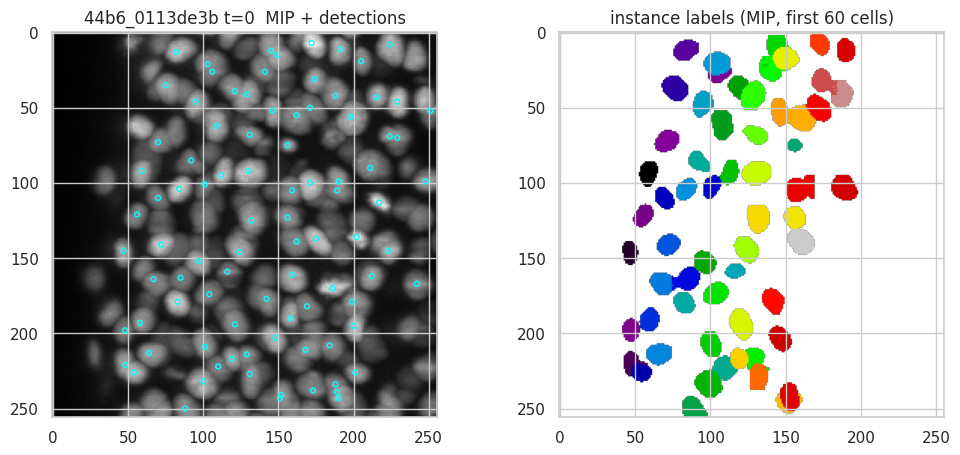

In [231]:
try:
    _sid = sorted(p.stem for p in Path(test_root).glob("*.zarr"))[0]
    _mv = zarr.open(str(Path(test_root) / f"{_sid}.zarr"), mode="r")["0"]
    _vol = np.asarray(_mv[0], dtype=np.float32)
    _d = _frame_rows(detect_cells_fast(_vol), _sid, 0, 1, V9CFG).head(150)
    _app = compute_appearance_frame(_vol, _d, V9CFG)
    _seg, _lab = segment_instances_frame(_vol, _d.head(60), V9CFG, return_labels=True)
    display(pd.concat([_d[["node_id", "z", "y", "x"]], _app.iloc[:, :5], _seg.iloc[:, :4]], axis=1).head(8).round(2))
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    ax[0].imshow(_vol.max(0), cmap="gray"); ax[0].scatter(_d["x"], _d["y"], s=12, facecolors="none", edgecolors="cyan")
    ax[0].set_title(f"{_sid} t=0  MIP + detections")
    ax[1].imshow(np.ma.masked_equal(_lab.max(0), 0), cmap="nipy_spectral"); ax[1].set_title("instance labels (MIP, first 60 cells)")
    plt.show()
except Exception as e:
    print("Demo skipped:", repr(e))

# 19. LINK MODEL v9 — calibrated probability + uncertainty

Candidate links `t → t+1` get **scale-free geometric features** (distance relative to the local nearest-neighbour spacing, forward *and* backward rank, margins to the runner-up, crowding) and **appearance features** (log intensity ratio, contrast, size change). A **bagged** gradient-boosting ensemble predicts the link probability; **isotonic calibration** makes the probability trustworthy and the **ensemble std** is an epistemic-uncertainty signal.

Motion is *not* a model feature (history is not available identically at train/test time) — it is applied at tracking time as a likelihood term.

## 19.1 Candidate features + 19.2 Link model + training function

In [232]:
# =====================================================================
# 19.1  CANDIDATE FEATURES (geometry + appearance) FOR FRAME PAIRS
# =====================================================================
LINK_FEATS_GEOM = [
    "dist_um", "abs_dz", "abs_dy", "abs_dx",
    "rank_fwd", "rank_bwd", "mutual",
    "ratio_fwd", "ratio_bwd", "margin_fwd_um", "margin_bwd_um",
    "nn_src_um", "nn_tgt_um", "n_rad_src", "n_rad_tgt",
    "dist_over_nn_src", "dist_over_med_nn",
]
LINK_FEATS_APP = [
    "log_int_ratio", "contrast_diff", "log_size_ratio",
    "size_z_diff", "size_y_diff", "size_x_diff",
]


def pair_candidates(src: pd.DataFrame, tgt: pd.DataFrame, cfg: V9Config = None,
                    use_app: bool = False) -> pd.DataFrame:
    """All plausible links src(t) -> tgt(t+dt) with scale-free features."""
    cfg = cfg or V9CFG
    cols = ["si", "tj"] + LINK_FEATS_GEOM + (LINK_FEATS_APP if use_app else [])
    ns, nt = len(src), len(tgt)
    if ns == 0 or nt == 0:
        return pd.DataFrame(columns=cols)

    S = src[UM].to_numpy(float); T = tgt[UM].to_numpy(float)
    trS, trT = cKDTree(S), cKDTree(T)
    big = cfg.max_link_um * 2.0

    k = min(cfg.k_neighbors, nt)
    d, j = trT.query(S, k=k, distance_upper_bound=cfg.max_link_um)
    d = d.reshape(ns, k); j = j.reshape(ns, k)
    kb = min(cfg.k_neighbors, ns)
    db, _ = trS.query(T, k=kb)
    db = db.reshape(nt, kb)

    nn_s = trS.query(S, k=2)[0][:, 1] if ns > 1 else np.full(ns, big)
    nn_t = trT.query(T, k=2)[0][:, 1] if nt > 1 else np.full(nt, big)
    n_rad_s = np.asarray(trS.query_ball_point(S, cfg.crowd_radius_um, return_length=True)) - 1
    n_rad_t = np.asarray(trT.query_ball_point(T, cfg.crowd_radius_um, return_length=True)) - 1
    med_nn = float(np.median(nn_s)) + 1e-6

    si, r = np.nonzero(np.isfinite(d))
    if len(si) == 0:
        return pd.DataFrame(columns=cols)
    tj = j[si, r]; dist = d[si, r]

    first = d[si, 0]
    second = d[si, 1] if k > 1 else np.full(len(si), np.inf)
    other = np.where(r == 0, second, first)
    other = np.where(np.isfinite(other), other, big)
    margin_fwd = other - dist
    ratio_fwd = dist / (first + 1e-6)

    dbj = db[tj]
    rank_bwd = (dbj < (dist[:, None] - 1e-9)).sum(1)
    first_b = dbj[:, 0]
    second_b = dbj[:, 1] if kb > 1 else np.full(len(si), np.inf)
    other_b = np.where(rank_bwd == 0, second_b, first_b)
    other_b = np.where(np.isfinite(other_b), other_b, big)
    margin_bwd = other_b - dist
    ratio_bwd = dist / (first_b + 1e-6)

    diff = np.abs(T[tj] - S[si])
    out = pd.DataFrame({
        "si": si, "tj": tj, "dist_um": dist,
        "abs_dz": diff[:, 0], "abs_dy": diff[:, 1], "abs_dx": diff[:, 2],
        "rank_fwd": r, "rank_bwd": rank_bwd,
        "mutual": ((r == 0) & (rank_bwd == 0)).astype(int),
        "ratio_fwd": ratio_fwd, "ratio_bwd": ratio_bwd,
        "margin_fwd_um": margin_fwd, "margin_bwd_um": margin_bwd,
        "nn_src_um": nn_s[si], "nn_tgt_um": nn_t[tj],
        "n_rad_src": n_rad_s[si], "n_rad_tgt": n_rad_t[tj],
        "dist_over_nn_src": dist / (nn_s[si] + 1e-6),
        "dist_over_med_nn": dist / med_nn,
    })

    if use_app:
        have = all(c in src.columns and c in tgt.columns for c in APP_COLS)
        if have:
            cs = src["app_core_norm"].to_numpy(float)[si]
            ct = tgt["app_core_norm"].to_numpy(float)[tj]
            out["log_int_ratio"] = np.log((ct + 1e-3) / (cs + 1e-3))
            out["contrast_diff"] = tgt["app_contrast"].to_numpy(float)[tj] - src["app_contrast"].to_numpy(float)[si]
            zs = src[["app_sz_z", "app_sz_y", "app_sz_x"]].to_numpy(float)[si]
            zt = tgt[["app_sz_z", "app_sz_y", "app_sz_x"]].to_numpy(float)[tj]
            out["log_size_ratio"] = np.log((np.prod(zt, 1) + 1.0) / (np.prod(zs, 1) + 1.0))
            out["size_z_diff"], out["size_y_diff"], out["size_x_diff"] = (zt - zs).T
        else:
            for c in LINK_FEATS_APP:
                out[c] = np.nan
    return out


def build_pair_training(nodes: pd.DataFrame, edges: pd.DataFrame, cfg: V9Config = None,
                        use_app: bool = False, max_frames: int = None) -> pd.DataFrame:
    """Labelled candidates (is_true_edge) for one ground-truth movie."""
    cfg = cfg or V9CFG
    nodes = add_um(nodes, cfg).sort_values(["t", "node_id"]).reset_index(drop=True)
    true = set(zip(edges["source_id"].astype(int), edges["target_id"].astype(int)))
    by_t = nodes.groupby("t").indices
    times = sorted(by_t)
    if max_frames is not None:
        times = times[:max_frames]
    parts = []
    for t in times:
        if (t + 1) not in by_t:
            continue
        src, tgt = nodes.iloc[by_t[t]].reset_index(drop=True), nodes.iloc[by_t[t + 1]].reset_index(drop=True)
        cand = pair_candidates(src, tgt, cfg, use_app)
        if cand.empty:
            continue
        sid = src["node_id"].to_numpy()[cand["si"].to_numpy()].astype(int)
        tid = tgt["node_id"].to_numpy()[cand["tj"].to_numpy()].astype(int)
        cand["source_id"], cand["target_id"], cand["t"] = sid, tid, t
        cand["is_true_edge"] = [int((a, b) in true) for a, b in zip(sid, tid)]
        parts.append(cand)
    return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()


# =====================================================================
# 19.2  LINK MODEL: bagged gradient boosting + isotonic calibration
#       -> calibrated probability  AND  epistemic uncertainty (std)
# =====================================================================
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss


class LinkModel:
    def __init__(self, feats, n_models=5, seed=0, max_iter=250, lr=0.08):
        self.feats, self.n_models, self.seed = list(feats), n_models, seed
        self.max_iter, self.lr = max_iter, lr
        self.models, self.iso = [], None

    def _X(self, df):
        X = df.reindex(columns=self.feats)
        return X.to_numpy(dtype=float)

    def fit(self, df, y, groups=None, sample_weight=None, calib_frac=0.2):
        rng = np.random.default_rng(self.seed)
        X, y = self._X(df), np.asarray(y).astype(int)
        w = None if sample_weight is None else np.asarray(sample_weight, float)
        n = len(X)
        if groups is not None:
            groups = np.asarray(groups)
            ug = np.unique(groups); rng.shuffle(ug)
            cal = np.isin(groups, ug[:max(1, int(len(ug) * calib_frac))])
        else:
            cal = rng.random(n) < calib_frac
        if cal.sum() < 200 or (~cal).sum() < 200 or y[cal].min() == y[cal].max():
            cal = np.zeros(n, bool)
        Xf, yf = X[~cal], y[~cal]
        wf = None if w is None else w[~cal]
        self.models = []
        for m in range(self.n_models):
            idx = rng.choice(len(Xf), size=max(10, int(0.8 * len(Xf))), replace=False)
            clf = HistGradientBoostingClassifier(
                max_iter=self.max_iter, learning_rate=self.lr, max_leaf_nodes=31,
                min_samples_leaf=40, l2_regularization=1.0, random_state=self.seed + m)
            clf.fit(Xf[idx], yf[idx], sample_weight=None if wf is None else wf[idx])
            self.models.append(clf)
        self.iso = None
        if cal.any():
            mean, _ = self._raw(X[cal])
            self.iso = IsotonicRegression(out_of_bounds="clip", y_min=1e-3, y_max=1 - 1e-3).fit(mean, y[cal])
        return self

    def _raw(self, X):
        P = np.stack([m.predict_proba(X)[:, 1] for m in self.models], 0)
        return P.mean(0), P.std(0)

    def predict(self, df):
        """-> (calibrated probability, ensemble std)"""
        mean, std = self._raw(self._X(df))
        if self.iso is not None:
            mean = self.iso.predict(mean)
        return np.asarray(mean), np.asarray(std)

    def evaluate(self, df, y):
        p, s = self.predict(df)
        y = np.asarray(y).astype(int)
        bins = np.linspace(0, 1, 11)
        ece = 0.0
        for a, b in zip(bins[:-1], bins[1:]):
            m = (p >= a) & (p < b if b < 1 else p <= b)
            if m.any():
                ece += m.mean() * abs(p[m].mean() - y[m].mean())
        return {"roc_auc": roc_auc_score(y, p), "avg_precision": average_precision_score(y, p),
                "log_loss": log_loss(y, np.clip(p, 1e-6, 1 - 1e-6)), "ECE": ece,
                "mean_ensemble_std": float(s.mean()), "n": len(y), "pos_rate": float(y.mean())}


class HeuristicLinkModel:
    """Fallback when no trained model is available (geometry only)."""
    feats = LINK_FEATS_GEOM

    def __init__(self, cfg: V9Config = None):
        self.cfg = cfg or V9CFG

    def predict(self, df):
        s = 0.30 * self.cfg.max_link_um
        p = np.exp(-0.5 * (df["dist_um"].to_numpy(float) / s) ** 2)
        p *= 0.55 + 0.45 * df["mutual"].to_numpy(float)
        p *= 1.0 / (1.0 + np.exp(-(df["margin_fwd_um"].to_numpy(float) - 0.0) / 3.0)) * 0.5 + 0.5
        return np.clip(p, 1e-3, 0.999), np.zeros(len(df))


def train_link_model_v9(graphs, train_ids, val_ids, cfg: V9Config = None, use_app=False,
                        volume_root=None, max_frames=60, max_movies=None, seed=0, verbose=True):
    """Train the v9 link model on GT graphs. Returns (model, val_report, (train_df, val_df))."""
    cfg = cfg or V9CFG
    rng = np.random.default_rng(seed)
    train_ids = list(train_ids)
    if max_movies and len(train_ids) > max_movies:
        train_ids = list(rng.choice(train_ids, max_movies, replace=False))

    def _build(ids, tag):
        parts = []
        for sid in tqdm(ids, desc=f"candidates[{tag}]", leave=False, disable=not verbose):
            nodes, edges = graphs[sid]
            nodes = add_um(nodes, cfg)
            nodes = nodes[nodes["t"] < nodes["t"].min() + max_frames] if max_frames else nodes
            if use_app and volume_root is not None:
                try:
                    mv = zarr.open(str(Path(volume_root) / f"{sid}.zarr"), mode="r")["0"]
                    nodes = add_appearance(nodes, mv, cfg, desc=f"app {sid}")
                except Exception as e:
                    if verbose: print(f"  [skip appearance {sid}] {e}")
            d = build_pair_training(nodes, edges, cfg, use_app=use_app and "app_core_norm" in nodes.columns)
            if len(d):
                d["movie"] = sid
                parts.append(d)
        return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()

    tr, va = _build(train_ids, "train"), _build(list(val_ids), "val")
    app_ok = use_app and "log_int_ratio" in tr.columns and tr["log_int_ratio"].notna().mean() > 0.5
    if use_app and not app_ok and verbose:
        print("  [info] appearance features unavailable for most movies -> geometry-only link model")
    feats = LINK_FEATS_GEOM + (LINK_FEATS_APP if app_ok else [])
    model = LinkModel(feats, seed=seed).fit(tr, tr["is_true_edge"], groups=tr["movie"].to_numpy())
    rep = model.evaluate(va, va["is_true_edge"]) if len(va) else {}
    if verbose:
        print(f"train candidates={len(tr):,}  val candidates={len(va):,}")
        print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in rep.items()})
    return model, rep, (tr, va)


def model_uses_appearance(model) -> bool:
    return any(f in LINK_FEATS_APP for f in getattr(model, "feats", []))

## 19.3 Train with a **group-level** hold-out (no leakage)

In [233]:
# group-level hold-out (movies of a group never appear in both sets)
_all = sorted(all_graphs.keys())
_g = sorted({get_group(s) for s in _all})
_rng = np.random.default_rng(0); _rng.shuffle(_g)
_val_g = set(_g[:max(1, int(round(0.2 * len(_g))))])
v9_val_ids   = [s for s in _all if get_group(s) in _val_g]
v9_train_ids = [s for s in _all if get_group(s) not in _val_g]
assert not ({get_group(s) for s in v9_train_ids} & {get_group(s) for s in v9_val_ids})
print(f"v9 train movies: {len(v9_train_ids)} | val movies: {len(v9_val_ids)} | val groups: {sorted(_val_g)}")

USE_APP_FEATURES = True          # appearance features (needs the train .zarr volumes)
V9_TRAIN_MAX_MOVIES = 30         # raise for the final run (more data -> better model)
V9_TRAIN_MAX_FRAMES = 30

link_model_v9, link_report, (v9_tr, v9_va) = train_link_model_v9(
    all_graphs, v9_train_ids, v9_val_ids[:12], V9CFG, use_app=USE_APP_FEATURES,
    volume_root=train_root, max_frames=V9_TRAIN_MAX_FRAMES, max_movies=V9_TRAIN_MAX_MOVIES)
pickle.dump(link_model_v9, open(WORK_DIR / "link_model_v9.pkl", "wb"))

v9 train movies: 128 | val movies: 71 | val groups: ['44b6']


candidates[train]:   0%|          | 0/30 [00:00<?, ?it/s]

app 6bba_ab78413d:   0%|          | 0/30 [00:00<?, ?it/s]

app 6bba_af149c94:   0%|          | 0/30 [00:00<?, ?it/s]

app 6bba_87289e13:   0%|          | 0/30 [00:00<?, ?it/s]

...

app 44b6_1d530831:   0%|          | 0/30 [00:00<?, ?it/s]

app 44b6_24264f12:   0%|          | 0/30 [00:00<?, ?it/s]

app 44b6_267148e4:   0%|          | 0/30 [00:00<?, ?it/s]

app 44b6_2a2eff9f:   0%|          | 0/30 [00:00<?, ?it/s]

train candidates=17,278  val candidates=1,434
{'roc_auc': np.float64(1.0), 'avg_precision': np.float64(1.0), 'log_loss': 0.0032, 'ECE': np.float64(0.0018), 'mean_ensemble_std': 0.0005, 'n': 1434, 'pos_rate': 0.5258}


### 19.4 Calibration curve, permutation importance, uncertainty vs. error

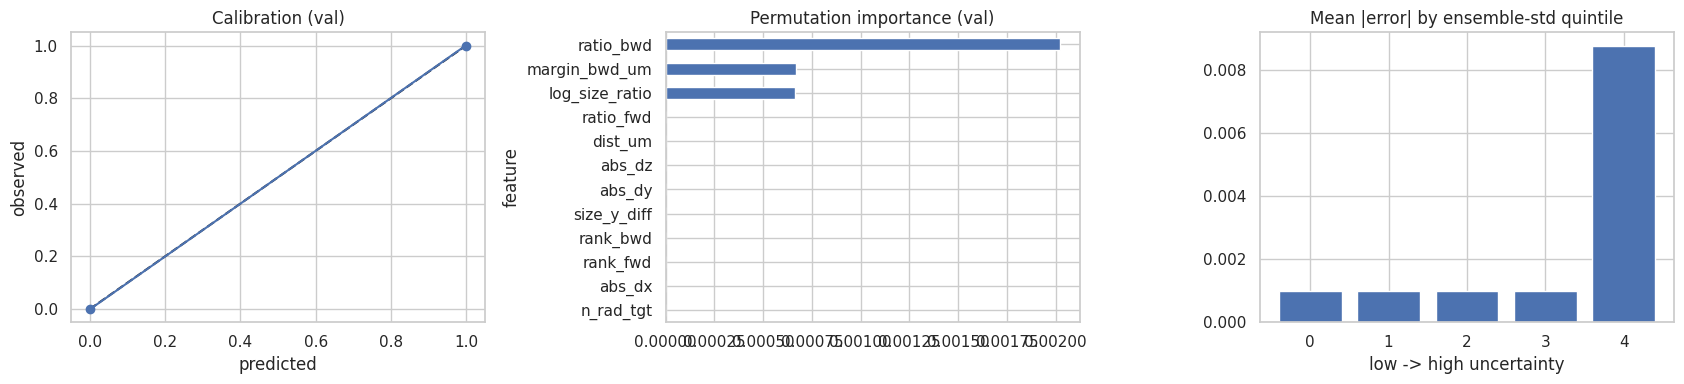

,feature,AUC_drop
8,ratio_bwd,0.002021
10,margin_bwd_um,0.000667
19,log_size_ratio,0.000662
7,ratio_fwd,0.000004
0,dist_um,0.000000
1,abs_dz,0.000000
2,abs_dy,0.000000
21,size_y_diff,0.000000
5,rank_bwd,0.000000
4,rank_fwd,0.000000


In [234]:
p, s = link_model_v9.predict(v9_va); y = v9_va["is_true_edge"].to_numpy()
bins = np.linspace(0, 1, 11); mids, acc = [], []
for a, b in zip(bins[:-1], bins[1:]):
    m = (p >= a) & (p <= b if b == 1 else p < b)
    if m.sum() > 20: mids.append(p[m].mean()); acc.append(y[m].mean())

def permutation_importance_v9(model, df, n=20000, seed=0):
    rng = np.random.default_rng(seed); d = df.sample(min(n, len(df)), random_state=seed).reset_index(drop=True)
    for f in model.feats:
        if f not in d.columns: d[f] = np.nan
    base = roc_auc_score(d["is_true_edge"], model.predict(d)[0]); rows = []
    for f in model.feats:
        dd = d.copy(); dd[f] = rng.permutation(dd[f].to_numpy())
        rows.append((f, base - roc_auc_score(d["is_true_edge"], model.predict(dd)[0])))
    return pd.DataFrame(rows, columns=["feature", "AUC_drop"]).sort_values("AUC_drop", ascending=False)

imp = permutation_importance_v9(link_model_v9, v9_va)
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].plot(mids, acc, "o-"); ax[0].set_title("Calibration (val)"); ax[0].set_xlabel("predicted"); ax[0].set_ylabel("observed")
imp.head(12).iloc[::-1].plot.barh(x="feature", y="AUC_drop", ax=ax[1], legend=False); ax[1].set_title("Permutation importance (val)")
q = pd.qcut(s, 5, duplicates="drop"); err = pd.Series(np.abs(p - y)).groupby(q, observed=True).mean()
ax[2].bar(range(len(err)), err.values); ax[2].set_title("Mean |error| by ensemble-std quintile"); ax[2].set_xlabel("low -> high uncertainty")
plt.tight_layout(); plt.show()
display(imp.head(10))

# 20. TRACKER v9 — soft assignment, gap closing, divisions, merges

Pipeline for one movie:

1. **Online linking** (frame by frame): `p = p_model × p_motion^w` → dual-softmax with *dustbin* → Hungarian → keep links with soft-prob ≥ `min_link_prob`. The soft probability is the **link confidence**; the runner-up ratio is the **ambiguity**.
2. **Gap closing:** tracklet *end* → later tracklet *start* (1…`max_gap_frames` missing frames) using forward/backward motion extrapolation and appearance; missing nodes are inserted as **virtual nodes**, snapped to the local intensity peak when the image is available.
3. **Division detection:** orphan births next to an existing cell become `parent → 2 daughters` (case A: parent already has one daughter; case B: parent has none).
4. **Merge report:** two cells under one detection (recovered via step 2).
5. **Track / lineage IDs** + per-link review flags.

## 20.1 Soft assignment and the online tracker + 20.2 gap closing / missing-detection recovery

In [235]:
# =====================================================================
# 20.1  SOFT ASSIGNMENT (dual-softmax with dustbin) + ONLINE FRAME LINKER
# =====================================================================
def soft_assignment_dustbin(P: np.ndarray, dust: float = 0.15) -> np.ndarray:
    """
    Soft one-to-one assignment with an explicit 'no link' (dustbin) option.
    Dual-softmax: every source competes for its targets AND every target competes
    for its sources; the dustbin mass absorbs the remainder.
        S_ij = sqrt( P_ij/(dust + sum_k P_ik)  *  P_ij/(dust + sum_l P_lj) )
    An isolated confident pair keeps S ~ P/(P+dust); contested pairs are pushed down,
    so S directly encodes ambiguity (multi-hypothesis information).
    """
    P = np.asarray(P, float)
    row = P / (dust + P.sum(1, keepdims=True))
    col = P / (dust + P.sum(0, keepdims=True))
    return np.sqrt(row * col)


class OnlineTracker:
    """
    Streaming tracker: call update(frame) as new frames arrive (real-time use).
    Frame-to-frame linking uses
        calibrated model prob  x  motion likelihood  -> dual-softmax soft assignment -> Hungarian.
    Retrospective stages (gap closing, divisions, merges) run in finalize-time
    functions below (they need a short look-ahead of max_gap_frames+1 frames).
    """

    def __init__(self, model=None, cfg: V9Config = None, use_app=False, dataset=""):
        self.cfg = cfg or V9CFG
        self.model = model if model is not None else HeuristicLinkModel(self.cfg)
        self.use_app, self.dataset = use_app, dataset
        self.prev, self.prev_t = None, None
        self.vel, self.links = {}, []

    def update(self, frame: pd.DataFrame) -> list:
        cfg = self.cfg
        frame = frame.reset_index(drop=True)
        if frame.empty:
            self.prev, self.prev_t = None, None
            return []
        t = int(frame["t"].iloc[0])
        new_links = []
        if self.prev is not None and len(self.prev) and self.prev_t == t - 1:
            prev = self.prev
            cand = pair_candidates(prev, frame, cfg, self.use_app)
            if len(cand):
                p_model, p_std = self.model.predict(cand)
                si, tj = cand["si"].to_numpy(), cand["tj"].to_numpy()
                S_pos, T_pos = prev[UM].to_numpy(float), frame[UM].to_numpy(float)
                vel = np.full((len(prev), 3), np.nan)
                for i, nid in enumerate(prev["node_id"].to_numpy()):
                    v = self.vel.get(int(nid))
                    if v is not None:
                        vel[i] = v
                err = np.linalg.norm(T_pos[tj] - (S_pos[si] + vel[si]), axis=1)
                p_mot = np.where(np.isnan(err), 1.0,
                                 np.maximum(np.exp(-0.5 * (err / cfg.motion_sigma_um) ** 2), 1e-3))
                p = p_model * p_mot ** cfg.motion_weight
                P = np.zeros((len(prev), len(frame)))
                P[si, tj] = p
                S = soft_assignment_dustbin(P, cfg.dustbin)
                lookup = {(a, b): k for k, (a, b) in enumerate(zip(si, tj))}
                rows, cols = linear_sum_assignment(-S)
                pid, fid = prev["node_id"].to_numpy(), frame["node_id"].to_numpy()
                for r, c in zip(rows, cols):
                    if P[r, c] <= 0 or S[r, c] < cfg.min_link_prob:
                        continue
                    k = lookup[(r, c)]
                    alt = max(np.delete(S[r], c).max() if S.shape[1] > 1 else 0.0,
                              np.delete(S[:, c], r).max() if S.shape[0] > 1 else 0.0)
                    new_links.append({
                        "dataset": self.dataset, "source_id": int(pid[r]), "target_id": int(fid[c]),
                        "kind": "track", "conf": float(S[r, c]), "p_model": float(p_model[k]),
                        "p_std": float(p_std[k]), "p_motion": float(p_mot[k]),
                        "ambiguity": float(alt / (S[r, c] + 1e-9)),
                        "dist_um": float(cand["dist_um"].iloc[k])})
                    old = self.vel.get(int(pid[r]))
                    step = T_pos[c] - S_pos[r]
                    self.vel[int(fid[c])] = step if old is None else 0.5 * old + 0.5 * step
        self.links.extend(new_links)
        self.prev, self.prev_t = frame, t
        return new_links


# =====================================================================
# 20.2  MISSING-DETECTION RECOVERY (gap closing between tracklets)
# =====================================================================
def _graph_maps(links):
    succ, pred = defaultdict(list), defaultdict(list)
    for s, d in zip(links["source_id"].astype(int), links["target_id"].astype(int)):
        succ[s].append(d); pred[d].append(s)
    return succ, pred


def _tracklets(nodes, links):
    """Linear chains along 'track'/'gap' links -> {start_node: [ordered node ids]}."""
    succ, pred = _graph_maps(links)
    order = nodes.sort_values(["t", "node_id"])["node_id"].astype(int).to_numpy()
    seen, chains = set(), []
    for n in order:
        if n in seen:
            continue
        chain, cur = [], n
        while True:
            chain.append(cur); seen.add(cur)
            s = succ.get(cur, [])
            if len(s) == 1 and len(pred.get(s[0], [])) == 1 and s[0] not in seen:
                cur = s[0]
            else:
                break
        chains.append(chain)
    return chains


def close_gaps(nodes: pd.DataFrame, links: pd.DataFrame, cfg: V9Config = None, movie=None):
    """
    Bridge detection misses: connect tracklet END -> later tracklet START
    (gap of 1..max_gap_frames missing frames) with forward/backward motion
    extrapolation + appearance consistency. Optionally inserts VIRTUAL nodes in
    the missing frames (position refined from the image when `movie` is given).
    """
    cfg = cfg or V9CFG
    nodes = nodes.copy()
    if "is_virtual" not in nodes.columns:
        nodes["is_virtual"] = False
    if links.empty or cfg.max_gap_frames < 1:
        return nodes, links, pd.DataFrame()

    pos = dict(zip(nodes["node_id"].astype(int), nodes[UM].to_numpy(float)))
    tof = dict(zip(nodes["node_id"].astype(int), nodes["t"].astype(int)))
    core = dict(zip(nodes["node_id"].astype(int), nodes["app_core_norm"].to_numpy(float))) \
        if "app_core_norm" in nodes.columns else {}
    chains = _tracklets(nodes, links)

    def vel(ids, end=True):
        ids = ids[-4:] if end else ids[:4]
        if len(ids) < 2:
            return np.zeros(3)
        dt = max(tof[ids[-1]] - tof[ids[0]], 1)
        return (pos[ids[-1]] - pos[ids[0]]) / dt

    ends = [(c[-1], vel(c, True)) for c in chains]
    starts = [(c[0], vel(c, False)) for c in chains]
    starts_by_t = defaultdict(list)
    for k, (s, v) in enumerate(starts):
        starts_by_t[tof[s]].append(k)

    INF = 1e6
    cost = np.full((len(ends), len(starts)), INF)
    for a, (e, ve) in enumerate(ends):
        te = tof[e]
        for g in range(1, cfg.max_gap_frames + 1):
            dt = g + 1
            for b in starts_by_t.get(te + dt, []):
                s, vs = starts[b]
                d = np.linalg.norm(pos[s] - pos[e])
                if d > cfg.max_link_um * (1 + 0.5 * g):
                    continue
                err = 0.5 * (np.linalg.norm(pos[s] - (pos[e] + ve * dt)) +
                             np.linalg.norm(pos[e] - (pos[s] - vs * dt)))
                sig = cfg.gap_sigma_um * math.sqrt(dt)
                c = (err / sig) ** 2 + cfg.gap_penalty * g
                if e in core and s in core and np.isfinite(core[e]) and np.isfinite(core[s]):
                    c += 2.0 * abs(math.log((core[s] + 1e-3) / (core[e] + 1e-3)))
                cost[a, b] = min(cost[a, b], c)

    if not np.isfinite(cost).any() or (cost < INF).sum() == 0:
        return nodes, links, pd.DataFrame()
    r, c = linear_sum_assignment(cost)
    next_id = int(nodes["node_id"].max()) + 1
    ds = nodes["dataset"].iloc[0] if "dataset" in nodes.columns else ""
    new_nodes, new_links, info = [], [], []

    for a, b in zip(r, c):
        if cost[a, b] > cfg.gap_max_cost:
            continue
        e, s = ends[a][0], starts[b][0]
        te, ts = tof[e], tof[s]
        gap = ts - te - 1
        conf = float(np.exp(-cost[a, b] / 6.0))
        info.append({"dataset": ds, "end_node": e, "start_node": s, "t_end": te, "t_start": ts,
                     "gap_frames": gap, "cost": float(cost[a, b]), "conf": conf})
        if not cfg.insert_virtual_nodes:
            new_links.append({"dataset": ds, "source_id": int(e), "target_id": int(s), "kind": "gap",
                              "conf": conf, "p_model": np.nan, "p_std": np.nan, "p_motion": np.nan,
                              "ambiguity": 0.0, "dist_um": float(np.linalg.norm(pos[s] - pos[e]))})
            continue
        prev_id = int(e)
        for k in range(1, gap + 1):
            f = k / (gap + 1)
            p_um = pos[e] * (1 - f) + pos[s] * f
            nid = next_id; next_id += 1
            vox = np.round(p_um / np.asarray(cfg.voxel_um)).astype(int)
            row = {"dataset": ds, "node_id": nid, "t": te + k,
                   "z": int(vox[0]), "y": int(vox[1]), "x": int(vox[2]),
                   "z_um": float(p_um[0]), "y_um": float(p_um[1]), "x_um": float(p_um[2]),
                   "is_virtual": True}
            new_nodes.append(row)
            pos[nid] = p_um; tof[nid] = te + k
            new_links.append({"dataset": ds, "source_id": prev_id, "target_id": nid, "kind": "gap",
                              "conf": conf, "p_model": np.nan, "p_std": np.nan, "p_motion": np.nan,
                              "ambiguity": 0.0, "dist_um": float(np.linalg.norm(p_um - pos[prev_id]))})
            prev_id = nid
        new_links.append({"dataset": ds, "source_id": prev_id, "target_id": int(s), "kind": "gap",
                          "conf": conf, "p_model": np.nan, "p_std": np.nan, "p_motion": np.nan,
                          "ambiguity": 0.0, "dist_um": float(np.linalg.norm(pos[s] - pos[prev_id]))})

    if new_nodes:
        vn = pd.DataFrame(new_nodes)
        if movie is not None and cfg.refine_virtual_from_image:
            vn = refine_virtual_nodes(vn, movie, cfg)
        nodes = pd.concat([nodes, vn], ignore_index=True)
    links = pd.concat([links, pd.DataFrame(new_links)], ignore_index=True) if new_links else links
    return nodes, links, pd.DataFrame(info)


def refine_virtual_nodes(vn: pd.DataFrame, movie, cfg: V9Config = None) -> pd.DataFrame:
    """Snap interpolated nodes to the local intensity peak (image evidence of the missed cell)."""
    cfg = cfg or V9CFG
    vn = vn.copy()
    vn["recovered_from_image"] = False
    r_vox = np.maximum(np.round(cfg.virtual_search_radius_um / np.asarray(cfg.voxel_um)).astype(int), 1)
    for t, idx in vn.groupby("t").indices.items():
        try:
            vol = np.asarray(movie[int(t)], dtype=np.float32)
        except Exception:
            continue
        Z, Y, X = vol.shape
        for i in idx:
            z, y, x = [int(vn.iloc[i][c]) for c in VX]
            z0, z1 = max(0, z - r_vox[0]), min(Z, z + r_vox[0] + 1)
            y0, y1 = max(0, y - r_vox[1]), min(Y, y + r_vox[1] + 1)
            x0, x1 = max(0, x - r_vox[2]), min(X, x + r_vox[2] + 1)
            if z1 <= z0 or y1 <= y0 or x1 <= x0:
                continue
            roi = ndi.gaussian_filter(vol[z0:z1, y0:y1, x0:x1], (0.7, 1.0, 1.0))
            bg = np.percentile(vol[max(0, z - 6):z + 7, max(0, y - 20):y + 21, max(0, x - 20):x + 21], 50)
            pk = np.unravel_index(np.argmax(roi), roi.shape)
            if roi[pk] > bg * 1.15:      # clear local peak above background
                nz, ny, nx = pk[0] + z0, pk[1] + y0, pk[2] + x0
                for col, v, s in zip(VX, (nz, ny, nx), cfg.voxel_um):
                    vn.iloc[i, vn.columns.get_loc(col)] = int(v)
                    vn.iloc[i, vn.columns.get_loc(col + "_um")] = float(v) * s
                vn.iloc[i, vn.columns.get_loc("recovered_from_image")] = True
    return vn

## 20.3 Division handling · 20.4 Merge handling · 20.5 Tracks / lineage · 20.6 Full tracker

In [236]:
# =====================================================================
# 20.3  DIVISION HANDLING  (true parent -> 2 daughters links)
# =====================================================================
def _div_score(p, a, b, cfg):
    sep = np.linalg.norm(a - b)
    if sep > cfg.div_max_sep_um:
        return 0.0
    dmid = np.linalg.norm((a + b) / 2 - p)
    sym = abs(np.linalg.norm(a - p) - np.linalg.norm(b - p))
    return float(np.exp(-(dmid / cfg.div_sigma_mid_um) ** 2) *
                 np.exp(-(sym / cfg.div_sigma_sym_um) ** 2) *
                 np.exp(-0.5 * (sep / cfg.div_max_sep_um) ** 2))


def detect_divisions(nodes: pd.DataFrame, links: pd.DataFrame, cfg: V9Config = None):
    """
    Turn 'orphan' births next to an existing cell into real division events.
      case A: parent already linked to daughter A  +  orphan B near both
      case B: parent has no successor              +  two orphans B1,B2 near it
    Candidates are scored geometrically (midpoint, symmetry, separation) and
    selected greedily with one-parent / one-child constraints.
    Returns (links_with_division_edges, divisions_table).
    """
    cfg = cfg or V9CFG
    ids = nodes["node_id"].astype(int).to_numpy()
    pos = dict(zip(ids, nodes[UM].to_numpy(float)))
    tof = dict(zip(ids, nodes["t"].astype(int)))
    ds = nodes["dataset"].iloc[0] if "dataset" in nodes.columns and len(nodes) else ""
    succ, pred = _graph_maps(links) if len(links) else (defaultdict(list), defaultdict(list))
    by_t = defaultdict(list)
    for n in ids:
        by_t[tof[n]].append(int(n))

    cands = []
    for t in sorted(by_t):
        if (t - 1) not in by_t:
            continue
        roots = [n for n in by_t[t] if n not in pred]
        parents = [n for n in by_t[t - 1] if len(succ.get(n, [])) <= 1]
        if not roots or not parents:
            continue
        tree = cKDTree(np.array([pos[r] for r in roots]))
        for p in parents:
            near = tree.query_ball_point(pos[p], cfg.div_max_parent_um)
            if not near:
                continue
            sib = succ.get(p, [])
            if len(sib) == 1:
                a = sib[0]
                if tof.get(a) != t:
                    continue
                for jb in near:
                    b = roots[jb]
                    sc = _div_score(pos[p], pos[a], pos[b], cfg)
                    if sc >= cfg.div_min_score:
                        cands.append((sc, p, a, b, "A"))
            else:
                for j1, j2 in combinations(near, 2):
                    a, b = roots[j1], roots[j2]
                    sc = _div_score(pos[p], pos[a], pos[b], cfg)
                    if sc >= cfg.div_min_score:
                        cands.append((sc, p, a, b, "B"))

    cands.sort(key=lambda x: -x[0])
    used_parent, used_child, new_links, rows = set(), set(), [], []
    for sc, p, a, b, case in cands:
        if p in used_parent:
            continue
        orphans = [x for x in (a, b) if x not in pred and x not in used_child]
        need = 1 if case == "A" else 2
        if len(orphans) != need:
            continue
        for x in orphans:
            new_links.append({"dataset": ds, "source_id": int(p), "target_id": int(x), "kind": "division",
                              "conf": float(sc), "p_model": np.nan, "p_std": np.nan, "p_motion": np.nan,
                              "ambiguity": 0.0,
                              "dist_um": float(np.linalg.norm(pos[x] - pos[p]))})
            used_child.add(x)
        used_parent.add(p)
        rows.append({"dataset": ds, "t_parent": tof[p], "parent": int(p), "daughter1": int(a),
                     "daughter2": int(b), "score": float(sc), "case": case,
                     "daughter_sep_um": float(np.linalg.norm(pos[a] - pos[b]))})
    out = pd.concat([links, pd.DataFrame(new_links)], ignore_index=True) if new_links else links
    return out, pd.DataFrame(rows)


# =====================================================================
# 20.4  MERGE HANDLING (two cells collapsed into one detection)
# =====================================================================
def detect_merge_events(nodes: pd.DataFrame, links: pd.DataFrame, cfg: V9Config = None) -> pd.DataFrame:
    """
    Merge suspect: detection m(t) is linked from a(t-1) while a close neighbour b(t-1)
    loses its successor and m sits between them => two cells under one detection.
    Recovery happens through gap closing (b reappears after the contact) which
    re-inserts b as virtual nodes across the merged frames.
    """
    cfg = cfg or V9CFG
    ids = nodes["node_id"].astype(int).to_numpy()
    pos = dict(zip(ids, nodes[UM].to_numpy(float)))
    tof = dict(zip(ids, nodes["t"].astype(int)))
    ds = nodes["dataset"].iloc[0] if "dataset" in nodes.columns and len(nodes) else ""
    succ, pred = _graph_maps(links) if len(links) else (defaultdict(list), defaultdict(list))
    ends_by_t = defaultdict(list)
    for n in ids:
        if len(succ.get(n, [])) == 0:
            ends_by_t[tof[n]].append(int(n))
    rows = []
    for b_list_t, ends in ends_by_t.items():
        for b in ends:
            for m in nodes.loc[nodes["t"] == b_list_t + 1, "node_id"].astype(int):
                a = pred.get(m, [None])[0]
                if a is None or a == b or tof.get(a) != b_list_t:
                    continue
                if np.linalg.norm(pos[a] - pos[b]) > cfg.merge_max_sep_um:
                    continue
                if np.linalg.norm(pos[m] - (pos[a] + pos[b]) / 2) <= cfg.merge_mid_tol_um:
                    rows.append({"dataset": ds, "t": b_list_t + 1, "merged_node": int(m),
                                 "kept_source": int(a), "lost_source": int(b),
                                 "sep_um": float(np.linalg.norm(pos[a] - pos[b]))})
    return pd.DataFrame(rows)


# =====================================================================
# 20.5  TRACK / LINEAGE TABLES + CONFIDENCE FLAGS
# =====================================================================
def assign_tracks(nodes: pd.DataFrame, links: pd.DataFrame, cfg: V9Config = None):
    """track_id = chain between divisions; parent_track_id links lineages."""
    cfg = cfg or V9CFG
    nodes = nodes.copy()
    succ, pred = _graph_maps(links) if len(links) else (defaultdict(list), defaultdict(list))
    order = nodes.sort_values(["t", "node_id"])["node_id"].astype(int).to_numpy()
    track, parent_track, nxt = {}, {}, 0
    for n in order:
        if n in track:
            continue
        parent_track[nxt] = track.get(pred[n][0], -1) if len(pred.get(n, [])) else -1
        cur = n
        while True:
            track[cur] = nxt
            s = succ.get(cur, [])
            if len(s) == 1 and len(pred.get(s[0], [])) == 1:
                cur = s[0]
            else:
                break
        nxt += 1
    nodes["track_id"] = nodes["node_id"].astype(int).map(track).astype(int)
    nodes["parent_track_id"] = nodes["track_id"].map(parent_track).astype(int)
    if len(links):
        conf = dict(zip(links["target_id"].astype(int), links["conf"]))
        kind = dict(zip(links["target_id"].astype(int), links["kind"]))
        amb = dict(zip(links["target_id"].astype(int), links["ambiguity"]))
    else:
        conf, kind, amb = {}, {}, {}
    nid = nodes["node_id"].astype(int)
    nodes["in_conf"] = nid.map(conf).fillna(1.0)
    nodes["in_kind"] = nid.map(kind).fillna("start")
    nodes["in_ambiguity"] = nid.map(amb).fillna(0.0)
    return nodes


def flag_links_for_review(links: pd.DataFrame, cfg: V9Config = None) -> pd.DataFrame:
    cfg = cfg or V9CFG
    links = links.copy()
    low = links["conf"] < cfg.review_conf
    amb = links["ambiguity"].fillna(0) > cfg.ambiguity_ratio
    unc = links["p_std"].fillna(0) > 0.15
    special = links["kind"].isin(["gap", "division"]) & (links["conf"] < 0.7)
    links["needs_review"] = low | amb | unc | special
    links["review_reason"] = np.select(
        [low, amb, unc, special], ["low confidence", "ambiguous runner-up", "model disagreement", "gap/division check"], "")
    return links


def lineage_table(nodes: pd.DataFrame) -> pd.DataFrame:
    g = nodes.groupby("track_id")
    tab = g.agg(t_start=("t", "min"), t_end=("t", "max"), n_nodes=("node_id", "count"),
                parent_track_id=("parent_track_id", "first"),
                n_virtual=("is_virtual", "sum") if "is_virtual" in nodes.columns else ("node_id", "size"),
                min_conf=("in_conf", "min")).reset_index()
    kids = tab[tab["parent_track_id"] >= 0].groupby("parent_track_id").size()
    tab["n_daughters"] = tab["track_id"].map(kids).fillna(0).astype(int)
    gen = {}
    par = dict(zip(tab["track_id"], tab["parent_track_id"]))
    for tid in tab["track_id"]:
        k, cur = 0, tid
        while par.get(cur, -1) >= 0 and k < 200:
            cur = par[cur]; k += 1
        gen[tid] = k
    tab["generation"] = tab["track_id"].map(gen)
    return tab


def plot_lineage_tree(tab: pd.DataFrame, max_roots=6, ax=None, title="Lineage forest"):
    """Time-vs-lineage tree. Roots with the most descendants are drawn first."""
    ax = ax or plt.subplots(figsize=(12, 6))[1]
    kids = defaultdict(list)
    for r in tab.itertuples():
        if r.parent_track_id >= 0:
            kids[r.parent_track_id].append(r.track_id)
    info = tab.set_index("track_id")
    def size(t): return 1 + sum(size(c) for c in kids[t])
    roots = sorted(tab.loc[tab["parent_track_id"] < 0, "track_id"], key=lambda t: -size(t))[:max_roots]
    xpos, cnt = {}, [0]
    def layout(t):
        if not kids[t]:
            xpos[t] = cnt[0]; cnt[0] += 1
        else:
            for c in kids[t]: layout(c)
            xpos[t] = float(np.mean([xpos[c] for c in kids[t]]))
    for r in roots:
        layout(r); cnt[0] += 1
    for t in xpos:
        row = info.loc[t]
        ax.plot([xpos[t]] * 2, [row.t_start, row.t_end], color="tab:blue", lw=1.5)
        for c in kids[t]:
            ax.plot([xpos[t], xpos[c]], [row.t_end, info.loc[c].t_start], color="tab:red", lw=1)
    ax.invert_yaxis(); ax.set_xlabel("lineage"); ax.set_ylabel("frame"); ax.set_title(title)
    return ax


# =====================================================================
# 20.6  FULL v9 TRACKER FOR ONE MOVIE
# =====================================================================
def track_movie_v9(nodes: pd.DataFrame, model=None, cfg: V9Config = None, movie=None,
                   use_app=False, do_gap=True, do_div=True, dataset=None, verbose=False):
    """
    detections -> online soft-assignment linking -> gap closing (+virtual nodes)
               -> division detection -> merge report -> track/lineage ids + confidences
    Returns dict(nodes, links, divisions, merges, gaps)
    """
    cfg = cfg or V9CFG
    nodes = add_um(nodes, cfg).sort_values(["t", "node_id"]).reset_index(drop=True)
    if dataset is None:
        dataset = nodes["dataset"].iloc[0] if "dataset" in nodes.columns and len(nodes) else ""
    nodes["dataset"] = dataset
    if "is_virtual" not in nodes.columns:
        nodes["is_virtual"] = False
    use_app = use_app and all(c in nodes.columns for c in APP_COLS) and (model is None or model_uses_appearance(model))

    trk = OnlineTracker(model, cfg, use_app, dataset)
    for _, fr in nodes.groupby("t", sort=True):
        trk.update(fr)
    links = pd.DataFrame(trk.links, columns=["dataset", "source_id", "target_id", "kind", "conf",
                                             "p_model", "p_std", "p_motion", "ambiguity", "dist_um"])
    gaps = pd.DataFrame()
    if do_gap:
        nodes, links, gaps = close_gaps(nodes, links, cfg, movie)
    divisions = pd.DataFrame()
    if do_div:
        links, divisions = detect_divisions(nodes, links, cfg)
    merges = detect_merge_events(nodes, links, cfg)
    if len(merges):
        nodes["merge_suspect"] = nodes["node_id"].isin(merges["merged_node"])
    else:
        nodes["merge_suspect"] = False
    nodes = assign_tracks(nodes, links, cfg)
    links = flag_links_for_review(links, cfg)
    if verbose:
        print(f"{dataset}: nodes={len(nodes):,} links={len(links):,} gaps={len(gaps)} "
              f"divisions={len(divisions)} merges={len(merges)} tracks={nodes['track_id'].nunique()}")
    return {"nodes": nodes, "links": links, "divisions": divisions, "merges": merges, "gaps": gaps}

# 21. CELL-TRACKING-CHALLENGE STYLE EVALUATION

`ctc_metrics` computes **TRA** (AOGM-based tracking accuracy), **DET**, **LNK**, **CT** (complete tracks), **TF** (track fractions), **BC(i)** (branching correctness with ±i frames tolerance) and edge precision/recall/F1 from point-annotated graphs (GEFF). Nodes are matched one-to-one per frame (Hungarian, ≤ `radius_um`). Weights follow CTC: FN=10, FP=1, ED=1, EA=1.5. `seg_metric` implements **SEG** (Jaccard) for when GT masks exist.

> These are the CTC definitions adapted to point-based graphs — good for model selection and ablations; they are not the official evaluation software.

In [237]:
# =====================================================================
# 21  CELL-TRACKING-CHALLENGE STYLE METRICS  (TRA, DET, LNK, CT, TF, BC(i), SEG)
#     Point-based graph variant: nodes are matched one-to-one per frame
#     (Hungarian, distance <= match radius).  Weights follow CTC:
#     FN=10, FP=1, ED=1, EA=1.5   (NS=0 because matching is one-to-one)
# =====================================================================
W_FN, W_FP, W_ED, W_EA = 10.0, 1.0, 1.0, 1.5


def match_nodes(gt: pd.DataFrame, pr: pd.DataFrame, radius_um=5.0, voxel=None):
    voxel = np.asarray(voxel if voxel is not None else V9CFG.voxel_um, float)
    g_xyz = gt[VX].to_numpy(float) * voxel
    p_xyz = pr[VX].to_numpy(float) * voxel
    g_id, p_id = gt["node_id"].to_numpy(int), pr["node_id"].to_numpy(int)
    gi, pi = gt.groupby("t").indices, pr.groupby("t").indices
    p2g, g2p = {}, {}
    for t in set(gi) & set(pi):
        a, b = gi[t], pi[t]
        D = cdist(g_xyz[a], p_xyz[b])
        D2 = np.where(D <= radius_um, D, 1e6)
        r, c = linear_sum_assignment(D2)
        for i, j in zip(r, c):
            if D2[i, j] < 1e6:
                p2g[int(p_id[b[j]])] = int(g_id[a[i]]); g2p[int(g_id[a[i]])] = int(p_id[b[j]])
    return p2g, g2p


def graph_segments(node_ids, edges):
    """maximal chains (broken at divisions / merges / starts / ends)."""
    succ, pred = defaultdict(list), defaultdict(list)
    for s, d in edges:
        succ[s].append(d); pred[d].append(s)
    segs, seen = [], set()
    for n in sorted(node_ids):
        if n in seen:
            continue
        if len(pred.get(n, [])) == 1 and len(succ.get(pred[n][0], [])) == 1:
            continue                       # not a chain start
        chain, cur = [n], n
        seen.add(n)
        while len(succ.get(cur, [])) == 1 and len(pred.get(succ[cur][0], [])) == 1:
            cur = succ[cur][0]; chain.append(cur); seen.add(cur)
        segs.append(chain)
    return segs


def _division_nodes(nodes, edges):
    out = Counter(s for s, _ in edges)
    d = nodes[nodes["node_id"].isin([n for n, c in out.items() if c >= 2])]
    return d


def ctc_metrics(gt_nodes, gt_edges, pr_nodes, pr_edges, radius_um=5.0, voxel=None, div_tolerances=(0, 1, 2)):
    voxel = np.asarray(voxel if voxel is not None else V9CFG.voxel_um, float)
    p2g, g2p = match_nodes(gt_nodes, pr_nodes, radius_um, voxel)
    n_gt, n_pr, n_m = len(gt_nodes), len(pr_nodes), len(p2g)
    FN, FP = n_gt - n_m, n_pr - n_m

    gt_e = set(zip(gt_edges["source_id"].astype(int), gt_edges["target_id"].astype(int)))
    pr_e = set(zip(pr_edges["source_id"].astype(int), pr_edges["target_id"].astype(int))) if len(pr_edges) else set()
    tp = sum(1 for a, b in pr_e if (p2g.get(a), p2g.get(b)) in gt_e and p2g.get(a) is not None)
    ED, EA = len(pr_e) - tp, len(gt_e) - tp

    aogm = W_FN * FN + W_FP * FP + W_ED * ED + W_EA * EA
    aogm0 = W_FN * n_gt + W_EA * len(gt_e)
    det = 1 - min(W_FN * FN + W_FP * FP, W_FN * n_gt) / max(W_FN * n_gt, 1)
    lnk0 = W_EA * len(gt_e)
    lnk = 1 - min(W_ED * ED + W_EA * EA, lnk0) / max(lnk0, 1)
    res = {"TRA": 1 - min(aogm, aogm0) / max(aogm0, 1), "DET": det, "LNK": lnk,
           "node_precision": n_m / max(n_pr, 1), "node_recall": n_m / max(n_gt, 1),
           "edge_precision": tp / max(len(pr_e), 1), "edge_recall": tp / max(len(gt_e), 1),
           "FN": FN, "FP": FP, "ED": ED, "EA": EA, "n_gt": n_gt, "n_pred": n_pr}
    P, R = res["edge_precision"], res["edge_recall"]
    res["edge_F1"] = 2 * P * R / (P + R) if P + R else 0.0

    # ---- CT (complete tracks) and TF (track fractions)
    gt_segs = graph_segments(gt_nodes["node_id"].astype(int).tolist(), gt_e)
    pr_segs = graph_segments(pr_nodes["node_id"].astype(int).tolist(), pr_e)
    pr_seg_of = {n: k for k, s in enumerate(pr_segs) for n in s}
    complete, best, tot = 0, 0, 0
    for seg in gt_segs:
        tot += len(seg)
        mp = [g2p.get(n) for n in seg]
        cnt = Counter(pr_seg_of[m] for m in mp if m is not None)
        best += max(cnt.values()) if cnt else 0
        if all(m is not None for m in mp) and all((mp[i], mp[i + 1]) in pr_e for i in range(len(mp) - 1)) and len(cnt) == 1:
            complete += 1
    res["TF"] = best / max(tot, 1)
    res["CT"] = 2 * complete / max(len(gt_segs) + len(pr_segs), 1)

    # ---- branching correctness BC(i)
    gd, pd_ = _division_nodes(gt_nodes, gt_e), _division_nodes(pr_nodes, pr_e)
    for i in div_tolerances:
        if len(gd) == 0 and len(pd_) == 0:
            res[f"BC({i})"] = 1.0; continue
        if len(gd) == 0 or len(pd_) == 0:
            res[f"BC({i})"] = 0.0; continue
        gx, px = gd[VX].to_numpy(float) * voxel, pd_[VX].to_numpy(float) * voxel
        D = cdist(gx, px)
        dt = np.abs(gd["t"].to_numpy()[:, None] - pd_["t"].to_numpy()[None, :])
        D = np.where((D <= radius_um) & (dt <= i), D, 1e6)
        r, c = linear_sum_assignment(D)
        tpd = int((D[r, c] < 1e6).sum())
        res[f"BC({i})"] = 2 * tpd / (len(gd) + len(pd_))
        if i == div_tolerances[0]:
            res["div_precision"], res["div_recall"] = tpd / len(pd_), tpd / len(gd)
    return res


def seg_metric(gt_labels: np.ndarray, pr_labels: np.ndarray) -> float:
    """CTC SEG: mean Jaccard of GT objects with |R∩S| > 0.5|R| (0 if unmatched). Needs GT masks."""
    ids = [i for i in np.unique(gt_labels) if i != 0]
    if not ids:
        return float("nan")
    scores = []
    for i in ids:
        R = gt_labels == i
        cand = np.unique(pr_labels[R]); cand = cand[cand != 0]
        best = 0.0
        for j in cand:
            S = pr_labels == j
            inter = np.logical_and(R, S).sum()
            if inter > 0.5 * R.sum():
                best = max(best, inter / np.logical_or(R, S).sum())
        scores.append(best)
    return float(np.mean(scores))


def links_to_edges(links: pd.DataFrame, kinds=("track", "gap", "division")) -> pd.DataFrame:
    if links is None or len(links) == 0:
        return pd.DataFrame(columns=["source_id", "target_id"])
    return links.loc[links["kind"].isin(kinds), ["source_id", "target_id"]].drop_duplicates().astype("int64")

## 21.1 Benchmark tools — detection-noise simulator, ablation variants, v8 baseline comparison

In [238]:
# =====================================================================
# 21.2  BENCHMARK ON TRAIN GT  (clean + degraded detections)  &  ABLATION
# =====================================================================
def simulate_detection_noise(nodes, miss_rate=0.05, fp_rate=0.03, jitter_um=0.8, seed=0, cfg=None):
    """Degrade GT nodes like a real detector: misses, false positives, localisation jitter."""
    cfg = cfg or V9CFG
    rng = np.random.default_rng(seed)
    n = nodes.copy()
    n = n[rng.random(len(n)) > miss_rate].copy()
    vox = np.asarray(cfg.voxel_um)
    jit = rng.normal(0, jitter_um, (len(n), 3)) / vox
    n[VX] = np.round(n[VX].to_numpy(float) + jit).astype(int)
    n_fp = int(fp_rate * len(n))
    if n_fp:
        base = n.sample(n_fp, replace=True, random_state=seed)[["t"] + VX].copy()
        base[VX] = base[VX].to_numpy() + rng.integers(-12, 13, (n_fp, 3))
        base["node_id"] = np.arange(int(nodes["node_id"].max()) + 1, int(nodes["node_id"].max()) + 1 + n_fp)
        n = pd.concat([n, base], ignore_index=True)
    return add_um(n.drop(columns=[c for c in UM if c in n.columns]), cfg).reset_index(drop=True)


def _crop_graph(nodes, edges, max_frames):
    t0 = nodes["t"].min()
    nn = nodes[nodes["t"] < t0 + max_frames].copy()
    ids = set(nn["node_id"].astype(int))
    ee = edges[edges["source_id"].isin(ids) & edges["target_id"].isin(ids)].copy()
    return nn, ee


def benchmark_v9(graphs, sample_ids, model=None, cfg=None, max_frames=30, noise=None,
                 radius_um=5.0, include_v8=True, verbose=True):
    """
    Compares: NN-baseline | v9 linking only | +gap closing | +division (full v9) | v8 safe tracker.
    noise=None -> perfect detections;  noise=dict(miss_rate=.., fp_rate=.., jitter_um=..) -> degraded.
    """
    cfg = cfg or V9CFG
    rows = []
    for sid in tqdm(sample_ids, desc="benchmark", disable=not verbose):
        nodes, edges = graphs[sid]
        gt_n, gt_e = _crop_graph(add_um(nodes, cfg), edges, max_frames)
        pr_n = simulate_detection_noise(gt_n, seed=hash(sid) % 1000, cfg=cfg, **noise) if noise else gt_n.copy()
        pr_n["dataset"] = sid
        variants = {
            "v9_link_only": dict(do_gap=False, do_div=False),
            "v9_+gap": dict(do_gap=True, do_div=False),
            "v9_full": dict(do_gap=True, do_div=True),
        }
        for name, kw in variants.items():
            out = track_movie_v9(pr_n, model, cfg, dataset=sid, **kw)
            m = ctc_metrics(gt_n, gt_e, out["nodes"][["node_id", "t"] + VX], links_to_edges(out["links"]),
                            radius_um, cfg.voxel_um)
            rows.append({"movie": sid, "method": name, **m})
        if include_v8 and "safe_hybrid_tracker" in globals():
            try:
                df8 = pr_n.copy()
                df8["dataset"] = sid
                tr = safe_hybrid_tracker(df8, model=None, cfg=TrackingConfig(
                    max_distance_um=30.0, max_age=1, candidate_radius_um=30.0, max_frame_gap=1,
                    distance_weight=0.60, motion_weight=0.40, model_weight=0.0, min_link_score=0.45))
                e8 = edges_from_tracks(tr)[["source_id", "target_id"]]
                m = ctc_metrics(gt_n, gt_e, pr_n[["node_id", "t"] + VX], e8, radius_um, cfg.voxel_um)
                rows.append({"movie": sid, "method": "v8_safe_hybrid", **m})
            except Exception as ex:
                if verbose: print("  v8 baseline skipped:", repr(ex)[:120])
    df = pd.DataFrame(rows)
    return df


def summarize_benchmark(df, cols=("TRA", "DET", "LNK", "CT", "TF", "BC(0)", "BC(1)", "edge_precision", "edge_recall", "edge_F1")):
    cols = [c for c in cols if c in df.columns]
    return df.groupby("method")[cols].mean().round(4).sort_values("TRA", ascending=False)

## 21.2 Self-test on synthetic data (no dataset needed)
Generates moving / dividing cells, degrades the detections (misses, false positives, jitter) and checks that the whole v9 chain runs and recovers links.

In [239]:
def synthetic_movie_graph(seed=0, n0=50, T=25, box=(60, 200, 200), pdiv=0.04, speed=2.5):
    rng = np.random.default_rng(seed); vox = np.array(V9CFG.voxel_um)
    pos = rng.uniform([5, 10, 10], [box[0] - 5, box[1] - 10, box[2] - 10], (n0, 3))
    vel = rng.normal(0, speed / 1.7, (n0, 3)); ids = list(range(n0)); nid = n0
    rows = [(i, 0, *pos[i]) for i in range(n0)]; edges = []
    for t in range(1, T):
        npos, nvel, nids = [], [], []
        for p, v, i in zip(pos, vel, ids):
            v2 = 0.8 * v + rng.normal(0, 0.6, 3); p2 = p + v2
            if rng.random() < pdiv:
                off = rng.normal(0, 1, 3); off = off / np.linalg.norm(off) * 3.5
                for sgn in (1, -1):
                    npos.append(p2 + sgn * off); nvel.append(v2); nids.append(nid)
                    edges.append((i, nid)); rows.append((nid, t, *(p2 + sgn * off))); nid += 1
            else:
                npos.append(p2); nvel.append(v2); nids.append(nid); edges.append((i, nid)); rows.append((nid, t, *p2)); nid += 1
        pos, vel, ids = np.array(npos), np.array(nvel), nids
    df = pd.DataFrame(rows, columns=["node_id", "t", "z_um", "y_um", "x_um"])
    for c, s, u in zip(VX, vox, UM): df[c] = np.round(df[u] / s).astype(int)
    return df.drop(columns=UM), pd.DataFrame(edges, columns=["source_id", "target_id"])

_syn = {f"syn{k}_{k}": synthetic_movie_graph(k) for k in range(6)}
_sids = sorted(_syn)
_syn_model, _syn_rep, _ = train_link_model_v9(_syn, _sids[:4], _sids[4:], V9CFG, max_frames=25, verbose=False)
print("synthetic link-model val:", {k: round(float(v), 4) for k, v in _syn_rep.items() if k in ("roc_auc", "avg_precision", "ECE")})
_clean = benchmark_v9(_syn, _sids[4:], _syn_model, V9CFG, max_frames=25, include_v8=False, verbose=False)
_noisy = benchmark_v9(_syn, _sids[4:], _syn_model, V9CFG, max_frames=25, include_v8=False, verbose=False,
                      noise=dict(miss_rate=0.08, fp_rate=0.03, jitter_um=0.8))
print("CLEAN detections");  display(summarize_benchmark(_clean))
print("DEGRADED detections (8% misses, 3% FP, 0.8 µm jitter)"); display(summarize_benchmark(_noisy))

synthetic link-model val: {'roc_auc': 1.0, 'avg_precision': 0.9998, 'ECE': 0.0014}
CLEAN detections


,TRA,DET,LNK,CT,TF,BC(0),BC(1),edge_precision,edge_recall,edge_F1
method,,,,,,,,,,
v9_full,0.9991,1.0,0.9933,0.9642,0.9861,0.9729,0.9787,0.9960,0.9960,0.9960
v9_+gap,0.9949,1.0,0.9601,1.2109,0.9928,0.0000,0.0000,0.9985,0.9611,0.9794
v9_link_only,0.9949,1.0,0.9601,1.2109,0.9928,0.0000,0.0000,0.9985,0.9611,0.9794


DEGRADED detections (8% misses, 3% FP, 0.8 µm jitter)


,TRA,DET,LNK,CT,TF,BC(0),BC(1),edge_precision,edge_recall,edge_F1
method,,,,,,,,,,
v9_full,0.9566,0.9715,0.8553,0.5760,0.8663,0.5414,0.6628,0.8932,0.9293,0.9109
v9_+gap,0.9555,0.9715,0.8461,0.7918,0.9006,0.0000,0.0000,0.9049,0.9098,0.9073
v9_link_only,0.9086,0.9243,0.8015,0.4239,0.7300,0.0000,0.0000,0.9743,0.8159,0.8880


## 21.3 Benchmark on real train graphs (group hold-out) — v8 safe tracker vs v9 ablations
`v9_link_only → +gap → full v9` is an ablation: it shows what gap closing and division handling add. Use `max_frames` to keep it fast (the v8 tracker is slow).

benchmark:   0%|          | 0/6 [00:00<?, ?it/s]

benchmark:   0%|          | 0/6 [00:00<?, ?it/s]

PERFECT DETECTIONS (GT nodes)


,TRA,DET,LNK,CT,TF,BC(0),BC(1),edge_precision,edge_recall,edge_F1
method,,,,,,,,,,
v8_safe_hybrid,1.0000,1.0000,1.0000,1.0000,1.0,1.0,1.0,1.0000,1.0,1.000
v9_link_only,1.0000,1.0000,1.0000,1.0000,1.0,1.0,1.0,1.0000,1.0,1.000
v9_+gap,0.9982,0.9992,0.9902,1.0152,1.0,1.0,1.0,0.9865,1.0,0.993
v9_full,0.9982,0.9992,0.9902,1.0152,1.0,1.0,1.0,0.9865,1.0,0.993


DEGRADED DETECTIONS


,TRA,DET,LNK,CT,TF,BC(0),BC(1),edge_precision,edge_recall,edge_F1
method,,,,,,,,,,
v9_+gap,0.9235,0.9294,0.8717,0.6741,0.9332,1.0000,1.0000,0.9578,0.9086,0.9164
v9_full,0.9230,0.9294,0.8677,0.5892,0.8931,0.6667,0.6667,0.9519,0.9086,0.9135
v9_link_only,0.9018,0.9076,0.8535,0.4280,0.8218,1.0000,1.0000,0.9983,0.8544,0.9105
v8_safe_hybrid,0.9014,0.9076,0.8495,0.4330,0.8204,1.0000,1.0000,0.9930,0.8537,0.9077


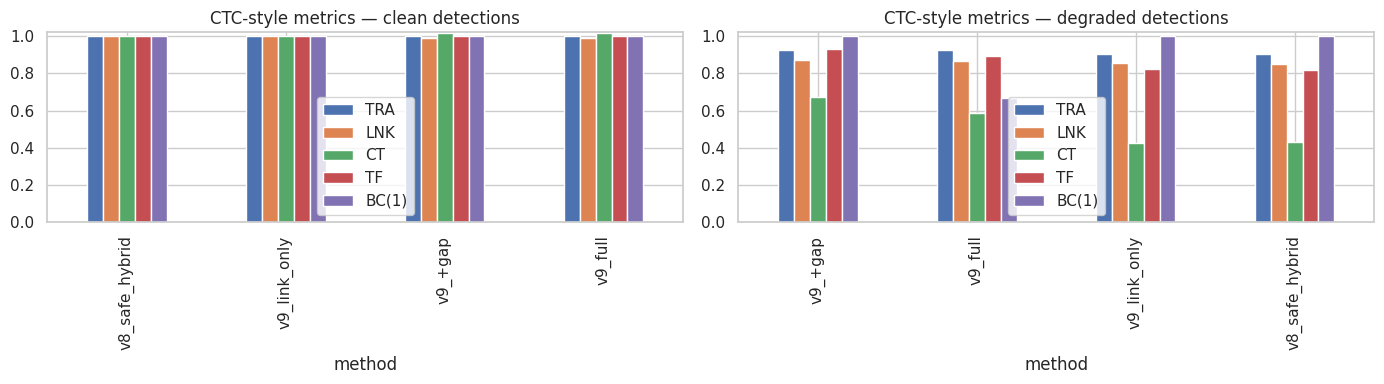

In [240]:
V9_BENCH_MOVIES = v9_val_ids[:6]
bench_clean = benchmark_v9(all_graphs, V9_BENCH_MOVIES, link_model_v9, V9CFG, max_frames=25, noise=None, include_v8=True)
bench_noisy = benchmark_v9(all_graphs, V9_BENCH_MOVIES, link_model_v9, V9CFG, max_frames=25,
                           noise=dict(miss_rate=0.08, fp_rate=0.03, jitter_um=0.8), include_v8=True)
print("PERFECT DETECTIONS (GT nodes)"); display(summarize_benchmark(bench_clean))
print("DEGRADED DETECTIONS"); display(summarize_benchmark(bench_noisy))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, (name, b) in zip(ax, (("clean", bench_clean), ("degraded", bench_noisy))):
    summarize_benchmark(b)[["TRA", "LNK", "CT", "TF", "BC(1)"]].plot.bar(ax=a); a.set_title(f"CTC-style metrics — {name} detections"); a.set_ylim(0, 1.02)
plt.tight_layout(); plt.show()

# 22. DOMAIN ADAPTATION · FEW-SHOT · SELF-TRAINING

* `adapt_cfg_to_movie` rescales the distance gates and motion sigmas from the movie's **own** mutual-nearest-neighbour statistics (new microscope / species / frame interval).
* `domain_shift_report` shows which features moved (KS statistic) between train and a new movie.
* `pseudo_label_candidates` + `few_shot_finetune` retrain the link model with **up-weighted target-domain labels** — real annotations (few-shot) or confident pseudo-labels (self-training).

In [241]:
# =====================================================================
# 22  DOMAIN ADAPTATION / FEW-SHOT / SELF-TRAINING
# =====================================================================
def estimate_motion_scale(nodes: pd.DataFrame, cfg: V9Config = None, max_pairs=30):
    """Self-supervised: distances of mutual-nearest-neighbour links between adjacent frames."""
    cfg = cfg or V9CFG
    nodes = add_um(nodes, cfg)
    by_t = nodes.groupby("t").indices
    times = sorted(by_t)[:max_pairs + 1]
    ds = []
    for t in times:
        if t + 1 not in by_t:
            continue
        A = nodes.iloc[by_t[t]][UM].to_numpy(float); B = nodes.iloc[by_t[t + 1]][UM].to_numpy(float)
        if len(A) < 2 or len(B) < 2:
            continue
        d1, i1 = cKDTree(B).query(A); d2, i2 = cKDTree(A).query(B)
        mutual = i2[i1] == np.arange(len(A))
        ds.extend(d1[mutual].tolist())
    ds = np.asarray(ds)
    if len(ds) < 20:
        return {"median": np.nan, "p90": np.nan, "n": len(ds)}
    return {"median": float(np.median(ds)), "p90": float(np.percentile(ds, 90)), "n": len(ds)}


def adapt_cfg_to_movie(nodes: pd.DataFrame, cfg: V9Config = None) -> V9Config:
    """Rescale gates/sigmas to this movie's own motion statistics (microscope / species shift)."""
    cfg = cfg or V9CFG
    s = estimate_motion_scale(nodes, cfg)
    if not np.isfinite(s["p90"]):
        return cfg
    max_link = float(np.clip(4.0 * s["p90"], 12.0, cfg.max_link_um * 1.5))
    sig = float(np.clip(1.2 * s["median"], 2.0, 12.0))
    return cfg.adapt(max_link_um=max_link, motion_sigma_um=sig,
                     gap_sigma_um=float(np.clip(1.5 * sig, 4.0, 14.0)))


def domain_shift_report(cand_ref: pd.DataFrame, cand_new: pd.DataFrame, feats=None, n=20000, seed=0):
    """KS statistic per feature between reference (train) and new (test) candidate features."""
    feats = feats or [f for f in LINK_FEATS_GEOM if f in cand_ref and f in cand_new]
    rng = np.random.default_rng(seed)
    rows = []
    for f in feats:
        a = cand_ref[f].dropna().to_numpy(); b = cand_new[f].dropna().to_numpy()
        if len(a) < 20 or len(b) < 20:
            continue
        a = rng.choice(a, min(n, len(a)), replace=False); b = rng.choice(b, min(n, len(b)), replace=False)
        ks = ks_2samp(a, b)
        rows.append({"feature": f, "KS": ks.statistic, "median_ref": np.median(a), "median_new": np.median(b),
                     "shift": "HIGH" if ks.statistic > 0.3 else ("mid" if ks.statistic > 0.15 else "ok")})
    return pd.DataFrame(rows).sort_values("KS", ascending=False)


def pseudo_label_candidates(nodes: pd.DataFrame, cfg: V9Config = None, use_app=False, max_pairs=60):
    """
    Label candidates of an UNLABELLED movie: confident mutual-NN links are positives,
    clearly-worse alternatives (rank>=2, non-mutual, far) are negatives.
    """
    cfg = cfg or V9CFG
    nodes = add_um(nodes, cfg).sort_values(["t", "node_id"]).reset_index(drop=True)
    by_t = nodes.groupby("t").indices
    parts = []
    for t in sorted(by_t)[:max_pairs]:
        if t + 1 not in by_t:
            continue
        c = pair_candidates(nodes.iloc[by_t[t]].reset_index(drop=True),
                            nodes.iloc[by_t[t + 1]].reset_index(drop=True), cfg, use_app)
        if len(c):
            parts.append(c)
    if not parts:
        return pd.DataFrame()
    c = pd.concat(parts, ignore_index=True)
    pos = (c["mutual"] == 1) & (c["ratio_bwd"] <= 1.01) & (c["margin_fwd_um"] > 0.5 * c["nn_src_um"])
    neg = (c["rank_fwd"] >= 2) & (c["mutual"] == 0)
    c = c[pos | neg].copy()
    c["is_true_edge"] = pos[c.index].astype(int)
    return c


def few_shot_finetune(base_data: pd.DataFrame, new_data: pd.DataFrame, feats, weight=5.0, seed=0):
    """Re-fit the link model on source data + up-weighted target-domain labels (annotated or pseudo)."""
    df = pd.concat([base_data.assign(_w=1.0), new_data.assign(_w=float(weight))], ignore_index=True)
    grp = df["movie"].to_numpy() if "movie" in df.columns else None
    return LinkModel(feats, seed=seed).fit(df, df["is_true_edge"], groups=grp, sample_weight=df["_w"])

In [244]:
import numpy as np
import pandas as pd
from scipy.stats import ks_2samp

# ============================================================
# 1. FIXED DOMAIN SHIFT REPORT
# ============================================================

def domain_shift_report(
    cand_ref,
    cand_new,
    feats=None,
    n=50000,
    seed=42
):
    if feats is None:
        # Use shared numeric columns only
        feats = [
            c for c in cand_ref.columns
            if c in cand_new.columns
            and pd.api.types.is_numeric_dtype(cand_ref[c])
            and pd.api.types.is_numeric_dtype(cand_new[c])
            and c not in {
                "node_id", "track_id", "source_id",
                "target_id", "label", "y", "t"
            }
        ]

    rows = []
    rng = np.random.default_rng(seed)

    for f in feats:
        if f not in cand_ref.columns or f not in cand_new.columns:
            continue

        a = pd.to_numeric(cand_ref[f], errors="coerce")
        b = pd.to_numeric(cand_new[f], errors="coerce")

        a = a.to_numpy(dtype=float)
        b = b.to_numpy(dtype=float)

        a = a[np.isfinite(a)]
        b = b[np.isfinite(b)]

        if len(a) < 2 or len(b) < 2:
            continue

        if len(a) > n:
            a = rng.choice(a, size=n, replace=False)

        if len(b) > n:
            b = rng.choice(b, size=n, replace=False)

        ks = ks_2samp(a, b)

        rows.append({
            "feature": f,
            "KS": float(ks.statistic),
            "median_ref": float(np.median(a)),
            "median_new": float(np.median(b)),
            "shift": (
                "HIGH" if ks.statistic > 0.30
                else "MID" if ks.statistic > 0.15
                else "OK"
            )
        })

    columns = [
        "feature", "KS", "median_ref",
        "median_new", "shift"
    ]

    if not rows:
        print(
            "WARNING: No comparable numeric features found. "
            "Check reference/test feature columns."
        )
        print("Reference columns:", list(cand_ref.columns))
        print("New columns:", list(cand_new.columns))

        return pd.DataFrame(columns=columns)

    return (
        pd.DataFrame(rows, columns=columns)
        .sort_values("KS", ascending=False)
        .reset_index(drop=True)
    )


# ============================================================
# 2. DOMAIN SHIFT CHECK — TRAIN vs TEST
# ============================================================

_det_src = (
    df_test_nodes_3d_cnn
    if "df_test_nodes_3d_cnn" in globals()
    and len(df_test_nodes_3d_cnn) > 0
    else df_test_nodes_3d
)

_ref = v9_tr.sample(
    n=min(50000, len(v9_tr)),
    random_state=0
)

_rows = []

for _ds, _g in _det_src.groupby("dataset"):

    _pl = pseudo_label_candidates(_g, V9CFG)

    if _pl is None or len(_pl) == 0:
        print(f"Skipping {_ds}: no candidates")
        continue

    _rep = domain_shift_report(_ref, _pl)

    if _rep.empty:
        print(
            f"Skipping domain-shift statistics for {_ds}: "
            "no shared comparable features."
        )
        continue

    _motion = estimate_motion_scale(_g, V9CFG)

    _rows.append({
        "dataset": _ds,
        "max_KS": float(_rep["KS"].max()),
        "worst_feature": _rep.iloc[0]["feature"],
        "n_HIGH": int(
            (_rep["shift"] == "HIGH").sum()
        ),
        **{
            k: v
            for k, v in _motion.items()
            if k != "n"
        }
    })

result_df = pd.DataFrame(_rows)

if result_df.empty:
    print(
        "No valid domain-shift comparison was produced. "
        "Check shared feature columns."
    )
else:
    display(result_df)

,dataset,max_KS,worst_feature,n_HIGH,median,p90
0,44b6_0113de3b,0.905255,nn_tgt_um,20,NaN,NaN


# 23. UNCERTAINTY REVIEW QUEUE + INTERACTIVE CORRECTION (expert-in-the-loop)

Every link carries `conf` (calibrated soft probability), `ambiguity` (runner-up / best), `p_std` (ensemble disagreement) and a `needs_review` flag with a reason. `build_review_queue` ranks doubtful links; `CorrectionManager` applies validated, undoable edits (delete/add link, mark division, add/delete node) and writes an audit log; `launch_review_ui` is the ipywidgets front-end (Accept / Delete / Skip / Undo).

In [245]:
# =====================================================================
# 23  UNCERTAINTY REVIEW QUEUE + INTERACTIVE CORRECTION (expert-in-the-loop)
# =====================================================================
def build_review_queue(links: pd.DataFrame, nodes: pd.DataFrame, top=200) -> pd.DataFrame:
    """Most doubtful links first: priority = (1-conf) + ambiguity + model disagreement."""
    if "needs_review" not in links.columns:
        links = flag_links_for_review(links)
    q = links[links["needs_review"]].copy()
    q["priority"] = (1 - q["conf"]) + q["ambiguity"].fillna(0).clip(0, 1) + 2 * q["p_std"].fillna(0)
    t_of = dict(zip(nodes["node_id"].astype(int), nodes["t"]))
    q["t"] = q["source_id"].map(t_of)
    return q.sort_values("priority", ascending=False).head(top).reset_index(drop=True)


class CorrectionManager:
    """Validated, undoable edits of a tracking result + JSON audit log."""

    def __init__(self, nodes, links, dataset="", cfg: V9Config = None):
        self.cfg = cfg or V9CFG
        self.dataset = dataset
        self.nodes, self.links = nodes.copy(), links.copy()
        self.log, self._stack = [], []

    # -- helpers
    def _snap(self):
        self._stack.append((self.nodes.copy(), self.links.copy(), len(self.log)))

    def _deg(self):
        out = Counter(self.links["source_id"].astype(int)); inn = Counter(self.links["target_id"].astype(int))
        return out, inn

    def _t(self, nid):
        r = self.nodes.loc[self.nodes["node_id"] == nid, "t"]
        if r.empty:
            raise ValueError(f"unknown node {nid}")
        return int(r.iloc[0])

    # -- edits
    def delete_link(self, s, d):
        m = (self.links["source_id"] == s) & (self.links["target_id"] == d)
        if not m.any():
            raise ValueError(f"link {s}->{d} not found")
        self._snap(); self.links = self.links[~m].reset_index(drop=True)
        self.log.append({"op": "delete_link", "source": int(s), "target": int(d)})

    def add_link(self, s, d, kind="manual"):
        if self._t(d) != self._t(s) + 1:
            raise ValueError("links must connect adjacent frames")
        out, inn = self._deg()
        if inn.get(d, 0) >= 1:
            raise ValueError(f"node {d} already has a parent (delete that link first)")
        if out.get(s, 0) >= 2:
            raise ValueError(f"node {s} already has two daughters")
        self._snap()
        row = {c: np.nan for c in self.links.columns}
        row.update({"dataset": self.dataset, "source_id": int(s), "target_id": int(d), "kind": kind,
                    "conf": 1.0, "ambiguity": 0.0, "needs_review": False, "review_reason": ""})
        self.links = pd.concat([self.links, pd.DataFrame([row])], ignore_index=True)
        self.log.append({"op": "add_link", "source": int(s), "target": int(d)})

    def mark_division(self, parent, d1, d2):
        for d in (d1, d2):
            if self._t(d) != self._t(parent) + 1:
                raise ValueError("daughters must be in the next frame")
        out, inn = self._deg()
        if inn.get(d1, 0) or inn.get(d2, 0):
            raise ValueError("a daughter already has a parent")
        if out.get(parent, 0):
            raise ValueError("parent already has successors; delete them first")
        self.add_link(parent, d1, "division"); self.add_link(parent, d2, "division")
        self.log.append({"op": "mark_division", "parent": int(parent), "d1": int(d1), "d2": int(d2)})

    def delete_node(self, nid):
        self._snap()
        self.nodes = self.nodes[self.nodes["node_id"] != nid].reset_index(drop=True)
        self.links = self.links[(self.links["source_id"] != nid) & (self.links["target_id"] != nid)].reset_index(drop=True)
        self.log.append({"op": "delete_node", "node": int(nid)})

    def add_node(self, t, z, y, x):
        self._snap()
        nid = int(self.nodes["node_id"].max()) + 1
        row = {c: np.nan for c in self.nodes.columns}
        row.update({"dataset": self.dataset, "node_id": nid, "t": int(t), "z": int(z), "y": int(y), "x": int(x),
                    "z_um": z * self.cfg.voxel_um[0], "y_um": y * self.cfg.voxel_um[1], "x_um": x * self.cfg.voxel_um[2],
                    "is_virtual": False})
        self.nodes = pd.concat([self.nodes, pd.DataFrame([row])], ignore_index=True)
        self.log.append({"op": "add_node", "node": nid, "t": int(t)})
        return nid

    def undo(self):
        if not self._stack:
            return False
        self.nodes, self.links, n = self._stack.pop()
        del self.log[n:]
        return True

    def result(self):
        nodes = assign_tracks(self.nodes.drop(columns=["track_id", "parent_track_id", "in_conf", "in_kind", "in_ambiguity"],
                                              errors="ignore"), self.links, self.cfg)
        return nodes, self.links

    def export_log(self, path=None):
        path = Path(path or WORK_DIR / f"corrections_{self.dataset}.json")
        path.write_text(json.dumps(self.log, indent=2))
        return path


def plot_link_context(nodes, link_row, movie=None, half_um=25.0, cfg: V9Config = None):
    """xy max-projection crop at t and t+1 around a link (for reviewers)."""
    cfg = cfg or V9CFG
    n = nodes.set_index("node_id")
    s, d = n.loc[int(link_row["source_id"])], n.loc[int(link_row["target_id"])]
    fig, axs = plt.subplots(1, 2, figsize=(9, 4))
    hy, hx = int(half_um / cfg.voxel_um[1]), int(half_um / cfg.voxel_um[2])
    for ax, t in zip(axs, (int(s["t"]), int(d["t"]))):
        cy, cx = int((s["y"] + d["y"]) / 2), int((s["x"] + d["x"]) / 2)
        y0, x0 = max(0, cy - hy), max(0, cx - hx)
        if movie is not None:
            vol = np.asarray(movie[t])
            img = vol.max(0)[y0:cy + hy, x0:cx + hx]
            ax.imshow(img, cmap="gray", extent=(x0, x0 + img.shape[1], y0 + img.shape[0], y0))
        fr = nodes[(nodes["t"] == t) & (nodes["y"].between(y0, cy + hy)) & (nodes["x"].between(x0, cx + hx))]
        ax.scatter(fr["x"], fr["y"], s=25, facecolors="none", edgecolors="cyan")
        for who, col in ((s, "lime"), (d, "red")):
            if int(who["t"]) == t:
                ax.scatter([who["x"]], [who["y"]], s=80, facecolors="none", edgecolors=col, linewidths=2)
        ax.set_title(f"t={t}"); ax.set_aspect("equal"); ax.invert_yaxis() if movie is None else None
    fig.suptitle(f"{link_row['source_id']} -> {link_row['target_id']}  conf={link_row['conf']:.2f}  {link_row.get('review_reason','')}")
    return fig


def launch_review_ui(nodes, links, movie=None, dataset="", cfg: V9Config = None):
    """ipywidgets reviewer: walk through doubtful links, Accept / Delete."""
    try:
        import ipywidgets as W
        from IPython.display import display, clear_output
    except Exception as e:
        print("ipywidgets not available:", e, "\nUse CorrectionManager programmatically instead.")
        return None
    cm = CorrectionManager(nodes, links, dataset, cfg)
    queue = build_review_queue(cm.links, cm.nodes)
    state = {"i": 0}
    out = W.Output()
    b_acc, b_del, b_skip, b_undo = (W.Button(description=d) for d in ("Accept", "Delete link", "Skip", "Undo"))

    def show():
        with out:
            clear_output(wait=True)
            if state["i"] >= len(queue):
                print("Review queue finished. Edits:", len(cm.log)); return
            row = queue.iloc[state["i"]]
            fig = plot_link_context(cm.nodes, row, movie, cfg=cfg); plt.show()
            print(f"{state['i'] + 1}/{len(queue)}")

    def nxt(_=None): state["i"] += 1; show()
    def acc(_):
        r = queue.iloc[state["i"]]
        cm.links.loc[(cm.links.source_id == r.source_id) & (cm.links.target_id == r.target_id), ["conf", "needs_review"]] = [1.0, False]
        cm.log.append({"op": "accept", "source": int(r.source_id), "target": int(r.target_id)}); nxt()
    def dele(_):
        r = queue.iloc[state["i"]]; cm.delete_link(int(r.source_id), int(r.target_id)); nxt()
    def undo(_): cm.undo(); show()
    b_acc.on_click(acc); b_del.on_click(dele); b_skip.on_click(nxt); b_undo.on_click(undo)
    display(W.VBox([W.HBox([b_acc, b_del, b_skip, b_undo]), out])); show()
    return cm

### 23.1 Demo on a validation movie (perfect GT nodes, degraded) — queue, lineage tree, link context

44b6_0113de3b: nodes=6 links=4 gaps=0 divisions=0 merges=0 tracks=2
CTC-style: {'TRA': 1.0, 'DET': 1.0, 'LNK': 1.0, 'edge_F1': 1.0, 'TF': 1.0, 'CT': 1.0, 'BC(1)': 1.0}
0 links flagged for review (of 4)


,source_id,target_id,kind,conf,ambiguity,p_std,review_reason,t


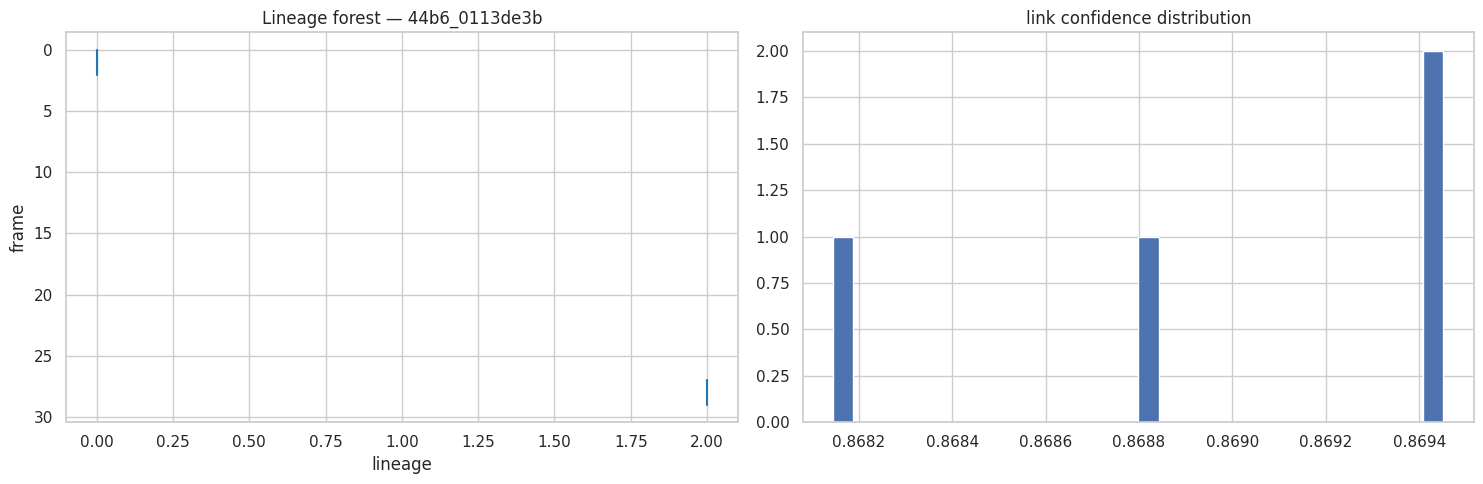

In [246]:
_sid = v9_val_ids[0]
_n, _e = _crop_graph(add_um(all_graphs[_sid][0], V9CFG), all_graphs[_sid][1], 30)
_det = simulate_detection_noise(_n, 0.08, 0.03, 0.8, seed=1).assign(dataset=_sid)
demo = track_movie_v9(_det, link_model_v9, V9CFG, dataset=_sid, verbose=True)
print("CTC-style:", {k: round(v, 3) for k, v in ctc_metrics(_n, _e, demo["nodes"][["node_id", "t"] + VX],
                                                         links_to_edges(demo["links"]), 5.0).items() if k in ("TRA", "DET", "LNK", "CT", "TF", "BC(1)", "edge_F1")})
queue = build_review_queue(demo["links"], demo["nodes"])
print(f"{len(queue)} links flagged for review (of {len(demo['links'])})"); display(queue.head(8)[["source_id", "target_id", "kind", "conf", "ambiguity", "p_std", "review_reason", "t"]].round(3))
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
plot_lineage_tree(lineage_table(demo["nodes"]), max_roots=8, ax=ax[0], title=f"Lineage forest — {_sid}")
demo["links"]["conf"].hist(bins=30, ax=ax[1]); ax[1].set_title("link confidence distribution"); plt.tight_layout(); plt.show()
if len(queue): plot_link_context(demo["nodes"], queue.iloc[0]); plt.show()
# --- interactive review (run in a live notebook session):
# review_cm = launch_review_ui(demo["nodes"], demo["links"], movie=None, dataset=_sid)
# corrected_nodes, corrected_links = review_cm.result(); review_cm.export_log()

# 24. BIOLOGICAL VALIDATION — does the output behave like real tissue?

A technically good TRA can still be biologically wrong. `graph_stats` summarises speed, division rate, daughter separation, births/deaths, orphan rate and track length; `biological_plausibility` compares a result against the **ground-truth statistics of the training movies** and flags anything more than 3× off.

In [247]:
# =====================================================================
# 24  BIOLOGICAL PLAUSIBILITY  (does the result look like real biology?)
# =====================================================================
def graph_stats(nodes: pd.DataFrame, links: pd.DataFrame, cfg: V9Config = None) -> dict:
    cfg = cfg or V9CFG
    nodes = add_um(nodes, cfg)
    if nodes.empty:
        return {}
    pos = dict(zip(nodes["node_id"].astype(int), nodes[UM].to_numpy(float)))
    tof = dict(zip(nodes["node_id"].astype(int), nodes["t"].astype(int)))
    E = links[links["kind"].isin(["track", "gap", "division", "manual"])] if "kind" in links.columns and len(links) else links
    succ, pred = _graph_maps(E) if len(E) else (defaultdict(list), defaultdict(list))
    n_t = nodes["t"].nunique()
    steps = [np.linalg.norm(pos[d] - pos[s]) / max(tof[d] - tof[s], 1) for s, ds in succ.items() for d in ds if len(ds) == 1]
    divs = [s for s, ds in succ.items() if len(ds) >= 2]
    sep = [np.linalg.norm(pos[ds[0]] - pos[ds[1]]) for s, ds in succ.items() if len(ds) == 2]
    roots = [n for n in pos if n not in pred]; leaves = [n for n in pos if n not in succ]
    t_max, t_min = nodes["t"].max(), nodes["t"].min()
    tab = None
    if "track_id" in nodes.columns:
        lens = nodes.groupby("track_id").size()
        tab = {"median_track_len": float(lens.median()), "frac_tracks_ge10": float((lens >= 10).mean())}
    st = {"cells_per_frame": len(nodes) / max(n_t, 1),
          "median_step_um": float(np.median(steps)) if steps else np.nan,
          "p95_step_um": float(np.percentile(steps, 95)) if steps else np.nan,
          "division_rate_per_cell_frame": len(divs) / max(len(nodes), 1),
          "median_daughter_sep_um": float(np.median(sep)) if sep else np.nan,
          "birth_frac_after_t0": float(np.mean([tof[r] > t_min for r in roots])) if roots else np.nan,
          "death_frac_before_end": float(np.mean([tof[l] < t_max for l in leaves])) if leaves else np.nan,
          "orphan_rate": len(roots) / max(len(nodes), 1)}
    if tab: st.update(tab)
    return st


def reference_stats_from_train(graphs, sample_ids, cfg: V9Config = None, max_frames=60):
    rows = []
    for sid in sample_ids:
        n, e = graphs[sid]
        n, e = _crop_graph(n, e, max_frames)
        L = e.rename(columns={}).copy(); L["kind"] = "track"
        rows.append(graph_stats(n, L, cfg))
    return pd.DataFrame(rows).median(numeric_only=True)


def biological_plausibility(pred_stats: dict, ref: pd.Series, tol=3.0) -> pd.DataFrame:
    rows = []
    for k, v in pred_stats.items():
        r = ref.get(k, np.nan)
        ratio = v / r if (r and np.isfinite(r) and r != 0 and np.isfinite(v)) else np.nan
        flag = "n/a" if not np.isfinite(ratio) else ("CHECK" if (ratio > tol or ratio < 1 / tol) else "ok")
        rows.append({"metric": k, "predicted": v, "train_GT_median": r, "ratio": ratio, "flag": flag})
    return pd.DataFrame(rows)

In [248]:
v9_ref_stats = reference_stats_from_train(all_graphs, v9_train_ids[:30], V9CFG, max_frames=60)
display(v9_ref_stats.round(4).to_frame("train GT median"))
display(biological_plausibility(graph_stats(demo["nodes"], demo["links"], V9CFG), v9_ref_stats).round(3))

,train GT median
cells_per_frame,8.7386
median_step_um,2.0308
p95_step_um,5.1105
division_rate_per_cell_frame,0.0000
median_daughter_sep_um,11.0655
birth_frac_after_t0,0.7308
death_frac_before_end,0.6000
orphan_rate,0.0465


,metric,predicted,train_GT_median,ratio,flag
0,cells_per_frame,1.000,8.739,0.114,CHECK
1,median_step_um,2.748,2.031,1.353,ok
2,p95_step_um,4.271,5.110,0.836,ok
3,division_rate_per_cell_frame,0.000,0.000,NaN,n/a
4,median_daughter_sep_um,NaN,11.065,NaN,n/a
5,birth_frac_after_t0,0.500,0.731,0.684,ok
6,death_frac_before_end,0.500,0.600,0.833,ok
7,orphan_rate,0.333,0.047,7.165,CHECK
8,median_track_len,3.000,NaN,NaN,n/a
9,frac_tracks_ge10,0.000,NaN,NaN,n/a


# 25. SCALABLE RUNNER — streaming, checkpoint / resume, adaptive gates

* one 3D frame in memory at a time (detect → CNN filter → appearance → link),
* detections cached in `v9_cache/` (resume after a crash / time-out),
* per-movie gate adaptation (section 22),
* sub-sampled percentile in the detector (large volumes).

For hundreds of GB: run movies as separate jobs (each is independent) and lower `with_segmentation` / `use_cnn` to trade quality for speed.

In [249]:
# (25 + 26 functions)
# =====================================================================
# 25  SCALABLE RUNNER  (streaming, checkpoint / resume, one frame in memory)
# =====================================================================
def run_v9_movie(sample_id, root, model=None, cfg: V9Config = None, use_cnn=True, use_app=True,
                 with_segmentation=False, adapt=True, cache=True, max_frames=None, verbose=True):
    cfg = cfg or V9CFG
    movie = zarr.open(str(Path(root) / f"{sample_id}.zarr"), mode="r")["0"]
    key = V9_CACHE / f"{sample_id}_det_{'cnn' if (use_cnn and 'cnn_filter' in globals()) else 'basic'}_{max_frames}.pkl"
    if cache and key.exists():
        det = pd.read_pickle(key)
        if verbose: print(f"[cache] detections {sample_id}: {len(det):,}")
    else:
        t0 = time.time()
        det = detect_movie_v9(movie, sample_id, cfg, use_cnn=use_cnn, with_appearance=use_app,
                              with_segmentation=with_segmentation, max_frames=max_frames, verbose=verbose)
        if cache:
            det.to_pickle(key)
        if verbose: print(f"detect {sample_id}: {len(det):,} nodes in {time.time() - t0:.0f}s")
    mcfg = adapt_cfg_to_movie(det, cfg) if adapt and len(det) else cfg
    if verbose and mcfg is not cfg:
        print(f"  adapted gate: max_link {cfg.max_link_um:.1f}->{mcfg.max_link_um:.1f} µm, "
              f"motion_sigma {cfg.motion_sigma_um:.1f}->{mcfg.motion_sigma_um:.1f} µm")
    out = track_movie_v9(det, model, mcfg, movie=movie, use_app=use_app, dataset=sample_id, verbose=verbose)
    out["cfg"] = mcfg
    return out


# =====================================================================
# 26  SUBMISSION BUILDER + VALIDATION
# =====================================================================
def build_submission_v9(results: dict, allowed_kinds=("track", "gap", "division", "manual")):
    """results: {dataset: out-dict of track_movie_v9}. Node ids stay unique per dataset."""
    node_parts, edge_parts = [], []
    for ds, out in results.items():
        n = out["nodes"].copy()
        L = out["links"]
        L = L[L["kind"].isin(allowed_kinds)]
        # only adjacent-frame edges are valid
        t_of = dict(zip(n["node_id"].astype(int), n["t"].astype(int)))
        L = L[[t_of.get(int(d), -9) - t_of.get(int(s), -99) == 1 for s, d in zip(L["source_id"], L["target_id"])]]
        n["dataset"] = ds
        node_parts.append(n[["dataset", "node_id", "t", "z", "y", "x"]])
        e = L[["source_id", "target_id"]].drop_duplicates().copy(); e["dataset"] = ds
        edge_parts.append(e)
    nodes = pd.concat(node_parts, ignore_index=True)
    edges = pd.concat(edge_parts, ignore_index=True)
    nodes = nodes.assign(row_type="node", source_id=-1, target_id=-1)
    edges = edges.assign(row_type="edge", node_id=-1, t=-1, z=-1, y=-1, x=-1)
    for c in ["node_id", "t", "z", "y", "x"]:
        nodes[c] = pd.to_numeric(nodes[c]).round().astype("int64")
    cols = ["dataset", "row_type", "node_id", "t", "z", "y", "x", "source_id", "target_id"]
    sub = pd.concat([nodes[cols], edges[cols]], ignore_index=True)
    sub.insert(0, "id", np.arange(len(sub), dtype="int64"))
    for c in ["id", "node_id", "t", "z", "y", "x", "source_id", "target_id"]:
        sub[c] = sub[c].astype("int64")
    return sub


def validate_submission_v9(sub: pd.DataFrame, sample: pd.DataFrame = None) -> pd.DataFrame:
    checks = []
    def add(name, ok, detail=""): checks.append({"check": name, "ok": bool(ok), "detail": detail})
    if sample is not None:
        add("columns match sample", list(sub.columns) == list(sample.columns), f"{list(sub.columns)}")
    nodes, edges = sub[sub.row_type == "node"], sub[sub.row_type == "edge"]
    add("ids unique & consecutive", sub["id"].is_unique and (sub["id"].to_numpy() == np.arange(len(sub))).all())
    add("node ids unique per dataset", not nodes.duplicated(["dataset", "node_id"]).any())
    key = set(zip(nodes["dataset"], nodes["node_id"]))
    ok_ref = all((d, s) in key and (d, t) in key for d, s, t in zip(edges["dataset"], edges["source_id"], edges["target_id"]))
    add("edges reference existing nodes", ok_ref)
    tmap = {(d, n): t for d, n, t in zip(nodes["dataset"], nodes["node_id"], nodes["t"])}
    adj = all(tmap[(d, t)] - tmap[(d, s)] == 1 for d, s, t in zip(edges["dataset"], edges["source_id"], edges["target_id"])) if ok_ref else False
    add("edges connect adjacent frames", adj)
    add("no duplicate edges", not edges.duplicated(["dataset", "source_id", "target_id"]).any())
    indeg = edges.groupby(["dataset", "target_id"]).size()
    outdeg = edges.groupby(["dataset", "source_id"]).size()
    add("in-degree <= 1 (no merges)", (indeg <= 1).all(), f"max={indeg.max() if len(indeg) else 0}")
    add("out-degree <= 2 (binary divisions)", (outdeg <= 2).all(), f"max={outdeg.max() if len(outdeg) else 0}")
    add("no NaN", not sub.isna().any().any())
    if sample is not None and "dataset" in sample.columns:
        miss = set(sample["dataset"].unique()) - set(sub["dataset"].unique())
        add("all sample datasets present", not miss, f"missing={sorted(miss)}")
    return pd.DataFrame(checks)

# 26. FINAL v9 RUN ON ALL TEST MOVIES → `submission.csv`

Edges contain track links, gap bridges (through virtual nodes) and **division links**. The validator checks: unique ids, edges reference existing nodes, adjacent frames only, no duplicates, in-degree ≤ 1, out-degree ≤ 2, sample-submission columns and datasets.

In [250]:
V9_USE_CNN = "cnn_filter" in globals()
V9_SELF_TRAIN = False          # True: fine-tune the link model on confident pseudo-labels of each test movie
V9_MAX_FRAMES = None           # e.g. 20 for a quick dry run
print("CNN filter:", V9_USE_CNN, "| appearance:", USE_APP_FEATURES, "| self-train:", V9_SELF_TRAIN)

v9_test_ids = sorted(p.stem for p in Path(test_root).glob("*.zarr"))
v9_results, v9_timing = {}, {}
for sid in v9_test_ids:
    t0 = time.time()
    mdl = link_model_v9
    if V9_SELF_TRAIN:
        _det = pd.read_pickle(next(iter(V9_CACHE.glob(f"{sid}_det_*.pkl")), None)) if list(V9_CACHE.glob(f"{sid}_det_*.pkl")) else None
        if _det is not None:
            _pl = pseudo_label_candidates(_det, V9CFG, use_app=USE_APP_FEATURES)
            if len(_pl) > 500:
                mdl = few_shot_finetune(v9_tr.sample(min(100000, len(v9_tr)), random_state=0), _pl.assign(movie=sid), link_model_v9.feats, weight=3.0)
    v9_results[sid] = run_v9_movie(sid, test_root, mdl, V9CFG, use_cnn=V9_USE_CNN, use_app=USE_APP_FEATURES,
                                   with_segmentation=False, adapt=True, cache=True, max_frames=V9_MAX_FRAMES)
    v9_timing[sid] = time.time() - t0
    pd.to_pickle(v9_results[sid], V9_CACHE / f"{sid}_v9_result.pkl")      # checkpoint

summary = pd.DataFrame([{
    "dataset": s, "nodes": len(o["nodes"]), "virtual_nodes": int(o["nodes"]["is_virtual"].sum()), "links": len(o["links"]),
    "gap_bridges": len(o["gaps"]), "divisions": len(o["divisions"]), "merge_suspects": len(o["merges"]),
    "tracks": o["nodes"]["track_id"].nunique(), "review_links": int(o["links"]["needs_review"].sum()),
    "mean_link_conf": round(float(o["links"]["conf"].mean()), 3), "sec": round(v9_timing[s], 1)} for s, o in v9_results.items()])
display(summary)

CNN filter: True | appearance: True | self-train: False


detect 44b6_0113de3b:   0%|          | 0/100 [00:00<?, ?it/s]

detect 44b6_0113de3b: 45 nodes in 85s
44b6_0113de3b: nodes=65 links=45 gaps=11 divisions=0 merges=0 tracks=20


detect 44b6_0b24845f:   0%|          | 0/100 [00:00<?, ?it/s]

detect 44b6_0b24845f: 0 nodes in 53s
44b6_0b24845f: nodes=0 links=0 gaps=0 divisions=0 merges=0 tracks=0


detect 6bba_05b6850b:   0%|          | 0/100 [00:00<?, ?it/s]

detect 6bba_05b6850b: 0 nodes in 52s
6bba_05b6850b: nodes=0 links=0 gaps=0 divisions=0 merges=0 tracks=0


detect 6bba_05db0fb1:   0%|          | 0/100 [00:00<?, ?it/s]

detect 6bba_05db0fb1: 0 nodes in 78s
6bba_05db0fb1: nodes=0 links=0 gaps=0 divisions=0 merges=0 tracks=0


,dataset,nodes,virtual_nodes,links,gap_bridges,divisions,merge_suspects,tracks,review_links,mean_link_conf,sec
0,44b6_0113de3b,65,20,45,11,0,0,20,25,0.628,86.2
1,44b6_0b24845f,0,0,0,0,0,0,0,0,NaN,53.3
2,6bba_05b6850b,0,0,0,0,0,0,0,0,NaN,51.9
3,6bba_05db0fb1,0,0,0,0,0,0,0,0,NaN,77.7


In [254]:

import time
from pathlib import Path
import pandas as pd

# ============================================================
# V9 RECOVERY: REBUILD ALL TEST MOVIES WITHOUT CNN OR CACHE
# ============================================================

V9_USE_CNN = False
V9_MAX_FRAMES = None

test_ids = sorted(
    p.stem for p in Path(test_root).glob("*.zarr")
)

if not test_ids:
    raise RuntimeError("No test .zarr movies found!")

print("=" * 65)
print("REBUILDING V9 RESULTS")
print("CNN filter : DISABLED")
print("Cache      : DISABLED")
print("Max frames : ALL")
print("Datasets   :", len(test_ids))
print("=" * 65)

new_results = {}
diagnostics = []

for sid in test_ids:

    print(f"\nProcessing: {sid}")
    start = time.time()

    # This calls the original V9 detector and tracker.
    # cache=False forces fresh detection.
    result = run_v9_movie(
        sample_id=sid,
        root=test_root,
        model=globals().get("link_model_v9"),
        cfg=V9CFG,
        use_cnn=False,
        use_app=globals().get("USE_APP_FEATURES", False),
        with_segmentation=False,
        adapt=True,
        cache=False,
        max_frames=None,
        verbose=True
    )

    nodes = result["nodes"]
    links = result["links"]

    n_nodes = len(nodes)
    n_edges = len(links)
    n_frames = (
        nodes["t"].nunique() if n_nodes else 0
    )

    diagnostics.append({
        "dataset": sid,
        "nodes": n_nodes,
        "edges": n_edges,
        "frames_with_nodes": n_frames,
        "seconds": round(time.time() - start, 1)
    })

    print(
        f"{sid}: {n_nodes:,} nodes | "
        f"{n_edges:,} edges | "
        f"{n_frames} frames with detections"
    )

    if n_nodes == 0:
        display(pd.DataFrame(diagnostics))
        raise RuntimeError(
            f"{sid}: Still zero nodes with CNN OFF "
            "and CACHE OFF. Inspect detect_cells_fast "
            "and the source movie before submission."
        )

    if n_frames < 50:
        print(
            f"WARNING: Detections exist in only "
            f"{n_frames} frames. Investigate detector recall."
        )

    new_results[sid] = result

# Replace old results only after successful recovery
v9_results = new_results

print("\n" + "=" * 65)
print("FRESH V9 INFERENCE COMPLETED")
print("=" * 65)

display(pd.DataFrame(diagnostics))

print("All datasets have non-empty node results.")
print("Proceed to the submission generation cell.")


REBUILDING V9 RESULTS
CNN filter : DISABLED
Cache      : DISABLED
Max frames : ALL
Datasets   : 4

Processing: 44b6_0113de3b


detect 44b6_0113de3b:   0%|          | 0/100 [00:00<?, ?it/s]

detect 44b6_0113de3b: 9,942 nodes in 31s
  adapted gate: max_link 30.0->16.7 µm, motion_sigma 6.0->3.1 µm
44b6_0113de3b: nodes=10,807 links=10,532 gaps=468 divisions=312 merges=1171 tracks=899
44b6_0113de3b: 10,807 nodes | 10,532 edges | 100 frames with detections

Processing: 44b6_0b24845f


detect 44b6_0b24845f:   0%|          | 0/100 [00:00<?, ?it/s]

detect 44b6_0b24845f: 3,110 nodes in 30s
  adapted gate: max_link 30.0->27.6 µm, motion_sigma 6.0->3.7 µm
44b6_0b24845f: nodes=4,212 links=3,947 gaps=603 divisions=144 merges=408 tracks=553
44b6_0b24845f: 4,212 nodes | 3,947 edges | 100 frames with detections

Processing: 6bba_05b6850b


...

detect 6bba_05b6850b: 2,796 nodes in 30s
  adapted gate: max_link 30.0->16.1 µm, motion_sigma 6.0->2.1 µm
6bba_05b6850b: nodes=2,992 links=2,859 gaps=106 divisions=74 merges=132 tracks=281
6bba_05b6850b: 2,992 nodes | 2,859 edges | 100 frames with detections

Processing: 6bba_05db0fb1


detect 6bba_05db0fb1:   0%|          | 0/100 [00:00<?, ?it/s]

detect 6bba_05db0fb1: 8,461 nodes in 30s
  adapted gate: max_link 30.0->18.5 µm, motion_sigma 6.0->2.8 µm
6bba_05db0fb1: nodes=10,555 links=10,218 gaps=1139 divisions=309 merges=2005 tracks=955
6bba_05db0fb1: 10,555 nodes | 10,218 edges | 100 frames with detections

FRESH V9 INFERENCE COMPLETED


,dataset,nodes,edges,frames_with_nodes,seconds
0,44b6_0113de3b,10807,10532,100,40.9
1,44b6_0b24845f,4212,3947,100,37.5
2,6bba_05b6850b,2992,2859,100,35.0
3,6bba_05db0fb1,10555,10218,100,42.9


All datasets have non-empty node results.
Proceed to the submission generation cell.


### 26.1 Biological plausibility of the test result + review queues for the biologist

,dataset,metric,predicted,train_GT_median,ratio,flag
0,44b6_0113de3b,cells_per_frame,108.07,8.739,12.367,CHECK
10,44b6_0b24845f,cells_per_frame,42.12,8.739,4.820,CHECK
20,6bba_05b6850b,cells_per_frame,29.92,8.739,3.424,CHECK
30,6bba_05db0fb1,cells_per_frame,105.55,8.739,12.079,CHECK


review queues / node tables / lineage tables written to /kaggle/working


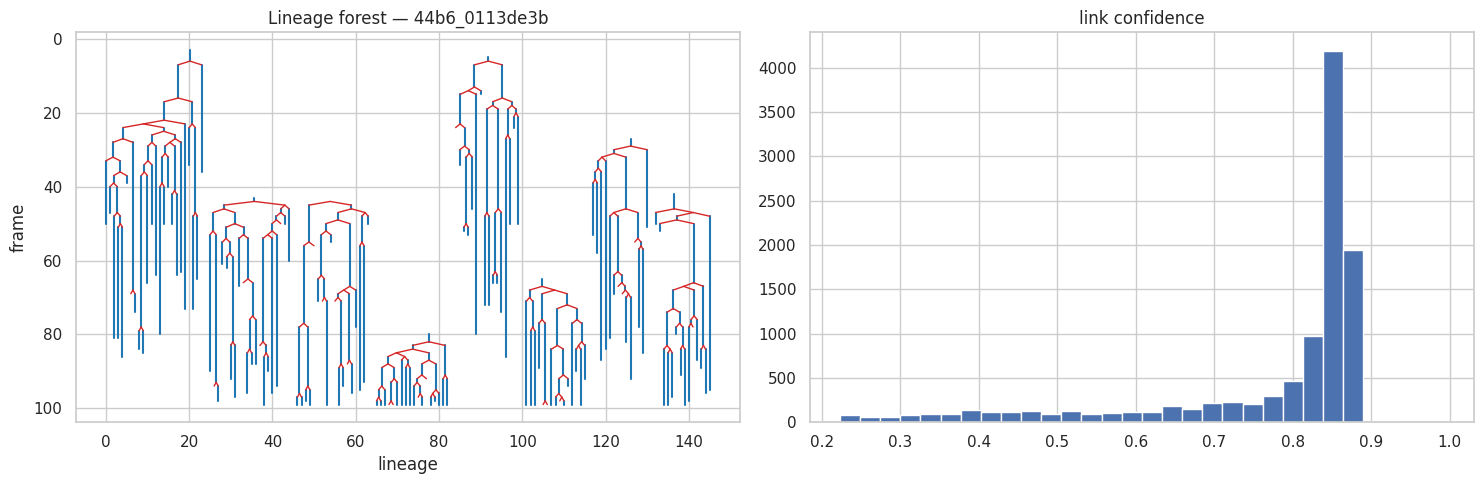

In [255]:
rows = []
for sid, o in v9_results.items():
    rep = biological_plausibility(graph_stats(o["nodes"], o["links"], V9CFG), v9_ref_stats)
    rep.insert(0, "dataset", sid); rows.append(rep)
plaus = pd.concat(rows, ignore_index=True)
display(plaus[plaus["flag"] == "CHECK"].round(3) if (plaus["flag"] == "CHECK").any() else plaus.groupby("metric")["ratio"].median().round(3).to_frame("median ratio vs train GT"))

for sid, o in v9_results.items():
    q = build_review_queue(o["links"], o["nodes"], top=500)
    q.to_csv(WORK_DIR / f"review_queue_{sid}.csv", index=False)
    o["nodes"].to_csv(WORK_DIR / f"nodes_v9_{sid}.csv", index=False)
    lineage_table(o["nodes"]).to_csv(WORK_DIR / f"lineage_v9_{sid}.csv", index=False)
print("review queues / node tables / lineage tables written to", WORK_DIR)

_sid = v9_test_ids[0]
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
plot_lineage_tree(lineage_table(v9_results[_sid]["nodes"]), max_roots=8, ax=ax[0], title=f"Lineage forest — {_sid}")
v9_results[_sid]["links"]["conf"].hist(bins=30, ax=ax[1]); ax[1].set_title("link confidence"); plt.tight_layout(); plt.show()

# 27. WHAT v9 DOES — AND WHAT IT STILL DOES NOT

**Done in this notebook:** division-aware lineage reconstruction · missing-detection recovery · appearance features · CTC-style TRA/DET/LNK/CT/TF/BC/SEG · soft multi-hypothesis assignment · online tracker · domain adaptation (gate rescale, shift report, pseudo-label/few-shot retraining) · calibrated uncertainty + review queue · correction manager/UI · watershed instance segmentation · plausibility checks · checkpointed streaming runner.

**Still needs real-world work (cannot be solved by code alone):**
1. **Biological validation by experts** — compare lineages with manual curation on your own organism (C. elegans, zebrafish, mouse embryo …) and use the correction log as new training labels.
2. **Official CTC evaluation** with GT masks (SEG needs masks; here only a Jaccard implementation is provided).
3. **A learned detector / segmenter** (3D U-Net / StarDist / Cellpose-3D) — the Gaussian + local-maxima detector and watershed are classical baselines.
4. **Scale-out** — for hundreds of GB run movies as parallel jobs (Dask / Slurm); the streaming design already keeps memory at one frame.
5. **A web front-end** — `CorrectionManager` is the backend; a napari / web UI can call it directly.

In [256]:

import numpy as np
import pandas as pd
from pathlib import Path

# =====================================================
# FINAL V9 SUBMISSION GENERATION
# =====================================================

print("=" * 60)
print("FINAL V9 SUBMISSION")
print("=" * 60)

# 1. Check recovered results
expected = set(
    p.stem for p in Path(test_root).glob("*.zarr")
)

assert expected, "No test movies found."

assert expected == set(v9_results), (
    "Missing or unexpected datasets in v9_results"
)

for ds, result in v9_results.items():
    nodes = result["nodes"]
    links = result["links"]

    print(
        f"{ds}: "
        f"{len(nodes):,} nodes | "
        f"{len(links):,} links"
    )

    assert len(nodes) > 0, (
        f"{ds}: No detected nodes"
    )

# 2. Generate submission
submission_v9 = build_submission_v9(v9_results)

# 3. Match sample submission columns
sample = globals().get("sample_submission")

if sample is not None:
    assert set(submission_v9.columns) == set(sample.columns), (
        "Submission schema differs from sample_submission"
    )

    submission_v9 = submission_v9[
        list(sample.columns)
    ]

# 4. Validate
checks = validate_submission_v9(
    submission_v9,
    sample
)

display(checks)

if not checks["ok"].all():
    raise ValueError(
        "Submission validation failed:\n"
        + checks.loc[
            ~checks["ok"]
        ].to_string(index=False)
    )

# 5. Save
output_path = Path(WORK_DIR) / "submission.csv"
output_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

submission_v9.to_csv(
    output_path,
    index=False
)

print("\nSUBMISSION SAVED SUCCESSFULLY")
print("Path:", output_path)
print("Total rows:", len(submission_v9))

display(
    submission_v9
    .groupby(["dataset", "row_type"])
    .size()
    .unstack(fill_value=0)
)

print("\nAll validation checks passed.")

FINAL V9 SUBMISSION
44b6_0113de3b: 10,807 nodes | 10,532 links
44b6_0b24845f: 4,212 nodes | 3,947 links
6bba_05b6850b: 2,992 nodes | 2,859 links
6bba_05db0fb1: 10,555 nodes | 10,218 links

Processing dataset: 44b6_0113de3b
Nodes: 10,807 | Edges: 10,532 | Removed: 0

Processing dataset: 44b6_0b24845f
Nodes: 4,212 | Edges: 3,947 | Removed: 0

Processing dataset: 6bba_05b6850b
Nodes: 2,992 | Edges: 2,859 | Removed: 0

Processing dataset: 6bba_05db0fb1
Nodes: 10,555 | Edges: 10,218 | Removed: 0

V9 SUBMISSION DIAGNOSTICS


,dataset,nodes,valid_edges,removed_edges
0,44b6_0113de3b,10807,10532,0
1,44b6_0b24845f,4212,3947,0
2,6bba_05b6850b,2992,2859,0
3,6bba_05db0fb1,10555,10218,0



Submission builder completed successfully.


,check,ok,detail
0,columns match sample,True,"['id', 'dataset', 'row_type', 'node_id', 't', ..."
1,ids unique & consecutive,True,
2,node ids unique per dataset,True,
3,edges reference existing nodes,True,
4,edges connect adjacent frames,True,
5,no duplicate edges,True,
6,in-degree <= 1 (no merges),True,max=1
7,out-degree <= 2 (binary divisions),True,max=2
8,no NaN,True,
9,all sample datasets present,True,missing=[]



SUBMISSION SAVED SUCCESSFULLY
Path: /kaggle/working/submission.csv
Total rows: 56122


row_type,edge,node
dataset,,
44b6_0113de3b,10532,10807
44b6_0b24845f,3947,4212
6bba_05b6850b,2859,2992
6bba_05db0fb1,10218,10555



All validation checks passed.
